# DIMER Notebook: Vision-Language Retrieval and Cross-Modal Reranking

**Profile:** `MULTI-CAPABILITY`  
**Mode:** `WORKSHOP`  
**Kind:** `WORKSHOP`  
**Notebook specification:** `2.5`  
**Status:** Candidate notebook carrier  
**Default tier:** `STANDARD`  
**Canonical runtime:** NVIDIA Tesla T4 or equivalent, Linux x86_64 (Google Colab, Kaggle or Linux Jupyter)

This notebook demonstrates the retrieval architecture used by practical multimodal search systems:

```text
                    ┌─ SigLIP 2 ─┐
caption/image query ├─ SigLIP v1 ├─→ vector similarity → top-K
                    └─ BLIP ITC ─┘                    │
                                                      ↓
                                              BLIP ITM reranker
                                                      │
                                                      ↓
                                                final ranking
```

## Capability A — scalable dual-encoder retrieval

Compare frozen:

- **SigLIP 2 Base P16-224**: web-pretrained (WebLI), used zero-shot, 224×224 px input;
- **SigLIP v1 Base P16-256**: web-pretrained (WebLI), used zero-shot, 256×256 px input;
- **BLIP ITC** (`blip-itm-base-coco`): fine-tuned for image–text retrieval on COCO, 384×384 px input;

on one shared real photograph-caption gallery, plus one sensitivity row: the same BLIP architecture fine-tuned on Flickr30k (`blip-itm-base-flickr`).

These are **whole-checkpoint** comparisons. Training data, retrieval fine-tuning, input resolution, text tower and model size all differ between the three retrievers, so a gap between them is not attributable to any one of those factors (section 17).

## Capability B — cross-modal reranking

Use **BLIP ITM** to rescore only the top-K candidates from each first-stage retriever.

This tests the application-level question:

> How much richer pairwise reasoning is worth paying for after a cheap vector index has already narrowed the search space?

## Capability C — BLIP retrieval adaptation (`FULL`)

Fine-tune BLIP's last two fused text blocks, its ITC projections, and ITM head on the training image-caption pairs; select by validation `rsum`; then test both the adapted coarse retriever and adapted reranker.

SigLIP adaptation is deliberately excluded because the live DIMER SigLIP adapters are class-prompt adaptation contracts, not general multi-caption retrieval adapters.

### Standalone contract

The default path:

- uses pinned upstream Hugging Face snapshots directly;
- does not clone or fetch DIMER repository source;
- does not call DIMER workers or services;
- requires no token/login;
- builds one isolated, hash-locked Python 3.12 environment with a pinned `uv` and runs every model stage there as a separate process, so nothing is installed into the notebook kernel and **Run all** needs no restart;
- runs on **Linux x86_64 only** (Google Colab, Kaggle or a Linux Jupyter server); Windows and macOS kernels are refused;
- downloads one digest-pinned VizWiz parquet shard and extracts only its first two row groups;
- implements retrieval evaluation, reranking, BLIP adaptation, artifacts, and BYOD in one carried stage file (`retrieval_workshop.py`) whose bytes the notebook verifies before use; the notebook cells show the key functions and display the stage results.

All measurements are **sample-sanity evidence on one seeded corpus split**, not a benchmark claim.

**AI Use Disclosure:** Generative AI assisted with this notebook’s code and instructional content under maintainer direction. The maintainer remains responsible for review, validation, and release decisions. AI-generated material may contain errors; validation claims are limited to documented runs and configurations. AI use does not imply independent verification, provider endorsement, or release approval.

> **⚠️ Notice.** For research, training and evaluation only. Not validated for production,
> clinical, diagnostic or safety-critical use. Running this notebook downloads third-party
> model weights and datasets under their own licenses (see the model card) and uses compute
> on your own Colab or Kaggle account. Data you bring stays in your runtime, and you are
> responsible for having the right to use it. Results here are tutorial evidence, not
> benchmarks. Everything is provided "as is", without warranty of any kind. To the maximum
> extent permitted by law, the maintainers and the DIMER platform accept no liability for
> its use.


## How to use this notebook

**Who it is for.** Learners who can run Python cells in Colab/Jupyter and are new to multimodal embeddings, retrieval, or reranking.

**Runtime.** Use the documented GPU runtime for the multi-model path, on Linux x86_64 (Google Colab, Kaggle or Linux Jupyter). The first run builds an isolated environment (several minutes); the notebook kernel itself is never modified, so no restart is needed.

**How to run it.**
1. Select the documented runtime/accelerator.
2. Choose **Run all** for the canonical path; leave the default settings unchanged on your first pass.
3. Read the explanatory markdown while the notebook runs.
4. Sections marked **Infrastructure** support reproducibility, model acquisition, or orchestration. Run those cells as written; understanding their implementation is not a learning objective.

### Task at a glance

`image/caption → dual-encoder embeddings → coarse retrieval → cross-modal reranking → ranked gallery`

### Roadmap

1. Understand the task and its input/output contract.
2. Inspect and validate the built-in data or inputs.
3. Establish the baseline/reference behavior.
4. Run the model or multi-model comparison.
5. Inspect errors, disagreements, robustness, and/or resource tradeoffs.
6. Try one controlled change and explain what changed.
7. Write an evidence-based conclusion; optionally continue with BYOD.

### What successful execution looks like

You should finish with a validated input/sample, the notebook's principal baseline/reference, model outputs and evaluation results, at least one diagnostic or qualitative comparison, and machine-readable results/provenance where supported. Exact values can vary slightly across supported runtimes; focus on the defined metrics and the observed pattern.

## 0. Learning objectives

By the end of the notebook, participants should be able to:

1. distinguish retrieval from classification and caption generation;
2. explain dual-encoder versus cross-encoder/fused retrieval;
3. build an image and text embedding index;
4. evaluate image→text and text→image Recall@K;
5. interpret median rank and `rsum`;
6. explain why gallery size changes retrieval difficulty;
7. compute a reranker candidate oracle@K;
8. use BLIP ITM to rerank top-K candidates from a cheaper retriever;
9. inspect hard negatives and model disagreements;
10. compare embedding dimensions, storage, indexing cost, search latency, and reranking cost, and say why an accuracy gap between whole checkpoints is not an effect of embedding size;
11. (`FULL` tier only) perform bounded BLIP retrieval adaptation without touching the vision encoder;
12. export/reload the embedding indexes with provenance (every tier) and, in `FULL`, a BLIP adapter.

Objectives 11 and the adapter part of 12 run only when `WORKSHOP_TIER = "FULL"`; the default `STANDARD` pass covers objectives 1–10 and the index half of 12.

## 1. Notebook controls

In [ ]:
# @title Workshop controls
WORKSHOP_TIER = "STANDARD"  # @param ["STANDARD", "FULL"]

USE_BYOD = False            # @param {type:"boolean"}
BYOD_ZIP_PATH = ""          # @param {type:"string"}

OUTPUT_DIR = "outputs"      # @param {type:"string"}

RERANK_TOP_K = 5
RECALL_KS = (1, 5, 10)
GALLERY_SIZES = (70, 128, 256, 389)

BLIP_EPOCHS = 4
BLIP_LEARNING_RATE = 2e-5
BLIP_BATCH_SIZE = 16
BLIP_TRAINABLE_TEXT_LAYERS = 2
SEED = 0
SPLIT_SEED = 42

if WORKSHOP_TIER not in {"STANDARD", "FULL"}:
    raise ValueError("WORKSHOP_TIER must be STANDARD or FULL")
if RERANK_TOP_K not in (5, 10, 20):
    raise ValueError("RERANK_TOP_K must be one of 5, 10, 20")

from pathlib import Path
OUTPUT_ROOT = Path(OUTPUT_DIR)
WORK_ROOT = Path("work")

for p in [
    OUTPUT_ROOT / "data",
    OUTPUT_ROOT / "index",
    OUTPUT_ROOT / "validation",
    OUTPUT_ROOT / "frozen",
    OUTPUT_ROOT / "test",
    OUTPUT_ROOT / "adaptation" / "blip",
    OUTPUT_ROOT / "artifacts" / "blip",
    OUTPUT_ROOT / "figures",
    OUTPUT_ROOT / "provenance",
    WORK_ROOT / "models" / "siglip2",
    WORK_ROOT / "models" / "siglip1",
    WORK_ROOT / "models" / "blip",
    WORK_ROOT / "vizwiz" / "images",
    WORK_ROOT / "byod",
]:
    p.mkdir(parents=True, exist_ok=True)

print({
    "tier": WORKSHOP_TIER,
    "rerank_top_k": RERANK_TOP_K,
    "gallery_sizes": GALLERY_SIZES,
})

{'tier': 'STANDARD', 'rerank_top_k': 5, 'gallery_sizes': (70, 128, 256, 389)}


## 2. Build one isolated, hash-locked runtime

The next two cells write the carried stage file and its dependency lock, download a pinned `uv`, build a CPython 3.12.12 virtual environment, and install only wheels whose SHA-256 hashes are in the lock (`--require-hashes --only-binary :all:`). Each later step runs as `python retrieval_workshop.py --stage <name>` with that environment's interpreter and writes JSON/CSV/PNG files that the notebook displays. Nothing is installed into this kernel, so **Run all** needs no restart. Linux x86_64 only.

> **Infrastructure.** This section supports reproducibility and execution. Run the associated setup code as written; understanding its implementation is not a learning objective for this notebook.

In [ ]:
# @title Carried stage file and hash lock (infrastructure)
# Generated by tools/build_retrieval_workshop_carrier.py; do not edit by hand.
CARRIED_FILES = {
 'retrieval_workshop.py': (
  '"""Stages of DIMER_MultiModel_Vision_Language_Retrieval_Workshop.ipynb, run in its isolated environment.\n\nThe notebook carries this file byte-for-byte, writes it next to the hash-locked requirements, and runs\nevery model stage as ``python retrieval_workshop.py --config <json> --stage <name>`` with the\ninterpreter of a uv-built Python 3.12 virtual environment. Nothing is installed into the notebook\nkernel, which only reads the JSON/CSV/PNG files written here.\n\nFunction bodies are the notebook\'s former cell code (revision 0.2.0-candidate), moved unchanged\nexcept where noted: the BLIP wrapper resolves its default snapshot root and device when it is\nconstructed, and stage outputs that used to be kernel objects are written under ``WORK_ROOT/state``.\n"""\n# ruff: noqa: E401,E402,E501,E701,E702,E731,F841,I001,UP017\nfrom __future__ import annotations\n\nimport argparse\nimport gc\nimport hashlib\nimport io\nimport json\nimport platform\nimport random\nimport re\nimport sys\nimport tempfile\nimport time\n'
  'import traceback\nimport zipfile\nfrom math import comb\nfrom pathlib import Path, PurePosixPath\n\nimport numpy as np\nimport pandas as pd\nfrom PIL import Image\n\nSTAGE_FORMAT = "dimer.retrieval-workshop.stages.v1"\n\n# ---- Configuration (overwritten by configure() from the notebook controls) --------------------------\nWORKSHOP_TIER = "STANDARD"\nRERANK_TOP_K = 5\nRECALL_KS = (1, 5, 10)\nGALLERY_SIZES = (70, 128, 256, 389)\nBLIP_EPOCHS = 4\nBLIP_LEARNING_RATE = 2e-5\nBLIP_BATCH_SIZE = 16\nBLIP_TRAINABLE_TEXT_LAYERS = 2\nSEED = 0\nSPLIT_SEED = 42\nOUTPUT_DIR = "outputs"\nOUTPUT_ROOT = Path(OUTPUT_DIR)\nWORK_ROOT = Path("work")\nBYOD_ZIP_PATH = ""\nRUN_STARTED = 0.0\n\n# Heavy libraries load only in the stages that use them (see load_torch / load_transformers).\ntorch = None\nF = None\nDEVICE = "cpu"\nsave_file = None\nload_file = None\nAutoModel = AutoProcessor = BlipForImageTextRetrieval = BlipProcessor = None\nhf_hub_download = None\nSIGLIP2_ROOT = WORK_ROOT / "models" / "siglip2"\n'
  'SIGLIP1_ROOT = WORK_ROOT / "models" / "siglip1"\nBLIP_ROOT = WORK_ROOT / "models" / "blip"\nBLIP_FLICKR_ROOT = WORK_ROOT / "models" / "blip_flickr"\n\n# ---- Immutable model identities ---------------------------------------------------------------------\nSIGLIP2 = {\n    "model_id":"google/siglip2-base-patch16-224",\n    "revision":"5ffaac51d5e2f3367f7dab0cad4be4cb07c0caa2",\n    "files":[\n        ("README.md",3367,"77fd3e4cc34abaa0cf891f03fc73be58cd0e36ce09741cb0fe096342e4d8867f"),\n        ("config.json",253,"fe8b5fe6d5734360678fd71c11c21e1ea3364bd8598d34295d9206335973ffd7"),\n        ("model.safetensors",1500800904,"612923381c76ec5a9bed335d1c48827e3f2e506ac31b044b63b2031fadee6a0b"),\n        ("preprocessor_config.json",394,"9b36b57ebaf20f09bf4c22100ccc21877ea6bfe5aead0c00c59f8af8ccefacfc"),\n        ("special_tokens_map.json",636,"baec30ea10906f16adb8c18af7a34023002c1746542612b8b41c9f09e1351351"),\n'
  '        ("tokenizer.json",34363039,"cb9140fae3ac5122c972d37adf83e1248471a38147ad76f8215c8872c6fd8322"),\n        ("tokenizer.model",4241003,"61a7b147390c64585d6c3543dd6fc636906c9af3865a5548f27f31aee1d4c8e2"),\n        ("tokenizer_config.json",47164,"14afe629fe4959b9e0d51e1852b8d9f7ad074f90a1a7125a4fcdd17f06e78fc8"),\n    ],\n    "dim":768,\n}\nSIGLIP1 = {\n    "model_id":"google/siglip-base-patch16-256",\n    "revision":"b078df89e446d623010d890864d4207fe6399f61",\n    "files":[\n        ("README.md",4116,"b105a3cfa97df9f082c42817c3caf61bfd7d360386fed4bdebc0c7fff0acba01"),\n        ("config.json",322,"acc261689fe8d29cf8ceacd5dc5d05fd53d2a43f3f6c57e6c16112a14a618dfa"),\n        ("model.safetensors",812856640,"f0cee7c815135c44a515eff72ab3040499744920442bc25567cd04efc93f8f65"),\n        ("preprocessor_config.json",368,"e12b577bd0da1f9bf6a0b8d3d78c8f9b55b9d99dec25556954e19cfc7b8ecf28"),\n        ("special_tokens_map.json",409,"2b6a1ff67a27e0df9ac0c7d93250fc0d87431c7b366b3d5669217104f9088a26"),\n'
  '        ("spiece.model",798330,"1e5036bed065526c3c212dfbe288752391797c4bb1a284aa18c9a0b23fcaf8ec"),\n        ("tokenizer.json",2399357,"c6e405cb7c670d56636a9402c81023a55bc6c3c53d89cf02b92f5c5005bfe920"),\n        ("tokenizer_config.json",711,"d6423dae508cc3a129d22ea443841c111832a1a73125b8f25ea8736951698bcb"),\n    ],\n    "dim":768,\n}\nBLIP = {\n    "model_id":"Salesforce/blip-itm-base-coco",\n    "revision":"bed8ad38cb2d04a5a4bdf2d071b3c3c0a4aa724c",\n    "files":[\n        ("README.md",5492,"db2e7ff1e647bc42d8b0d4cd3653ad65c1d24b5559a153e6e6ea2f3c12edd978"),\n        ("config.json",4560,"3e6464c2ce7c54512ddb101c5e9a8e77f4c2d637be9e3d005667ccd4a34c6ef2"),\n        ("preprocessor_config.json",445,"0aa66e2e9ac3ea3b5cd4388c35072e22db4e1cc1f96c7872bed07749c712ade1"),\n        ("pytorch_model.bin",895139697,"017fb3e7f4e125f13a8a4717f1402dbe0d0bb877474b4a203db13a4447b0227f"),\n        ("special_tokens_map.json",125,"b6d346be366a7d1d48332dbc9fdf3bf8960b5d879522b7799ddba59e76237ee3"),\n'
  '        ("tokenizer.json",711396,"d241a60d5e8f04cc1b2b3e9ef7a4921b27bf526d9f6050ab90f9267a1f9e5c66"),\n        ("tokenizer_config.json",456,"86da6fdb761b02f73a05561aba71711c2d7c205fe1fd1744046173a410263925"),\n        ("vocab.txt",231508,"07eced375cec144d27c900241f3e339478dec958f92fddbc551f295c992038a3"),\n    ],\n    "dim":256,\n}\n# Sensitivity row (SVR2-M1): the same BLIP ITM base architecture and 384x384 input, fine-tuned for\n# image-text retrieval on Flickr30k (per its model card). Revision, licence, sizes and SHA-256 (the LFS oid\n# for the weight) were read from the Hugging Face Hub on 2026-10-14.\nBLIP_FLICKR = {\n    "model_id":"Salesforce/blip-itm-base-flickr",\n    "revision":"a492fd8ed0b301706ddd08a251a5574f959416ca",\n    "license":"bsd-3-clause",\n    "files":[\n        ("README.md",5505,"44918ad5059872ef5d377e8bd752fe1db6afbfdc7c1e4e1ceada8c0159581a70"),\n        ("config.json",4591,"9c63f0bf54c4683a7ad4ffb8c9846c7cb3d48130b2ba6620c43a7a7eaed0f9fd"),\n'
  '        ("preprocessor_config.json",445,"0aa66e2e9ac3ea3b5cd4388c35072e22db4e1cc1f96c7872bed07749c712ade1"),\n        ("pytorch_model.bin",895139697,"8d5e0fa9646853f11ba81db09b89f2265ed60ff1d7e69e594f46e103db391488"),\n        ("special_tokens_map.json",125,"b6d346be366a7d1d48332dbc9fdf3bf8960b5d879522b7799ddba59e76237ee3"),\n        ("tokenizer.json",711396,"d241a60d5e8f04cc1b2b3e9ef7a4921b27bf526d9f6050ab90f9267a1f9e5c66"),\n        ("tokenizer_config.json",456,"86da6fdb761b02f73a05561aba71711c2d7c205fe1fd1744046173a410263925"),\n        ("vocab.txt",231508,"07eced375cec144d27c900241f3e339478dec958f92fddbc551f295c992038a3"),\n    ],\n    "dim":256,\n}\n\n# ---- Canonical corpus -------------------------------------------------------------------------------\nCORPUS_REPO="mm-eval/VizWiz-Captions"\nCORPUS_REVISION="c4a6d897836e7885d0095134f92d392e4e770539"\nCORPUS_PATH="data/val-00004-of-00005.parquet"\nCORPUS_BYTES=392_245_504\n'
  'CORPUS_SHA256="4492465a41d32b3c12b8b7b6a0cf7e0a0e202a5b825b006ca0c85dcdf24efd3e"\n\nITC_TEMPERATURE=0.07\n\n# Pinned test exclusions (owner decision 2026-10-15). Each photograph is a near-duplicate of a photograph in\n# another role, found by the 2026-10-15 near-duplicate review (SigLIP 2 image-embedding cosine, SSIM and visual\n# check; record docs/reviews/2026-10-15-near-duplicate-review/near_duplicate_review.json). Both come from row\n# group 1 (test-only gallery additions), so train and validation are unchanged. Their captions leave with them.\nTEST_EXCLUSIONS={\n    "30231":{"duplicates":"train 29698","reason":"same TV remote on the same table, different crop",\n             "audit":"near_duplicate_review.json 2026-10-15 (cosine 0.963, SSIM 0.67)"},\n    "30181":{"duplicates":"validation 29906","reason":"same fireplace scene photographed twice",\n             "audit":"near_duplicate_review.json 2026-10-15 (cosine 0.972, SSIM 0.51)"},\n}\nTEST_IMAGES=389\nTEST_CAPTIONS=1729\n\n\n'
  'def configure(config):\n    """Apply the notebook controls (a JSON object written by the notebook\'s run_stage)."""\n    global WORKSHOP_TIER, RERANK_TOP_K, RECALL_KS, GALLERY_SIZES, BLIP_EPOCHS, BLIP_LEARNING_RATE\n    global BLIP_BATCH_SIZE, BLIP_TRAINABLE_TEXT_LAYERS, SEED, SPLIT_SEED, OUTPUT_DIR, OUTPUT_ROOT\n    global WORK_ROOT, BYOD_ZIP_PATH, RUN_STARTED, SIGLIP2_ROOT, SIGLIP1_ROOT, BLIP_ROOT\n    global BLIP_FLICKR_ROOT\n    WORKSHOP_TIER = config["tier"]\n    RERANK_TOP_K = int(config["rerank_top_k"])\n    RECALL_KS = tuple(config["recall_ks"])\n    GALLERY_SIZES = tuple(config["gallery_sizes"])\n    BLIP_EPOCHS = int(config["blip_epochs"])\n    BLIP_LEARNING_RATE = float(config["blip_learning_rate"])\n    BLIP_BATCH_SIZE = int(config["blip_batch_size"])\n    BLIP_TRAINABLE_TEXT_LAYERS = int(config["blip_trainable_text_layers"])\n    SEED = int(config["seed"])\n    SPLIT_SEED = int(config["split_seed"])\n    OUTPUT_DIR = config["output_dir"]\n    OUTPUT_ROOT = Path(OUTPUT_DIR)\n'
  '    WORK_ROOT = Path(config["work_dir"])\n    BYOD_ZIP_PATH = config.get("byod_zip_path", "")\n    RUN_STARTED = float(config["run_started"])\n    SIGLIP2_ROOT = WORK_ROOT / "models" / "siglip2"\n    SIGLIP1_ROOT = WORK_ROOT / "models" / "siglip1"\n    BLIP_ROOT = WORK_ROOT / "models" / "blip"\n    BLIP_FLICKR_ROOT = WORK_ROOT / "models" / "blip_flickr"\n    if WORKSHOP_TIER not in {"STANDARD", "FULL"}:\n        raise ValueError("WORKSHOP_TIER must be STANDARD or FULL")\n    if RERANK_TOP_K not in (5, 10, 20):\n        raise ValueError("RERANK_TOP_K must be one of 5, 10, 20")\n\n\ndef load_torch():\n    global torch, F, DEVICE, save_file, load_file\n    import torch as _torch\n    import torch.nn.functional as _F\n    from safetensors.torch import save_file as _save, load_file as _load\n    torch, F, save_file, load_file = _torch, _F, _save, _load\n    DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"\n\n\ndef load_transformers():\n'
  '    global AutoModel, AutoProcessor, BlipForImageTextRetrieval, BlipProcessor\n    load_torch()\n    from transformers import AutoModel as _AM, AutoProcessor as _AP\n    from transformers import BlipForImageTextRetrieval as _BR, BlipProcessor as _BP\n    AutoModel, AutoProcessor, BlipForImageTextRetrieval, BlipProcessor = _AM, _AP, _BR, _BP\n\n\ndef model_root(name):\n    return {"siglip2":SIGLIP2_ROOT,"siglip1":SIGLIP1_ROOT,"blip":BLIP_ROOT,\n            "blip_flickr":BLIP_FLICKR_ROOT}[name]\n\n\ndef state_path(name):\n    path=WORK_ROOT/"state"/name\n    path.parent.mkdir(parents=True,exist_ok=True)\n    return path\n\n\ndef write_state(name,value):\n    state_path(name).write_text(json.dumps(value,indent=2,default=str),encoding="utf-8")\n\n\ndef read_state(name):\n    path=WORK_ROOT/"state"/name\n    if not path.is_file():\n        raise RuntimeError(f"{name} is missing: run the earlier notebook cells first (Run all).")\n    return json.loads(path.read_text(encoding="utf-8"))\n\n\ndef save_scores(name,scores):\n'
  '    np.save(state_path(f"{name}_scores.npy"),scores)\n\n\ndef load_scores(name):\n    path=WORK_ROOT/"state"/f"{name}_scores.npy"\n    if not path.is_file():\n        raise RuntimeError(f"{name} scores are missing: run the earlier notebook cells first (Run all).")\n    return np.load(path,allow_pickle=False)\n\n\ndef records():\n    return read_state("records.json")\n\n\n# ---- Former notebook functions (verbatim) -----------------------------------------------------------\ndef sha256_file(path):\n    h=hashlib.sha256()\n    with open(path,"rb") as f:\n        for chunk in iter(lambda:f.read(1<<20),b""):\n            h.update(chunk)\n    return h.hexdigest()\n\ndef clean_captions(answer):\n    out=[]\n    for c in answer or []:\n        text=" ".join(str(c).split())\n        if text and len(text)<=256 and text not in out:\n            out.append(text)\n    return out\n\ndef decoded_rgb_digest(payload):\n    with Image.open(io.BytesIO(payload)) as im:\n        rgb=im.convert("RGB")\n        h=hashlib.sha256()\n'
  '        h.update(f"{rgb.width}x{rgb.height}".encode())\n        h.update(rgb.tobytes())\n        return h.hexdigest()\n\ndef read_group(group):\n    table=pf.read_row_group(\n        group,\n        columns=["id","answer","question_type","text_detected","media"],\n    )\n    rows=[]\n    for row in table.to_pylist():\n        captions=clean_captions(row["answer"])\n        media=row["media"]\n        if not isinstance(media,list) or len(media)!=1:\n            raise ValueError(f"{row[\'id\']}: expected exactly one image")\n        payload=bytes(media[0]["bytes"])\n        image_id=str(row["id"])\n        dest=WORK_ROOT/"vizwiz"/"images"/f"{image_id}.jpg"\n        dest.write_bytes(payload)\n        # Decode now so corrupt images fail before model acquisition.\n        with Image.open(dest) as im:\n            im.verify()\n        rows.append({\n            "image_id":image_id,\n            "path":str(dest),\n            "captions":captions,\n'
  '            "category":"text" if bool(row["text_detected"]) else "no-text",\n            "question_type":str(row["question_type"]),\n            "file_sha256":hashlib.sha256(payload).hexdigest(),\n            "pixel_sha256":decoded_rgb_digest(payload),\n            "row_group":group,\n        })\n    return rows\n\nNEAR_DUP_HAMMING=10  # 64-bit dHash: pairs at Hamming distance <= 10 of 64 bits are reported\nNEAR_DUP_ROLES=("train","validation","test")\n\n\ndef dhash64(path):\n    """64-bit difference hash: grayscale, 9x8 LANCZOS resize, one bit per horizontal gradient sign."""\n    with Image.open(path) as im:\n        small=im.convert("L").resize((9,8),Image.Resampling.LANCZOS)\n    px=np.asarray(small,dtype=np.int16)\n    bits=(px[:,:-1]>px[:,1:]).ravel()\n    return int(sum(1<<i for i,bit in enumerate(bits) if bit))\n\n\ndef near_duplicate_audit(roles,threshold=NEAR_DUP_HAMMING):\n    """Count photograph pairs within `threshold` dHash bits, per role pair (within and across roles).\n'
  '    Display and provenance only: it never changes the split."""\n    items=[(role,r["image_id"],dhash64(r["path"])) for role in NEAR_DUP_ROLES for r in roles[role]]\n    hashes=np.asarray([h for _role,_id,h in items],dtype=np.uint64)\n    x=hashes[:,None]^hashes[None,:]\n    dist=np.zeros(x.shape,dtype=np.int64)\n    for k in range(64):\n        dist+=((x>>np.uint64(k))&np.uint64(1)).astype(np.int64)\n    keys=[f"{a}-{b}" for i,a in enumerate(NEAR_DUP_ROLES) for b in NEAR_DUP_ROLES[i:]]\n    counts={k:0 for k in keys};minimum={k:None for k in keys};pairs=[]\n    n=len(items)\n    for i in range(n):\n        for j in range(i+1,n):\n            a,b=sorted((items[i][0],items[j][0]),key=NEAR_DUP_ROLES.index)\n            key=f"{a}-{b}";d=int(dist[i,j])\n            minimum[key]=d if minimum[key] is None else min(minimum[key],d)\n            if d<=threshold:\n                counts[key]+=1\n                pairs.append({"role_a":items[i][0],"id_a":items[i][1],"role_b":items[j][0],"id_b":items[j][1],\n'
  '                              "hamming":d})\n    cross=sum(v for k,v in counts.items() if k.split("-")[0]!=k.split("-")[1])\n    return {"method":"64-bit dHash (grayscale, 9x8 LANCZOS, horizontal gradient)","threshold_hamming":threshold,\n            "photographs":n,"pair_counts":counts,"min_hamming":minimum,"cross_role_pairs":cross,\n            "pairs":sorted(pairs,key=lambda p:(p["hamming"],p["id_a"],p["id_b"]))}\n\n\ndef gallery(records):\n    texts=[];owners=[]\n    for i,r in enumerate(records):\n        for caption in r["captions"]:\n            texts.append(str(caption));owners.append(i)\n    return texts,owners\n\ndef retrieval_metrics(scores,owners):\n    grid=np.asarray(scores,dtype=np.float64)\n    owners=np.asarray(owners,dtype=int)\n    if grid.ndim!=2 or grid.shape[1]!=len(owners):\n        raise ValueError("score grid/owner mismatch")\n    if set(owners.tolist())!=set(range(grid.shape[0])):\n        raise ValueError("every image must own at least one caption")\n'
  '    if not np.isfinite(grid).all():\n        raise ValueError("scores must be finite")\n\n    i2t_ranks=[]\n    for i,row in enumerate(grid):\n        order=np.argsort(-row,kind="stable")\n        positions=np.flatnonzero(owners[order]==i)\n        i2t_ranks.append(int(positions[0])+1)\n\n    t2i_ranks=[]\n    for j,owner in enumerate(owners):\n        order=np.argsort(-grid[:,j],kind="stable")\n        position=int(np.flatnonzero(order==owner)[0])+1\n        t2i_ranks.append(position)\n\n    out={"n_images":grid.shape[0],"n_captions":grid.shape[1]}\n    for k in RECALL_KS:\n        out[f"i2t_recall_at_{k}"]=float(np.mean(np.asarray(i2t_ranks)<=k))\n        out[f"t2i_recall_at_{k}"]=float(np.mean(np.asarray(t2i_ranks)<=k))\n    out["i2t_median_rank"]=float(np.median(i2t_ranks))\n    out["t2i_median_rank"]=float(np.median(t2i_ranks))\n    out["rsum"]=sum(out[f"{d}_recall_at_{k}"] for d in ("i2t","t2i") for k in RECALL_KS)\n    return out\n\ndef canonical_caption_indices(owners,n_images):\n'
  '    owners=np.asarray(owners)\n    return [int(np.flatnonzero(owners==i)[0]) for i in range(n_images)]\n\ndef candidate_oracle(scores,owners,k):\n    grid=np.asarray(scores);owners=np.asarray(owners)\n    i2t=[]\n    for i,row in enumerate(grid):\n        top=np.argsort(-row,kind="stable")[:min(k,grid.shape[1])]\n        i2t.append(bool(np.any(owners[top]==i)))\n    queries=canonical_caption_indices(owners,grid.shape[0])\n    t2i=[]\n    for j in queries:\n        top=np.argsort(-grid[:,j],kind="stable")[:min(k,grid.shape[0])]\n        t2i.append(bool(owners[j] in top))\n    return {\n        "i2t_candidate_oracle":float(np.mean(i2t)),\n        "t2i_candidate_oracle":float(np.mean(t2i)),\n    }\n\ndef exact_mcnemar_p(only_a,only_b):\n    """Two-sided exact McNemar test: a binomial test of the discordant queries against p = 0.5."""\n    n=int(only_a)+int(only_b)\n    if n==0:return 1.0\n    tail=sum(comb(n,i) for i in range(min(int(only_a),int(only_b))+1))\n    return min(1.0,2*tail/2**n)\n\nBOOTSTRAP_SEED=0\n'
  'BOOTSTRAP_RESAMPLES=2000\n\n\ndef photograph_bootstrap_pp(a,b,clusters,seed=BOOTSTRAP_SEED,resamples=BOOTSTRAP_RESAMPLES):\n    """95% percentile interval of the R@1 difference (a - b, percentage points), resampling photographs:\n    every query of a resampled photograph comes with it, so captions of one photograph stay together."""\n    clusters=np.asarray(clusters)\n    _ids,index=np.unique(clusters,return_inverse=True)\n    diff_sum=np.bincount(index,weights=a.astype(float)-b.astype(float))\n    size=np.bincount(index).astype(float)\n    pick=np.random.default_rng(seed).integers(0,len(size),size=(resamples,len(size)))\n    values=100*diff_sum[pick].sum(axis=1)/size[pick].sum(axis=1)\n    return float(np.percentile(values,2.5)),float(np.percentile(values,97.5))\n\n\ndef paired_counts(a_hits,b_hits,clusters=None,interval=False):\n    """Same-query comparison of two hit vectors: concordant and discordant counts plus the exact binomial\n'
  '    (McNemar) calculation. With interval=True, adds the difference in percentage points and a seeded\n    photograph-bootstrap 95% interval (clusters = owning photograph of each query; default one per query)."""\n    a=np.asarray(a_hits,dtype=bool);b=np.asarray(b_hits,dtype=bool)\n    if a.shape!=b.shape or a.ndim!=1:raise ValueError("a paired comparison needs one hit per query, same queries")\n    only_a=int(np.sum(a&~b));only_b=int(np.sum(~a&b))\n    out={"queries":int(a.size),"a_r1":float(a.mean()) if a.size else float("nan"),\n         "b_r1":float(b.mean()) if b.size else float("nan"),"both_correct":int(np.sum(a&b)),\n         "only_a":only_a,"only_b":only_b,"neither":int(np.sum(~a&~b)),"gap_queries":only_a-only_b,\n         "exact_mcnemar_p":exact_mcnemar_p(only_a,only_b)}\n    if interval:\n        groups=np.arange(a.size) if clusters is None else np.asarray(clusters)\n        if groups.shape!=a.shape:raise ValueError("one cluster id per query")\n'
  '        low,high=photograph_bootstrap_pp(a,b,groups)\n        out.update(difference_pp=100*(out["a_r1"]-out["b_r1"]),ci95_low_pp=low,ci95_high_pp=high,\n                   bootstrap_photographs=int(len(np.unique(groups))))\n    return out\n\ndef expected_recall(n,total_positives,k):\n    if k>=n:return 1.0\n    if total_positives<=0:return 0.0\n    return 1.0 - comb(n-total_positives,k)/comb(n,k)\n\ndef chance_baseline(records):\n    texts,owners=gallery(records)\n    n_images=len(records);n_captions=len(texts)\n    out={"n_images":n_images,"n_captions":n_captions}\n    for k in RECALL_KS:\n        out[f"i2t_recall_at_{k}"]=sum(\n            expected_recall(n_captions,len(r["captions"]),min(k,n_captions))\n            for r in records\n        )/n_images\n        out[f"t2i_recall_at_{k}"]=min(k,n_images)/n_images\n    out["i2t_median_rank"]=None\n    out["t2i_median_rank"]=(n_images+1)/2\n    out["rsum"]=sum(out[f"{d}_recall_at_{k}"] for d in ("i2t","t2i") for k in RECALL_KS)\n    return out\n\n'
  'def colour_signature(path,grid=3):\n    with Image.open(path) as im:\n        small=im.convert("RGB").resize((grid*8,grid*8),Image.BILINEAR)\n        arr=np.asarray(small,dtype=np.float32)/255.0\n    out=[]\n    for y in range(grid):\n        for x in range(grid):\n            cell=arr[y*8:(y+1)*8,x*8:(x+1)*8]\n            out.extend(cell.mean(axis=(0,1)).tolist())\n    return np.asarray(out,dtype=np.float32)\n\ndef tokens(text):\n    return set(re.findall(r"[a-z0-9]+",text.lower()))\n\ndef unigram_f1(a,b):\n    aa=tokens(a);bb=tokens(b)\n    if not aa or not bb:return 0.0\n    overlap=len(aa&bb)\n    if not overlap:return 0.0\n    p=overlap/len(aa);r=overlap/len(bb)\n    return 2*p*r/(p+r)\n\ndef colour_keyword_baseline(train,records):\n    train_sig=[colour_signature(r["path"]) for r in train]\n    train_caps=[(c,i) for i,r in enumerate(train) for c in r["captions"]]\n    texts,owners=gallery(records)\n    test_sig=[colour_signature(r["path"]) for r in records]\n\n    # T2I score grid.\n'
  '    t2i=np.zeros((len(records),len(texts)),dtype=np.float32)\n    for j,text in enumerate(texts):\n        best=max(train_caps,key=lambda x:unigram_f1(text,x[0]))[1]\n        for i,sig in enumerate(test_sig):\n            t2i[i,j]=-float(np.linalg.norm(sig-train_sig[best]))\n\n    # I2T score grid.\n    i2t=np.zeros_like(t2i)\n    for i,sig in enumerate(test_sig):\n        twin=min(range(len(train)),key=lambda t:float(np.linalg.norm(sig-train_sig[t])))\n        twin_caps=train[twin]["captions"]\n        for j,text in enumerate(texts):\n            i2t[i,j]=max(unigram_f1(text,c) for c in twin_caps)\n\n    mt=retrieval_metrics(t2i,owners)\n    mi=retrieval_metrics(i2t,owners)\n    out={"n_images":len(records),"n_captions":len(texts)}\n    for k in RECALL_KS:\n        out[f"i2t_recall_at_{k}"]=mi[f"i2t_recall_at_{k}"]\n        out[f"t2i_recall_at_{k}"]=mt[f"t2i_recall_at_{k}"]\n    out["i2t_median_rank"]=mi["i2t_median_rank"]\n    out["t2i_median_rank"]=mt["t2i_median_rank"]\n'
  '    out["rsum"]=sum(out[f"{d}_recall_at_{k}"] for d in ("i2t","t2i") for k in RECALL_KS)\n    return out\n\ndef stage_snapshot(spec,root):\n    root=Path(root);root.mkdir(parents=True,exist_ok=True)\n    for name,size,digest in spec["files"]:\n        path=Path(hf_hub_download(\n            repo_id=spec["model_id"],\n            filename=name,\n            revision=spec["revision"],\n            local_dir=str(root),\n        ))\n        if path.stat().st_size!=size or sha256_file(path)!=digest:\n            raise ValueError(f"{spec[\'model_id\']} {name}: digest/size mismatch")\n    return root\n\ndef siglip_embed(spec,root,records,texts,image_batch=16,text_batch=64):\n    import traceback\n    model=None;processor=None\n    try:\n        processor=AutoProcessor.from_pretrained(str(root),local_files_only=True,trust_remote_code=False)\n        model=AutoModel.from_pretrained(\n            str(root),local_files_only=True,trust_remote_code=False\n        ).to(DEVICE).eval()\n\n        image_chunks=[]\n'
  '        t0=time.perf_counter()\n        for start in range(0,len(records),image_batch):\n            images=[]\n            for r in records[start:start+image_batch]:\n                with Image.open(r["path"]) as im:\n                    images.append(im.convert("RGB"))\n            batch=processor(images=images,return_tensors="pt").to(DEVICE)\n            with torch.inference_mode():\n                feat=model.get_image_features(**batch)\n                feat=F.normalize(feat,p=2,dim=-1)\n            image_chunks.append(feat.cpu())\n        image_seconds=time.perf_counter()-t0\n\n        text_chunks=[]\n        t0=time.perf_counter()\n        for start in range(0,len(texts),text_batch):\n            chunk=[str(x).lower() for x in texts[start:start+text_batch]]\n            batch=processor(\n                text=chunk,padding="max_length",max_length=64,return_tensors="pt"\n            ).to(DEVICE)\n            with torch.inference_mode():\n                feat=model.get_text_features(**batch)\n'
  '                feat=F.normalize(feat,p=2,dim=-1)\n            text_chunks.append(feat.cpu())\n        text_seconds=time.perf_counter()-t0\n\n        images=torch.cat(image_chunks).numpy().astype(np.float32,copy=False)\n        text=torch.cat(text_chunks).numpy().astype(np.float32,copy=False)\n        model=None;processor=None\n        gc.collect()\n        if torch.cuda.is_available():torch.cuda.empty_cache()\n\n        return images,text,{\n            "image_embedding_seconds":image_seconds,\n            "text_embedding_seconds":text_seconds,\n        }\n    except Exception as exc:\n        traceback.clear_frames(exc.__traceback__)\n        raise\n    finally:\n        model=None;processor=None;gc.collect()\n        if torch.cuda.is_available():torch.cuda.empty_cache()\n\nclass BlipWorkshop:\n    def __init__(self,root=None,device=None):\n        # Moved from a notebook cell: resolve the defaults at construction, after configure()/load_torch().\n        root=model_root("blip") if root is None else root\n'
  '        device=DEVICE if device is None else device\n        self.root=Path(root)\n        self.device=device\n        self.processor=BlipProcessor.from_pretrained(str(root),local_files_only=True)\n        self.model=BlipForImageTextRetrieval.from_pretrained(\n            str(root),\n            local_files_only=True,\n            trust_remote_code=False,\n            use_safetensors=False,\n            weights_only=True,\n            dtype=torch.float32,\n        ).to(device).eval()\n\n    def raw_image_embeds(self,records,batch_size=8):\n        out=[]\n        t0=time.perf_counter()\n        for start in range(0,len(records),batch_size):\n            images=[]\n            for r in records[start:start+batch_size]:\n                with Image.open(r["path"]) as im:\n                    images.append(im.convert("RGB"))\n            pixels=self.processor(images=images,return_tensors="pt")["pixel_values"].to(self.device)\n            with torch.inference_mode():\n'
  '                embeds=self.model.vision_model(pixel_values=pixels)[0]\n            out.extend(e.detach().clone() for e in embeds)\n        return out,time.perf_counter()-t0\n\n    def image_features(self,raw_embeds,batch_size=64):\n        out=[]\n        with torch.inference_mode():\n            for start in range(0,len(raw_embeds),batch_size):\n                stacked=torch.stack([x[0] for x in raw_embeds[start:start+batch_size]])\n                out.append(F.normalize(self.model.vision_proj(stacked),dim=-1).cpu())\n        return torch.cat(out).numpy().astype(np.float32,copy=False)\n\n    def text_features(self,texts,batch_size=64):\n        out=[];t0=time.perf_counter()\n        for start in range(0,len(texts),batch_size):\n            tokens=self.processor.tokenizer(\n                list(texts[start:start+batch_size]),padding=True,return_tensors="pt"\n            ).to(self.device)\n            with torch.inference_mode():\n                hidden=self.model.text_encoder(\n'
  '                    input_ids=tokens["input_ids"],attention_mask=tokens["attention_mask"]\n                )[0]\n                out.append(F.normalize(self.model.text_proj(hidden[:,0,:]),dim=-1).cpu())\n        return torch.cat(out).numpy().astype(np.float32,copy=False),time.perf_counter()-t0\n\n    def itm_probabilities(self,pairs,batch_size=16):\n        values=[]\n        t0=time.perf_counter()\n        for start in range(0,len(pairs),batch_size):\n            chunk=pairs[start:start+batch_size]\n            tokens=self.processor.tokenizer(\n                [text for _embed,text in chunk],padding=True,return_tensors="pt"\n            ).to(self.device)\n            image_embeds=torch.stack([embed for embed,_text in chunk]).to(self.device)\n            image_atts=torch.ones(image_embeds.shape[:2],dtype=torch.long,device=self.device)\n            with torch.inference_mode():\n                hidden=self.model.text_encoder(\n                    input_ids=tokens["input_ids"],\n'
  '                    attention_mask=tokens["attention_mask"],\n                    encoder_hidden_states=image_embeds,\n                    encoder_attention_mask=image_atts,\n                )[0]\n                logits=self.model.itm_head(hidden[:,0,:])\n                values.extend(torch.softmax(logits.float(),dim=-1)[:,1].cpu().tolist())\n        return values,time.perf_counter()-t0\n\ndef rerank_with_blip(blip,raw_image_embeds,texts,owners,coarse,k,hits=None):\n    retrieval_metrics(coarse,owners)\n    if coarse.shape[0]<2 or len(raw_image_embeds)!=coarse.shape[0] or len(texts)!=coarse.shape[1] or k<1:\n        raise ValueError("Reranking needs aligned inputs, at least two images and positive k")\n    owners=np.asarray(owners,dtype=int)\n    n_images=coarse.shape[0]\n\n    # Image -> text (every photograph is a query).\n    pairs=[];pair_index=[];coarse_i2t_hits=[]\n    for i in range(n_images):\n        top=np.argsort(-coarse[i],kind="stable")[:min(k,coarse.shape[1])]\n'
  '        coarse_i2t_hits.append(bool(owners[int(top[0])]==i))\n        for j in top:\n            pairs.append((raw_image_embeds[i],texts[int(j)]))\n            pair_index.append((i,int(j)))\n    probs,seconds_i2t=blip.itm_probabilities(pairs)\n    if len(probs)!=len(pair_index) or not np.isfinite(probs).all() or any(p<0 or p>1 for p in probs):\n        raise ValueError("BLIP ITM returned invalid probability count/range")\n    best={}\n    for (i,j),p in zip(pair_index,probs,strict=True):\n        if i not in best or p>best[i][0]:\n            best[i]=(p,j)\n    i2t_r1=float(np.mean([owners[j]==i for i,(_p,j) in best.items()]))\n    itm_i2t_hits=[bool(owners[best[i][1]]==i) for i in range(n_images)]\n\n    # Canonical caption -> image (the first caption of every photograph is a query).\n    queries=canonical_caption_indices(owners,n_images)\n    pairs=[];pair_index=[];coarse_t2i_hits=[]\n    for j in queries:\n        top=np.argsort(-coarse[:,j],kind="stable")[:min(k,n_images)]\n'
  '        coarse_t2i_hits.append(bool(int(top[0])==owners[j]))\n        for i in top:\n            pairs.append((raw_image_embeds[int(i)],texts[j]))\n            pair_index.append((int(i),j))\n    probs2,seconds_t2i=blip.itm_probabilities(pairs)\n    if len(probs2)!=len(pair_index) or not np.isfinite(probs2).all() or any(p<0 or p>1 for p in probs2):\n        raise ValueError("BLIP ITM returned invalid probability count/range")\n    best2={}\n    for (i,j),p in zip(pair_index,probs2,strict=True):\n        if j not in best2 or p>best2[j][0]:\n            best2[j]=(p,i)\n    t2i_r1=float(np.mean([owners[j]==i for j,(_p,i) in best2.items()]))\n    itm_t2i_hits=[bool(owners[j]==best2[j][1]) for j in queries]\n\n    # Hard-negative pair accuracy.\n    pairs=[]\n    for i,j_pos in enumerate(queries):\n        row=coarse[i].copy()\n        row[owners==i]=-np.inf\n        j_neg=int(np.argmax(row))\n        pairs.append((raw_image_embeds[i],texts[j_pos]))\n        pairs.append((raw_image_embeds[i],texts[j_neg]))\n'
  '    probs3,seconds_pair=blip.itm_probabilities(pairs)\n    if len(probs3)!=len(pairs) or not np.isfinite(probs3).all() or any(p<0 or p>1 for p in probs3):\n        raise ValueError("BLIP ITM returned invalid probability count/range")\n    pair_accuracy=float(np.mean(np.asarray(probs3[0::2])>np.asarray(probs3[1::2])))\n\n    # Coarse R@1 on exactly the queries that were reranked, so each delta isolates the reranker.\n    coarse_i2t_r1=float(np.mean(coarse_i2t_hits))\n    coarse_t2i_r1_canonical=float(np.mean(coarse_t2i_hits))\n    # Same-query paired evidence for each delta: queries the reranker fixed and broke (SVR2-m2).\n    i2t_pair=paired_counts(itm_i2t_hits,coarse_i2t_hits);t2i_pair=paired_counts(itm_t2i_hits,coarse_t2i_hits)\n    if hits is not None:\n        hits.update(coarse_i2t=np.asarray(coarse_i2t_hits,dtype=bool),itm_i2t=np.asarray(itm_i2t_hits,dtype=bool),\n                    coarse_t2i=np.asarray(coarse_t2i_hits,dtype=bool),itm_t2i=np.asarray(itm_t2i_hits,dtype=bool))\n    return {\n'
  '        "rerank_top_k":k,\n        "i2t_queries":n_images,\n        "coarse_i2t_r1":coarse_i2t_r1,\n        "itm_i2t_recall_at_1":i2t_r1,\n        "delta_i2t_r1":i2t_r1-coarse_i2t_r1,\n        "t2i_queries":len(queries),\n        "coarse_t2i_r1_canonical":coarse_t2i_r1_canonical,\n        "itm_t2i_recall_at_1":t2i_r1,\n        "delta_t2i_r1":t2i_r1-coarse_t2i_r1_canonical,\n        "itm_pair_accuracy":pair_accuracy,\n        "pair_evaluations":len(probs)+len(probs2)+len(probs3),\n        "seconds":seconds_i2t+seconds_t2i+seconds_pair,\n        **candidate_oracle(coarse,owners,k),\n        "i2t_fixed_by_rerank":i2t_pair["only_a"],\n        "i2t_broken_by_rerank":i2t_pair["only_b"],\n        "i2t_rerank_exact_p":i2t_pair["exact_mcnemar_p"],\n        "t2i_fixed_by_rerank":t2i_pair["only_a"],\n        "t2i_broken_by_rerank":t2i_pair["only_b"],\n        "t2i_rerank_exact_p":t2i_pair["exact_mcnemar_p"],\n    }\n\ndef blip_trainable_names(model,n_layers=2):\n    total=len(model.text_encoder.encoder.layer)\n'
  '    first=total-n_layers\n    prefixes=tuple(f"text_encoder.encoder.layer.{k}." for k in range(first,total))+(\n        "vision_proj.","text_proj.","itm_head.",\n    )\n    return [name for name,_ in model.named_parameters() if name.startswith(prefixes)]\n\ndef blip_score_from_raw(blip,records,raw_embeds):\n    texts,owners=gallery(records)\n    image_feat=blip.image_features(raw_embeds)\n    text_feat,_=blip.text_features(texts)\n    scores=image_feat@text_feat.T\n    return retrieval_metrics(scores,owners),scores,texts,owners\n\ndef ensure_cross_image_batch(chosen,pairs):\n    chosen=list(chosen)\n    if not chosen:raise ValueError("Empty BLIP training batch")\n    owners={owner for owner,_ in chosen}\n    if len(owners)<2:\n        other=next((pair for pair in pairs if pair[0] not in owners),None)\n        if other is None:raise ValueError("BLIP adaptation needs at least two distinct image owners")\n        chosen.append(other)\n    return chosen\n\n'
  'def adapt_blip(blip,train,val,epochs=4,lr=2e-5,batch_size=16,n_layers=2,seed=0):\n    model=blip.model\n    names=blip_trainable_names(model,n_layers)\n    wanted=set(names)\n    for name,param in model.named_parameters():\n        param.requires_grad_(name in wanted)\n    params=[p for p in model.parameters() if p.requires_grad]\n    optimizer=torch.optim.AdamW(params,lr=lr,weight_decay=0.01)\n\n    train_raw,_=blip.raw_image_embeds(train)\n    val_raw,_=blip.raw_image_embeds(val)\n\n    pairs=[(i,str(c)) for i,r in enumerate(train) for c in r["captions"]]\n    generator=torch.Generator().manual_seed(seed)\n\n    def score_val():\n        model.eval()\n        metrics,_,_,_=blip_score_from_raw(blip,val,val_raw)\n        return metrics\n\n    initial={k:v.detach().clone() for k,v in model.state_dict().items() if k in wanted}\n    best={k:v.clone() for k,v in initial.items()}\n    history=[{"epoch":0,"train_loss":None,"val":score_val(),"note":"frozen model"}]\n    best_epoch=0\n'
  '    best_score=history[0]["val"]["rsum"]\n\n    t0=time.perf_counter()\n    try:\n        for epoch in range(1,epochs+1):\n            model.train()\n            order=torch.randperm(len(pairs),generator=generator).tolist()\n            losses=[]\n            for start in range(0,len(order),batch_size):\n                chosen=[pairs[j] for j in order[start:start+batch_size]]\n                chosen=ensure_cross_image_batch(chosen,pairs)\n\n                image_index=torch.tensor([i for i,_ in chosen],device=DEVICE)\n                image_embeds=torch.stack([train_raw[i] for i,_ in chosen]).to(DEVICE)\n                tokens=blip.processor.tokenizer(\n                    [c for _,c in chosen],padding=True,return_tensors="pt"\n                ).to(DEVICE)\n\n                text_hidden=model.text_encoder(\n                    input_ids=tokens["input_ids"],\n                    attention_mask=tokens["attention_mask"],\n                )[0]\n'
  '                text_feat=F.normalize(model.text_proj(text_hidden[:,0,:]),dim=-1)\n                image_feat=F.normalize(model.vision_proj(image_embeds[:,0,:]),dim=-1)\n                sim=image_feat@text_feat.T/ITC_TEMPERATURE\n\n                same=image_index[:,None].eq(image_index[None,:])\n                targets=same.float()\n                targets=targets/targets.sum(dim=1,keepdim=True)\n                log_i=torch.log_softmax(sim,dim=1)\n                log_t=torch.log_softmax(sim.T,dim=1)\n                loss_itc=-((targets*log_i).sum(1).mean()+(targets.T*log_t).sum(1).mean())/2\n\n                with torch.no_grad():\n                    w_text=torch.softmax(sim.detach().float(),dim=1)\n                    w_text=w_text.masked_fill(same,0.0)\n                    w_text=w_text/(w_text.sum(dim=1,keepdim=True)+1e-12)\n\n                    w_image=torch.softmax(sim.detach().float().T,dim=1)\n                    w_image=w_image.masked_fill(same.T,0.0)\n'
  '                    w_image=w_image/(w_image.sum(dim=1,keepdim=True)+1e-12)\n\n                    # Every normal batch contains at least two photographs. Refuse pathological batches.\n                    if torch.any(w_text.sum(dim=1)<=0) or torch.any(w_image.sum(dim=1)<=0):\n                        raise RuntimeError("BLIP batch lacks a valid cross-photograph hard negative")\n                    neg_text=torch.multinomial(w_text,1).squeeze(1)\n                    neg_image=torch.multinomial(w_image,1).squeeze(1)\n\n                itm_images=torch.cat([image_embeds,image_embeds,image_embeds[neg_image]])\n                itm_ids=torch.cat([\n                    tokens["input_ids"],\n                    tokens["input_ids"][neg_text],\n                    tokens["input_ids"],\n                ])\n                itm_mask=torch.cat([\n                    tokens["attention_mask"],\n                    tokens["attention_mask"][neg_text],\n                    tokens["attention_mask"],\n                ])\n'
  '                image_atts=torch.ones(itm_images.shape[:2],dtype=torch.long,device=DEVICE)\n\n                fused=model.text_encoder(\n                    input_ids=itm_ids,\n                    attention_mask=itm_mask,\n                    encoder_hidden_states=itm_images,\n                    encoder_attention_mask=image_atts,\n                )[0]\n                logits=model.itm_head(fused[:,0,:])\n                labels=torch.cat([\n                    torch.ones(len(chosen),dtype=torch.long,device=DEVICE),\n                    torch.zeros(2*len(chosen),dtype=torch.long,device=DEVICE),\n                ])\n                loss_itm=F.cross_entropy(logits,labels)\n                loss=loss_itc+loss_itm\n\n                optimizer.zero_grad(set_to_none=True)\n                loss.backward()\n                torch.nn.utils.clip_grad_norm_(params,1.0)\n                optimizer.step()\n                losses.append(float(loss.detach()))\n\n            model.eval()\n            row={\n'
  '                "epoch":epoch,\n                "train_loss":float(np.mean(losses)),\n                "val":score_val(),\n            }\n            history.append(row)\n            print(row)\n            if row["val"]["rsum"]>best_score:\n                best_score=row["val"]["rsum"]\n                best_epoch=epoch\n                best={k:v.detach().clone() for k,v in model.state_dict().items() if k in wanted}\n    except BaseException:\n        merged=dict(model.state_dict());merged.update(initial)\n        model.load_state_dict(merged,strict=True)\n        model.eval()\n        for p in model.parameters():p.requires_grad_(False)\n        raise\n\n    merged=dict(model.state_dict());merged.update(best)\n    model.load_state_dict(merged,strict=True)\n    model.eval()\n    for p in model.parameters():p.requires_grad_(False)\n\n    return {\n        "trainable_names":names,\n        "n_trainable":sum(v.numel() for n,v in model.named_parameters() if n in wanted),\n'
  '        "n_total":sum(p.numel() for p in model.parameters()),\n        "epochs":epochs,\n        "best_epoch":best_epoch,\n        "selection":"highest validation rsum",\n        "lr":lr,\n        "batch_size":batch_size,\n        "itc_temperature":ITC_TEMPERATURE,\n        "history":history,\n        "seconds":time.perf_counter()-t0,\n    }\n\ndef save_verified_blip_adapter(blip,report,folder,validation):\n    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True)\n    names=report[\'trainable_names\'];state=blip.model.state_dict()\n    tensors={name:state[name].detach().cpu().contiguous() for name in names}\n    path=folder/\'adapter.safetensors\';save_file(tensors,str(path),metadata={\'format\':\'pt\'})\n    records=validation[:2];texts,_=gallery(records)\n    raw,_=blip.raw_image_embeds(records);images=blip.image_features(raw);text,_=blip.text_features(texts)\n    np.save(folder/\'validation_images.npy\',images);np.save(folder/\'validation_texts.npy\',text)\n'
  "    files=[{'path':p.name,'bytes':p.stat().st_size,'sha256':sha256_file(p)} for p in [path,folder/'validation_images.npy',folder/'validation_texts.npy']]\n    manifest={'base':{'model_id':BLIP['model_id'],'revision':BLIP['revision']},'tensors':names,'files':files,\n              'validation_ids':[r['image_id'] for r in records],'history':report['history'],\n              'selection':report['selection'],'format':'org.valcorza.blip-itm-base-coco.adapter.v1'}\n    (folder/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')\n    return manifest\n\ndef load_verified_blip_adapter(folder,validation):\n    import traceback\n    folder=Path(folder);manifest=json.loads((folder/'manifest.json').read_text())\n    if manifest['base']!={'model_id':BLIP['model_id'],'revision':BLIP['revision']}:\n        raise ValueError('BLIP adapter base identity mismatch')\n    expected=['adapter.safetensors','validation_images.npy','validation_texts.npy']\n"
  "    if [f['path'] for f in manifest['files']]!=expected:raise ValueError('Unexpected adapter files')\n    for entry in manifest['files']:\n        path=folder/entry['path']\n        if path.stat().st_size!=entry['bytes'] or sha256_file(path)!=entry['sha256']:\n            raise ValueError('BLIP adapter/reference digest mismatch')\n    fresh=None\n    try:\n        fresh=BlipWorkshop();tensors=load_file(str(folder/'adapter.safetensors'));state=fresh.model.state_dict()\n        if sorted(tensors)!=sorted(manifest['tensors']):raise ValueError('BLIP adapter tensor list mismatch')\n        merged=dict(state)\n        for name,value in tensors.items():\n            if name not in state or tuple(value.shape)!=tuple(state[name].shape):raise ValueError('BLIP adapter tensor shape mismatch')\n            merged[name]=value.to(state[name].dtype)\n        fresh.model.load_state_dict(merged,strict=True);fresh.model.eval()\n        records=validation[:2]\n"
  "        if [r['image_id'] for r in records]!=manifest['validation_ids']:raise ValueError('Adapter validation identity mismatch')\n        texts,_=gallery(records);raw,_=fresh.raw_image_embeds(records)\n        images=fresh.image_features(raw);text,_=fresh.text_features(texts)\n        for actual,name in [(images,'validation_images.npy'),(text,'validation_texts.npy')]:\n            expected_array=np.load(folder/name,allow_pickle=False)\n            if actual.shape!=expected_array.shape or not np.isfinite(actual).all() or not np.allclose(actual,expected_array,rtol=1e-5,atol=1e-5):\n                raise RuntimeError('Live adapted to fresh BLIP embedding parity failed')\n        return fresh,{'live_to_fresh_validation_parity':'PASS','adapter_sha256':manifest['files'][0]['sha256']}\n    except Exception as exc:\n        traceback.clear_frames(exc.__traceback__);fresh=None;gc.collect()\n        if torch.cuda.is_available():torch.cuda.empty_cache()\n        raise\n\n"
  'def subset_gallery(records,scores,n_images):\n    sub_records=records[:n_images]\n    texts,owners=gallery(sub_records)\n    caption_count=len(texts)\n    # Because captions are flattened in record order, the first N images\' captions form a prefix.\n    return scores[:n_images,:caption_count],owners,caption_count\n\ndef full_gallery_top1_hits(scores,owners):\n    owners=np.asarray(owners,dtype=int)\n    i2t=np.asarray([owners[int(np.argsort(-scores[i],kind="stable")[0])]==i for i in range(scores.shape[0])])\n    t2i=np.asarray([int(np.argsort(-scores[:,j],kind="stable")[0])==owners[j] for j in range(scores.shape[1])])\n    return i2t,t2i\n\ndef image_best_correct_and_wrong(scores,records,texts,owners):\n    owners=np.asarray(owners)\n    rows=[]\n    for i,row in enumerate(scores):\n        correct=np.flatnonzero(owners==i)\n        wrong=np.flatnonzero(owners!=i)\n        best_correct=int(correct[np.argmax(row[correct])])\n        best_wrong=int(wrong[np.argmax(row[wrong])])\n'
  '        order=np.argsort(-row,kind="stable")\n        correct_rank=int(np.flatnonzero(order==best_correct)[0])+1\n        rows.append({\n            "image_index":i,\n            "image_id":records[i]["image_id"],\n            "correct_rank":correct_rank,\n            "best_correct_caption":texts[best_correct],\n            "best_wrong_caption":texts[best_wrong],\n            "correct_score":float(row[best_correct]),\n            "wrong_score":float(row[best_wrong]),\n            "margin":float(row[best_correct]-row[best_wrong]),\n        })\n    return pd.DataFrame(rows)\n\ndef verify_index_pair(root,image_entry,text_entry,reference):\n    for entry in (image_entry,text_entry):\n        path=Path(root)/entry["path"]\n        if path.stat().st_size!=entry["bytes"] or sha256_file(path)!=entry["sha256"]:\n            raise ValueError("Index digest/size mismatch")\n    img=np.load(Path(root)/image_entry["path"],allow_pickle=False)\n    txt=np.load(Path(root)/text_entry["path"],allow_pickle=False)\n'
  '    if img.ndim!=2 or txt.ndim!=2 or img.shape[1]!=txt.shape[1] or not np.isfinite(img).all() or not np.isfinite(txt).all():\n        raise ValueError("Index shape or finite-value mismatch")\n    replay=img@txt.T\n    if replay.shape!=reference.shape or not np.allclose(replay,reference,atol=1e-6,rtol=1e-6):\n        raise RuntimeError("Index reload score parity failed")\n    for axis in (0,1):\n        if not np.array_equal(np.argsort(-replay,axis=axis,kind="stable"),np.argsort(-reference,axis=axis,kind="stable")):\n            raise RuntimeError("Index reload ranking parity failed")\n    return img,txt\n\ndef first_words(text,n=5):\n    return " ".join(str(text).split()[:n])\n\ndef safe_extract_zip(path,destination):\n    destination=Path(destination);destination.mkdir(parents=True,exist_ok=True)\n    with zipfile.ZipFile(path) as archive:\n        infos=archive.infolist();names=set()\n        if len(infos)>1000 or sum(i.file_size for i in infos)>2*1024**3:raise ValueError(\'Archive exceeds bounds\')\n'
  "        for info in infos:\n            rel=PurePosixPath(info.filename)\n            if rel.is_absolute() or '..' in rel.parts or '\\\\' in info.filename or ':' in info.filename:raise ValueError(f'Unsafe ZIP member path {info.filename!r}; use relative paths inside the archive')\n            if str(rel).casefold() in names:raise ValueError(f'Duplicate ZIP member {info.filename!r}')\n            names.add(str(rel).casefold())\n            if (info.external_attr>>16)&0o170000==0o120000:raise ValueError(f'ZIP symlink {info.filename!r} refused; store the file itself')\n        root=Path(tempfile.mkdtemp(prefix='dataset-',dir=destination));archive.extractall(root)\n    return root\n\ndef load_byod(path):\n    root=safe_extract_zip(path,WORK_ROOT/'byod');files=list(root.rglob('records.jsonl'))\n    if len(files)!=1:raise ValueError(f'The archive must contain exactly one records.jsonl (found {len(files)})')\n"
  '    base=files[0].parent.resolve();roles={};ids=set();paths=set();pixels=set();total_pixels=0;count=0\n    for lineno,line in enumerate(files[0].read_text(encoding=\'utf-8\').splitlines(),start=1):\n        if not line.strip():continue\n        count+=1\n        if count>128:raise ValueError(f\'records.jsonl line {lineno}: at most 128 BYOD images are supported; remove rows\')\n        try:row=json.loads(line)\n        except json.JSONDecodeError as exc:raise ValueError(f\'records.jsonl line {lineno}: not valid JSON ({exc.msg})\') from None\n        if not isinstance(row,dict):raise ValueError(f\'records.jsonl line {lineno}: each line must be one JSON object\')\n        rid=row.get(\'id\');filename=row.get(\'file\');role=row.get(\'split\',\'test\')\n        where=f\'records.jsonl line {lineno} (id={rid!r})\'\n        if not isinstance(rid,str) or not rid.strip():raise ValueError(f\'{where}: "id" must be a non-empty string\')\n'
  '        if rid in ids:raise ValueError(f\'{where}: duplicate id; every image needs a unique id\')\n        if not isinstance(filename,str) or not filename or \'\\\\\' in filename or \':\' in filename:\n            raise ValueError(f\'{where}: "file" must be a relative path such as "images/{rid}.jpg" (no backslashes or drive letters)\')\n        path=(base/filename).resolve()\n        if base not in path.parents:raise ValueError(f\'{where}: file {filename!r} points outside the archive\')\n        if not path.is_file():raise ValueError(f\'{where}: file {filename!r} is not in the archive\')\n        if path in paths:raise ValueError(f\'{where}: file {filename!r} is already used by an earlier row\')\n        if role not in (\'train\',\'validation\',\'test\'):raise ValueError(f\'{where}: split {role!r} must be train, validation or test\')\n        captions=row.get(\'captions\')\n        if not isinstance(captions,list) or not 1<=len(captions)<=5:\n'
  '            got=f\'{len(captions)} captions\' if isinstance(captions,list) else type(captions).__name__\n            raise ValueError(f\'{where}: "captions" must be a list of 1..5 strings (got {got})\')\n        cleaned=[]\n        for k,text in enumerate(captions):\n            if not isinstance(text,str):raise ValueError(f\'{where}: caption {k} is {type(text).__name__}, not a string\')\n            text=\' \'.join(text.split())\n            if not text:raise ValueError(f\'{where}: caption {k} is empty\')\n            if len(text)>256:raise ValueError(f\'{where}: caption {k} has {len(text)} characters (limit 256)\')\n            if text in cleaned:raise ValueError(f\'{where}: caption {k} repeats an earlier caption of the same image\')\n            cleaned.append(text)\n        with Image.open(path) as original:\n            if min(original.size)<16 or max(original.size)>4096:\n                raise ValueError(f\'{where}: image {filename!r} is {original.width}x{original.height}; each side must be 16..4096 px\')\n'
  "            total_pixels+=original.width*original.height\n            if total_pixels>100_000_000:raise ValueError(f'{where}: total decoded pixels exceed 100 million; use fewer or smaller images')\n            image=original.convert('RGB');digest=hashlib.sha256(image.tobytes()+str(image.size).encode()).hexdigest()\n        if digest in pixels:raise ValueError(f'{where}: image {filename!r} has the same decoded pixels as an earlier row; remove the duplicate')\n        ids.add(rid);paths.add(path);pixels.add(digest)\n        roles.setdefault(role,[]).append({'id':rid,'image_id':rid,'path':str(path),'captions':cleaned,'split':role,\n            'category':str(row.get('category','unknown')),'pixel_sha256':digest,'sha256':sha256_file(path)})\n    available={p.resolve() for p in root.rglob('*') if p.suffix.lower() in {'.png','.jpg','.jpeg','.webp','.bmp','.tif','.tiff'}}\n    undeclared=sorted(p.relative_to(base).as_posix() if base in p.parents else p.name for p in available-paths)\n"
  '    if undeclared:raise ValueError(f\'Every archive image must be listed in records.jsonl; undeclared: {undeclared[:5]}\')\n    not_images=sorted(p.name for p in paths-available)\n    if not_images:raise ValueError(f\'Declared files must be .png/.jpg/.jpeg/.webp/.bmp/.tif images: {not_images[:5]}\')\n    counts={role:len(roles.get(role,[])) for role in (\'train\',\'validation\',\'test\')}\n    if counts[\'test\']<2:raise ValueError(f\'The test/evaluation gallery needs at least two images (found {counts["test"]})\')\n    if WORKSHOP_TIER==\'FULL\' and any(n<2 for n in counts.values()):\n        raise ValueError(f\'FULL needs at least two images in every train/validation/test role (found {counts}); use STANDARD for an evaluation-only gallery\')\n    return roles\n\ndef export_byod_index(folder,name,images,texts,spec,reference):\n    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True)\n    entries=[]\n    for suffix,values in [(\'images\',images),(\'texts\',texts)]:\n'
  "        path=folder/f'{name}_{suffix}.npy';np.save(path,values)\n        entries.append({'path':path.name,'bytes':path.stat().st_size,'sha256':sha256_file(path)})\n    verify_index_pair(folder,entries[0],entries[1],reference)\n    return {'model_id':spec['model_id'],'revision':spec['revision'],'images':entries[0],'texts':entries[1]}\n\ndef run_byod_retrieval(roles):\n    parent=OUTPUT_ROOT/'byod';parent.mkdir(exist_ok=True);out=Path(tempfile.mkdtemp(prefix='run-',dir=parent))\n    records=roles['test'];texts,owners=gallery(records);blip=None;raw=None\n    models={'siglip2':SIGLIP2,'siglip1':SIGLIP1,'blip_itc':BLIP};indexes={};scores={};metrics=[];reranks=[]\n    try:\n        adapter=None\n        if WORKSHOP_TIER=='FULL':\n            blip=BlipWorkshop()\n            report=adapt_blip(blip,roles['train'],roles['validation'],epochs=BLIP_EPOCHS,lr=BLIP_LEARNING_RATE,\n                batch_size=BLIP_BATCH_SIZE,n_layers=BLIP_TRAINABLE_TEXT_LAYERS,seed=SEED)\n"
  "            adapter=save_verified_blip_adapter(blip,report,out/'adapter',roles['validation'])\n            (out/'training.json').write_text(json.dumps(report,indent=2),encoding='utf-8')\n            blip=None;gc.collect()\n            if torch.cuda.is_available():torch.cuda.empty_cache()\n        frozen={'models':models,'tier':WORKSHOP_TIER,'roles':roles,'adapter':adapter,'rerank_top_k':RERANK_TOP_K,\n                'recall_ks':list(RECALL_KS),'zip_sha256':sha256_file(BYOD_ZIP_PATH),\n                'runtime':{'python':platform.python_version(),'numpy':np.__version__,'torch':torch.__version__,'device':DEVICE}}\n        (out/'frozen_experiment.json').write_text(json.dumps(frozen,indent=2),encoding='utf-8')\n        # First access to evaluation embeddings follows the freeze.\n        for name,spec,root in [('siglip2',SIGLIP2,SIGLIP2_ROOT),('siglip1',SIGLIP1,SIGLIP1_ROOT)]:\n            images,text,timing=siglip_embed(spec,root,records,texts);score=images@text.T;scores[name]=score\n"
  "            indexes[name]=export_byod_index(out/'index',name,images,text,spec,score)\n            metrics.append({'model':name,**retrieval_metrics(score,owners),**timing})\n        blip=BlipWorkshop();raw,image_seconds=blip.raw_image_embeds(records)\n        images=blip.image_features(raw);text,text_seconds=blip.text_features(texts);scores['blip_itc']=images@text.T\n        indexes['blip_itc']=export_byod_index(out/'index','blip_itc',images,text,BLIP,scores['blip_itc'])\n        metrics.append({'model':'blip_itc',**retrieval_metrics(scores['blip_itc'],owners)})\n        for name,score in scores.items():reranks.append({'candidate_source':name,**rerank_with_blip(blip,raw,texts,owners,score,RERANK_TOP_K)})\n        blip=None;raw=None;gc.collect()\n        if torch.cuda.is_available():torch.cuda.empty_cache()\n        parity=None\n        if WORKSHOP_TIER=='FULL':\n            blip,parity=load_verified_blip_adapter(out/'adapter',roles['validation'])\n"
  "            raw,_=blip.raw_image_embeds(records);images=blip.image_features(raw);text,_=blip.text_features(texts)\n            score=images@text.T;indexes['adapted_blip']=export_byod_index(out/'index','adapted_blip',images,text,BLIP,score)\n            metrics.append({'model':'adapted_blip',**retrieval_metrics(score,owners)})\n            for name,coarse in [('adapted_blip',score),('siglip2',scores['siglip2'])]:\n                reranks.append({'candidate_source':name,'reranker':'adapted_blip',**rerank_with_blip(blip,raw,texts,owners,coarse,RERANK_TOP_K)})\n        manifest={'models':indexes,'image_ids':[r['image_id'] for r in records],'captions':texts,'caption_owners':owners,'adapter_parity':parity}\n        (out/'index'/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')\n        (out/'results.json').write_text(json.dumps({'retrieval':metrics,'reranking':reranks,'adapter_parity':parity},indent=2),encoding='utf-8')\n"
  '        pd.DataFrame(metrics).to_csv(out/\'retrieval.csv\',index=False);pd.DataFrame(reranks).to_csv(out/\'reranking.csv\',index=False)\n        return out\n    except Exception as exc:\n        traceback.clear_frames(exc.__traceback__);raise\n    finally:\n        blip=None;raw=None;gc.collect()\n        if torch.cuda.is_available():torch.cuda.empty_cache()\n\ndef files_for_bundle(root,started):\n    current=[];stale=[]\n    for p in sorted(Path(root).rglob("*")):\n        if p.is_file():\n            (current if p.stat().st_mtime>=started-1.0 else stale).append(p)\n    return current,stale\n\n\n# ---- Stages ------------------------------------------------------------------------------------------\nSTAGES = {}\n\n\ndef stage(name):\n    def register(function):\n        STAGES[name] = function\n        return function\n    return register\n\n\ndef show(frame):\n    # The notebook displays the written table itself; the stage log records only its extent.\n'
  '    print(f"table: {frame.shape[0]} rows x {frame.shape[1]} columns")\n\n\n@stage("environment")\ndef stage_environment(args):\n    load_transformers()\n    import importlib.metadata as metadata\n    versions={dist:metadata.version(dist) for dist in (\n        "torch","torchvision","torchaudio","transformers","huggingface-hub","safetensors","numpy",\n        "pillow","pyarrow","pandas","matplotlib","sentencepiece","protobuf")}\n    info={\n        "python":platform.python_version(),\n        "executable":sys.executable,\n        "versions":versions,\n        "device":DEVICE,\n        "gpu":torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,\n    }\n    pins=dict(re.findall(r"^([A-Za-z0-9_.-]+)==(\\S+)",(Path(__file__).parent/"requirements.lock.txt").read_text(encoding="utf-8"),re.M))\n    drift={name:(metadata.version(name),pin) for name,pin in pins.items() if metadata.version(name)!=pin}\n    if drift:\n        raise RuntimeError(f"Installed versions differ from the hash lock: {drift}")\n'
  '    info["lock_pins_checked"]=len(pins)\n    write_state("environment.json",info)\n    print({"python":info["python"],"torch":torch.__version__,"device":DEVICE,"gpu":info["gpu"],\n           "lock_pins_checked":len(pins)})\n\n\n@stage("manifests")\ndef stage_manifests(args):\n    rows=[]\n    for name,spec in [("siglip2",SIGLIP2),("siglip1",SIGLIP1),("blip",BLIP)]:\n        primary=max(spec["files"],key=lambda f:f[1])\n        rows.append({"model":name,"model_id":spec["model_id"],"revision":spec["revision"],\n                     "files":len(spec["files"]),"primary_weight":primary[0],"primary_bytes":primary[1],\n                     "primary_sha256":primary[2],"embedding_dim":spec["dim"]})\n    write_state("model_manifests.json",rows)\n    print("Model identities pinned:",[r["model_id"] for r in rows])\n\n\n@stage("corpus")\ndef stage_corpus(args):\n    from huggingface_hub import hf_hub_download\n    shard_path=Path(hf_hub_download(\n        repo_id=CORPUS_REPO,\n        repo_type="dataset",\n'
  '        filename=CORPUS_PATH,\n        revision=CORPUS_REVISION,\n        local_dir=str(WORK_ROOT/"vizwiz"),\n    ))\n    if shard_path.stat().st_size!=CORPUS_BYTES or sha256_file(shard_path)!=CORPUS_SHA256:\n        raise ValueError("VizWiz parquet digest/size mismatch")\n    write_state("corpus.json",{"path":str(shard_path)})\n    print({\n        "path":str(shard_path),\n        "bytes":shard_path.stat().st_size,\n        "sha256":sha256_file(shard_path),\n    })\n\n\n@stage("split")\ndef stage_split(args):\n    global pf\n    import pyarrow.parquet as pq\n    shard_path=Path(read_state("corpus.json")["path"])\n    (WORK_ROOT/"vizwiz"/"images").mkdir(parents=True,exist_ok=True)\n    pf=pq.ParquetFile(shard_path)\n\n    group0=[r for r in read_group(0) if r["captions"]]\n    group1=[r for r in read_group(1) if r["captions"]]\n\n    if len(group0)!=318 or len(group1)!=321:\n        raise RuntimeError(f"captioned-row counts drifted: {len(group0)} / {len(group1)}")\n\n'
  '    pool=sorted(group0,key=lambda r:r["image_id"])\n    random.Random(SPLIT_SEED).shuffle(pool)\n\n    train_records=pool[:208]\n    validation_records=pool[208:248]\n    core_test=pool[248:318]\n    # Gallery-only additions minus the pinned exclusions (TEST_EXCLUSIONS); each excluded id must be present\n    # in row group 1, so the exclusion is explicit and the result deterministic.\n    group1_ids={r["image_id"] for r in group1}\n    missing=sorted(set(TEST_EXCLUSIONS)-group1_ids)\n    if missing:\n        raise RuntimeError(f"pinned test exclusions not found in row group 1: {missing}")\n    test_records=core_test+sorted((r for r in group1 if r["image_id"] not in TEST_EXCLUSIONS),\n                                  key=lambda r:r["image_id"])\n    if {r["image_id"] for r in test_records}&set(TEST_EXCLUSIONS):\n        raise RuntimeError("an excluded photograph is still in the test gallery")\n\n    for split,records in [\n        ("train",train_records),\n        ("validation",validation_records),\n'
  '        ("test",test_records),\n    ]:\n        for i,r in enumerate(records):\n            r["id"]=f"{split}-{i:04d}"\n            r["split"]=split\n\n    if len(test_records)!=TEST_IMAGES:\n        raise RuntimeError(f"test gallery must contain exactly {TEST_IMAGES} photographs")\n\n    all_seen={}\n    for split,records in [("train",train_records),("validation",validation_records),("test",test_records)]:\n        for r in records:\n            prior=all_seen.get(r["pixel_sha256"])\n            if prior and prior!=split:\n                raise RuntimeError(f"decoded-pixel leakage across {prior}/{split}")\n            all_seen[r["pixel_sha256"]]=split\n\n    test_caption_count=sum(len(r["captions"]) for r in test_records)\n    if test_caption_count!=TEST_CAPTIONS:\n        raise RuntimeError(f"expected {TEST_CAPTIONS} test captions, got {test_caption_count}")\n\n    print({\n        "train":[len(train_records),sum(len(r["captions"]) for r in train_records)],\n'
  '        "validation":[len(validation_records),sum(len(r["captions"]) for r in validation_records)],\n        "test":[len(test_records),test_caption_count],\n    })\n\n    # Dataset provenance (former cell 8f39c22b).\n    dataset_manifest={\n        "source":CORPUS_REPO,\n        "revision":CORPUS_REVISION,\n        "shard":CORPUS_PATH,\n        "shard_bytes":CORPUS_BYTES,\n        "shard_sha256":CORPUS_SHA256,\n        "split_seed":SPLIT_SEED,\n        "roles":{\n            "train":[r["image_id"] for r in train_records],\n            "validation":[r["image_id"] for r in validation_records],\n            "test":[r["image_id"] for r in test_records],\n        },\n        "counts":{\n            "train_images":len(train_records),\n            "validation_images":len(validation_records),\n            "test_images":len(test_records),\n            "test_captions":test_caption_count,\n        },\n        "test_exclusions":TEST_EXCLUSIONS,\n    }\n    dataset_manifest["role_digest"]=hashlib.sha256(\n'
  '        json.dumps(dataset_manifest["roles"],sort_keys=True,separators=(",",":")).encode()\n    ).hexdigest()\n\n    # Near-duplicate audit (SVR2-m5): added after the role digest, so the digest and the split are unchanged.\n    audit=near_duplicate_audit({"train":train_records,"validation":validation_records,"test":test_records})\n    dataset_manifest["near_duplicate_audit"]=audit\n    pd.DataFrame([{"role_pair":k,"pairs_within_threshold":v,"min_hamming":audit["min_hamming"][k]}\n                  for k,v in audit["pair_counts"].items()]).to_csv(OUTPUT_ROOT/"data"/"near_duplicate_audit.csv",index=False)\n    (OUTPUT_ROOT/"data"/"dataset_manifest.json").write_text(\n        json.dumps(dataset_manifest,indent=2),encoding="utf-8"\n    )\n    write_state("records.json",{"train":train_records,"validation":validation_records,"test":test_records})\n    print("role_digest",dataset_manifest["role_digest"])\n'
  '    print("near-duplicate audit (dHash, Hamming <=",audit["threshold_hamming"],"):",audit["pair_counts"],\n          "| cross-role pairs:",audit["cross_role_pairs"])\n\n\n@stage("models")\ndef stage_models(args):\n    global hf_hub_download\n    from huggingface_hub import hf_hub_download\n    for name,spec in [("siglip2",SIGLIP2),("siglip1",SIGLIP1),("blip",BLIP)]:\n        stage_snapshot(spec,model_root(name))\n    print("All model snapshots verified.")\n\n\ndef dual_encoder(name):\n    return {"siglip2":SIGLIP2,"siglip1":SIGLIP1}[name]\n\n\n@stage("validation")\ndef stage_validation(args):\n    load_transformers()\n    validation_records=records()["validation"]\n    validation_texts,validation_owners=gallery(validation_records)\n\n    validation_scores={}\n    validation_runtime={}\n\n    for name in ("siglip2","siglip1"):\n        v_img,v_txt,timing=siglip_embed(\n            dual_encoder(name),model_root(name),validation_records,validation_texts\n        )\n        validation_scores[name]=v_img@v_txt.T\n'
  '        validation_runtime[name]=timing\n        del v_img,v_txt\n\n    blip_val=BlipWorkshop()\n    val_raw,val_image_seconds=blip_val.raw_image_embeds(validation_records)\n    val_img=blip_val.image_features(val_raw)\n    val_txt,val_text_seconds=blip_val.text_features(validation_texts)\n    validation_scores["blip_itc"]=val_img@val_txt.T\n    validation_runtime["blip_itc"]={\n        "image_embedding_seconds":val_image_seconds,\n        "text_embedding_seconds":val_text_seconds,\n    }\n\n    validation_rows=[]\n    for name,scores in validation_scores.items():\n        validation_rows.append({"model":name,**retrieval_metrics(scores,validation_owners)})\n        save_scores(f"validation_{name}",scores)\n    validation_table=pd.DataFrame(validation_rows)\n    validation_table.to_csv(OUTPUT_ROOT/"validation"/"retrieval_metrics.csv",index=False)\n    write_state("validation_runtime.json",validation_runtime)\n    show(validation_table)\n\n\n@stage("validation-rerank")\ndef stage_validation_rerank(args):\n'
  '    load_transformers()\n    validation_records=records()["validation"]\n    validation_texts,validation_owners=gallery(validation_records)\n    blip_val=BlipWorkshop()\n    val_raw,_seconds=blip_val.raw_image_embeds(validation_records)\n    validation_rerank=[]\n    for name in ("siglip2","siglip1","blip_itc"):\n        scores=load_scores(f"validation_{name}")\n        result=rerank_with_blip(\n            blip_val,val_raw,validation_texts,validation_owners,scores,RERANK_TOP_K\n        )\n        validation_rerank.append({"candidate_source":name,**result})\n    validation_rerank_table=pd.DataFrame(validation_rerank)\n    validation_rerank_table.to_csv(OUTPUT_ROOT/"validation"/"reranking.csv",index=False)\n    show(validation_rerank_table)\n\n\n@stage("candidate-oracle")\ndef stage_candidate_oracle(args):\n    validation_owners=gallery(records()["validation"])[1]\n    scores=load_scores("validation_siglip2")\n'
  '    rows=[{"k":k,**candidate_oracle(scores,validation_owners,k)} for k in sorted({5,int(args.k)})]\n    show(pd.DataFrame(rows))\n    print("Only the candidate-pool size changed; no model was loaded and no export was written.")\n\n\n@stage("adapt")\ndef stage_adapt(args):\n    if WORKSHOP_TIER!="FULL":\n        print("STANDARD: BLIP adaptation skipped.")\n        return\n    load_transformers()\n    data=records()\n    blip_val=BlipWorkshop()\n    blip_adapter_report=adapt_blip(\n        blip_val,\n        data["train"],\n        data["validation"],\n        epochs=BLIP_EPOCHS,\n        lr=BLIP_LEARNING_RATE,\n        batch_size=BLIP_BATCH_SIZE,\n        n_layers=BLIP_TRAINABLE_TEXT_LAYERS,\n        seed=SEED,\n    )\n\n    artifact_dir=OUTPUT_ROOT/"artifacts"/"blip"\n    save_verified_blip_adapter(blip_val,blip_adapter_report,artifact_dir,data["validation"])\n    weights_path=artifact_dir/"adapter.safetensors"\n    (OUTPUT_ROOT/"adaptation"/"blip"/"training_history.json").write_text(\n'
  '        json.dumps(blip_adapter_report,indent=2,default=str),encoding="utf-8"\n    )\n    print({\n        "best_epoch":blip_adapter_report["best_epoch"],\n        "adapter_bytes":weights_path.stat().st_size,\n    })\n\n\ndef full_tier_file(path):\n    """A FULL-tier file written during this Run all, or None (STANDARD, or a file from an earlier run)."""\n    path=Path(path)\n    if WORKSHOP_TIER!="FULL" or not path.is_file() or path.stat().st_mtime<RUN_STARTED-1.0:\n        return None\n    return json.loads(path.read_text(encoding="utf-8"))\n\n\n@stage("freeze")\ndef stage_freeze(args):\n    dataset_manifest=json.loads((OUTPUT_ROOT/"data"/"dataset_manifest.json").read_text(encoding="utf-8"))\n    blip_artifact_manifest=full_tier_file(OUTPUT_ROOT/"artifacts"/"blip"/"manifest.json")\n    if WORKSHOP_TIER=="FULL" and blip_artifact_manifest is None:\n        raise RuntimeError("FULL: the BLIP adapter of this Run all is missing; run the adaptation cell first.")\n    frozen={\n        "notebook_spec":"2.5",\n'
  '        "profile":"MULTI-CAPABILITY",\n        "mode":"WORKSHOP",\n        "tier":WORKSHOP_TIER,\n        "dataset":dataset_manifest,\n        "models":{\n            "siglip2":{\n                "id":SIGLIP2["model_id"],"revision":SIGLIP2["revision"],\n                "weight_sha256":"612923381c76ec5a9bed335d1c48827e3f2e506ac31b044b63b2031fadee6a0b",\n                "embedding_dim":768,\n            },\n            "siglip1":{\n                "id":SIGLIP1["model_id"],"revision":SIGLIP1["revision"],\n                "weight_sha256":"f0cee7c815135c44a515eff72ab3040499744920442bc25567cd04efc93f8f65",\n                "embedding_dim":768,\n            },\n            "blip":{\n                "id":BLIP["model_id"],"revision":BLIP["revision"],\n                "weight_sha256":"017fb3e7f4e125f13a8a4717f1402dbe0d0bb877474b4a203db13a4447b0227f",\n                "embedding_dim":256,\n            },\n            "blip_flickr_sensitivity":{\n'
  '                "id":BLIP_FLICKR["model_id"],"revision":BLIP_FLICKR["revision"],\n                "license":BLIP_FLICKR["license"],\n                "weight_sha256":"8d5e0fa9646853f11ba81db09b89f2265ed60ff1d7e69e594f46e103db391488",\n                "embedding_dim":256,\n                "role":"sensitivity row only (frozen ITC retrieval); not part of the principal table",\n            },\n        },\n        "evaluation":{\n            "recall_k":list(RECALL_KS),\n            "rerank_top_k":RERANK_TOP_K,\n            "query_caption_rule":"first caption per photograph",\n            "gallery_sizes":list(GALLERY_SIZES),\n            "normalization":"L2 unit norm; cosine via dot product",\n        },\n        "blip_adapter":blip_artifact_manifest,\n    }\n    freeze_path=OUTPUT_ROOT/"frozen"/"frozen_experiment.json"\n    freeze_path.write_text(json.dumps(frozen,indent=2,default=str),encoding="utf-8")\n    print("Frozen:",freeze_path)\n\n\ndef require_frozen():\n'
  '    path=OUTPUT_ROOT/"frozen"/"frozen_experiment.json"\n    if not path.is_file() or path.stat().st_mtime<RUN_STARTED-1.0:\n        raise RuntimeError("Freeze the experiment (section 12) before computing test results.")\n    return json.loads(path.read_text(encoding="utf-8"))\n\n\n@stage("test-baselines")\ndef stage_test_baselines(args):\n    require_frozen()\n    data=records()\n    test_records=data["test"]\n    chance=chance_baseline(test_records)\n    colour=colour_keyword_baseline(data["train"],test_records)\n    write_state("test_baselines.json",{"chance":chance,"colour_keyword":colour})\n    show(pd.DataFrame([\n        {"model":"chance",**chance},\n        {"model":"colour_keyword",**colour},\n    ]))\n\n\nINDEX_FILES={"siglip2":"siglip2","siglip1":"siglip1","blip_itc":"blip_itc"}\n\n\n@stage("test-index")\ndef stage_test_index(args):\n    require_frozen()\n    load_transformers()\n    name=args.model\n    test_records=records()["test"]\n    test_texts,test_owners=gallery(test_records)\n'
  '    if name in ("siglip2","siglip1"):\n        img,txt,timing=siglip_embed(\n            dual_encoder(name),model_root(name),test_records,test_texts\n        )\n    elif name=="blip_itc":\n        blip_frozen=BlipWorkshop()\n        blip_raw,blip_image_seconds=blip_frozen.raw_image_embeds(test_records)\n        img=blip_frozen.image_features(blip_raw)\n        txt,blip_text_seconds=blip_frozen.text_features(test_texts)\n        timing={"image_embedding_seconds":blip_image_seconds,"text_embedding_seconds":blip_text_seconds}\n    else:\n        raise ValueError(f"unknown index {name!r}")\n    scores=img@txt.T\n    metrics=retrieval_metrics(scores,test_owners)\n\n    np.save(OUTPUT_ROOT/"index"/f"{INDEX_FILES[name]}_images.npy",img)\n    np.save(OUTPUT_ROOT/"index"/f"{INDEX_FILES[name]}_texts.npy",txt)\n    save_scores(f"test_{name}",scores)\n    write_state(f"test_{name}.json",{"metrics":metrics,"timing":timing})\n\n    print(metrics)\n\n\n@stage("retrieval-table")\ndef stage_retrieval_table(args):\n'
  '    baselines=read_state("test_baselines.json")\n    metrics={name:read_state(f"test_{name}.json")["metrics"] for name in ("siglip2","siglip1","blip_itc")}\n    retrieval_rows=[\n        {"model":"chance","dim":None,**baselines["chance"]},\n        {"model":"colour_keyword","dim":None,**baselines["colour_keyword"]},\n        {"model":"siglip_v1","dim":768,**metrics["siglip1"]},\n        {"model":"siglip2","dim":768,**metrics["siglip2"]},\n        {"model":"blip_itc","dim":256,**metrics["blip_itc"]},\n    ]\n    retrieval_table=pd.DataFrame(retrieval_rows)\n    retrieval_table.to_csv(OUTPUT_ROOT/"test"/"retrieval_metrics.csv",index=False)\n    write_state("retrieval_rows.json",retrieval_rows)\n    show(retrieval_table)\n\n\n@stage("flickr-sensitivity")\ndef stage_flickr_sensitivity(args):\n    """SVR2-M1 sensitivity row: BLIP ITM Base fine-tuned for retrieval on Flickr30k (same architecture,\n'
  '    tokenizer and 384x384 input as the COCO checkpoint), scored as a frozen ITC retriever on the same test gallery and queries. It adds a\n    row and a CSV; no earlier table, index, figure or summary value changes."""\n    global hf_hub_download\n    require_frozen()\n    from huggingface_hub import hf_hub_download\n    load_transformers()\n    root=stage_snapshot(BLIP_FLICKR,model_root("blip_flickr"))\n    test_records=records()["test"]\n    test_texts,test_owners=gallery(test_records)\n    blip=None;raw=None\n    try:\n        # Same loader and weights_only path as the COCO BLIP; a separate process from every other model.\n        blip=BlipWorkshop(root=root)\n        raw,image_seconds=blip.raw_image_embeds(test_records)\n        img=blip.image_features(raw)\n        txt,text_seconds=blip.text_features(test_texts)\n    finally:\n        blip=None;raw=None;gc.collect()\n        if torch is not None and torch.cuda.is_available():torch.cuda.empty_cache()\n    scores=img@txt.T\n'
  '    metrics=retrieval_metrics(scores,test_owners)\n    save_scores("test_blip_itc_flickr",scores)\n    write_state("test_blip_itc_flickr.json",{\n        "metrics":metrics,\n        "timing":{"image_embedding_seconds":image_seconds,"text_embedding_seconds":text_seconds},\n        "model":{"id":BLIP_FLICKR["model_id"],"revision":BLIP_FLICKR["revision"],"license":BLIP_FLICKR["license"]},\n    })\n    row={"model":"blip_itc_flickr (sensitivity)","dim":256,**metrics}\n    pd.DataFrame([row]).to_csv(OUTPUT_ROOT/"test"/"blip_flickr_sensitivity.csv",index=False)\n    show(pd.DataFrame([row]))\n\n\nRERANK_VIEW=[\n    "candidate_source","coarse_i2t_r1","itm_i2t_recall_at_1","delta_i2t_r1",\n    "coarse_t2i_r1_canonical","itm_t2i_recall_at_1","delta_t2i_r1",\n    "i2t_candidate_oracle","t2i_candidate_oracle","itm_pair_accuracy","pair_evaluations","seconds",\n]\n\n\n@stage("rerank")\ndef stage_rerank(args):\n    require_frozen()\n    load_transformers()\n    test_records=records()["test"]\n'
  '    test_texts,test_owners=gallery(test_records)\n    blip_frozen=BlipWorkshop()\n    blip_raw,_seconds=blip_frozen.raw_image_embeds(test_records)\n    rerank_rows=[];rerank_hits={}\n    for name,key in [\n        ("siglip_v1","siglip1"),\n        ("siglip2","siglip2"),\n        ("blip_itc","blip_itc"),\n    ]:\n        scores=load_scores(f"test_{key}")\n        hits={}\n        result=rerank_with_blip(\n            blip_frozen,blip_raw,test_texts,test_owners,scores,RERANK_TOP_K,hits=hits\n        )\n        rerank_hits.update({f"{name}_{view}":values for view,values in hits.items()})\n        coarse=retrieval_metrics(scores,test_owners)\n        rerank_rows.append({\n            "candidate_source":name,\n            **result,\n            # All caption queries (the section 17 value); not the baseline for itm_t2i_recall_at_1.\n            "coarse_t2i_r1_all_captions":coarse["t2i_recall_at_1"],\n        })\n\n    rerank_table=pd.DataFrame(rerank_rows)\n'
  '    rerank_table.to_csv(OUTPUT_ROOT/"test"/"reranking_metrics.csv",index=False)\n    write_state("rerank_rows.json",rerank_rows)\n    np.savez(state_path("rerank_hits.npz"),**rerank_hits)\n    show(rerank_table[RERANK_VIEW].round(4))\n\n\nPAIRED_MODELS=[("siglip2","siglip_v1"),("siglip2","blip_itc"),("siglip_v1","blip_itc")]\n\n\ndef this_run_file(path):\n    path=Path(path)\n    return path if path.is_file() and path.stat().st_mtime>=RUN_STARTED-1.0 else None\n\n\n@stage("paired-evidence")\ndef stage_paired_evidence(args):\n    """SVR2-m2, display-only: same-query discordant counts and an exact McNemar test for every model gap\n    and every reranking delta at R@1. Recomputes nothing that earlier tables report."""\n    test_records=records()["test"]\n    _texts,test_owners=gallery(test_records)\n    canonical=canonical_caption_indices(test_owners,len(test_records))\n    grids={"siglip2":load_scores("test_siglip2"),"siglip_v1":load_scores("test_siglip1"),\n'
  '           "blip_itc":load_scores("test_blip_itc")}\n    pairs=list(PAIRED_MODELS)\n    if this_run_file(WORK_ROOT/"state"/"test_blip_itc_flickr_scores.npy"):\n        grids["blip_itc_flickr"]=load_scores("test_blip_itc_flickr")\n        pairs.append(("blip_itc_flickr","blip_itc"))\n    top1={name:full_gallery_top1_hits(grid,test_owners) for name,grid in grids.items()}\n    rows=[]\n    for a,b in pairs:\n        for measure in [\n            ("coarse I2T R@1 (every photograph)",lambda h:h[0],None,"photograph"),\n            ("coarse T2I R@1 (all captions)",lambda h:h[1],test_owners,"caption, clustered by photograph"),\n            ("coarse T2I R@1 (first caption per photograph)",lambda h:h[1][canonical],None,"photograph"),\n        ]:\n            rows.append({"comparison":f"{a} vs {b}","measure":measure[0],"query_unit":measure[3],\n                         **paired_counts(measure[1](top1[a]),measure[1](top1[b]),clusters=measure[2],interval=True)})\n'
  '    hits_path=this_run_file(state_path("rerank_hits.npz"))\n    if hits_path:\n        reranked=np.load(hits_path,allow_pickle=False)\n        for a,b in PAIRED_MODELS:\n            for view,label in [("itm_i2t","reranked I2T R@1 (every photograph)"),\n                               ("itm_t2i","reranked T2I R@1 (first caption per photograph)")]:\n                rows.append({"comparison":f"{a} vs {b} candidates, same ITM reranker","measure":label,\n                             "query_unit":"photograph",\n                             **paired_counts(reranked[f"{a}_{view}"],reranked[f"{b}_{view}"],interval=True)})\n        for source in ("siglip_v1","siglip2","blip_itc"):\n            for direction in ("i2t","t2i"):\n                rows.append({"comparison":f"ITM rerank vs coarse ({source} candidates)",\n                             "measure":f"{direction.upper()} R@1, same queries (only_a = fixed, only_b = broken)",\n                             "query_unit":"photograph",\n'
  '                             **paired_counts(reranked[f"{source}_itm_{direction}"],\n                                             reranked[f"{source}_coarse_{direction}"],interval=True)})\n    table=pd.DataFrame(rows)\n    table.to_csv(OUTPUT_ROOT/"test"/"paired_comparisons.csv",index=False)\n    print(f"{len(table)} exploratory paired comparisons. difference_pp and its photograph-bootstrap interval "\n          f"({BOOTSTRAP_RESAMPLES} resamples, seed {BOOTSTRAP_SEED}) describe this gallery; exact_mcnemar_p is the "\n          "exact binomial calculation, assumes independent queries and is unadjusted for multiple comparisons.")\n    show(table)\n\n\n@stage("adapted-test")\ndef stage_adapted_test(args):\n    result={"adapted_blip_metrics":None,"adapted_rerank_rows":[],"blip_reload_parity":None}\n    if WORKSHOP_TIER=="FULL":\n        require_frozen()\n        load_transformers()\n        data=records()\n        test_records=data["test"]\n        test_texts,test_owners=gallery(test_records)\n'
  '        fresh,blip_reload_parity=load_verified_blip_adapter(OUTPUT_ROOT/"artifacts"/"blip",data["validation"])\n        adapted_raw,adapted_image_seconds=fresh.raw_image_embeds(test_records)\n        adapted_img=fresh.image_features(adapted_raw)\n        adapted_txt,adapted_text_seconds=fresh.text_features(test_texts)\n        adapted_scores=adapted_img@adapted_txt.T\n        adapted_blip_metrics=retrieval_metrics(adapted_scores,test_owners)\n\n        adapted_rerank_rows=[]\n        for source,scores in [\n            ("adapted_blip_itc",adapted_scores),\n            ("frozen_siglip2",load_scores("test_siglip2")),\n        ]:\n            rerank=rerank_with_blip(\n                fresh,adapted_raw,test_texts,test_owners,scores,RERANK_TOP_K\n            )\n            adapted_rerank_rows.append({"candidate_source":source,**rerank})\n        result={"adapted_blip_metrics":adapted_blip_metrics,"adapted_rerank_rows":adapted_rerank_rows,\n                "blip_reload_parity":blip_reload_parity}\n'
  '        print("Adapted BLIP:",adapted_blip_metrics)\n        show(pd.DataFrame(adapted_rerank_rows))\n    else:\n        print("STANDARD: adapted BLIP test skipped.")\n    write_state("adapted_test.json",result)\n\n\ndef test_score_grids():\n    return [\n        ("siglip_v1",load_scores("test_siglip1")),\n        ("siglip2",load_scores("test_siglip2")),\n        ("blip_itc",load_scores("test_blip_itc")),\n    ]\n\n\n@stage("gallery-size")\ndef stage_gallery_size(args):\n    test_records=records()["test"]\n    gallery_rows=[]\n    grids=test_score_grids()\n    for n in GALLERY_SIZES:\n        for name,scores in grids:\n            sub,owners,n_caps=subset_gallery(test_records,scores,n)\n            m=retrieval_metrics(sub,owners)\n            gallery_rows.append({\n                "gallery_images":n,"captions":n_caps,"model":name,\n                "chance_t2i_r1":1/n,\n                "i2t_r1":m["i2t_recall_at_1"],\n                "t2i_r1":m["t2i_recall_at_1"],\n                "rsum":m["rsum"],\n            })\n'
  '    gallery_table=pd.DataFrame(gallery_rows)\n    gallery_table.to_csv(OUTPUT_ROOT/"test"/"gallery_size_metrics.csv",index=False)\n    write_state("gallery_rows.json",gallery_rows)\n    show(gallery_table)\n\n\nCORE_TEST_IMAGES=70\n\n\n@stage("gallery-size-fixed-queries")\ndef stage_gallery_size_fixed_queries(args):\n    """Display-only companion to the nested gallery-size table: the queries stay the 70 core test photographs\n    and their captions at every size, and only the candidate gallery grows (nested prefixes)."""\n    test_records=records()["test"]\n    _texts,owners=gallery(test_records)\n    owners=np.asarray(owners,dtype=int)\n    core_caps=int(np.sum(owners<CORE_TEST_IMAGES))\n    rows=[]\n    for n in GALLERY_SIZES:\n        n_caps=int(np.sum(owners<n))\n        for name,scores in test_score_grids():\n            sub=np.asarray(scores,dtype=np.float64)[:n,:n_caps]\n            i2t=[owners[int(np.argsort(-sub[i],kind="stable")[0])]==i for i in range(CORE_TEST_IMAGES)]\n'
  '            t2i=[int(np.argsort(-sub[:,j],kind="stable")[0])==owners[j] for j in range(core_caps)]\n            rows.append({"gallery_images":n,"candidate_captions":n_caps,"query_photographs":CORE_TEST_IMAGES,\n                         "query_captions":core_caps,"model":name,"chance_t2i_r1":1/n,\n                         "i2t_r1":float(np.mean(i2t)),"t2i_r1":float(np.mean(t2i))})\n    table=pd.DataFrame(rows)\n    table.to_csv(OUTPUT_ROOT/"test"/"gallery_size_fixed_queries.csv",index=False)\n    show(table)\n\n\ndef category_tables(test_records,test_owners,test_texts,train_records,grids):\n    category_rows=[]\n    for model,scores in grids:\n        full_i2t,full_t2i=full_gallery_top1_hits(scores,test_owners)\n        for category in sorted({r["category"] for r in test_records}):\n            image_indices=[i for i,r in enumerate(test_records) if r["category"]==category]\n            members=set(image_indices)\n            text_indices=[j for j,o in enumerate(test_owners) if o in members]\n'
  '            remap={old:new for new,old in enumerate(image_indices)}\n            sub=scores[np.ix_(image_indices,text_indices)]\n            owners=[remap[test_owners[j]] for j in text_indices]\n            m=retrieval_metrics(sub,owners)\n            category_rows.append({\n                "model":model,"category":category,"n_images":len(image_indices),"n_captions":len(text_indices),\n                "full_gallery_i2t_r1":float(np.mean(full_i2t[image_indices])),\n                "full_gallery_t2i_r1":float(np.mean(full_t2i[text_indices])),\n                "subgallery_i2t_r1":m["i2t_recall_at_1"],"subgallery_t2i_r1":m["t2i_recall_at_1"],\n                "subgallery_rsum":m["rsum"],"subgallery_chance_t2i_r1":1/len(image_indices),\n            })\n    category_table=pd.DataFrame(category_rows)\n\n    train_lengths=[len(c.split()) for r in train_records for c in r["captions"]]\n    q1,q2=np.quantile(train_lengths,[1/3,2/3])\n\n    def length_group(text):\n        n=len(text.split())\n'
  '        return "short" if n<=q1 else "medium" if n<=q2 else "long"\n\n    length_rows=[]\n    owners_arr=np.asarray(test_owners)\n    for model,scores in grids:\n        for group in ("short","medium","long"):\n            indices=[j for j,t in enumerate(test_texts) if length_group(t)==group]\n            ranks=[]\n            for j in indices:\n                order=np.argsort(-scores[:,j],kind="stable")\n                ranks.append(int(np.flatnonzero(order==owners_arr[j])[0])+1)\n            length_rows.append({\n                "model":model,"caption_length":group,"n":len(indices),\n                "t2i_r1":float(np.mean(np.asarray(ranks)==1)),\n                "t2i_median_rank":float(np.median(ranks)),\n            })\n    length_table=pd.DataFrame(length_rows)\n    return category_table,length_table\n\n\n@stage("categories")\ndef stage_categories(args):\n    data=records()\n    test_records=data["test"]\n    test_texts,test_owners=gallery(test_records)\n'
  '    category_table,length_table=category_tables(test_records,test_owners,test_texts,data["train"],test_score_grids())\n    category_table.to_csv(OUTPUT_ROOT/"test"/"category_metrics.csv",index=False)\n    length_table.to_csv(OUTPUT_ROOT/"test"/"caption_length_metrics.csv",index=False)\n    show(category_table)\n    show(length_table)\n\n\ndef hard_negative_tables(test_records,test_texts,test_owners,grids):\n    scores=dict(grids)\n    hard_tables={\n        "siglip_v1":image_best_correct_and_wrong(scores["siglip_v1"],test_records,test_texts,test_owners),\n        "siglip2":image_best_correct_and_wrong(scores["siglip2"],test_records,test_texts,test_owners),\n        "blip_itc":image_best_correct_and_wrong(scores["blip_itc"],test_records,test_texts,test_owners),\n    }\n    rank_compare=hard_tables["siglip2"][["image_index","correct_rank"]].rename(\n        columns={"correct_rank":"siglip2_rank"}\n    ).merge(\n        hard_tables["siglip_v1"][["image_index","correct_rank"]].rename(\n'
  '            columns={"correct_rank":"siglip1_rank"}\n        ),\n        on="image_index"\n    ).merge(\n        hard_tables["blip_itc"][["image_index","correct_rank"]].rename(\n            columns={"correct_rank":"blip_rank"}\n        ),\n        on="image_index"\n    )\n\n    rank_compare["siglip2_vs_v1"]=rank_compare["siglip1_rank"]-rank_compare["siglip2_rank"]\n    rank_compare["siglip2_vs_blip"]=rank_compare["blip_rank"]-rank_compare["siglip2_rank"]\n    return hard_tables,rank_compare\n\n\n@stage("hard-negatives")\ndef stage_hard_negatives(args):\n    test_records=records()["test"]\n    test_texts,test_owners=gallery(test_records)\n    hard_tables,rank_compare=hard_negative_tables(test_records,test_texts,test_owners,test_score_grids())\n    hard_tables["siglip2"].to_csv(OUTPUT_ROOT/"test"/"hard_negatives.csv",index=False)\n    rank_compare.to_csv(state_path("rank_compare.csv"),index=False)\n    show(rank_compare.sort_values("siglip2_vs_v1",ascending=False).head())\n\n\n@stage("disagreement-figures")\n'
  'def stage_disagreement_figures(args):\n    import matplotlib\n    matplotlib.use("Agg")\n    import matplotlib.pyplot as plt\n    test_records=records()["test"]\n    test_texts,test_owners=gallery(test_records)\n    hard_tables,rank_compare=hard_negative_tables(test_records,test_texts,test_owners,test_score_grids())\n    # One selected extreme per comparison (the largest rank difference), not a typical case (SVR2-m2).\n    chosen=[\n        ("Selected extreme: largest SigLIP2 rank gain over SigLIP v1","extreme_siglip2_over_v1",\n         int(rank_compare.loc[rank_compare["siglip2_vs_v1"].idxmax(),"image_index"])),\n        ("Selected extreme: largest SigLIP v1 rank gain over SigLIP2","extreme_v1_over_siglip2",\n         int(rank_compare.loc[rank_compare["siglip2_vs_v1"].idxmin(),"image_index"])),\n        ("Selected extreme: largest SigLIP2 rank gain over BLIP ITC","extreme_siglip2_over_blip_itc",\n         int(rank_compare.loc[rank_compare["siglip2_vs_blip"].idxmax(),"image_index"])),\n    ]\n\n'
  '    written=[]\n    for title,safe,i in chosen:\n        r=test_records[i]\n        with Image.open(r["path"]) as im:\n            fig,ax=plt.subplots(figsize=(7,5))\n            ax.imshow(im.convert("RGB"))\n            ax.axis("off")\n            ax.set_title(title)\n            text=(\n                f"Gold: {r[\'captions\'][0]}\\n\\n"\n                f"SigLIP2 wrong: {hard_tables[\'siglip2\'].iloc[i][\'best_wrong_caption\']}\\n"\n                f"SigLIP v1 wrong: {hard_tables[\'siglip_v1\'].iloc[i][\'best_wrong_caption\']}\\n"\n                f"BLIP ITC wrong: {hard_tables[\'blip_itc\'].iloc[i][\'best_wrong_caption\']}"\n            )\n            fig.text(0.02,0.01,text,fontsize=8,va="bottom")\n            plt.tight_layout(rect=[0,0.17,1,1])\n            plt.savefig(OUTPUT_ROOT/"figures"/f"{safe}.png",dpi=150,bbox_inches="tight")\n            plt.close(fig)\n        written.append({"title":title,"image_index":i,"path":str(OUTPUT_ROOT/"figures"/f"{safe}.png")})\n'
  '    write_state("disagreement_figures.json",written)\n    print("Figures:",[w["path"] for w in written])\n\n\ndef load_index(name):\n    return (np.load(OUTPUT_ROOT/"index"/f"{name}_images.npy",allow_pickle=False),\n            np.load(OUTPUT_ROOT/"index"/f"{name}_texts.npy",allow_pickle=False))\n\n\n@stage("runtime-storage")\ndef stage_runtime_storage(args):\n    timing={name:read_state(f"test_{name}.json")["timing"] for name in ("siglip2","siglip1","blip_itc")}\n    storage_rows=[\n        {\n            "model":"siglip_v1","dim":768,\n            "bytes_per_float32_vector":768*4,\n            "one_million_vectors_GB":768*4*1_000_000/1e9,\n            **timing["siglip1"],\n        },\n        {\n            "model":"siglip2","dim":768,\n            "bytes_per_float32_vector":768*4,\n            "one_million_vectors_GB":768*4*1_000_000/1e9,\n            **timing["siglip2"],\n        },\n        {\n            "model":"blip_itc","dim":256,\n            "bytes_per_float32_vector":256*4,\n'
  '            "one_million_vectors_GB":256*4*1_000_000/1e9,\n            "image_embedding_seconds":timing["blip_itc"]["image_embedding_seconds"],\n            "text_embedding_seconds":timing["blip_itc"]["text_embedding_seconds"],\n        },\n    ]\n    storage_table=pd.DataFrame(storage_rows)\n    storage_table.to_csv(OUTPUT_ROOT/"test"/"runtime_storage.csv",index=False)\n    write_state("storage_rows.json",storage_rows)\n    show(storage_table)\n\n    # Dense similarity search cost for one text query across the test image vectors.\n    search=[]\n    for name,(img,txt) in [\n        ("siglip_v1",load_index("siglip1")),\n        ("siglip2",load_index("siglip2")),\n        ("blip_itc",load_index("blip_itc")),\n    ]:\n        q=txt[0]\n        trials=[]\n        for _ in range(100):\n            t0=time.perf_counter()\n            _=img@q\n            trials.append(time.perf_counter()-t0)\n        print(name,"median matrix-search ms/query",1000*np.median(trials))\n'
  '        search.append({"model":name,"median_matrix_search_ms_per_query":1000*float(np.median(trials))})\n    write_state("matrix_search.json",search)\n\n\n@stage("index-manifest")\ndef stage_index_manifest(args):\n    test_records=records()["test"]\n    image_ids=[r["image_id"] for r in test_records]\n    caption_ids=[]\n    caption_owners=[]\n    for i,r in enumerate(test_records):\n        for j,_caption in enumerate(r["captions"]):\n            caption_ids.append(f"{r[\'image_id\']}:{j}")\n            caption_owners.append(i)\n\n    (OUTPUT_ROOT/"index"/"image_ids.json").write_text(json.dumps(image_ids,indent=2),encoding="utf-8")\n    (OUTPUT_ROOT/"index"/"caption_ids.json").write_text(json.dumps(caption_ids,indent=2),encoding="utf-8")\n    (OUTPUT_ROOT/"index"/"caption_owners.json").write_text(json.dumps(caption_owners),encoding="utf-8")\n\n    index_manifest={\n        "item_order":{\n            "images":"image_ids.json",\n            "captions":"caption_ids.json",\n'
  '            "owners":"caption_owners.json",\n        },\n        "models":{},\n    }\n    for name,spec,img_file,txt_file,dim in [\n        ("siglip2",SIGLIP2,"siglip2_images.npy","siglip2_texts.npy",768),\n        ("siglip1",SIGLIP1,"siglip1_images.npy","siglip1_texts.npy",768),\n        ("blip_itc",BLIP,"blip_itc_images.npy","blip_itc_texts.npy",256),\n    ]:\n        index_manifest["models"][name]={\n            "model_id":spec["model_id"],\n            "revision":spec["revision"],\n            "embedding_dim":dim,\n            "normalization":"L2",\n            "dtype":"float32",\n            "image_file":{\n                "path":img_file,\n                "bytes":(OUTPUT_ROOT/"index"/img_file).stat().st_size,\n                "sha256":sha256_file(OUTPUT_ROOT/"index"/img_file),\n            },\n            "text_file":{\n                "path":txt_file,\n                "bytes":(OUTPUT_ROOT/"index"/txt_file).stat().st_size,\n                "sha256":sha256_file(OUTPUT_ROOT/"index"/txt_file),\n'
  '            },\n        }\n\n    (OUTPUT_ROOT/"index"/"index_manifest.json").write_text(\n        json.dumps(index_manifest,indent=2),encoding="utf-8"\n    )\n\n    # The reference scores were computed from the in-memory embeddings by the stage that exported them.\n    for name in ("siglip2","siglip1","blip_itc"):\n        entry=index_manifest["models"][name]\n        verify_index_pair(OUTPUT_ROOT/"index",entry["image_file"],entry["text_file"],load_scores(f"test_{name}"))\n    print("Full index digest/shape/reload ranking parity: PASS")\n\n\n@stage("perturbation")\ndef stage_perturbation(args):\n    load_transformers()\n    data=records()\n    validation_records=data["validation"]\n    test_records=data["test"]\n    validation_texts,validation_owners=gallery(validation_records)\n    siglip2_img=np.load(OUTPUT_ROOT/"index"/"siglip2_images.npy",allow_pickle=False)\n    perturbation_table=caption_perturbation(validation_records,validation_texts,validation_owners,\n'
  '                                            siglip2_img,test_records)\n    show(perturbation_table.round(4))\n\n\ndef caption_perturbation(validation_records,validation_texts,validation_owners,siglip2_img,test_records):\n    perturbations={\n        "original":list(validation_texts),\n        "lowercase":[str(t).lower() for t in validation_texts],\n        "first_five_words":[first_words(t) for t in validation_texts],\n    }\n    irrelevant_queries=[\n        "a satellite orbiting mars",\n        "an underwater coral reef",\n    ]\n\n    # One SigLIP 2 pass embeds the validation photographs, every caption variant and the no-match queries.\n    all_texts=[t for variant in perturbations.values() for t in variant]+irrelevant_queries\n    p_img,p_txt,_p_timing=siglip_embed(SIGLIP2,model_root("siglip2"),validation_records,all_texts)\n    n_caps=len(validation_texts)\n\n    perturbation_rows=[]\n    for k,(variant,texts) in enumerate(perturbations.items()):\n'
  '        m=retrieval_metrics(p_img@p_txt[k*n_caps:(k+1)*n_caps].T,validation_owners)\n        perturbation_rows.append({\n            "split":"validation","model":"siglip2","variant":variant,\n            "changed_captions":sum(a!=b for a,b in zip(texts,validation_texts,strict=True)),\n            "t2i_recall_at_1":m["t2i_recall_at_1"],"t2i_recall_at_5":m["t2i_recall_at_5"],\n            "i2t_recall_at_1":m["i2t_recall_at_1"],"rsum":m["rsum"],\n        })\n    perturbation_table=pd.DataFrame(perturbation_rows)\n    perturbation_table.to_csv(OUTPUT_ROOT/"validation"/"caption_perturbation.csv",index=False)\n\n    # No-match queries against the SigLIP 2 test index.\n    qfeat=p_txt[len(all_texts)-len(irrelevant_queries):]\n    del p_img,p_txt\n\n    for query,feat in zip(irrelevant_queries,qfeat,strict=True):\n        scores=siglip2_img@feat\n        top=np.argsort(-scores)[:3]\n        print("\\nQuery:",query)\n        print("Evaluation status: no ground-truth match — nearest-neighbor behavior only")\n'
  '        for i in top:\n            print(float(scores[i]),test_records[int(i)]["captions"][0])\n    return perturbation_table\n\n\nBYOD_REFUSED=3  # exit code of a refused archive: the notebook prints the refusal once and does not raise\n\n\n@stage("byod")\ndef stage_byod(args):\n    # A refusal after an earlier accepted archive must not leave that archive\'s result in this run\'s report.\n    earlier=WORK_ROOT/"state"/"byod_run.json"\n    if earlier.is_file():earlier.unlink()\n    try:\n        if not BYOD_ZIP_PATH or not Path(BYOD_ZIP_PATH).is_file():\n            raise ValueError(f"BYOD_ZIP_PATH {BYOD_ZIP_PATH!r} is not a file in this runtime; check the path with the Files pane")\n        byod_roles=load_byod(BYOD_ZIP_PATH)\n    except (ValueError,zipfile.BadZipFile) as exc:\n        print(f"BYOD archive refused: {exc}")\n        print("Nothing from this archive was used and no model was loaded. Fix the archive (section 26 lists "\n'
  '              "the rules), upload it again, set BYOD_ZIP_PATH, then re-run the controls cell and this cell.")\n        return BYOD_REFUSED\n    load_transformers()\n    print("BYOD roles:",{role:len(rows) for role,rows in byod_roles.items()},"| tier:",WORKSHOP_TIER)\n    byod_run_dir=run_byod_retrieval(byod_roles)\n    write_state("byod_run.json",{"run_dir":str(byod_run_dir),\n                                 "roles":{role:len(rows) for role,rows in byod_roles.items()}})\n    print("BYOD files (CSV/JSON, index, adapter):",byod_run_dir)\n\n\ndef byod_run_dir_of_this_run():\n    path=WORK_ROOT/"state"/"byod_run.json"\n    if not path.is_file() or path.stat().st_mtime<RUN_STARTED-1.0:\n        return None\n    return json.loads(path.read_text(encoding="utf-8"))["run_dir"]\n\n\ndef completion_summary(tier,test_records,test_texts,retrieval_rows,rerank_rows,blip_adapter_report,\n                       blip_reload_parity,byod_run_dir):\n    return {\n        "notebook_spec":"2.5",\n'
  '        "profile":"MULTI-CAPABILITY",\n        "mode":"WORKSHOP",\n        "tier":tier,\n        "models":["SigLIP v1","SigLIP 2","BLIP ITC/ITM"],\n        "comparison_scope":"whole checkpoints (training regime, input resolution, text tower and size differ)",\n        "test_gallery_images":len(test_records),\n        "test_gallery_captions":len(test_texts),\n        "rerank_top_k":RERANK_TOP_K,\n        "test_r1_i2t / t2i (all captions)":{\n            r["model"]:f\'{r["i2t_recall_at_1"]:.3f} / {r["t2i_recall_at_1"]:.3f}\' for r in retrieval_rows\n        },\n        "reranked R@1 (same queries: coarse -> ITM)":{\n            r["candidate_source"]:(\n                f\'I2T {r["coarse_i2t_r1"]:.3f} -> {r["itm_i2t_recall_at_1"]:.3f}; \'\n                f\'T2I first caption {r["coarse_t2i_r1_canonical"]:.3f} -> {r["itm_t2i_recall_at_1"]:.3f}\'\n            ) for r in rerank_rows\n        },\n        "full_adaptation":(\n'
  '            f\'ran; best epoch {blip_adapter_report["best_epoch"]}; reload parity {blip_reload_parity}\'\n            if blip_adapter_report else "not run (STANDARD)"\n        ),\n        "byod":str(byod_run_dir) if byod_run_dir else "not run",\n        "index_directory":str((OUTPUT_ROOT/"index").resolve()),\n        "output_directory":str(OUTPUT_ROOT.resolve()),\n        "release_status":"candidate",\n    }\n\n\n@stage("report")\ndef stage_report(args):\n    import datetime\n    frozen=require_frozen()\n    data=records()\n    test_records=data["test"]\n    test_texts,_owners=gallery(test_records)\n    dataset_manifest=json.loads((OUTPUT_ROOT/"data"/"dataset_manifest.json").read_text(encoding="utf-8"))\n    index_manifest=json.loads((OUTPUT_ROOT/"index"/"index_manifest.json").read_text(encoding="utf-8"))\n    retrieval_table=pd.DataFrame(read_state("retrieval_rows.json"))\n    rerank_table=pd.DataFrame(read_state("rerank_rows.json"))\n    gallery_table=pd.DataFrame(read_state("gallery_rows.json"))\n'
  '    storage_table=pd.DataFrame(read_state("storage_rows.json"))\n    adapted=read_state("adapted_test.json")\n    blip_adapter_report=full_tier_file(OUTPUT_ROOT/"adaptation"/"blip"/"training_history.json")\n    adapted_blip_metrics=adapted["adapted_blip_metrics"]\n    adapted_rerank_rows=adapted["adapted_rerank_rows"]\n    blip_reload_parity=adapted["blip_reload_parity"]\n    byod_run_dir=byod_run_dir_of_this_run()\n\n    experiment_manifest={\n        "notebook_spec":"2.5",\n        "notebook_profile":"MULTI-CAPABILITY",\n        "notebook_mode":"WORKSHOP",\n        "workshop_revision":"0.4.0-candidate",\n        "timestamp_utc":datetime.datetime.now(datetime.timezone.utc).isoformat(),\n        "tier":WORKSHOP_TIER,\n        "dataset":dataset_manifest,\n        "models":frozen["models"],\n        "evaluation":frozen["evaluation"],\n        "retrieval_test":retrieval_table.to_dict("records"),\n        "reranking_test":rerank_table.to_dict("records"),\n'
  '        "gallery_size":gallery_table.to_dict("records"),\n        "runtime_storage":storage_table.to_dict("records"),\n        "blip_flickr_sensitivity":(read_state("test_blip_itc_flickr.json")\n                                   if this_run_file(WORK_ROOT/"state"/"test_blip_itc_flickr.json") else None),\n        "blip_adaptation":blip_adapter_report,\n        "adapted_blip_test":adapted_blip_metrics,\n        "adapted_reranking":adapted_rerank_rows,\n        "blip_reload":blip_reload_parity,\n        "index_manifest":index_manifest,\n        "environment":read_state("environment.json"),\n        "evidence_scope":"one seeded VizWiz-Captions sample; 389-image / 1,729-caption gallery (2 near-duplicate photographs excluded) held out from this notebook\'s train and validation roles; pretraining overlap with SigLIP, SigLIP 2 or BLIP data cannot be ruled out; near-duplicate photographs audited by 64-bit dHash (see dataset.near_duplicate_audit)",\n'
  '        "byod_run_directory":str(byod_run_dir) if byod_run_dir else None,\n        "bundle_policy":"files under OUTPUT_DIR written since this Run all started (RUN_STARTED)",\n        "release_gates":[\n            "fresh T4 STANDARD Run all of this notebook blob",\n            "fresh T4 FULL Run all",\n            "browser BYOD run with one valid and one refused archive (REL12)",\n            "record peak VRAM and exact released-notebook wall times",\n        ],\n        "run_evidence_policy":"each notebook blob needs its own recorded hosted run; see docs/release-verification.md",\n    }\n\n    (OUTPUT_ROOT/"provenance"/"experiment_manifest.json").write_text(\n        json.dumps(experiment_manifest,indent=2,default=str),encoding="utf-8"\n    )\n    (OUTPUT_ROOT/"workshop_summary.json").write_text(\n        json.dumps({\n            "tier":WORKSHOP_TIER,\n            "dataset_role_digest":dataset_manifest["role_digest"],\n            "retrieval":retrieval_table.to_dict("records"),\n'
  '            "reranking":rerank_table.to_dict("records"),\n            "adapted_blip":adapted_blip_metrics,\n        },indent=2,default=str),encoding="utf-8"\n    )\n\n    bundle_root=Path(OUTPUT_DIR).resolve()\n    bundle_files,stale_files=files_for_bundle(bundle_root,RUN_STARTED)\n    bundle=str(bundle_root)+"_DIMER_Vision_Language_Retrieval_Report.zip"\n    with zipfile.ZipFile(bundle,"w",zipfile.ZIP_DEFLATED) as archive:\n        for p in bundle_files:\n            archive.write(p,p.relative_to(bundle_root).as_posix())\n    if stale_files:\n        print(f"Left out {len(stale_files)} file(s) written before this Run all started, e.g.",\n              [p.relative_to(bundle_root).as_posix() for p in stale_files[:5]])\n    print({"bundle":bundle,"files":len(bundle_files),"sha256":sha256_file(bundle)})\n\n    write_state("completion_summary.json",completion_summary(\n        WORKSHOP_TIER,test_records,test_texts,read_state("retrieval_rows.json"),read_state("rerank_rows.json"),\n'
  '        blip_adapter_report,blip_reload_parity,byod_run_dir))\n\n\ndef main(argv=None):\n    parser=argparse.ArgumentParser(description=__doc__.splitlines()[0])\n    parser.add_argument("--config",required=True)\n    parser.add_argument("--stage",required=True,choices=sorted(STAGES))\n    parser.add_argument("--model",default=None)\n    parser.add_argument("--k",default=5,type=int)\n    args=parser.parse_args(argv)\n    configure(json.loads(Path(args.config).read_text(encoding="utf-8")))\n    for p in [\n        OUTPUT_ROOT / "data",\n        OUTPUT_ROOT / "index",\n        OUTPUT_ROOT / "validation",\n        OUTPUT_ROOT / "frozen",\n        OUTPUT_ROOT / "test",\n        OUTPUT_ROOT / "adaptation" / "blip",\n        OUTPUT_ROOT / "artifacts" / "blip",\n        OUTPUT_ROOT / "figures",\n        OUTPUT_ROOT / "provenance",\n        WORK_ROOT / "state",\n    ]:\n        p.mkdir(parents=True, exist_ok=True)\n    return STAGES[args.stage](args) or 0\n\n\nif __name__=="__main__":\n    sys.exit(main())\n'
 ),
 'requirements.lock.txt': (
  '# Hash lock of the isolated environment of tutorials/DIMER_MultiModel_Vision_Language_Retrieval_Workshop.ipynb.\n# Target: CPython 3.12.12 on Linux x86_64 (manylinux_2_28), wheels only, installed with\n#   uv pip install --require-hashes --only-binary :all: -r requirements.lock.txt\n# Direct pins (retrieval-workshop-requirements.in) are the versions the notebook pinned for its former\n# in-kernel install: torch 2.14.0, torchvision 0.29.0, torchaudio 2.11.0, transformers 4.57.6,\n# huggingface-hub 0.36.2, safetensors 0.8.0, numpy 2.1.3, pillow 11.3.0, pyarrow 25.0.1; the former\n# ranges pandas>=2.2,<3.1 and matplotlib>=3.9,<3.11 resolve to pandas 2.2.3 and matplotlib 3.10.8;\n# sentencepiece 0.2.1 and protobuf 6.33.5 are added because the hosted kernel used to supply them.\n# Regenerate from tools/ with the uv command below, then run build_retrieval_workshop_carrier.py.\n# This file was autogenerated by uv via the following command:\n'
  '#    uv pip compile retrieval-workshop-requirements.in --python-version 3.12 --python-platform x86_64-manylinux_2_28 --generate-hashes --only-binary :all: --output-file retrieval-workshop-requirements.lock\ncertifi==2026.7.22 \\\n    --hash=sha256:62f22742b58a1a33014a2b6b706588a8d7e2a88ae7bd1a6ebe8c992928483775 \\\n    --hash=sha256:741e2c3b351ddf169a738da9f2c048608ff7f2c5cc02f1ebc6b118bb090d5d55\n    # via requests\ncharset-normalizer==3.5.2 \\\n    --hash=sha256:01077390b03f7988f11d700a2194e69b119741a86b1a638b1db88891e3eced8e \\\n    --hash=sha256:01b0c0d2262a9e28e8484a278c7e1b5d650e3ac8cf2683d2967e25899f208bdf \\\n    --hash=sha256:04851f73ae72b8413dddadb16a49dfee95263553741fd42d546f7d66907e6be5 \\\n    --hash=sha256:0521c5665880b33d603717defa76c094048900010897909952397feb3039da56 \\\n    --hash=sha256:0774bf9bf620249fee3e0b8b9fd3065de213be30f3aa94ce2494b3b638949e26 \\\n    --hash=sha256:0891b9d3903c5571c03771ca669a4b0ec5618ca722a5c957d3d29cd4e5062848 \\\n'
  '    --hash=sha256:0c951d5e6dd9c2ff60609476752bee49da4206adde960ebc247766937f72e718 \\\n    --hash=sha256:0fed1d06615f022ee3b13caf5e8b180cfea32bb2c5aded8a9d44277afc040f93 \\\n    --hash=sha256:114e4d0c92d618409ed82a99e22b5c5e768fe995f2973f78265f4524f49d4640 \\\n    --hash=sha256:11912e4bb14baae7c5d8791aa55ba0a3a03ec6729073307b0f57270abaa713d3 \\\n    --hash=sha256:11a4d68a6ecda3292cb1e50239e111543ba5d709bb62a6b4ea1afcfa729d8875 \\\n    --hash=sha256:124fbf1a8ff966d87ae05bb8bd45a71f966055ed8bba320d0c7cf450bc5f4d0e \\\n    --hash=sha256:1461ac396c4fdb983a675f20aa555624f0ee18ac83d832b9244ffff3d8055275 \\\n    --hash=sha256:1503bccbeb36d5527790c3930327704c39af22de3112f1b1666a9f3ce15ee204 \\\n    --hash=sha256:15bb4005af6320d259dc7593ca84a38d7fe06a421dbcf7b910ae23979101e787 \\\n    --hash=sha256:15c44f7edfd477b06f517a5cc317fc1707edb9de2c865f43d4b6513907473234 \\\n    --hash=sha256:16fa0eccf81304b79c5cd87f9271c3b85dd9dd99245e4422ae9c0dd45e0f99d3 \\\n'
  '    --hash=sha256:183b88127acdb4fabe59d951ab424faf1af7b63cdbb5f776186c1ea2ffcaed98 \\\n    --hash=sha256:195c26fb65950f8fce54e26349852b7bdd7c5f120aeefbcc440b8a20faaed4a3 \\\n    --hash=sha256:1afb975bd5d68d5ce9f6b6d44fdf2f7e34b895a35e95708a7a91b20a3b51d187 \\\n    --hash=sha256:1b4cbc7c3491ccb4aa17fcd8165649d01cf39f76de1696da8631b5f71b85401d \\\n    --hash=sha256:1bc0baf5ef96b6ede57d47f4b8fe4d9d84019c3bfcbeb20a41edc6a6ee341f1f \\\n    --hash=sha256:1c50fe28bbc2ced33386f298650d91218076c05420e6cbd790b913adc41659e7 \\\n    --hash=sha256:1db38f4c5496827c1a501846d64d14c3b80c7e6714e406cd7dc36a9899fa1011 \\\n    --hash=sha256:211d5a3eb6af8f513b8d4ca19a8c1b7accab1b5f0d3175f9826b03c1a920dc1f \\\n    --hash=sha256:23851fb4e1b85ed3f6c2a27b777cdfe2e19fb5b38429a8faf38c7542b7665869 \\\n    --hash=sha256:254eb48b9fa5ee9898a3c445825a1f340fe53712a098904b39b0bddba8ea3cb1 \\\n    --hash=sha256:2625388c6c754520c37abaf3b41eb34d1cc4a373f457898f08606c8e362b891d \\\n'
  '    --hash=sha256:281cb91036248400f4cc957495cccd44c275c2e0c5854f7e45ac5cf7dc193847 \\\n    --hash=sha256:28a15fdad492a99b6eccfaaed66ef3f74050680545ea61ec8b2f4c538f1f1320 \\\n    --hash=sha256:28b4f0d66fb834ff90f28209ac7bce77868c45d8c93e26f906709d9b7c2e1af9 \\\n    --hash=sha256:2a925889534b3748302dae5dead07cc13480de1dac3aea80a941b729b471ef93 \\\n    --hash=sha256:2b7b3bbfb4fe8ef40600792d762fbaa9057559f9d3fad209525b7a22b99e91fd \\\n    --hash=sha256:2c9ad19a6cfcd5ea5c0d41161d22f9df1dcc277e9bef2751391334546a314c00 \\\n    --hash=sha256:2cc961b171b3f3440f410489ab3573e86aea8736134ebbb40ea1338b7f0831bc \\\n    --hash=sha256:2ce45c6627b22c47e390bc91a41c3d13032192e699fa0bea96e9671b373d69b0 \\\n    --hash=sha256:2e06a3a98f916dd41d27f3105e02e7a40181c98c94b9158733d03a6f80506c09 \\\n    --hash=sha256:304d5463e65a35d7bb0850550e0780395395f6fcf452f04db7d5ca7cecc425ac \\\n    --hash=sha256:304d8e4d493af723536393eee0c689eb7813f4a474c8b479dee63f1fdd98f621 \\\n'
  '    --hash=sha256:30fcd120b732aa79317f08dee04d7de0847822e4cf7ee0e9f445bb958832252c \\\n    --hash=sha256:31f3930700408d211f13378ccbe1c40845d8da54bd0681fac3a9b5aae81c7aa8 \\\n    --hash=sha256:34276fd796040bf0993ab33a369aa572e6979c7aab225a88893667ad8eac8f7a \\\n    --hash=sha256:355ad8011081dec5412240c087a9a0c9d4d5039f3ed11a3f13e18c2b29b56c51 \\\n    --hash=sha256:38a873987f3be698494da8b2e3085e29da02da7b633dce73e79c699a113d7bf0 \\\n    --hash=sha256:39de2a259fc954455c57274dc94c79d5842774e1247a016aff30bc0efed0f4ef \\\n    --hash=sha256:3d14b50de6bf4d0edf857a9386836846f982b8f524e188e2e68b96d702bcf4aa \\\n    --hash=sha256:3d21b8b13c7592db2ac5e544a6d83187b995257472b0c9e8351b6d507ae37ed6 \\\n    --hash=sha256:3d31298449090ab8d47b7b1b2a555ff73cac7ed438a08b7ac160980c7ebed649 \\\n    --hash=sha256:3ddacd27458c45bdacd6bd6db644bfb730efbf9e830310186e3045c9c5be8fb2 \\\n    --hash=sha256:3df041de8887954562c9b261cba85ca0e9ded74048daf125f45edcfaa4832229 \\\n'
  '    --hash=sha256:40ab6bffa02ae10a0581e6c198be7d2d8ca5c2a0c64e4ed3465d766df457573e \\\n    --hash=sha256:4275811936e2f06feff5e598fb42a1b7ae852da8e39605211892b56b81a34efd \\\n    --hash=sha256:443eae2bf318abeaf6f15d785138f71fd6de770e99a92158b8b814265e079115 \\\n    --hash=sha256:447441e76ec720b15e64418d32e092297340387053047c7c694f579efb0ee1d9 \\\n    --hash=sha256:4495c5002a7b28557e7e222e77e0b661183e432b7d6d2e788101e3f240e05b8c \\\n    --hash=sha256:44bd4fbb29dfbeba60e7d2bd000c59e4b21ddb3cc53912b14048d37092706d7c \\\n    --hash=sha256:4685902cf26edf013ed7a3da0f426ebba7a00ebb9541386d835afbf002c11cab \\\n    --hash=sha256:498dc3188ca05a68231ac3fdbfc7f57eb67e1343c30e0fea17f8218c1599b253 \\\n    --hash=sha256:4c2b5031f63e331e3839b40aed2dd6f191e9c07edbde303e7876846ea1946995 \\\n    --hash=sha256:4d48f2d08b9de5864e2c8744d4461b862fb149a18274abc8b698c45975573438 \\\n    --hash=sha256:4f87960d57feabfb618e4e0af6e7371645fa26a277860739d6e5d6e0012c92f0 \\\n'
  '    --hash=sha256:50e3adfb96fc189eb27b1cf62d3b598b89b4bb0420d93a3d3e42e137409011be \\\n    --hash=sha256:51cf45226a9b588d0d2b4880c62d686934b63ab0bd79ca23ab0e9762eb27441b \\\n    --hash=sha256:52aa6992700996af31f375de0c6bacd402b0097fe40b53c426b9f51a90ebabc7 \\\n    --hash=sha256:55ea99acb17b9325618de155a0cd6a2e8f5d10be008113e1d433bbb58db543b2 \\\n    --hash=sha256:56bc200a365efb37383b7852e4cc5898d3b2da5987289b543956cf8cad71018a \\\n    --hash=sha256:588461c2e8384d309bd63e5826019b6977bc66d629b99ac8737bb795d7b2cb5a \\\n    --hash=sha256:58ca3755ee7ff7f59b57789ec9833c9de9ea275405cdd240eda1f193112e398a \\\n    --hash=sha256:58f361dcbab699cf8f42db3f47c8e7fd1036f138c23a5d08de9fde5f425a730c \\\n    --hash=sha256:598a11a2c7ebaa5334bf698bf29568c9c390abac6a154d8170fedecd1cea38c5 \\\n    --hash=sha256:59f63901b0031c3136cf64704dcb21de0bbae62ce2c9529bc39d27665463de37 \\\n    --hash=sha256:5cde776b7cc66e4f6c99612cea4aa7269aa65863f7a15841b2c264f103822f4e \\\n'
  '    --hash=sha256:5e2b6b57e9733d39f0c9fd3185efa6b8e29652c4cd8fe94180272cf6ed9a78c4 \\\n    --hash=sha256:5fb29fb8cd1a46c27a1bf9613ad5ec2599310d46b4025d9556404a6b6a292800 \\\n    --hash=sha256:6045373d5a89a5ec71afde535db987ca28e76dfa276c2d4c818265b375d4b055 \\\n    --hash=sha256:619799369eeef6366ed3e8755a5670f4f2f0fb6b30a0fd7264dc0fdc2357058e \\\n    --hash=sha256:62588a277bfb59def052abd940703fa35107152bf479781a878617d60faf8fb5 \\\n    --hash=sha256:62603db9a7caa0802eaa28c1c46fecd7b3a263a774069c24c3c28c302448721c \\\n    --hash=sha256:65cd72beeeca9d3aaea1201e5923859f308f952f9c71de93f06063c79f0f7a3b \\\n    --hash=sha256:68eb192d85ab8e5f6ec69c2bc6ac0179fbf04a5ac1569d12fbef74883fe102d0 \\\n    --hash=sha256:6bd128f206a7752ae1f2ab6c61bf8a24ba28913a10df8b14c2637b973ff97a80 \\\n    --hash=sha256:6be488a102b8cf28d0391d8c4ba7748938ae28b78ad901f8585520fca33ead1a \\\n    --hash=sha256:7218e8f32b0956cfcd048fd42d9d5779809745ca1d86113ca56f66e7ae1549c4 \\\n'
  '    --hash=sha256:7441d755b7ab94f8d4eb3e43ec05482d760842fd263d003a99102d742cd835e2 \\\n    --hash=sha256:749e97e1b32313717a565abbe321bc2190bc8b35f1a67e4cdbc7c56c8d8ffe58 \\\n    --hash=sha256:75a3ceed0724d625d64b86ca20aba182e4df462e04c2414fc941c0f523f06aac \\\n    --hash=sha256:780fbe7cab297b81dad9fb8dc5eb003c0468ffb0d9e5f65068c53a34661a96bc \\\n    --hash=sha256:78456a747de8dc58360ffa581f30a002baf5aa28cb262536545e91f113ed7639 \\\n    --hash=sha256:7967d08cf06dee78443b874f98c98036f624f3a4e73e11f9f64f5be4d25393cf \\\n    --hash=sha256:7a881931aa470808df94a8c380eed2bbbc76cd9dc622310f99665658c821eb6d \\\n    --hash=sha256:7dcd882da75ef9adf94903b1e3b9419e8aa8fb4c7396822b834b9ef7fb96954f \\\n    --hash=sha256:7e841fb9010836c992c9f12fcbd43a831de93a5f726fc1ccd8ca1d0268c5014c \\\n    --hash=sha256:7fdde2c9fd9e3eca40631e024664cf2584272cc8f96308cbe5fdfc930f51d8bc \\\n    --hash=sha256:8024d00c3faf3fc0c16e07a69f4405e8eac7cc0ab15f65fe6cf43827c4cf72b4 \\\n'
  '    --hash=sha256:80d02b6f04e92601a081dd97b23d3128033098bff5d35d392ddcc0476ea11253 \\\n    --hash=sha256:838dcc90063569a0448120554591a1d6c4a4ffe11babf048908793154ab86ade \\\n    --hash=sha256:849df64e889b2e17230d58410a03dba311a65b163508fd33679b2b737d4b7858 \\\n    --hash=sha256:87475fabc8d9996fd9c27debb395e642e8c838d78a00b6e932227a0e06b81e26 \\\n    --hash=sha256:87e50a3e7cb90af586b6c5faf23e302a970415ac73bd7bd90a515a04b427ef96 \\\n    --hash=sha256:89b53f3cda69831909888e0494f4fa0bcd3537e3e138dabeb620bd6ad946bae8 \\\n    --hash=sha256:8a893cc101149f80a653f82062ebc95b34525a2614382e1da5458fe7c6997249 \\\n    --hash=sha256:8b2bfab86aa71ae13aa41a6a26aab338e0db2b8bc75434b05aea89e011ff35a4 \\\n    --hash=sha256:8d86d6fc60743dc916eb79e2eb1ec4818e21e427731543af40a3021851174a13 \\\n    --hash=sha256:915563965d418f986e7e145accc592eae9e1a1be3566ff98a05d7a9ec42a76e1 \\\n    --hash=sha256:92888bb3187c5ba50500b00b3b310c9f2c651709d28036077680cb5255450a03 \\\n'
  '    --hash=sha256:93223adc95033dd47133a46ccfc316a0139176fd79085762e27202ec56018f03 \\\n    --hash=sha256:9373ad13ef0d2c0fb761e04e55bfdee5a08b52cef2c882c8fbe9935b1517152e \\\n    --hash=sha256:9409a8bf35cf78353942504b24a57de3d75b708997a1e4bd8db71ac8633ce364 \\\n    --hash=sha256:9b7f416ff0978e2f2249330527f0ad6fa02f4932e6199692d3b52da2048c19e4 \\\n    --hash=sha256:9bde855991b7e362c146535e3136a50bfaffc0487d38b33ca7e5edefc6e23849 \\\n    --hash=sha256:9cae88599c7219005d879f98e5ed53341e9a122af585e1091200358a3003d2a0 \\\n    --hash=sha256:9cf9b1a857e25c4baceeb3624e92a56df3668f398c4acba74e174d81fb4d1d3a \\\n    --hash=sha256:9f56f72050826f63dcee7a7f55b0a77168cb3bfc553fd405e7f8f9ece75a4036 \\\n    --hash=sha256:a090bb2c68df85450502e3e20d665e3a5af9c65a84d6508ed477badd49166fd3 \\\n    --hash=sha256:a192e2c40070d92c3ccf777e3a5c4ff515573cd2bb7ed0c537fdadbbec5bbf21 \\\n    --hash=sha256:a19a731138fc27d5682277d3b9df22855cea1239bce7fcec5f78f42ef2d1f3c3 \\\n'
  '    --hash=sha256:a66c3bc5ab1f0ff2164fc9965ddd611ff0802173f4b9d24554c563f6ab7e1d6e \\\n    --hash=sha256:a815775b6c38d4e0ff7bcffbeba67feded90202bb6a226b8dd35f1c855217413 \\\n    --hash=sha256:a89012d6d5476ee112d20d998570ed58df2260a852afb1758809cd6900411d21 \\\n    --hash=sha256:ae4f5fea5b8b8ccff88238cc8569303e5ee95efae67fa62922a311397a71f346 \\\n    --hash=sha256:b6856554c4f44d79fc2307d5768854310a8f0096e501c75637542c82292b0429 \\\n    --hash=sha256:b6b751274acb69d77b3323d6b7dbaa3c7fdfc1eb829b7eb61d262f32e1af9685 \\\n    --hash=sha256:b736353c0a625bbd5fcec108576e2385db3496f4f771f785ff32e108d3c3bc45 \\\n    --hash=sha256:b7fd005a73d9e657273b7a10dc71a9e03c8fb9ee6999798d6918ce095b81ac7f \\\n    --hash=sha256:b91363207bd9dc966a691e959bb47f64b30f7ac4b072be9968b366982f7db77c \\\n    --hash=sha256:ba0b1d2620edf869789c3879223f52bf2afc5d31b3cb47cc57b3a12c05e2aa9d \\\n    --hash=sha256:bbbfc8e28816f19d7c0f1816664980c0a9875d01b27cdf8eedddb639d9e108ad \\\n'
  '    --hash=sha256:bd16aabe4a02a297c23417aa17ac6299dbd8c49f673bcd645b4929b11f5a4400 \\\n    --hash=sha256:c0afc6800ba57ccc350374c5bd6150419915d95ce93cdbab2d783d75eaf30ecb \\\n    --hash=sha256:c6708715abcf3c73b99508253e961a9967f02fe536532834149574eda6de0d1c \\\n    --hash=sha256:c7c9ab723cde841fefb34efbad91e87f00a674b1fe1cd0784fde742bf2c154dc \\\n    --hash=sha256:c8f3d67aeaf55f017982b73683f0e7342ba2f6635a78f69ce89ebb26aa411e5c \\\n    --hash=sha256:c9790464842f85f437dbbb54417eda1e0e6bfc52dd8d22d6fd1c994b73b2dc74 \\\n    --hash=sha256:ca403d7e4798f525fdfc78e258820419cbbd0f0ecbab9de7840e3c017cf6b8cf \\\n    --hash=sha256:d008d90a7f2471519aef0c90dfbe73b3e6e4d5e66ac48e19154c17e89e98b604 \\\n    --hash=sha256:d19fbd981a488e22cd04883659ca6b08f50b5974f9fd7c95655ef6a043e5893f \\\n    --hash=sha256:d1befeed746d247c81127bb14de9dc3d30edb6e5976d34f83f86ed262b1d9105 \\\n    --hash=sha256:d2374b62878abb00cd8309b32af6c0b715cd02dec0ca74ef12e5069bdc64144a \\\n'
  '    --hash=sha256:d376bbd28b3a8999db1a103b3b388aee6f1ddeb3e51bc2172993efdcd86e064d \\\n    --hash=sha256:d4a7319f304a774bed22115bc891618e45f85065ab44ea6acd07d274e750519a \\\n    --hash=sha256:d6734d2ef8a50fbf8445c139477da401f50d62a0606bf00e20ec6d87773fefb1 \\\n    --hash=sha256:d760fe2a4d7c3b226cb9026d6a842868d52a7901bd98420e1baf14e80da85cf5 \\\n    --hash=sha256:d913de495d90407cd859d263bee2e5d1a4ed3eb6573c04e70d9ec619a7cbed7f \\\n    --hash=sha256:db19d07e2e0129e974a0e65d0064fc222a446cd5122c2fd4184d2af9fc734a9e \\\n    --hash=sha256:dca9ab98072a5a54ebacebdc45f53e645336b320c667410b061be1ca588ae709 \\\n    --hash=sha256:ddc7dacc8ece3a182e7f15cb862d1fd616b46d076cb1ae9dd232b2c38b655874 \\\n    --hash=sha256:ddf19c062bea7a0cc80f519243d2c01dd091be0cf952a0750d4ad576709559f5 \\\n    --hash=sha256:def79fa35ef0cef8d2accec024f4fdc7ead3012ff02f5215c783f39f03ef8cfc \\\n    --hash=sha256:df29a0a7107f7011e77f4eebdddec4c7331e24d787a0b21a46d63bdf7445da95 \\\n'
  '    --hash=sha256:e09a3942ecbdee5cce73ea9d42da82b81b72ac1bf031ce069b93b5adf4eac8cd \\\n    --hash=sha256:e242bb1c5e76e97dfa9e7f209a71e93a01d7f19ffdd5cfbb2e2d55b4f08f8ab0 \\\n    --hash=sha256:e243bd13217235fc7290c621941c3f5cc8b66e4872495be821d7436ba2fb838d \\\n    --hash=sha256:e2af3aad578aa6bd1384bcf4750fc285e5a9de53f40b7d41e5a0bf748edeb2b3 \\\n    --hash=sha256:e4e81e09c1578b8df602e3db08b0b3ea0a6947ad612f52bf8dc5ea8d47691f0c \\\n    --hash=sha256:e54da4baf05720032d527874d40b65fa4d7e5c6c6a43d0c3adbeffcaf275a2b3 \\\n    --hash=sha256:e80e6c2f55656b4824d72065abb4ddd6a525c74bd78a0aab5d9fc2cf4fb5af50 \\\n    --hash=sha256:ed2a239c0ea213acc1908150a3037257083c7c083128f1a4cec2ec4b97dca491 \\\n    --hash=sha256:ed905975ab14056a2e5eb1c376cb2e1ebc5396baf84163939c518556fccde9f5 \\\n    --hash=sha256:ee21e28f0430bd6dc9086c6e525d5e818a44a5ad19720c8a0ef766792f3eb5e5 \\\n    --hash=sha256:ee43c17b173d46a3212baa6ead3ae258eeabdae48c263a01ccf0218c366dd655 \\\n'
  '    --hash=sha256:ef4fcbf3327382cd4c9f540babd61248208af7b93eec4de397b4d5f58a09e288 \\\n    --hash=sha256:eff0ac9dbe711a4aee69bf04a83896aa9b85f19641264053a9f6d48573abb7dd \\\n    --hash=sha256:f0aa869112ef88429ae17820d99c3dd9504c9e9c671d3c246f3d7442cb051084 \\\n    --hash=sha256:f3c96f633825733f735c5a9cf21d21a257d8e1edf0b1cee0a064b9c424ca0f7d \\\n    --hash=sha256:f5833ad231be5eb6553de524a70f48d71b2c8563101750531e0b80184e175cd4 \\\n    --hash=sha256:f5ec61164adcec446f8969a3358ec3f9b26bbda3b9213e5586d219afa8df2915 \\\n    --hash=sha256:f7d486c83842422badd511868fd8a9a20e9407ace71564b6af47ce7e60a336c1 \\\n    --hash=sha256:fb9e68df06293761f9fe66ade60a9bc6d0f5e42b8acf2939a9158af86ab0e5bd \\\n    --hash=sha256:fc14a032f813bf5fe624d991960ea83e9715adc27e4c1830a2361eb1d02ac341 \\\n    --hash=sha256:fcff63213e8e6e47770541a4607175404f47cbb3ebea7b6058cc82d524a0e424 \\\n    --hash=sha256:fd1fbe0f116b6e55da77aca2c6ddcddcfac2186cbf78bdebf40fc156efca389d \\\n'
  '    --hash=sha256:fe9753dfee015c570d73df76f899f18444d41388bffcde097deba51c4fadbb9f\n    # via requests\ncontourpy==1.4.0 \\\n    --hash=sha256:018227e134b73090b06f911e773a526c77c9af426be29065500ce096a5accd4c \\\n    --hash=sha256:072a702e2e178f4fcf96f04775d0c059e4c917925abf0d3208ebb6865df3c23d \\\n    --hash=sha256:0c7a4c2716a4e98342221954416a836cca77c996c14ddbf22b5f01d5d93ca09c \\\n    --hash=sha256:107ec46f7aa1664266d69b1181aadc953d58d39f7d8d648fa5b795d4a060b0de \\\n    --hash=sha256:181bea01bc742734ae672fa00c717d855dd35e1f029536406538c52e7b0cd73d \\\n    --hash=sha256:186ba929df36d61b6127da2e89cd1357e4cb79aca647381ab1a6feb0b152877b \\\n    --hash=sha256:196759a3e4db60e1546167e361090ebb6d199aa3aafc9e34ea17a5ac3b23e814 \\\n    --hash=sha256:20156f5a1ac4f8ce02656e39a61e82164a3d359796dc8026f75b062783d500e1 \\\n    --hash=sha256:20da2f86bfaed60dbba729fe738c8241b1dd22b6cf7e8cbbf30df290bd04ba28 \\\n    --hash=sha256:2deb580178ca19437a84bd77e4bc2cd91a8ccad212413a83c273900868b5978c \\\n'
  '    --hash=sha256:2e741a39dfc96babe1722561e81351aeec104526c57dbe91c167c1db606c2d55 \\\n    --hash=sha256:3863ef2e2b13fe93f8c0ebb08ee400cb07153b8b0e91c5acb26e4537f283634f \\\n    --hash=sha256:3e0a2392533e5e2abdf277c951047516acc8d2f3c42b2dd9dc34c907c9ebabf2 \\\n    --hash=sha256:404dbcd9233513dfd1323b66ea593fef90e899f658f6b8a9ed8e93bd0ca669db \\\n    --hash=sha256:417be048f7e122cefbe2a34c51a1f2b0410f8eb35796f794d45475ddb7872d9d \\\n    --hash=sha256:423bd5f4b3f11d54a8c597234e513382e3454bb106b8ec7ae32ba4ed63f8d99b \\\n    --hash=sha256:432e89f835cf01f8d2123a130a3126b17ee6e0348e4d62c0973872b30aa873bf \\\n    --hash=sha256:43c3ccbb32c6294b183dcc8e8c46dacf5ecef809497e3d48a5be298eef185ad0 \\\n    --hash=sha256:43d80072a32299bf945de0a6dd4e034ea0162e832261de2e07a274a5adbba9c9 \\\n    --hash=sha256:4bffcb2e8cc5c0e837631acab59dd04265fdac376550e7c3e310523877c68cb7 \\\n    --hash=sha256:510f7d93d94cf6ebf4e2cd0640bea16ab8affac7547230175b6745b596ce0599 \\\n'
  '    --hash=sha256:5450f091ac1be0be3ad3a2a3b3f23b5e443e78c670ced4fd347d626f92a28fd2 \\\n    --hash=sha256:5545ff38229c15d11d822fc6f7415b932da9f4975f53e305b7b96ebfb01f889c \\\n    --hash=sha256:5a4c89c7f38a0d7a94356d74e3391073c4325c4d47ad2fd065c3fe7dbae16c0c \\\n    --hash=sha256:61624f6722480aa7e168fd746164e7bfdf48f8ccb6542f1613741200dc37e2b1 \\\n    --hash=sha256:618137ec5778fb76d494c9ec854b104a377fddba0d128bef7136cce2c3bf0df8 \\\n    --hash=sha256:630d32f06cedf37b7f1dd2b6a12e4492826bd477a4c9c7b2e2fee6ce3a2cea76 \\\n    --hash=sha256:64039341e2d8804f1a13bda8c69083eab935167bbd7e856cf096241f17d5bd45 \\\n    --hash=sha256:6507a016976a75a15aee47809a34605de6244ccc056e6164bf9fb14b27eecad4 \\\n    --hash=sha256:6ced1670fafee703b8277ab1645072a226e74f167166eae146fb743916119b67 \\\n    --hash=sha256:6e697d94e69f499ff6bebb899cae97a58d5d14f0e1fe9568b43a0248d2f9af8c \\\n    --hash=sha256:6f963ea9f0d68d2b6a02d861e3c0aae09ae25ba21f243fcf281e9fed468b078d \\\n'
  '    --hash=sha256:738c44fa71735a617f36da58e32810512407d283d5d1bb5b1cecb00d7eeba7cf \\\n    --hash=sha256:758e7496cec3195fc28a28945eab3ceef348c47fb95c7afc2eca2f3901209c8c \\\n    --hash=sha256:78ed5c5f962b3e156109f0531b174a65ba80d13cc681a70227b12524c162e184 \\\n    --hash=sha256:79b06c60d5e569ce12c5da8f0c51217cdc484386e2349fa717c30fafb56d2871 \\\n    --hash=sha256:7f861af508fca2384eef392bc1d8377cfa349b2b854cb11b45d89c75780e2561 \\\n    --hash=sha256:80c7fc8e7ac217777ce7ba2db3cf8478652b5a4b335283111012ff9eaac9d842 \\\n    --hash=sha256:86d05cec773c9507a3950122e0e40ce77c23c75ceeb2fc189514e71893cbb34b \\\n    --hash=sha256:875f42444c9cf48d56f724f2637e60d0f73b3b12c9041e1484580a233edf9591 \\\n    --hash=sha256:90feb8da006803a95ba573fddc9536357d0c3faddc3a4c9e22816ca49af52878 \\\n    --hash=sha256:912c6afaa106e2f74ba22b30416b77ef7eb94e3bdc5a4df51ab147845dba9b6d \\\n    --hash=sha256:96019f059bcb3774acc0104be3360a57b36d33eaaa2e1d7f77c800ca8e07618b \\\n'
  '    --hash=sha256:9c0e07c691f3b3321913ed9b8161c50ea5f77fadd006f52f5e755359b0dcbfc5 \\\n    --hash=sha256:a03b32c2e7eda8b17757c022162c13c86f5c3d6f937dddf9ba3c3ff7b513953b \\\n    --hash=sha256:a1c8a74744fa746eeaa12f0f9ed7f8b4add9d8f1b14d95e3b5e133675eac888f \\\n    --hash=sha256:a3e67bc1a6a4618a1dac7c3053a9ffece5ddfa2046b2670b342cf430bb0b87d1 \\\n    --hash=sha256:a58b5f130afec61a093d743cdda435cc4047748b6791627e34a68f41ec3a9b07 \\\n    --hash=sha256:a5e2bb871b90cd7a52bdee63bf80ef7acb46398d27efc66d7679240016efc5aa \\\n    --hash=sha256:abd0f7e51ecc52bf8c95713bd80b1c17c516a71fa391c54475308a4377903c2b \\\n    --hash=sha256:b7794ea07cab575633daad8d6e963b662053391022294d3aacc1d9ba9ef54114 \\\n    --hash=sha256:b9dc493e7924e5aa32d89d0b8e50986280f3d4b284968a792787bd7bcffd3cad \\\n    --hash=sha256:be85d160e7c795113c2a93254dde2fc7e86b375322570eee78b420969426973c \\\n    --hash=sha256:bee6ff96653e0807cd0f8eaef00174a031e3a2effa5c20f49a5a8d574b05af23 \\\n'
  '    --hash=sha256:c76f3a5318164db7d9401132fc1b5364b784c613c93fa506e3b5e6d1bf353ec8 \\\n    --hash=sha256:c8be3392b84cf43373a488874dc1ebf46f60784a70977f92586e18019d71c7ed \\\n    --hash=sha256:c927ec747633e68c9920bcaad48b0bcefe648812b822f18c34e2d0e2270a3d2a \\\n    --hash=sha256:cc87f2ffa84a49a77d76cb792f28a48ff3b05a222aa0b2bddbd839ba78e1d5ca \\\n    --hash=sha256:dd59df9e2fb0aff8bd7fd1adb9f349b7c835245a9d0f18c2f2deeb537190f2b1 \\\n    --hash=sha256:ddf5a2596d716fd3793434844caf31abc7a40b1e8718431420c89858268fb909 \\\n    --hash=sha256:de503609fdb71f597634ca64fb4bd2f13d27c97f140e912b1e8ed93544840df0 \\\n    --hash=sha256:e21d1d4a9db5b3a793649c7ab0ddb4697f2818929eec871a7b9c45fce7b2a1ea \\\n    --hash=sha256:e439ab450c93455feb0218532ded3e946ec7a9b5f459069f122cfa44b89229f6 \\\n    --hash=sha256:ea09dc704029930cbd097f75cb0cc1db9852adbcf1a151fac7e9559f7bcbfd19 \\\n    --hash=sha256:ef47fef9a912c77e3d84b014f701e5a9340f25703e9ed3bcebe37f91fb69dc49 \\\n'
  '    --hash=sha256:ef9440f6f8506246269a82734f5ff9e2e4c5e775b3996fc883cc491c5257eca6 \\\n    --hash=sha256:f1219a8898523cba821085f2da8a1b962cc696325763f09d7f93538ba43b2d70 \\\n    --hash=sha256:f863c6100bf926cf47d13f3cd75f9bb8ebd98aaab230eeb4468b91f98f39a6b3 \\\n    --hash=sha256:fa1b787362a3856e63dd2b89449f6c384d55ee1beb8f94f4bcc871b40f02462c \\\n    --hash=sha256:fc9feef8f1f001c5b87decadc67c4a5d1eebb62ca39c4763d1237ff62cf2b707\n    # via matplotlib\ncuda-bindings==13.4.3 \\\n    --hash=sha256:044c03b056dcc5cecfad426a071187dd9e1e6817fbb363bc2f3a7520170b3e67 \\\n    --hash=sha256:0deff5b22462bb410859684299b1fc6a621780c43a4729342aa6ec28783485b4 \\\n    --hash=sha256:130ff1daae550db2cef559ba477f3a63d040756bd135f5deba4b5bdc4e110252 \\\n    --hash=sha256:145cc9b02dfb7bcc3288701b6f19c69c590e4451c62916ba0a8a3db9a64a91a8 \\\n    --hash=sha256:1fd7d8459b364aedc11f3e59703453ced823135f78a9111ca70feef8d56d4d21 \\\n    --hash=sha256:3d7a6506e625be59cdc119ef4423afa0fc3a4830b129dc010cbd51324b93d66d \\\n'
  '    --hash=sha256:4796864ce829bd95ef2ef0d23c6ba21bb64e08f7fab0a377302ed1affb6605c7 \\\n    --hash=sha256:52d7f3f5f7f014dddddc66cd802ed0ddf65ae99ad42b5619fae7b82e5ddd6771 \\\n    --hash=sha256:6c6bb1a4c4f7520e062669c6f3605a7016b2e65ba51b8922f92edd91d5fadf8d \\\n    --hash=sha256:7e11cfe8fec4c85ce79feda18124971c52596f0cbd642a94f5dafc257124a4b3 \\\n    --hash=sha256:81eef62bbb95cb4a705fb423b2ad1c63d716edb352ee2af0c28bf8a29cc8258c \\\n    --hash=sha256:a9ea13b9cfe711515ae83b5efc99101af4d3f8ad882f99724a839c8b5417fb7e \\\n    --hash=sha256:b89d6e738494b7b95c38e3413f86d32c24682c8e714870531a5a2b193a2fc50a \\\n    --hash=sha256:bbacde6f75665b197016b986164cfdaa33b17515e5e635a63ddb75926aaa71c3 \\\n    --hash=sha256:bc51990309b416e0780a11a921ac597ef9c0e52e1bdf5ae0b8e8c4766b66442b \\\n    --hash=sha256:bfbd3f7d4ac04dd41dc49121b9e408c8283992f47124c2290ecb79bbbadcca8e \\\n    --hash=sha256:c2af7e69d2557fdb4e5fc1169159fd08da7e861aa84fb83307a1a0396b6b0973 \\\n'
  '    --hash=sha256:d5f72bcfcdf3be23e1da3c792f68f508586f48d037bca8b10f552c4cca5971f2 \\\n    --hash=sha256:d6eb969920e28f66f8fc3b0b3afcb6e09381cc96bf8e8158d774e9488ae89980 \\\n    --hash=sha256:d7c6c9f46fca7f3fc61959ef9a2398ac656172145b43f408e0a6492360cf1c0c \\\n    --hash=sha256:df8b3767facca8acde216460df684dfc3826d519096c13adfd3030a55870dc79 \\\n    --hash=sha256:e52f66340785a51b8b77f4487329de188f3cabbf37c62e68f410a8299e8677ae \\\n    --hash=sha256:f8519603001c92bf83e7095df3b8211e3999a9c4ded096b57de0f3ff52b66368\n    # via torch\ncuda-pathfinder==1.8.3 \\\n    --hash=sha256:e29e59829c297a7a5233bd9cc71094fc5bddbd076951482670178f9eade39b1f\n    # via cuda-bindings\ncuda-toolkit==13.0.3.0 \\\n    --hash=sha256:d693caaa261214ddd7dbb60d68e71cbed884e68c2be7509778f3051da0b91c3f\n    # via torch\ncycler==0.12.1 \\\n    --hash=sha256:85cef7cff222d8644161529808465972e51340599459b8ac3ccbac5a854e0d30 \\\n    --hash=sha256:88bb128f02ba341da8ef447245a9e138fae777f6a23943da4540077d3601eb1c\n    # via matplotlib\n'
  'filelock==4.0.9 \\\n    --hash=sha256:635e7d67fa92654eed444e75e9ca18426d34e77ad9c469bf4373f75a932f7b22 \\\n    --hash=sha256:9287fd61b99a806e5202be29a83034c0808a1b9830e820537c2f5773981f7eeb\n    # via\n    #   huggingface-hub\n    #   torch\n    #   transformers\nfonttools==4.66.1 \\\n    --hash=sha256:058cd823b80bac59e64dfad9e3b6fcd677852f9a3804971bbf6b48cc611e785c \\\n    --hash=sha256:05aeb146451f37289f782c3c861f3d0f4b86c2dd2e4620b46683544c7406640e \\\n    --hash=sha256:05c0fff6b4a5d872ed89cab2c4f81060b86ace263903eb4e8d0edcac47a60dfa \\\n    --hash=sha256:08d8956e3ec990c75230d92f1630b215e8f3738c83a003421c22b31ebfd0ce15 \\\n    --hash=sha256:09ae73bd219e1245debd8376077a0fa6e03175e255c4f51bae5f6a271bfe384a \\\n    --hash=sha256:0dc6fd99cb8c30941036308b148da9432640442a6f26f36d71dad9be24cbd0e9 \\\n    --hash=sha256:1801fdad5600118327171e0e8aa79f7cc48831dd55ab36998c9de03bd5ffe6cd \\\n    --hash=sha256:261d8dc95845e751f975fe8d6075600593ee253470d46d1b84801688051b09f6 \\\n'
  '    --hash=sha256:2aeb745f2664eb811026997c95628071137a777ea2ad296deec9cb393f0b23cf \\\n    --hash=sha256:2c7340497cf53490293e0c2b61011e0191633022ede0a0a964a68157a98b0fb4 \\\n    --hash=sha256:2ce4c93160535761f22c80b2afbc96cabc09855363a5d1a5554265b8a4c85901 \\\n    --hash=sha256:2d320483928c7831f0139ecb361954a26b2e2a8995681200155835dd8cd4a7d5 \\\n    --hash=sha256:2d637468dac23aac0e223bd52e66f8faa3b0dfcef57435460fa2107e830226cd \\\n    --hash=sha256:3087a430722aba8de429c2539fd2a58a9cf05238cdfefd8626460001052ca878 \\\n    --hash=sha256:34378db9a398b59de18cc79d942f0a907c6fc6301945e065ec888202f607aa3f \\\n    --hash=sha256:36bb24d4b98faacaff04af1d5e0a4285feba6ed1da6728cd34b6b6deb6bbb934 \\\n    --hash=sha256:38ce8f5fbd5c17dd2153d47d7c8d4108f3deda3f2b4a79b60ddc470a58faded3 \\\n    --hash=sha256:43d1284c1964666ee833f2badd3017dc138f53d4889043ffca66c5ce4188f188 \\\n    --hash=sha256:53e5854ea8003efec34adc0863c18ce91da923018354d27366f7fee7db928d7a \\\n'
  '    --hash=sha256:56d41d650cb8fc6cfe1d85ed7c62a0a56cbeed07bc65ca795475b914d401312a \\\n    --hash=sha256:5de5d80fbc0e50ff794c244e8fb7afd3eadfe0fa232ba8b162b8c551df22fcb4 \\\n    --hash=sha256:60f5ea17aed4262630afa43f26997ceabd6417fa05dcedf54c665f5a29193e18 \\\n    --hash=sha256:64967c6ddb0d4c610dfd8cb1485981b2d27972ddfb7d4bbbd9e199d2a089c450 \\\n    --hash=sha256:668f092bc0de8902167df6a0d5c5aedc3b4f9e43cf88eea92e9b46a2bd3968f5 \\\n    --hash=sha256:66fad3b7874062c2a2692f0ae6dea56d24f01b778c7f191950ca3ff997e25a88 \\\n    --hash=sha256:6946fe7bfb28590a1fd4061a17609c9a843952deb65dcf30d1fe725070c3e7a4 \\\n    --hash=sha256:71c7ca1b5f46f5dd549f56b47d47c0b709217675c23d3a7bc6aa1a69b6d9bbae \\\n    --hash=sha256:72299346b96b9244dabcc051b24e4653da4edfda6105544cfb10ce856a1afaac \\\n    --hash=sha256:7234ae9e28db64273fbbfa72caebd0a97e3bdba6b05064114741b9539ef339d0 \\\n    --hash=sha256:7b8ff9e0edbcee2fbf7dff0c41b9041c1901c26acf64e23adb67495012df11de \\\n'
  '    --hash=sha256:7cf4f996f9b1cb549bff9ea4c50813988a26ec922c95cfa85c7e4f1270447e06 \\\n    --hash=sha256:7f49f2834f5d006fe0f3bb10fec73b261806c50941f0cfbc08294074ffc32210 \\\n    --hash=sha256:83572afe48733bad7a4a9c11721d3a726c2e976d82b063fc9bdd049d76955abd \\\n    --hash=sha256:8526b2b7ec4db6b81efb83438be52b1264eda9a4994d867163cfe8c65581ce8d \\\n    --hash=sha256:8aed2bbcd6216253ef1b015763593365ee8084f621dfa53bb957c19d5e05f7cd \\\n    --hash=sha256:90de3477394c73481d27d2b86091c1c736053ee13ff52c42f0e151948e8578c6 \\\n    --hash=sha256:9261ef507f2dd74203443a472b65b5a26429eb378f975016dec7dc7305b24898 \\\n    --hash=sha256:9ea6c93091cbf83161a544388746a0911550bd98cb911faca3591cf5ead166ac \\\n    --hash=sha256:b13c8c541ce0b794add3211b3641cc0e113d707f73e06235e6fe9731bd7c45a9 \\\n    --hash=sha256:b18803cbdef248e7ee1be59cb277fbbe1da1faaa6f726fa5d3557904e6a3d967 \\\n    --hash=sha256:b878c78b2af11b879bd4f26bb0d8bda2a4c64543fdd3f28efe2c80f97f043885 \\\n'
  '    --hash=sha256:b8b71db96d605784e2c5ebf0788a406018ea8fdd80338491f4c83613d5cd1fec \\\n    --hash=sha256:b913b8e9f7ca9bec44d1eb919f591c596c61041aa357c96be55ff93169859e91 \\\n    --hash=sha256:c258eba62260beb33c110b03a6912cefa3635239c4ab5615b7225fb6f7b85238 \\\n    --hash=sha256:c47299bca4b5acaaeb32100f77b944feea151de9ef1773365a410dc3d49b945b \\\n    --hash=sha256:c666fefdd5613a0e99aa4516e6ff4ef87aa86cf1c7ba12a73550f4770e46b750 \\\n    --hash=sha256:c724e56213494c6695335577822b2d1628d102e71614de8b7eb8e30886d6a314 \\\n    --hash=sha256:d3b5403e82d0c7659ff1d9f956e29a3a68d094f043e9f5bc0442796fc3a4fb58 \\\n    --hash=sha256:d4f76868aea9cc4ce47fdbeaa904c02ee7d85dd0ad095071ae77f0bda6e62cf5 \\\n    --hash=sha256:d84ac0bf776b68396185bd919dd29e633d94300660335efc40b55b294b886903 \\\n    --hash=sha256:d8f0a8f16c4f3a5a87ca971de2631792d8cb4d570951f2000acf712f157d40db \\\n    --hash=sha256:dbb7b950f8c02deaffb6968994691e8589d671b7ef8396bc9d5b5c0dfbb7292f \\\n'
  '    --hash=sha256:dfba62cc93199ba62c376f90f2a9147d92730d301e44f88e013e50ff5edf6193 \\\n    --hash=sha256:e1cde50b3ec84ca6fe63ca815de183dbecb88e8adf8ada82d8ea130ef12b2b43 \\\n    --hash=sha256:e7ea7a08547a453fa000db96ed5714a3dc7e2b4255b9243f897921f8c10c169a \\\n    --hash=sha256:eef76d5796e604f9d6753fa6d323c4eb9f4e0e43f1dcca553f3e6914f1667b64 \\\n    --hash=sha256:f08ab7f8461c37ecfdd29ad97fb0c0780b50501bd664bb0f46b6e83ed2b9d2a7 \\\n    --hash=sha256:fdf4afd75c643e60ef4a96fe64fc8a9def27d2a542112332371a9e5066885f9a\n    # via matplotlib\nfsspec==2026.9.0 \\\n    --hash=sha256:0f08147951c8cb31d844c3547d631053b127863b60be04cf06e121333ee0e2fe \\\n    --hash=sha256:8dd6e646e99ea382bd85f97a45e6b526a442d79423a7dc673f1e2756d05fcb5f\n    # via\n    #   huggingface-hub\n    #   torch\nhf-xet==1.6.0 \\\n    --hash=sha256:0e6e21fa3cdfcdcd76748564bf593870a5e013f47d97cf10aed63aa222cff5b7 \\\n    --hash=sha256:23379c2f9ec8696d952b16414a2bae72cad86a52df869b050698ba60f538c675 \\\n'
  '    --hash=sha256:2e58454a340b3556dfa4972d5451aff4fba8dd42a236600ba1a1d2b1514f0fef \\\n    --hash=sha256:35cec30d75c6f9eb9c16a77cef68e85a103b72e24d4b473714ec9ff06428bab9 \\\n    --hash=sha256:3dc3e35441ba395006af5aaacc40ef2e603c51ef46c3530b9156185f00935ea3 \\\n    --hash=sha256:4fc74352a17015bd0ee90038bc9efe38db894cde45f268b6712b04fce8cd0acb \\\n    --hash=sha256:5153e6bb103ad49d6ea9f1b2e230db5a2ea32551ad09a706d2f61d7c7c80d80e \\\n    --hash=sha256:5789835d7c6bc9436962853192082374297fb72d7eff7e7762ec25ceb7e25338 \\\n    --hash=sha256:633dc0cd71d32da58ab8c03ad38e2fac452c15c2b0a2866ebf6ededfe0a5061d \\\n    --hash=sha256:70cbb9c896901600128cb9b6f06e132954fbede1db30f31f7c6c63f84cb7c31d \\\n    --hash=sha256:75765820ce4700db3750c94acc8fe27c5fae4c9ec000a0dbac3ca082acf97765 \\\n    --hash=sha256:8fb4f71cba6129110c3374a33f919001ff130488fc23553698e34cc1c2a1198c \\\n    --hash=sha256:948f15d3a9545cfe5932f6bd8b440f6ae630aee108f14b7bd6c561f7c2dcc522 \\\n'
  '    --hash=sha256:d62671bb130879cef0ee4c9ebe47a14af6c66ec53e6d84dc15936e5ffdfac82f \\\n    --hash=sha256:f0906082d9932ae0c0057fa194041c22b4e2cdb46b2592ef3b91f020d62a081a \\\n    --hash=sha256:f2f7278c05c22fd60cb436cda1269649b3e81db65ecdc8496e5e164aa4143e7b \\\n    --hash=sha256:fb4fadde1b2b70bf4c0c14a6dccbe7194b1c28947fefd5bbe3fed9d940676c3b\n    # via huggingface-hub\nhuggingface-hub==0.36.2 \\\n    --hash=sha256:1934304d2fb224f8afa3b87007d58501acfda9215b334eed53072dd5e815ff7a \\\n    --hash=sha256:48f0c8eac16145dfce371e9d2d7772854a4f591bcb56c9cf548accf531d54270\n    # via\n    #   -r retrieval-workshop-requirements.in\n    #   tokenizers\n    #   transformers\nidna==3.20 \\\n    --hash=sha256:a7db850025b95ded1eae8a46181a1a6c56c92c96f0e2b005d9ff8dc0210cab44 \\\n    --hash=sha256:ab7ae7122974553370f0bdb919e1a960b2cd1bc1ef0276416d896db81c14582c\n    # via requests\njinja2==3.1.6 \\\n    --hash=sha256:0137fb05990d35f1275a587e9aee6d56da821fc83491a0fb838183be43f66d6d \\\n'
  '    --hash=sha256:85ece4451f492d0c13c5dd7c13a64681a86afae63a5f347908daf103ce6d2f67\n    # via torch\nkiwisolver==1.5.1 \\\n    --hash=sha256:007a5553dfc4f4e8d184f588a0200e2cd4b63a59cc8796df3c39909e679dc7a0 \\\n    --hash=sha256:0324cd2567259b7a095f6cf18a52b0ffc6f3de9e69528ff1bc0e7a37bd43ff1a \\\n    --hash=sha256:0627b9bceb9c3cdcf12b8a18655eedfed2692b038df27423383c120d0b7dc2d6 \\\n    --hash=sha256:06a6917674de9e0fe3f66f5430787f59a9f2ddb64af9b714eaec547e29ef5c19 \\\n    --hash=sha256:072bdb15a3c19a5b5dbc8f8fb1f4e1884bf4f3507eeb4cc6334401274d37a5c0 \\\n    --hash=sha256:0a4faea5c6db201c6a21391d2ac926ea97acf7dacdbc3c417189e1adb1a00837 \\\n    --hash=sha256:0ba9527afc80ae3d7814ed98b6572d02bf85eaf48065678342c5f0c6dab7a8c7 \\\n    --hash=sha256:0d8924877ce22e17326a99a418c3c82037da078df3c6a260b13eca677444e6e7 \\\n    --hash=sha256:0ebdef3eae5336568147c39a55be6a2036ffde53faa9ca2d978989ae7c2da12c \\\n    --hash=sha256:1209042a623ddfda5497e4066c7b77651dde8e1d3a9dd97599dc7e97f3b9b78c \\\n'
  '    --hash=sha256:16895f553ee6620a827d2da56b871f835fb70b9216cca5d188e885caf6e3bd23 \\\n    --hash=sha256:17851e5dad4484be0cbccbde3b15331deae036de9aebd45eed964487802b172f \\\n    --hash=sha256:1798e83840c3f627246104c4d8a9639c60fa068adf9ce92b61791781fa8a68c1 \\\n    --hash=sha256:18170a77ddfecf40ec60d0928268dc95880c881864e015a8f34094ed18b9b9ad \\\n    --hash=sha256:186884a58486651e3c217b6acea0a53eaa9498fdd472057c46f2f0fb5c25aad5 \\\n    --hash=sha256:18a0cfb124546a4c2e6087c5f3029c7f44b37c85b142e0ced71f73a7599ac208 \\\n    --hash=sha256:1983f0974a750a6f6556f368ba11105d1d8369c735b944747c9f12ae5aea7aae \\\n    --hash=sha256:1a7587dc335f2c0f5bd577fd0540bd16c66006bdb60f759a1059f025e6c4f071 \\\n    --hash=sha256:1acc7e5b7ef05e9da8bb70cd6c7c4513090213d2e1ad9720f599f0bf6c52aec5 \\\n    --hash=sha256:1d852545c4d0e35a72728d072cbaa59e2fa7dd84bdf01e068d670dd0ceb58eb6 \\\n    --hash=sha256:1ed0f5e49d0ceff8b72190824d9e59c062fbbc02c231b853112c78474b3f5ec2 \\\n'
  '    --hash=sha256:1fff05e239575b1481b6ed1a782f6fad616efbf1f0b1f44e6e85c4dfe426e483 \\\n    --hash=sha256:21e46b23a2da695c364124817bc01d970effd5483147f8d66a6a7167e3f6b851 \\\n    --hash=sha256:22d5e5aaad6be121f2515765e3b1c444352cb8eb4c86510801db8f2e50757316 \\\n    --hash=sha256:2551cf9917af48ee7c4b29cc82320489508cf96fd26a51f6fc124de661cd44c7 \\\n    --hash=sha256:255605693a483db7bd5c79f60437f7bf658f7f520d61aa42722e32257c941951 \\\n    --hash=sha256:26e8268480be5061d509e29669d59103c067a26377a56491630ece11762e3858 \\\n    --hash=sha256:27add358abe374ebaa3b8763ef380bc99051b5a4b18d94878366a9e4f59efef0 \\\n    --hash=sha256:2ae70bc59790d2af72a3f76f24b272403e135070340281108b447cb77ea70819 \\\n    --hash=sha256:2e10ae1bba1899188b33557c10d73affcc12033edd18adddb57d209039976a4c \\\n    --hash=sha256:3221f78211074f561c44ca42eac0619828171bec15a2c4cf6f7747d07df76e8e \\\n    --hash=sha256:34633ecf50d16187ab8e5528b7a2530f2feb4e23f300db4672538b51cfc5cd38 \\\n'
  '    --hash=sha256:34ec467940442c9943016fb2d4c81d1ba84351eeca2f1a78f8bc87f1ba0d414c \\\n    --hash=sha256:37f801b5d7cc0e5a548921308e059fd2b057bb42972b591cfa3049f95423c4ed \\\n    --hash=sha256:38f6e0deb4d0a4615efe0c4efc5990b06ae450ab50a0b321c0b078b6d238c083 \\\n    --hash=sha256:3c24cd69455e1b00ddf770c13b6e2c33e07d6dc3f2d34add0bf9277c5c6bbd46 \\\n    --hash=sha256:3cc210010fd2f438a3ed430b45f1b501fd13a8618bf984dc2c5ce5b69b78752e \\\n    --hash=sha256:3fa5855898f6d3d01b72ccd48a2d65cbdee301251603fefe34e2025bddba219c \\\n    --hash=sha256:416ba7ff9f233b7036689bb5a3783537e838ad483f63558d2a800f75afe738b1 \\\n    --hash=sha256:431dc224a1a92a5c8f582d96e505196a3b5997a7271076678da2dfde67b77e9a \\\n    --hash=sha256:43844c1a7ad6d723d5b5b4c4fc7f5bd399c40e288120d16257c7c9e8765c6e85 \\\n    --hash=sha256:44b8faef94f1857e77fa0238f3390ff1ac51d2ea20a487e2e452a59fd2b5f5ca \\\n    --hash=sha256:470d420f98d368d6f010633a20659b544c5fdfa5329e6b70219f2ef08fd4a7ef \\\n'
  '    --hash=sha256:482676e5bd48d70ac99d9fc78863469845421e01184fa83f1f9366dc49f7e974 \\\n    --hash=sha256:4d4ca09bf13cff792b1884f64b98ee6c2467930d632233be25c56b442d99f10e \\\n    --hash=sha256:5025e36fb4fb275cef0a4e30dbb11cb4ae61d1c83deb90189cb5d7e4cafd6b55 \\\n    --hash=sha256:509735237ae0d849e8a843551d423d2500d2e0a9ac1611a145658b29c0fb9f85 \\\n    --hash=sha256:534f02c1abb31ed6dbd3515545285c330b2f12d00fdb1fdb71658b9ca5a13a6a \\\n    --hash=sha256:5978c3340f16a35c30f8ab2fa7bcf559973c55f1a5ef6970e1f621acf3c4db13 \\\n    --hash=sha256:5b973887ff782cfd6b67c9904ad8ca542e0bc5e4961503408b423b5a688b4d38 \\\n    --hash=sha256:5c490db2168a508088f59140dd392556a54b8bd1048fc6383c8baff13c359673 \\\n    --hash=sha256:5d142e352eb13facc7dd047489aebdff6ba78576c239f1ea04931979caaf0567 \\\n    --hash=sha256:5daa1f19e097050b9c4d9a78fcc9263cb96c9dfae08037ddc1b7c4ad1889f2a2 \\\n    --hash=sha256:61e9a64c7635095a6bfe483e2ff055d437c59bd45f3617a228b37277f0185d62 \\\n'
  '    --hash=sha256:63fb7294b768f444eb4b068965f2662f28c2fd4161e23bd60fcf3ff27b74c046 \\\n    --hash=sha256:685929988b208a911f1285e2f8ed54210b0d681a3dc0f03e00d599d291986e7e \\\n    --hash=sha256:6a797a1cefc8b9c93170db580337e1fe3d011ad18b1299943231279406342048 \\\n    --hash=sha256:6b92f60017dda7d877fdc546438b5e28f31c523264f49cf5a48c1d0ce1a0dfbc \\\n    --hash=sha256:70ed9a45c7484d2b30cdacf60d220f494a1763b9fec1ad03285c6553fa0889f2 \\\n    --hash=sha256:719a35fa1156db3640555f95ebb94f60a444e64d1c69626b0edef5df78eba225 \\\n    --hash=sha256:74ad5c3dad54a4641b4c28cd15ded70899d04459c6c7aeacafea716be97cce6d \\\n    --hash=sha256:74ea337e0ec3f6f342a36a4f1b5cd94dd9affddcd28ba9aae2905af932ee8c6b \\\n    --hash=sha256:75d9b1cf8258462dbdc1eeda718c96ea7f079324c09067f6daabfcf37712b7fe \\\n    --hash=sha256:77a4c8187a5948d7f8795adb765a3c7b553d07d86d88e43038fc32fc1fb9a3f3 \\\n    --hash=sha256:7824b5e8bdbf0bccb4ccd37bbb115849a1dc45437fb4de8351385ed07c437ee0 \\\n'
  '    --hash=sha256:7d38b0c279c3032e8c9cc013b405c6df8e1668dbf15465779aa7f15f61201812 \\\n    --hash=sha256:7e9c01d3dd7ceba4d1d436cc021d40d592466e40b9bc7f5d83dc4e98a5c9cd8c \\\n    --hash=sha256:7fd82debf43c6acd0a94359d232f6bb516ee13f269a7993736a9ac9f988bb5d9 \\\n    --hash=sha256:824c3d763a05ea9e9003610145186b0e9848c7584a5575c79bac5a8e7cd80bad \\\n    --hash=sha256:828f75af2b0080c8a972e75f649ab46af008e92c6104a57a759157200b835b75 \\\n    --hash=sha256:83f78128fa28705fa85d01c59771c72fe81c11bd0e6155edbb9f818983a7d761 \\\n    --hash=sha256:876bbfd276473d3daffe30e8c975df4ed9429967b41a6cb362dbb5155b6f13ad \\\n    --hash=sha256:886fc26012f0e8b5f69d1cfe6d711f6b11f194621539bf8e6bb1c25c5dc82724 \\\n    --hash=sha256:8a34616dc2521cc8dc1d7d081734da63539f021ac0450ce950908340c6e7aa2f \\\n    --hash=sha256:8a708a47ade1fe19e8371d5da076bac0dd4b0a5a7985ad6c637f7f7e361b6baa \\\n    --hash=sha256:8af9b142ad719ae3a911ebf616bc4b78b32bbab84d6a40d3ad2f129670509957 \\\n'
  '    --hash=sha256:8bf4df63592c2a66b4f8edc5df2544998c288aa02f96ce0acd880cd1de8c8127 \\\n    --hash=sha256:8de6f2a4ce7e7bd27d23dd94abf0ccafe0e0e5cc9c764b0577191f2c25f08f26 \\\n    --hash=sha256:8f8fddb8e323bd6eee4e54e69a39243beab22689070f4c66b472c4cc88bb89d8 \\\n    --hash=sha256:8fca690b00c4c48f6c2a547b0160ed511357093a4e4c9b47e0fadf3128066d89 \\\n    --hash=sha256:9506e892bcc3b409831d363c6f53e5985e1c8d1f6f6b0256d00358684ff85378 \\\n    --hash=sha256:958254518717542d02d0688d0d20cbf771da5e415e6f49543f92481c850a4540 \\\n    --hash=sha256:95a02752aa032eef4aed01cda6d9b687c669bd0396bf4519eef8bba22a286720 \\\n    --hash=sha256:96c30002424670b5e1e46495c2b8cbffef39cf77c1d79e76462029d50339785b \\\n    --hash=sha256:98b208a7cc42c803445ef551d6753cc42a5ea13e9cab1ee66cd8b9cb70195330 \\\n    --hash=sha256:9b3092d8992a1d69b7a59c3e39f35e1b9be327a17f68a7c35fc17329e337d6f2 \\\n    --hash=sha256:9e51c119992ea8820706871c30a4642ec76de20ae82f9b50b9a45517d8e9f810 \\\n'
  '    --hash=sha256:a5716a33bfabb2c6ce27b6cf03253467b3804f83e215f4d202685cf93c6c9874 \\\n    --hash=sha256:a5a00665d1a0e26763a7338d7e911d4598fbc1d50dd0d6b7919b7dc6c5d6569f \\\n    --hash=sha256:a5ca5aebae78a0bc13c1943af4af615d4966c5b650b05d5aa83b50e427196fee \\\n    --hash=sha256:a7b85b2cc6ea45e5f7e8c9a30bc9fabd47cda09106cbb4b967335c3e6c43b69d \\\n    --hash=sha256:a83ee7107df13abe42a54a6654670eef9bb39425cf2e27f65e0007465e1286ab \\\n    --hash=sha256:aa7d00b1700966d2917e54d278aba86897890ca9276dd8b76cf6446b6c181b92 \\\n    --hash=sha256:ab620eb663952455271ac37f9aaad86b73c969c02f11f53cea405b38e96a4300 \\\n    --hash=sha256:ad8b9671348d7c8716715652ae11f85ed0eb99e265a2df2ca490577d69860b2c \\\n    --hash=sha256:aefe930d113798330e9462f7874542977869c0613cba3262e2de3a8d5dee8f3a \\\n    --hash=sha256:b03af77d77e50edba2030fd5f7c352ff209314b09030a3cba7c14edf9a09a444 \\\n    --hash=sha256:b390aec180a7c054919c04898835e1c77bced23ea8383eb2c570213bf25d1a86 \\\n'
  '    --hash=sha256:b3d78f7bb2b9d9a30345be1474b9aaa8685430b54afb51ba3639b5c6c11e9ed6 \\\n    --hash=sha256:b5664603a253efd3a75716d793d1d3a6a82723b61dc6db767b2460bbbeec4c0f \\\n    --hash=sha256:b69602970994a2ed8bbfa78c2f0394a7435226c6040489702d9f0a0ad0c07052 \\\n    --hash=sha256:b6ae6a0328f0bc035741820fdeecdcd67bf4694eee03972e843663107122f450 \\\n    --hash=sha256:bad20d4c69c851c982a1e3606f4c293edfd5a87885786c50082412240c4b1ffd \\\n    --hash=sha256:bb7c99f0673c03017a3ee01e54a5c2617a05468b11eabe513b0080e063ed95b1 \\\n    --hash=sha256:bebb89489b279b2f5661bbbb2abcc87bcd4a46607bb4a5c966f04f1db6b8df9a \\\n    --hash=sha256:bfd1de989b3330420e29de39352f5c049905c9e3ee67233a50d550e3d652c148 \\\n    --hash=sha256:c2306e8bb53601979fcb3fa09cc65e031876d9ae01eff2fcbcd7a84ef94d5bc1 \\\n    --hash=sha256:c3a4e41e3096bf1f0f1b76e2ffd6d828d6547f574f702d59bdbef7acfa59db9c \\\n    --hash=sha256:c6834b92dd2428e2dd85ef3d85f723d3c12f20aaf43a2ddd4f944ca25d833408 \\\n'
  '    --hash=sha256:c90d3022d8a94778939cda8638c6c8da8fa757b8958dad7ec868ce29c87681b8 \\\n    --hash=sha256:ca307d6c259e5c98d3cb9ade55342b47a6839762caf2536f3d7b46ee660cc82e \\\n    --hash=sha256:ca7f6fe0f37ca978a1e5eb7a3a68e6413f417e78e838324947ffd420202b198b \\\n    --hash=sha256:cb6fae641357ed2f6e533c0d3c6504a4a5703621a50c89459e46051d56b61140 \\\n    --hash=sha256:cdaeeb6c350106df6bf9d873395973e5f066a9713200b72cd64f55d0a3eafab6 \\\n    --hash=sha256:cea20da04494e662b83c872683bf4ff2345206043d036315ed0e924b652e7294 \\\n    --hash=sha256:cea90547bfd93807e0013a004dc76552be44fad3bc1cc2b38610a9e889ed098f \\\n    --hash=sha256:d09037ca068d784ebc4aec290ef952ca27ac15dd9c0b5801a88c6e1096b83e6b \\\n    --hash=sha256:d27c2123977cb9269c30a49ba45f03a4323017ef693e19db4ec9dbe1299a3002 \\\n    --hash=sha256:d50de98e8d807dc31822fff96f50293163a62418eb65487a21b42713d72ed0b7 \\\n    --hash=sha256:d66a64dd5dec136040ec2ae94aa026a912ee60fdd45bc28d3db30037fd809e88 \\\n'
  '    --hash=sha256:d79308fa689fac89cbcfbd4dbfc80b5f95c54c5a7fd4d194be221f9d33d026e6 \\\n    --hash=sha256:da3275833be0edbaf4830fae08bae3dc7219f40ce0c37eaa6c25825957e06612 \\\n    --hash=sha256:dc1a26b8e53395a01c2c611e58602fa47461f136fba7cd5542e6db6d64be1839 \\\n    --hash=sha256:dc23390afe9f4ef9ac3bcc72a03a56eebbde03f4c571a32cb38f859cff9a6524 \\\n    --hash=sha256:e05c2f7925f1d88778e53cb44f14e0223204a3bdd09a41664750363acfb1f2ef \\\n    --hash=sha256:e12dfea7f5fc2a34a9080efbf79c4c44eb380ec5b9c6fea09407e08f0d1e941d \\\n    --hash=sha256:e4e4523d6f336708d732516e6cfca7796cf3d96c9474eb5aecf6165f2f1fefc3 \\\n    --hash=sha256:e4e49f7e1a4e7191bdf9dc67a974db714501b1fc52c24324103d06a86abd5c08 \\\n    --hash=sha256:e68e151428b5384f766cd25739bf77c7e4a3dc93b5ded7a12118d9fbfdf78ab6 \\\n    --hash=sha256:e8e4d953faaded9ec7ede36824e9814082d22d4c7b1eafbfa079ecba8cd0d076 \\\n    --hash=sha256:ee9df1f0d77b9c6e94f4ac0fec533fbddd5ea3a327807f18d7b069ae019ded80 \\\n'
  '    --hash=sha256:f0a887b6565bbfe80efde2b7f6e8890d7d9bbdb11bdb17028a3690c32fe0621f \\\n    --hash=sha256:f0f4a42db92d6ec7677ab9d12830a2a8ec145a9c6d15db2b593466bc875c78d7 \\\n    --hash=sha256:f1303ef2eec81262a4b708c3e858afe58d7c75ad91c1c05266eda7673369859a \\\n    --hash=sha256:f1d56ec54d257d05e0b50f5780d967540cd07beeaf9e5f645b26d50cce79f4d8 \\\n    --hash=sha256:f4167e87b397f273dc2356fcf1eaf50a6bac51e6105f45103ef7129c8efb0255 \\\n    --hash=sha256:f76fc85bd054c806960f917ec0f329e24e436f1712267d90588e4c39890caa63 \\\n    --hash=sha256:f942903fde7363d1d879057ec5de01310efda2597161784d752fa9953a01a71a \\\n    --hash=sha256:f9b1c4900736e489a812c529100de4b8fb617d4db075e931e213c57424b83d9b \\\n    --hash=sha256:fc271a6f0a2126958f4090e5507b9da5848927dae331f8f763bd4aa642b3d2cd \\\n    --hash=sha256:febcce10f2bcdbb80b4ea919238a6a4ac13dbc4c7cadbe8d5d75c3682f8b5404\n    # via matplotlib\nmarkupsafe==3.0.4 \\\n    --hash=sha256:007e1ffd9bf65bb6ee96df7b258fc632a4868dd5566037986c64781f35a36e98 \\\n'
  '    --hash=sha256:02fa4acbc6a3fc5c693c34d4dd8c1130b7fe99cc915181b0ddd6f72aeb296002 \\\n    --hash=sha256:03470d1a8268e692ecf79ecd565593e59d44219377a7ead61f1f1b94c1f7ff6b \\\n    --hash=sha256:04e7902ba80ee4bac1d50a549606527a1dcf0476cd81403db41099d3b60ec653 \\\n    --hash=sha256:051417f74bcaaefa316276e0ff723f541616ca51043d070da00249d9bddd3e3c \\\n    --hash=sha256:05295589e619b9bed252a86b532b8e27350abc372d18ba89b59375325e91ec1e \\\n    --hash=sha256:06de8ef6331f6e822c28d577dc8bf43fe398800477c49498f38fc38b67ff33fc \\\n    --hash=sha256:0764a13d34cae40db7bbf3a09b7e9b491bf4603e20b263a7a9d6b8e324975d0a \\\n    --hash=sha256:077293e425f28ec737dbcad442a71752e28f8ae27cde3d68acd1fb212091cd92 \\\n    --hash=sha256:0930db9bdc62d22944e10b066448bb65dc9abe9112880c7cab8da54db4284d5f \\\n    --hash=sha256:0cee7cb0f9a1b6892ea482237d9403b3d1b4603aee057d0ff01f0fac2d019a97 \\\n    --hash=sha256:0d9c47709875fdb321452056622e930c52afbc07a7d780762fbb8b4d91ce6fa4 \\\n'
  '    --hash=sha256:11935df9bf455ed0c04eb87bcd720f02b1fe5e02128a9430f23aed6f93336fc7 \\\n    --hash=sha256:12a606a492de952afcb43b59a14aaaaad120e708d3663dd0fdf2d738d427a691 \\\n    --hash=sha256:14bd2d845d62ab678eaf81da89d7b621b51756c72346745c1a594c09d49207a2 \\\n    --hash=sha256:15ba9e28640feef770374b116a6f019c21f52404aeabe516aa7f800587b98cfc \\\n    --hash=sha256:18a801868a884f216e784d7d14db2a4077143ce7610440aee2ce8f734e7cfcde \\\n    --hash=sha256:1c0df495a977d10460a94941799c72d5b5ab03d3858d949b55b5a66c8f371c99 \\\n    --hash=sha256:1caa2fa5a6184fb233153b35f654e6687bd555476f6170f29d8ee9be1a8b0af9 \\\n    --hash=sha256:1e1451fab512d1bcc3dc26988ec1edb0b82c2db909132872cd9356070a6b63df \\\n    --hash=sha256:1f1f9477e174582b0a1b583d60b66e1f2cf5d3fe12cee985e4aedf44766600e5 \\\n    --hash=sha256:2628d3a8cb648ecebb3c5d6b0a1052d400e4d8b7ac0fb786be8d285b50040d17 \\\n    --hash=sha256:26e9867520db70d37f7fb421a7f0d8adb40171011fb84ce869afa1a83370dfa8 \\\n'
  '    --hash=sha256:2a6ef68ae94aed8721934072b27a3b654ea2100b97e4ab864cf1489c90926fbc \\\n    --hash=sha256:2b2b1e18af909b448bb3cf9e3433366f7a8726271fc214e8b10e0f62a78c724b \\\n    --hash=sha256:2cb3dd71fc6be918ad4264346a8ed69485f9b7ed7bf35495d8e22807cd6b8bea \\\n    --hash=sha256:2d1b7d9308288661f56672b1b157d75fc536714d3638487bbea17b6318a78248 \\\n    --hash=sha256:2dad610540cb2e6272855c178f08ae9a1c7ac258a7fb71660553a5f104b42741 \\\n    --hash=sha256:2e5a7cd7fdd14fcb1ae5d7d8bf23d24fbd1daefd1fbca2580132e1ea75f098b5 \\\n    --hash=sha256:2e9ad7dd851bf45fab9f75cbff4cb493fee9979e8d8c7c9c3ee119022518edd6 \\\n    --hash=sha256:340cbb1957ba99929cbf19a75626d36ba1ae21d1730b287d1cf7f824a20c4fc7 \\\n    --hash=sha256:34bdde374c5932765d7dc685c4a1d191a3207852d67e8e0a9eb6ea85156181f1 \\\n    --hash=sha256:353bd63081912ab8cfa6a0c7d185934cdf8426f04c618bba6bc4b394f2069b67 \\\n    --hash=sha256:387d8cd30e69b3f0a72877b9ae717033396404e19095b17fe89753a981fda44f \\\n'
  '    --hash=sha256:3882fb412298575bae3b9c46868251f15cc69307359f87bb1b382e53d6e5a2c9 \\\n    --hash=sha256:38fc55594dab834470b6733dead2ee9e3f657fb0608c769dcafa0ba5ab52f45c \\\n    --hash=sha256:396ec4e65cc889f69786b3b89478b471cee5a3bcf468b9d9bb03e1a30fb291fc \\\n    --hash=sha256:39dbacefc411633db5b4378b066a9aca70a3d7e2922c9e578d825f844026eeba \\\n    --hash=sha256:3a93d9616ddecfb393727a0041a562cf0b15a244e20f2bd25efc7949be4c4f17 \\\n    --hash=sha256:3d23795802fc8bd72534836d64489bbf0f67c088959091bdb22e10735a5107bf \\\n    --hash=sha256:434139499bb20b502ed3baa1f169e618f924a97e7a777fea1a49446d80106cf6 \\\n    --hash=sha256:436e3ffc6310d3c41878c601db29098102fe5d8a467c49da4a4125254e0980f2 \\\n    --hash=sha256:489505b03f692c3f376394e49194fa7a7f9e8558d6e293a7056a0032b0c38163 \\\n    --hash=sha256:4a540e2d3192792fc84eced57bef37851ccb2b41f73291bb17408eea77bcd278 \\\n    --hash=sha256:4a7cdc2a420ca01058182da4253329764d4bfa055564d1eced90e6ba1e8b1d3d \\\n'
  '    --hash=sha256:4bced6e2a6dba6a28f7dd3c6ce14df1b2dd495923f16ea484cad03decd463b2b \\\n    --hash=sha256:4cf3468d5ec187ffffcaca8e61929a37448f215dafc1386a12c750a72fe53634 \\\n    --hash=sha256:4e2c4809c14559aa7ef426f27fb35afbb38104c349a903bf8f3600456764bb38 \\\n    --hash=sha256:4ed644d75aa94a2baf7ec3a96eaa160ea58c742eb9d27c6506053c5c40fc84ed \\\n    --hash=sha256:4f6e0852a0283b1b1fd776eeb7b766a5f440b3e2bd31ab51af3b400585f3965c \\\n    --hash=sha256:5066b244f576f91afc8ee3ba029a89f99d39c79b1853fe9d39bea9f0afbec148 \\\n    --hash=sha256:5086f9975abb1ab531ee6afca1761e4b59a19b446f3f6522ed776963228cfe5a \\\n    --hash=sha256:50b5bedc9ed8a94fc8857a42ef4f84a81ea88f8d4f05dc8705fb23ee6d8dcca7 \\\n    --hash=sha256:52704c5d36eb6dda8866493decd61111fff86244c9b1ad225ca01b9e91e5970f \\\n    --hash=sha256:55ffd6ce583d97dc71dc92e930324c8c0d25aea7e3ade6ae54ef77cedb096811 \\\n    --hash=sha256:569d65055d367e3dcdf30c3f41119467b73d9ee9faf332bdf40402644f5ac08e \\\n'
  '    --hash=sha256:57f9947a7e57a081c1e3e0a2dd0d2dcf290a4531450e6f611e30084c222a7295 \\\n    --hash=sha256:5989cb26b2e1efc6a42216a9f6b5ee495ce5ace2e5b352a9af489976b32d1ee2 \\\n    --hash=sha256:5c22873ad1f0532ba40fa1727f3c0fc1bbbaab6d373d4cbe3f0dc74b2e2521c7 \\\n    --hash=sha256:5e8b3d0b18fd623afa12ecb2ce8d8becef69f9b5440c6330c7972200e0bb84b0 \\\n    --hash=sha256:61631e08084be9e21a8967ec3139c7616ed7c5e9368e05c86d1b39562c8a57b6 \\\n    --hash=sha256:64511c54db4e4987aef4c41923235927428729e8174c5dba488429be70a998ed \\\n    --hash=sha256:6669c1bf34080161ce49c589cc512ef24d4c704ac9d2b2d3667f519c60418378 \\\n    --hash=sha256:672d207103e6b16ca098611b0f9efad6bc00afd47c03d6ef62186495ca677dc0 \\\n    --hash=sha256:6768d67d1bce64270e0fdc2e69309d68b9b18ae56ddf6c711d168e9d051c2cac \\\n    --hash=sha256:6a45c3d514f2436064db00d7fc8778d888f0236ebfed649b53d13a59e69ad51b \\\n    --hash=sha256:6bd9e1788e15bfcf6a9082de42e30387e7b85d211ab21e57a939bb8cfaaf8d96 \\\n'
  '    --hash=sha256:6d2a9efe686f9de00d0d1ea32a4a5a86d558a2277501bd78d964214eab625e59 \\\n    --hash=sha256:6da83a088f8ef93b2d483a8232a4dbf4d69d3d8496b568a03c56becac43e1808 \\\n    --hash=sha256:7018d4af1cd272e847aa5917983ab5e83e4f6579f9dbfecd4a79c0ca80b144c2 \\\n    --hash=sha256:71f88e749ea29f67f21f3b36433c1dc54c7729ed2a6d9e2da2e0d9e0d7b224eb \\\n    --hash=sha256:737c9c3981998eba27f11786f84fddcbabc74068b72a4a1f454ea02094b57b65 \\\n    --hash=sha256:73e77980c7207854f00fc4e71fb1626868d5740ab4012623d55c7a99ad122a72 \\\n    --hash=sha256:799c39bdf5e2f1292fedd3009f7b3c9e760f10b2420cb9638d56920840ff6db8 \\\n    --hash=sha256:7a83aa6e4805df46fed18e989d3d16f86ef60cb50bbc8d9ce3a6be89165fbf6e \\\n    --hash=sha256:7d3391b2188d18737cb2fa147028b1096236eaa7e156446c650a489fa2cadc91 \\\n    --hash=sha256:7e1636da3d8dfc220b6dd10264db5f2b165e4888c4518594898fbe381049af8a \\\n    --hash=sha256:805c8b84534fa10891890f0e4be39f3a99e94615d93e8836bf9fa1fdca2feeb2 \\\n'
  '    --hash=sha256:811d02d5122171c1941357efd8f9bf4ffe907b7f0a1a4e729a880e4be3f46e3e \\\n    --hash=sha256:8138eb83940ec7299024d92d4dee45f601b9e6c5ffde9d25f4e35e326203c707 \\\n    --hash=sha256:83b3944fea42a8400edf92fd1770fb8d0d4f7de651353bd2d8525a92dba69a21 \\\n    --hash=sha256:849dd2bb0e5e4ab2b71c7191726a4a8d5aa8a610daa584728cbee0b710ddc4ef \\\n    --hash=sha256:8698d70a8081ee8c090dbb394768b5789a1da8b131b5499f89d071dd3cfaf6be \\\n    --hash=sha256:8781a792a070cf2bd1b86d3aa943894115faaba6e88122a7bf32d62072742453 \\\n    --hash=sha256:88d59b473bfb03259722600839af9bbd7fa13a2eb514beefeedb95997882f69a \\\n    --hash=sha256:8909c2f1c6dd65e054ac4b573a91c8384d1492281e55d82d159d653f7a13adf6 \\\n    --hash=sha256:8965520ac587c94a4ac48b729be3d8b8de00af39699b17585dfb599babe77977 \\\n    --hash=sha256:8b5d563170ff8ba3181caa967c99a3c804d1dedb702c7cb93a6a7c32247da978 \\\n    --hash=sha256:8e124f974786f831d6043728e38296969d3579db8896fe004682f5758e613581 \\\n'
  '    --hash=sha256:8f0fac8b13d14bb06c68195f849371924ae53dd7b1c00fed24650f704383b692 \\\n    --hash=sha256:9240187afb63d2f9ddc3e032c670356fe941f6e20662ea168a5dc3f1f317e1b3 \\\n    --hash=sha256:925f929d6b59a8b3f8b8c6ac363cd0af7eecc81efb3071770b3c6717c450a369 \\\n    --hash=sha256:9348cbb300d224fe3b89793262cb093504d4ae927004468463f745188a193e4a \\\n    --hash=sha256:9388003072b95f2f1e3fd908604194d653ba21330d811961a78b7da1a77e9e36 \\\n    --hash=sha256:9438a2648b2195980cb2dd8e53ed7b8df91319e2d0b70ae61a9e1d1bc8d3bec9 \\\n    --hash=sha256:94e4c421742086aeee4c32a506eec8859d7634aad943f7e6aacf70f813478768 \\\n    --hash=sha256:94f5407f7bc64fa6463906b896f9904beeeb7dd8dc116ee8e9056c8714ff9916 \\\n    --hash=sha256:971a3bbb75d97ae4e2e8f7d4834236f86f85f0c85e04ab2e191db1123b04f80b \\\n    --hash=sha256:9e227f3dbe6bde7491cf0a9965d00b88c6b1a4a95d11480ddf88bb96d397c19f \\\n    --hash=sha256:9e25feb9e330b63edb0278a0acdf85e50d0cb0fbf49c3084abbe4e24ae195346 \\\n'
  '    --hash=sha256:9f098115c247e11d138ab83a28fa0323c77015007ea2df73ba5fd714dfefd67c \\\n    --hash=sha256:a18f38cafc329bac5e3c2b96c765b4c96d3d103421ed22ab7988c1e3fce27464 \\\n    --hash=sha256:a4bbd2d87dd233b9fc5812160c3d0ffbe42edc22a26ce0469f58479ede633fe9 \\\n    --hash=sha256:a5fcffb37e602b0b3c1638a97746b9b96125caa9bcf6fa41d337a9261de231ee \\\n    --hash=sha256:a8e9f292fcda89b324f2f5c91d13f1424a153e40fc2756f38ee23b15835ff300 \\\n    --hash=sha256:a9f54054101545a9a9cccefddf54316aa6e4491611fcbef9e91b3b6bebec04f6 \\\n    --hash=sha256:aa2c838cc024642cc04c6854232f32b43e5e22833dd11119c1766c7873b8370d \\\n    --hash=sha256:ac0c7c9f1609b0c4c114feb1d7a3409564c7fb77e360bed9e97e5d25dfeaf868 \\\n    --hash=sha256:add96447a86d205ab616665d53b2950ee81083757f56e6ea833c8b2917646b46 \\\n    --hash=sha256:ae9dcb8fbe244cb82f8a6458b455b927a03685e383d9bacf1ea5ce180b96dc97 \\\n    --hash=sha256:b4a635a0487774f841cb1fb62e907e7195cc95bc761e053184b8acc3ceb20733 \\\n'
  '    --hash=sha256:b4d12837e0203bbace818ff4a7461afdcd78bcd782351cea148139180d7bcffe \\\n    --hash=sha256:b61687d0828e72bf5cda24a2690188f37170bd31c9359ac97e4e66569f120a16 \\\n    --hash=sha256:b807e598953730f82e4eae3bd30f6a122cf6b31c398c6b504c0e04c13c170429 \\\n    --hash=sha256:b8cd1f918b26fd7b1832ece557cc18f2d8747309ff8b3f0ef9d4250c5ad67a39 \\\n    --hash=sha256:b91cc9d336957239ff200f30097e6fea2dc6d6fb3c81e853eaa09eac904fd894 \\\n    --hash=sha256:bd3ce56ae2cbae3ba82b683bc425cd7e48d2ed8b10f3e818186b6f5646d9271c \\\n    --hash=sha256:be6cb0c799abb0e2ba3e618e6d28ddddf7e485f6c2ce938dfa237daf3905072c \\\n    --hash=sha256:befb4158af32106b9a93db8d6d1d1cbbd418c0d5aca0cabb7b1780abf0c89169 \\\n    --hash=sha256:bf053da3c97a4bc5ecfbb218cdd2983febd91c617be8367d139882aa11e490aa \\\n    --hash=sha256:c02e8f18bdedba082cef725942ac823b9b60656db07f7e265cb31618dfd00d77 \\\n    --hash=sha256:c1bc67752d5f21013cfe430df4062441714eab79f65a6a05e01505957e9c35fe \\\n'
  '    --hash=sha256:c61750fadcd119d0825bcb7d7d675dd264dcc89cc05292aab5be68ebdbb374ad \\\n    --hash=sha256:c90d5b3d4e944e065a301d741b3c1d784f6bd1f503aa68b4967e32b2ba313d85 \\\n    --hash=sha256:c9a7f43c0b202b334cc9184af09bb8f21d3a209e038efaf106936fb69e6b026e \\\n    --hash=sha256:cb96e6e088d6cf71c1ea977510948320234824cf226e32f6f6e044f7a9c82b34 \\\n    --hash=sha256:cf63c214fe879a65e69a386f915e36104fc84254ab141240f8854602d8e0be2a \\\n    --hash=sha256:d1aca03ede943eb80ab3d63bb082c84b7aab85ea83bd0fd0c200260945fb49d9 \\\n    --hash=sha256:d2e56fd3b00222722abfb3f5f0759ddbae4b90811b5ad4343c64030ad1bde70c \\\n    --hash=sha256:d5f93ebbeb8032d47e349328ec8662d973d9b05a70b3c35df1f91fe419b84749 \\\n    --hash=sha256:d882a373d8093c2941e01291b7ced96e9cbe4781da9a7751ca7e6c70385e5214 \\\n    --hash=sha256:d920abdfa61279ba1a2ef9484aab07bf03331f8c08a10120fa332353d06e6932 \\\n    --hash=sha256:da2af0d7aebfc2074080d72efa6ab8317c62481ef1f896f65d9999c1c01f4494 \\\n'
  '    --hash=sha256:dd8ea6ebee7aedbf7c749fa80521d9ccf1ba473e0d1e14805caafbaad281c889 \\\n    --hash=sha256:de8b364c423ef0a4bad9069657d617f9a5d2b2062457a89b1fa16ee199c399c1 \\\n    --hash=sha256:df1ae86ff54725a01fa1a0510b914ca53a161b7050be74f6204e24aded5971d0 \\\n    --hash=sha256:dff05cb7016dff1e9fd68f4122c127b65dfc59de5306cfb7ad92f956f230bee2 \\\n    --hash=sha256:e1a622f13970d81f95d0c72f9dc090dce9085fccfa4c9f2174377ee32bd15786 \\\n    --hash=sha256:e49fb0d1ce92cfa0cb198cc5b1b11cdf9d0638658e2a2db2687e39db7c87fc78 \\\n    --hash=sha256:e5c802729725bd07e2bc3ab7b76dc7e0bbfc53129d8f1eb1c002c24cf774717e \\\n    --hash=sha256:e841068dc0be4cb6dfb5c890eb88cbdcff2f4a332393c7ec94e8e618bd32c1a8 \\\n    --hash=sha256:e916035e3e9930cbdfdd10abf48861340221857f45509565898e012263f7b289 \\\n    --hash=sha256:eba154571c16e032112afac0dc2dfe9e63c2ceb7aedd07bb7eecf2ce26d4dd4c \\\n    --hash=sha256:f03460ff076f70ab595bb45a0205ccea1971443575b6920c52e755dec2b3fbfe \\\n'
  '    --hash=sha256:f0ec3b750b59375eab5b0fb2b9254810c00a3375be6d789899f1055a1d556237 \\\n    --hash=sha256:f291bcf42ae98eb5107edb162c3c998b4a89648fd8e99ed4cbd12705292788cd \\\n    --hash=sha256:f61efe1d2fe0de16158a5fe1d1cf3c14bdb6aecd54d8938fd26512c525c1f624 \\\n    --hash=sha256:f68edfc67aabac33708941f26f22a7b8e9f81429bc0cf249fcf7d66b23af8d19 \\\n    --hash=sha256:fa95848c929b6a75f6848d3c9793e59db365ee436776e57db835cdbfa79ba977 \\\n    --hash=sha256:fd9f8797427910198f95bced71ddfed61130d7e349213bfb8466c9c99e2c46a8 \\\n    --hash=sha256:fdb4ca07ab75ffadab4a8b135ad59cdbb3156b99310f3d565370da74a15d6bd3\n    # via jinja2\nmatplotlib==3.10.8 \\\n    --hash=sha256:00270d217d6b20d14b584c521f810d60c5c78406dc289859776550df837dcda7 \\\n    --hash=sha256:0a33deb84c15ede243aead39f77e990469fff93ad1521163305095b77b72ce4a \\\n    --hash=sha256:113bb52413ea508ce954a02c10ffd0d565f9c3bc7f2eddc27dfe1731e71c7b5f \\\n    --hash=sha256:12d90df9183093fcd479f4172ac26b322b1248b15729cb57f42f71f24c7e37a3 \\\n'
  '    --hash=sha256:15d30132718972c2c074cd14638c7f4592bd98719e2308bccea40e0538bc0cb5 \\\n    --hash=sha256:18821ace09c763ec93aef5eeff087ee493a24051936d7b9ebcad9662f66501f9 \\\n    --hash=sha256:1ae029229a57cd1e8fe542485f27e7ca7b23aa9e8944ddb4985d0bc444f1eca2 \\\n    --hash=sha256:2299372c19d56bcd35cf05a2738308758d32b9eaed2371898d8f5bd33f084aa3 \\\n    --hash=sha256:238b7ce5717600615c895050239ec955d91f321c209dd110db988500558e70d6 \\\n    --hash=sha256:24d50994d8c5816ddc35411e50a86ab05f575e2530c02752e02538122613371f \\\n    --hash=sha256:25d380fe8b1dc32cf8f0b1b448470a77afb195438bafdf1d858bfb876f3edf7b \\\n    --hash=sha256:2c1998e92cd5999e295a731bcb2911c75f597d937341f3030cc24ef2733d78a8 \\\n    --hash=sha256:2cf5bd12cecf46908f286d7838b2abc6c91cda506c0445b8223a7c19a00df008 \\\n    --hash=sha256:32f8dce744be5569bebe789e46727946041199030db8aeb2954d26013a0eb26b \\\n    --hash=sha256:37b3c1cc42aa184b3f738cfa18c1c1d72fd496d85467a6cf7b807936d39aa656 \\\n'
  '    --hash=sha256:3a48a78d2786784cc2413e57397981fb45c79e968d99656706018d6e62e57958 \\\n    --hash=sha256:3ab4aabc72de4ff77b3ec33a6d78a68227bf1123465887f9905ba79184a1cc04 \\\n    --hash=sha256:3c624e43ed56313651bc18a47f838b60d7b8032ed348911c54906b130b20071b \\\n    --hash=sha256:3f2e409836d7f5ac2f1c013110a4d50b9f7edc26328c108915f9075d7d7a91b6 \\\n    --hash=sha256:3f5c3e4da343bba819f0234186b9004faba952cc420fbc522dc4e103c1985908 \\\n    --hash=sha256:41703cc95688f2516b480f7f339d8851a6035f18e100ee6a32bc0b8536a12a9c \\\n    --hash=sha256:495672de149445ec1b772ff2c9ede9b769e3cb4f0d0aa7fa730d7f59e2d4e1c1 \\\n    --hash=sha256:4cf267add95b1c88300d96ca837833d4112756045364f5c734a2276038dae27d \\\n    --hash=sha256:56271f3dac49a88d7fca5060f004d9d22b865f743a12a23b1e937a0be4818ee1 \\\n    --hash=sha256:595ba4d8fe983b88f0eec8c26a241e16d6376fe1979086232f481f8f3f67494c \\\n    --hash=sha256:5f62550b9a30afde8c1c3ae450e5eb547d579dd69b25c2fc7a1c67f934c1717a \\\n'
  '    --hash=sha256:646d95230efb9ca614a7a594d4fcacde0ac61d25e37dd51710b36477594963ce \\\n    --hash=sha256:64fcc24778ca0404ce0cb7b6b77ae1f4c7231cdd60e6778f999ee05cbd581b9a \\\n    --hash=sha256:6be43b667360fef5c754dda5d25a32e6307a03c204f3c0fc5468b78fa87b4160 \\\n    --hash=sha256:6da7c2ce169267d0d066adcf63758f0604aa6c3eebf67458930f9d9b79ad1db1 \\\n    --hash=sha256:83d282364ea9f3e52363da262ce32a09dfe241e4080dcedda3c0db059d3c1f11 \\\n    --hash=sha256:9153c3292705be9f9c64498a8872118540c3f4123d1a1c840172edf262c8be4a \\\n    --hash=sha256:99eefd13c0dc3b3c1b4d561c1169e65fe47aab7b8158754d7c084088e2329466 \\\n    --hash=sha256:a0a7f52498f72f13d4a25ea70f35f4cb60642b466cbb0a9be951b5bc3f45a486 \\\n    --hash=sha256:a2b336e2d91a3d7006864e0990c83b216fcdca64b5a6484912902cef87313d78 \\\n    --hash=sha256:a48f2b74020919552ea25d222d5cc6af9ca3f4eb43a93e14d068457f545c2a17 \\\n    --hash=sha256:ad3d9833a64cf48cc4300f2b406c3d0f4f4724a91c0bd5640678a6ba7c102077 \\\n'
  '    --hash=sha256:b44d07310e404ba95f8c25aa5536f154c0a8ec473303535949e52eb71d0a1565 \\\n    --hash=sha256:b53285e65d4fa4c86399979e956235deb900be5baa7fc1218ea67fbfaeaadd6f \\\n    --hash=sha256:b5a2b97dbdc7d4f353ebf343744f1d1f1cca8aa8bfddb4262fcf4306c3761d50 \\\n    --hash=sha256:b9a5ca4ac220a0cdd1ba6bcba3608547117d30468fefce49bb26f55c1a3d5c58 \\\n    --hash=sha256:bab485bcf8b1c7d2060b4fcb6fc368a9e6f4cd754c9c2fea281f4be21df394a2 \\\n    --hash=sha256:c108a1d6fa78a50646029cb6d49808ff0fc1330fda87fa6f6250c6b5369b6645 \\\n    --hash=sha256:d56a1efd5bfd61486c8bc968fa18734464556f0fb8e51690f4ac25d85cbbbbc2 \\\n    --hash=sha256:d9050fee89a89ed57b4fb2c1bfac9a3d0c57a0d55aed95949eedbc42070fea39 \\\n    --hash=sha256:dd80ecb295460a5d9d260df63c43f4afbdd832d725a531f008dad1664f458adf \\\n    --hash=sha256:e8ea3e2d4066083e264e75c829078f9e149fa119d27e19acd503de65e0b13149 \\\n    --hash=sha256:eb3823f11823deade26ce3b9f40dcb4a213da7a670013929f31d5f5ed1055b22 \\\n'
  '    --hash=sha256:ee40c27c795bda6a5292e9cff9890189d32f7e3a0bf04e0e3c9430c4a00c37df \\\n    --hash=sha256:efb30e3baaea72ce5928e32bab719ab4770099079d66726a62b11b1ef7273be4 \\\n    --hash=sha256:f254d118d14a7f99d616271d6c3c27922c092dac11112670b157798b89bf4933 \\\n    --hash=sha256:f89c151aab2e2e23cb3fe0acad1e8b82841fd265379c4cecd0f3fcb34c15e0f6 \\\n    --hash=sha256:f97aeb209c3d2511443f8797e3e5a569aebb040d4f8bc79aa3ee78a8fb9e3dd8 \\\n    --hash=sha256:f9b587c9c7274c1613a30afabf65a272114cd6cdbe67b3406f818c79d7ab2e2a \\\n    --hash=sha256:fb061f596dad3a0f52b60dc6a5dec4a0c300dec41e058a7efe09256188d170b7\n    # via -r retrieval-workshop-requirements.in\nmpmath==1.3.0 \\\n    --hash=sha256:7a28eb2a9774d00c7bc92411c19a89209d5da7c4c9a9e227be8330a23a25b91f \\\n    --hash=sha256:a0b2b9fe80bbcd81a6647ff13108738cfb482d481d826cc0e02f5b35e5c88d2c\n    # via sympy\nnetworkx==3.7 \\\n    --hash=sha256:e3fd2c13a7814cee3746340d8d7f8598a67f16a58bf47fb7f8793fab6efca1b0 \\\n'
  '    --hash=sha256:fd77a511bd90f39f3d016351345b52cf5319b813bdca01de3f755d3cca62e96a\n    # via torch\nnumpy==2.1.3 \\\n    --hash=sha256:016d0f6f5e77b0f0d45d77387ffa4bb89816b57c835580c3ce8e099ef830befe \\\n    --hash=sha256:02135ade8b8a84011cbb67dc44e07c58f28575cf9ecf8ab304e51c05528c19f0 \\\n    --hash=sha256:08788d27a5fd867a663f6fc753fd7c3ad7e92747efc73c53bca2f19f8bc06f48 \\\n    --hash=sha256:0d30c543f02e84e92c4b1f415b7c6b5326cbe45ee7882b6b77db7195fb971e3a \\\n    --hash=sha256:0fa14563cc46422e99daef53d725d0c326e99e468a9320a240affffe87852564 \\\n    --hash=sha256:13138eadd4f4da03074851a698ffa7e405f41a0845a6b1ad135b81596e4e9958 \\\n    --hash=sha256:14e253bd43fc6b37af4921b10f6add6925878a42a0c5fe83daee390bca80bc17 \\\n    --hash=sha256:15cb89f39fa6d0bdfb600ea24b250e5f1a3df23f901f51c8debaa6a5d122b2f0 \\\n    --hash=sha256:17ee83a1f4fef3c94d16dc1802b998668b5419362c8a4f4e8a491de1b41cc3ee \\\n    --hash=sha256:2312b2aa89e1f43ecea6da6ea9a810d06aae08321609d8dc0d0eda6d946a541b \\\n'
  '    --hash=sha256:2564fbdf2b99b3f815f2107c1bbc93e2de8ee655a69c261363a1172a79a257d4 \\\n    --hash=sha256:3522b0dfe983a575e6a9ab3a4a4dfe156c3e428468ff08ce582b9bb6bd1d71d4 \\\n    --hash=sha256:4394bc0dbd074b7f9b52024832d16e019decebf86caf909d94f6b3f77a8ee3b6 \\\n    --hash=sha256:45966d859916ad02b779706bb43b954281db43e185015df6eb3323120188f9e4 \\\n    --hash=sha256:4d1167c53b93f1f5d8a139a742b3c6f4d429b54e74e6b57d0eff40045187b15d \\\n    --hash=sha256:4f2015dfe437dfebbfce7c85c7b53d81ba49e71ba7eadbf1df40c915af75979f \\\n    --hash=sha256:50ca6aba6e163363f132b5c101ba078b8cbd3fa92c7865fd7d4d62d9779ac29f \\\n    --hash=sha256:50d18c4358a0a8a53f12a8ba9d772ab2d460321e6a93d6064fc22443d189853f \\\n    --hash=sha256:5641516794ca9e5f8a4d17bb45446998c6554704d888f86df9b200e66bdcce56 \\\n    --hash=sha256:576a1c1d25e9e02ed7fa5477f30a127fe56debd53b8d2c89d5578f9857d03ca9 \\\n    --hash=sha256:6a4825252fcc430a182ac4dee5a505053d262c807f8a924603d411f6718b88fd \\\n'
  '    --hash=sha256:72dcc4a35a8515d83e76b58fdf8113a5c969ccd505c8a946759b24e3182d1f23 \\\n    --hash=sha256:747641635d3d44bcb380d950679462fae44f54b131be347d5ec2bce47d3df9ed \\\n    --hash=sha256:762479be47a4863e261a840e8e01608d124ee1361e48b96916f38b119cfda04a \\\n    --hash=sha256:78574ac2d1a4a02421f25da9559850d59457bac82f2b8d7a44fe83a64f770098 \\\n    --hash=sha256:825656d0743699c529c5943554d223c021ff0494ff1442152ce887ef4f7561a1 \\\n    --hash=sha256:8637dcd2caa676e475503d1f8fdb327bc495554e10838019651b76d17b98e512 \\\n    --hash=sha256:96fe52fcdb9345b7cd82ecd34547fca4321f7656d500eca497eb7ea5a926692f \\\n    --hash=sha256:973faafebaae4c0aaa1a1ca1ce02434554d67e628b8d805e61f874b84e136b09 \\\n    --hash=sha256:996bb9399059c5b82f76b53ff8bb686069c05acc94656bb259b1d63d04a9506f \\\n    --hash=sha256:a38c19106902bb19351b83802531fea19dee18e5b37b36454f27f11ff956f7fc \\\n    --hash=sha256:a6b46587b14b888e95e4a24d7b13ae91fa22386c199ee7b418f449032b2fa3b8 \\\n'
  '    --hash=sha256:a9f7f672a3388133335589cfca93ed468509cb7b93ba3105fce780d04a6576a0 \\\n    --hash=sha256:aa08e04e08aaf974d4458def539dece0d28146d866a39da5639596f4921fd761 \\\n    --hash=sha256:b0df3635b9c8ef48bd3be5f862cf71b0a4716fa0e702155c45067c6b711ddcef \\\n    --hash=sha256:b47fbb433d3260adcd51eb54f92a2ffbc90a4595f8970ee00e064c644ac788f5 \\\n    --hash=sha256:baed7e8d7481bfe0874b566850cb0b85243e982388b7b23348c6db2ee2b2ae8e \\\n    --hash=sha256:bc6f24b3d1ecc1eebfbf5d6051faa49af40b03be1aaa781ebdadcbc090b4539b \\\n    --hash=sha256:c006b607a865b07cd981ccb218a04fc86b600411d83d6fc261357f1c0966755d \\\n    --hash=sha256:c181ba05ce8299c7aa3125c27b9c2167bca4a4445b7ce73d5febc411ca692e43 \\\n    --hash=sha256:c7662f0e3673fe4e832fe07b65c50342ea27d989f92c80355658c7f888fcc83c \\\n    --hash=sha256:c80e4a09b3d95b4e1cac08643f1152fa71a0a821a2d4277334c88d54b2219a41 \\\n    --hash=sha256:c894b4305373b9c5576d7a12b473702afdf48ce5369c074ba304cc5ad8730dff \\\n'
  '    --hash=sha256:d7aac50327da5d208db2eec22eb11e491e3fe13d22653dce51b0f4109101b408 \\\n    --hash=sha256:d89dd2b6da69c4fff5e39c28a382199ddedc3a5be5390115608345dec660b9e2 \\\n    --hash=sha256:d9beb777a78c331580705326d2367488d5bc473b49a9bc3036c154832520aca9 \\\n    --hash=sha256:dc258a761a16daa791081d026f0ed4399b582712e6fc887a95af09df10c5ca57 \\\n    --hash=sha256:e14e26956e6f1696070788252dcdff11b4aca4c3e8bd166e0df1bb8f315a67cb \\\n    --hash=sha256:e6988e90fcf617da2b5c78902fe8e668361b43b4fe26dbf2d7b0f8034d4cafb9 \\\n    --hash=sha256:e711e02f49e176a01d0349d82cb5f05ba4db7d5e7e0defd026328e5cfb3226d3 \\\n    --hash=sha256:ea4dedd6e394a9c180b33c2c872b92f7ce0f8e7ad93e9585312b0c5a04777a4a \\\n    --hash=sha256:ecc76a9ba2911d8d37ac01de72834d8849e55473457558e12995f4cd53e778e0 \\\n    --hash=sha256:f55ba01150f52b1027829b50d70ef1dafd9821ea82905b63936668403c3b471e \\\n    --hash=sha256:f653490b33e9c3a4c1c01d41bc2aef08f9475af51146e4a7710c450cf9761598 \\\n'
  '    --hash=sha256:fa2d1337dc61c8dc417fbccf20f6d1e139896a30721b7f1e832b2bb6ef4eb6c4\n    # via\n    #   -r retrieval-workshop-requirements.in\n    #   contourpy\n    #   matplotlib\n    #   pandas\n    #   torchvision\n    #   transformers\nnvidia-cublas==13.1.1.3 \\\n    --hash=sha256:37936a16db8fe4ac1f065c2139360608a543a09275cb1a1af612e08cfa065436 \\\n    --hash=sha256:b6cdce694e47ff6aadf0a69df1cab6628d696f5ff56e8d16af50309d855fa20f \\\n    --hash=sha256:b7a210458267ac818974c53038fbec2e969d5c99f305ab15c72522fa9f001dd5\n    # via\n    #   cuda-toolkit\n    #   nvidia-cudnn-cu13\n    #   nvidia-cusolver\nnvidia-cuda-cupti==13.0.85 \\\n    --hash=sha256:4eb01c08e859bf924d222250d2e8f8b8ff6d3db4721288cf35d14252a4d933c8 \\\n    --hash=sha256:683f58d301548deeefcb8f6fac1b8d907691b9d8b18eccab417f51e362102f00 \\\n    --hash=sha256:796bd679890ee55fb14a94629b698b6db54bcfd833d391d5e94017dd9d7d3151\n    # via cuda-toolkit\nnvidia-cuda-nvrtc==13.0.88 \\\n'
  '    --hash=sha256:6bcd4e7f8e205cbe644f5a98f2f799bef9556fefc89dd786e79a16312ce49872 \\\n    --hash=sha256:ad9b6d2ead2435f11cbb6868809d2adeeee302e9bb94bcf0539c7a40d80e8575 \\\n    --hash=sha256:d27f20a0ca67a4bb34268a5e951033496c5b74870b868bacd046b1b8e0c3267b\n    # via\n    #   cuda-toolkit\n    #   nvidia-cublas\nnvidia-cuda-runtime==13.0.96 \\\n    --hash=sha256:7f82250d7782aa23b6cfe765ecc7db554bd3c2870c43f3d1821f1d18aebf0548 \\\n    --hash=sha256:ef9bcbe90493a2b9d810e43d249adb3d02e98dd30200d86607d8d02687c43f55 \\\n    --hash=sha256:f79298c8a098cec150a597c8eba58ecdab96e3bdc4b9bc4f9983635031740492\n    # via cuda-toolkit\nnvidia-cudnn-cu13==9.24.0.43 \\\n    --hash=sha256:67a7273b5cf062f9446fd76cf464351a1c0f66501e6cd78f6675c0d604d8ac87 \\\n    --hash=sha256:71f181cd810e90f9b6023b01186fe82d13d65f0ec098581ee201d39fad769e4b \\\n    --hash=sha256:a6812a554a1ff0413e9c52b84c26c050380649ab9615f9c16bded368ce9f421f\n    # via torch\nnvidia-cufft==12.0.0.61 \\\n'
  '    --hash=sha256:2708c852ef8cd89d1d2068bdbece0aa188813a0c934db3779b9b1faa8442e5f5 \\\n    --hash=sha256:2abce5b39d2f5ae12730fb7e5db6696533e36c26e2d3e8fd1750bdd2853364eb \\\n    --hash=sha256:6c44f692dce8fd5ffd3e3df134b6cdb9c2f72d99cf40b62c32dde45eea9ddad3\n    # via cuda-toolkit\nnvidia-cufile==1.15.1.6 \\\n    --hash=sha256:08a3ecefae5a01c7f5117351c64f17c7c62efa5fffdbe24fc7d298da19cd0b44 \\\n    --hash=sha256:bdc0deedc61f548bddf7733bdc216456c2fdb101d020e1ab4b88d232d5e2f6d1\n    # via cuda-toolkit\nnvidia-curand==10.4.0.35 \\\n    --hash=sha256:133df5a7509c3e292aaa2b477afd0194f06ce4ea24d714d616ff36439cee349a \\\n    --hash=sha256:1aee33a5da6e1db083fe2b90082def8915f30f3248d5896bcec36a579d941bfc \\\n    --hash=sha256:65b1710aa6961d326b411e314b374290904c5ddf41dc3f766ebc3f1d7d4ca69f\n    # via cuda-toolkit\nnvidia-cusolver==12.0.4.66 \\\n    --hash=sha256:02c2457eaa9e39de20f880f4bd8820e6a1cfb9f9a34f820eb12a155aa5bc92d2 \\\n    --hash=sha256:0a759da5dea5c0ea10fd307de75cdeb59e7ea4fcb8add0924859b944babf1112 \\\n'
  '    --hash=sha256:16515bd33a8e76bb54d024cfa068fa68d30e80fc34b9e1090813ea9362e0cb65\n    # via cuda-toolkit\nnvidia-cusparse==12.6.3.3 \\\n    --hash=sha256:2b3c89c88d01ee0e477cb7f82ef60a11a4bcd57b6b87c33f789350b59759360b \\\n    --hash=sha256:80bcc4662f23f1054ee334a15c72b8940402975e0eab63178fc7e670aa59472c \\\n    --hash=sha256:cbcf42feb737bd7ec15b4c0a63e62351886bd3f975027b8815d7f720a2b5ea79\n    # via\n    #   cuda-toolkit\n    #   nvidia-cusolver\nnvidia-cusparselt-cu13==0.8.1 \\\n    --hash=sha256:4dca476c50bf4780d46cd0bfbd82e2bc10a08e4fef7950917ce8d7578d22a23f \\\n    --hash=sha256:786ce87568c303fadb5afcc7102d454cd3040d75f6f8626f5db460d1871f4dd0 \\\n    --hash=sha256:dccbd362f91a7b9024d1f55ee9f548ac065027ff15d8c8b0db889ab3a8f31215\n    # via torch\nnvidia-nccl-cu13==2.30.7 \\\n    --hash=sha256:ca786ffa5a647c75d4d1f5cc72a6c4f537947e2ba8823d7c8aaf768e7a7b9f77 \\\n    --hash=sha256:cefa7fdb9710efd0f39c5f1be1d61ff6fc9a996c451265bd7fbdcf9455ed4b50\n    # via torch\nnvidia-nvjitlink==13.4.92 \\\n'
  '    --hash=sha256:25f74fad0d654271c921ac4dca614bd6258bc21791242fc7b2289dad7ae9c099 \\\n    --hash=sha256:9e4a7ff4f0cafa8c624917055b863dc11f5c2912ead23c462889e166f3b0e57d \\\n    --hash=sha256:b286f3a4f227a9363efdec263c7b91788cef1478d2b8a5fa8bab7f3e82ff82fd \\\n    --hash=sha256:e0391f24ed94ec879b84e3da4d4ec320c879aff681f2c7a638462f7199284323\n    # via\n    #   cuda-toolkit\n    #   nvidia-cufft\n    #   nvidia-cusolver\n    #   nvidia-cusparse\nnvidia-nvshmem-cu13==3.4.5 \\\n    --hash=sha256:290f0a2ee94c9f3687a02502f3b9299a9f9fe826e6d0287ee18482e78d495b80 \\\n    --hash=sha256:6dc2a197f38e5d0376ad52cd1a2a3617d3cdc150fd5966f4aee9bcebb1d68fe9\n    # via torch\nnvidia-nvtx==13.0.85 \\\n    --hash=sha256:4936d1d6780fbe68db454f5e72a42ff64d1fd6397df9f363ae786930fd5c1cd4 \\\n    --hash=sha256:cb7780edb6b14107373c835bf8b72e7a178bac7367e23da7acb108f973f157a6 \\\n    --hash=sha256:d66ea44254dd3c6eacc300047af6e1288d2269dd072b417e0adffbf479e18519\n    # via cuda-toolkit\npackaging==26.3 \\\n'
  '    --hash=sha256:94edc256424af38762eb31306eed28beb9f0efc50a8837492c9d6fd6004aed79 \\\n    --hash=sha256:d7193f7c8e4e93f444fde0262bf90af30e16fa0ad0ad44cb553c87339b23cd1c\n    # via\n    #   huggingface-hub\n    #   matplotlib\n    #   transformers\npandas==2.2.3 \\\n    --hash=sha256:062309c1b9ea12a50e8ce661145c6aab431b1e99530d3cd60640e255778bd43a \\\n    --hash=sha256:15c0e1e02e93116177d29ff83e8b1619c93ddc9c49083f237d4312337a61165d \\\n    --hash=sha256:1948ddde24197a0f7add2bdc4ca83bf2b1ef84a1bc8ccffd95eda17fd836ecb5 \\\n    --hash=sha256:1db71525a1538b30142094edb9adc10be3f3e176748cd7acc2240c2f2e5aa3a4 \\\n    --hash=sha256:22a9d949bfc9a502d320aa04e5d02feab689d61da4e7764b62c30b991c42c5f0 \\\n    --hash=sha256:29401dbfa9ad77319367d36940cd8a0b3a11aba16063e39632d98b0e931ddf32 \\\n    --hash=sha256:31d0ced62d4ea3e231a9f228366919a5ea0b07440d9d4dac345376fd8e1477ea \\\n    --hash=sha256:3508d914817e153ad359d7e069d752cdd736a247c322d932eb89e6bc84217f28 \\\n'
  '    --hash=sha256:37e0aced3e8f539eccf2e099f65cdb9c8aa85109b0be6e93e2baff94264bdc6f \\\n    --hash=sha256:381175499d3802cde0eabbaf6324cce0c4f5d52ca6f8c377c29ad442f50f6348 \\\n    --hash=sha256:38cf8125c40dae9d5acc10fa66af8ea6fdf760b2714ee482ca691fc66e6fcb18 \\\n    --hash=sha256:3b71f27954685ee685317063bf13c7709a7ba74fc996b84fc6821c59b0f06468 \\\n    --hash=sha256:3fc6873a41186404dad67245896a6e440baacc92f5b716ccd1bc9ed2995ab2c5 \\\n    --hash=sha256:4850ba03528b6dd51d6c5d273c46f183f39a9baf3f0143e566b89450965b105e \\\n    --hash=sha256:4f18ba62b61d7e192368b84517265a99b4d7ee8912f8708660fb4a366cc82667 \\\n    --hash=sha256:56534ce0746a58afaf7942ba4863e0ef81c9c50d3f0ae93e9497d6a41a057645 \\\n    --hash=sha256:59ef3764d0fe818125a5097d2ae867ca3fa64df032331b7e0917cf5d7bf66b13 \\\n    --hash=sha256:5dbca4c1acd72e8eeef4753eeca07de9b1db4f398669d5994086f788a5d7cc30 \\\n    --hash=sha256:5de54125a92bb4d1c051c0659e6fcb75256bf799a732a87184e5ea503965bce3 \\\n'
  '    --hash=sha256:61c5ad4043f791b61dd4752191d9f07f0ae412515d59ba8f005832a532f8736d \\\n    --hash=sha256:6374c452ff3ec675a8f46fd9ab25c4ad0ba590b71cf0656f8b6daa5202bca3fb \\\n    --hash=sha256:63cc132e40a2e084cf01adf0775b15ac515ba905d7dcca47e9a251819c575ef3 \\\n    --hash=sha256:66108071e1b935240e74525006034333f98bcdb87ea116de573a6a0dccb6c039 \\\n    --hash=sha256:6dfcb5ee8d4d50c06a51c2fffa6cff6272098ad6540aed1a76d15fb9318194d8 \\\n    --hash=sha256:7c2875855b0ff77b2a64a0365e24455d9990730d6431b9e0ee18ad8acee13dbd \\\n    --hash=sha256:7eee9e7cea6adf3e3d24e304ac6b8300646e2a5d1cd3a3c2abed9101b0846761 \\\n    --hash=sha256:800250ecdadb6d9c78eae4990da62743b857b470883fa27f652db8bdde7f6659 \\\n    --hash=sha256:86976a1c5b25ae3f8ccae3a5306e443569ee3c3faf444dfd0f41cda24667ad57 \\\n    --hash=sha256:8cd6d7cc958a3910f934ea8dbdf17b2364827bb4dafc38ce6eef6bb3d65ff09c \\\n    --hash=sha256:99df71520d25fade9db7c1076ac94eb994f4d2673ef2aa2e86ee039b6746d20c \\\n'
  '    --hash=sha256:a5a1595fe639f5988ba6a8e5bc9649af3baf26df3998a0abe56c02609392e0a4 \\\n    --hash=sha256:ad5b65698ab28ed8d7f18790a0dc58005c7629f227be9ecc1072aa74c0c1d43a \\\n    --hash=sha256:b1d432e8d08679a40e2a6d8b2f9770a5c21793a6f9f47fdd52c5ce1948a5a8a9 \\\n    --hash=sha256:b8661b0238a69d7aafe156b7fa86c44b881387509653fdf857bebc5e4008ad42 \\\n    --hash=sha256:ba96630bc17c875161df3818780af30e43be9b166ce51c9a18c1feae342906c2 \\\n    --hash=sha256:bc6b93f9b966093cb0fd62ff1a7e4c09e6d546ad7c1de191767baffc57628f39 \\\n    --hash=sha256:c124333816c3a9b03fbeef3a9f230ba9a737e9e5bb4060aa2107a86cc0a497fc \\\n    --hash=sha256:cd8d0c3be0515c12fed0bdbae072551c8b54b7192c7b1fda0ba56059a0179698 \\\n    --hash=sha256:d9c45366def9a3dd85a6454c0e7908f2b3b8e9c138f5dc38fed7ce720d8453ed \\\n    --hash=sha256:f00d1345d84d8c86a63e476bb4955e46458b304b9575dcf71102b5c705320015 \\\n    --hash=sha256:f3a255b2c19987fbbe62a9dfd6cff7ff2aa9ccab3fc75218fd4b7530f01efa24 \\\n'
  '    --hash=sha256:fffb8ae78d8af97f849404f21411c95062db1496aeb3e56f146f0355c9989319\n    # via -r retrieval-workshop-requirements.in\npillow==11.3.0 \\\n    --hash=sha256:023f6d2d11784a465f09fd09a34b150ea4672e85fb3d05931d89f373ab14abb2 \\\n    --hash=sha256:02a723e6bf909e7cea0dac1b0e0310be9d7650cd66222a5f1c571455c0a45214 \\\n    --hash=sha256:040a5b691b0713e1f6cbe222e0f4f74cd233421e105850ae3b3c0ceda520f42e \\\n    --hash=sha256:05f6ecbeff5005399bb48d198f098a9b4b6bdf27b8487c7f38ca16eeb070cd59 \\\n    --hash=sha256:068d9c39a2d1b358eb9f245ce7ab1b5c3246c7c8c7d9ba58cfa5b43146c06e50 \\\n    --hash=sha256:0743841cabd3dba6a83f38a92672cccbd69af56e3e91777b0ee7f4dba4385632 \\\n    --hash=sha256:092c80c76635f5ecb10f3f83d76716165c96f5229addbd1ec2bdbbda7d496e06 \\\n    --hash=sha256:0b275ff9b04df7b640c59ec5a3cb113eefd3795a8df80bac69646ef699c6981a \\\n    --hash=sha256:0bce5c4fd0921f99d2e858dc4d4d64193407e1b99478bc5cacecba2311abde51 \\\n    --hash=sha256:1019b04af07fc0163e2810167918cb5add8d74674b6267616021ab558dc98ced \\\n'
  '    --hash=sha256:106064daa23a745510dabce1d84f29137a37224831d88eb4ce94bb187b1d7e5f \\\n    --hash=sha256:118ca10c0d60b06d006be10a501fd6bbdfef559251ed31b794668ed569c87e12 \\\n    --hash=sha256:13f87d581e71d9189ab21fe0efb5a23e9f28552d5be6979e84001d3b8505abe8 \\\n    --hash=sha256:155658efb5e044669c08896c0c44231c5e9abcaadbc5cd3648df2f7c0b96b9a6 \\\n    --hash=sha256:1904e1264881f682f02b7f8167935cce37bc97db457f8e7849dc3a6a52b99580 \\\n    --hash=sha256:19d2ff547c75b8e3ff46f4d9ef969a06c30ab2d4263a9e287733aa8b2429ce8f \\\n    --hash=sha256:1a992e86b0dd7aeb1f053cd506508c0999d710a8f07b4c791c63843fc6a807ac \\\n    --hash=sha256:1b9c17fd4ace828b3003dfd1e30bff24863e0eb59b535e8f80194d9cc7ecf860 \\\n    --hash=sha256:1c627742b539bba4309df89171356fcb3cc5a9178355b2727d1b74a6cf155fbd \\\n    --hash=sha256:1cd110edf822773368b396281a2293aeb91c90a2db00d78ea43e7e861631b722 \\\n    --hash=sha256:1f85acb69adf2aaee8b7da124efebbdb959a104db34d3a2cb0f3793dbae422a8 \\\n'
  '    --hash=sha256:23cff760a9049c502721bdb743a7cb3e03365fafcdfc2ef9784610714166e5a4 \\\n    --hash=sha256:2465a69cf967b8b49ee1b96d76718cd98c4e925414ead59fdf75cf0fd07df673 \\\n    --hash=sha256:2a3117c06b8fb646639dce83694f2f9eac405472713fcb1ae887469c0d4f6788 \\\n    --hash=sha256:2aceea54f957dd4448264f9bf40875da0415c83eb85f55069d89c0ed436e3542 \\\n    --hash=sha256:2d6fcc902a24ac74495df63faad1884282239265c6839a0a6416d33faedfae7e \\\n    --hash=sha256:30807c931ff7c095620fe04448e2c2fc673fcbb1ffe2a7da3fb39613489b1ddd \\\n    --hash=sha256:30b7c02f3899d10f13d7a48163c8969e4e653f8b43416d23d13d1bbfdc93b9f8 \\\n    --hash=sha256:3828ee7586cd0b2091b6209e5ad53e20d0649bbe87164a459d0676e035e8f523 \\\n    --hash=sha256:3cee80663f29e3843b68199b9d6f4f54bd1d4a6b59bdd91bceefc51238bcb967 \\\n    --hash=sha256:3e184b2f26ff146363dd07bde8b711833d7b0202e27d13540bfe2e35a323a809 \\\n    --hash=sha256:41342b64afeba938edb034d122b2dda5db2139b9a4af999729ba8818e0056477 \\\n'
  '    --hash=sha256:41742638139424703b4d01665b807c6468e23e699e8e90cffefe291c5832b027 \\\n    --hash=sha256:4445fa62e15936a028672fd48c4c11a66d641d2c05726c7ec1f8ba6a572036ae \\\n    --hash=sha256:45dfc51ac5975b938e9809451c51734124e73b04d0f0ac621649821a63852e7b \\\n    --hash=sha256:465b9e8844e3c3519a983d58b80be3f668e2a7a5db97f2784e7079fbc9f9822c \\\n    --hash=sha256:48d254f8a4c776de343051023eb61ffe818299eeac478da55227d96e241de53f \\\n    --hash=sha256:4c834a3921375c48ee6b9624061076bc0a32a60b5532b322cc0ea64e639dd50e \\\n    --hash=sha256:4c96f993ab8c98460cd0c001447bff6194403e8b1d7e149ade5f00594918128b \\\n    --hash=sha256:504b6f59505f08ae014f724b6207ff6222662aab5cc9542577fb084ed0676ac7 \\\n    --hash=sha256:527b37216b6ac3a12d7838dc3bd75208ec57c1c6d11ef01902266a5a0c14fc27 \\\n    --hash=sha256:5418b53c0d59b3824d05e029669efa023bbef0f3e92e75ec8428f3799487f361 \\\n    --hash=sha256:59a03cdf019efbfeeed910bf79c7c93255c3d54bc45898ac2a4140071b02b4ae \\\n'
  '    --hash=sha256:5e05688ccef30ea69b9317a9ead994b93975104a677a36a8ed8106be9260aa6d \\\n    --hash=sha256:6359a3bc43f57d5b375d1ad54a0074318a0844d11b76abccf478c37c986d3cfc \\\n    --hash=sha256:643f189248837533073c405ec2f0bb250ba54598cf80e8c1e043381a60632f58 \\\n    --hash=sha256:65dc69160114cdd0ca0f35cb434633c75e8e7fad4cf855177a05bf38678f73ad \\\n    --hash=sha256:67172f2944ebba3d4a7b54f2e95c786a3a50c21b88456329314caaa28cda70f6 \\\n    --hash=sha256:676b2815362456b5b3216b4fd5bd89d362100dc6f4945154ff172e206a22c024 \\\n    --hash=sha256:6a418691000f2a418c9135a7cf0d797c1bb7d9a485e61fe8e7722845b95ef978 \\\n    --hash=sha256:6abdbfd3aea42be05702a8dd98832329c167ee84400a1d1f61ab11437f1717eb \\\n    --hash=sha256:6be31e3fc9a621e071bc17bb7de63b85cbe0bfae91bb0363c893cbe67247780d \\\n    --hash=sha256:7107195ddc914f656c7fc8e4a5e1c25f32e9236ea3ea860f257b0436011fddd0 \\\n    --hash=sha256:71f511f6b3b91dd543282477be45a033e4845a40278fa8dcdbfdb07109bf18f9 \\\n'
  '    --hash=sha256:7859a4cc7c9295f5838015d8cc0a9c215b77e43d07a25e460f35cf516df8626f \\\n    --hash=sha256:7966e38dcd0fa11ca390aed7c6f20454443581d758242023cf36fcb319b1a874 \\\n    --hash=sha256:79ea0d14d3ebad43ec77ad5272e6ff9bba5b679ef73375ea760261207fa8e0aa \\\n    --hash=sha256:7aee118e30a4cf54fdd873bd3a29de51e29105ab11f9aad8c32123f58c8f8081 \\\n    --hash=sha256:7b161756381f0918e05e7cb8a371fff367e807770f8fe92ecb20d905d0e1c149 \\\n    --hash=sha256:7c8ec7a017ad1bd562f93dbd8505763e688d388cde6e4a010ae1486916e713e6 \\\n    --hash=sha256:7d1aa4de119a0ecac0a34a9c8bde33f34022e2e8f99104e47a3ca392fd60e37d \\\n    --hash=sha256:7db51d222548ccfd274e4572fdbf3e810a5e66b00608862f947b163e613b67dd \\\n    --hash=sha256:819931d25e57b513242859ce1876c58c59dc31587847bf74cfe06b2e0cb22d2f \\\n    --hash=sha256:83e1b0161c9d148125083a35c1c5a89db5b7054834fd4387499e06552035236c \\\n    --hash=sha256:857844335c95bea93fb39e0fa2726b4d9d758850b34075a7e3ff4f4fa3aa3b31 \\\n'
  '    --hash=sha256:8797edc41f3e8536ae4b10897ee2f637235c94f27404cac7297f7b607dd0716e \\\n    --hash=sha256:8924748b688aa210d79883357d102cd64690e56b923a186f35a82cbc10f997db \\\n    --hash=sha256:89bd777bc6624fe4115e9fac3352c79ed60f3bb18651420635f26e643e3dd1f6 \\\n    --hash=sha256:8dc70ca24c110503e16918a658b869019126ecfe03109b754c402daff12b3d9f \\\n    --hash=sha256:91da1d88226663594e3f6b4b8c3c8d85bd504117d043740a8e0ec449087cc494 \\\n    --hash=sha256:921bd305b10e82b4d1f5e802b6850677f965d8394203d182f078873851dada69 \\\n    --hash=sha256:932c754c2d51ad2b2271fd01c3d121daaa35e27efae2a616f77bf164bc0b3e94 \\\n    --hash=sha256:93efb0b4de7e340d99057415c749175e24c8864302369e05914682ba642e5d77 \\\n    --hash=sha256:97afb3a00b65cc0804d1c7abddbf090a81eaac02768af58cbdcaaa0a931e0b6d \\\n    --hash=sha256:97f07ed9f56a3b9b5f49d3661dc9607484e85c67e27f3e8be2c7d28ca032fec7 \\\n    --hash=sha256:98a9afa7b9007c67ed84c57c9e0ad86a6000da96eaa638e4f8abe5b65ff83f0a \\\n'
  '    --hash=sha256:9ab6ae226de48019caa8074894544af5b53a117ccb9d3b3dcb2871464c829438 \\\n    --hash=sha256:9c412fddd1b77a75aa904615ebaa6001f169b26fd467b4be93aded278266b288 \\\n    --hash=sha256:a1bc6ba083b145187f648b667e05a2534ecc4b9f2784c2cbe3089e44868f2b9b \\\n    --hash=sha256:a418486160228f64dd9e9efcd132679b7a02a5f22c982c78b6fc7dab3fefb635 \\\n    --hash=sha256:a4d336baed65d50d37b88ca5b60c0fa9d81e3a87d4a7930d3880d1624d5b31f3 \\\n    --hash=sha256:a6444696fce635783440b7f7a9fc24b3ad10a9ea3f0ab66c5905be1c19ccf17d \\\n    --hash=sha256:a7bc6e6fd0395bc052f16b1a8670859964dbd7003bd0af2ff08342eb6e442cfe \\\n    --hash=sha256:b4b8f3efc8d530a1544e5962bd6b403d5f7fe8b9e08227c6b255f98ad82b4ba0 \\\n    --hash=sha256:b5f56c3f344f2ccaf0dd875d3e180f631dc60a51b314295a3e681fe8cf851fbe \\\n    --hash=sha256:be5463ac478b623b9dd3937afd7fb7ab3d79dd290a28e2b6df292dc75063eb8a \\\n    --hash=sha256:c37d8ba9411d6003bba9e518db0db0c58a680ab9fe5179f040b0463644bc9805 \\\n'
  '    --hash=sha256:c84d689db21a1c397d001aa08241044aa2069e7587b398c8cc63020390b1c1b8 \\\n    --hash=sha256:c96d333dcf42d01f47b37e0979b6bd73ec91eae18614864622d9b87bbd5bbf36 \\\n    --hash=sha256:cadc9e0ea0a2431124cde7e1697106471fc4c1da01530e679b2391c37d3fbb3a \\\n    --hash=sha256:cc3e831b563b3114baac7ec2ee86819eb03caa1a2cef0b481a5675b59c4fe23b \\\n    --hash=sha256:cd8ff254faf15591e724dc7c4ddb6bf4793efcbe13802a4ae3e863cd300b493e \\\n    --hash=sha256:d000f46e2917c705e9fb93a3606ee4a819d1e3aa7a9b442f6444f07e77cf5e25 \\\n    --hash=sha256:d9da3df5f9ea2a89b81bb6087177fb1f4d1c7146d583a3fe5c672c0d94e55e12 \\\n    --hash=sha256:e5c5858ad8ec655450a7c7df532e9842cf8df7cc349df7225c60d5d348c8aada \\\n    --hash=sha256:e67d793d180c9df62f1f40aee3accca4829d3794c95098887edc18af4b8b780c \\\n    --hash=sha256:ea944117a7974ae78059fcc1800e5d3295172bb97035c0c1d9345fca1419da71 \\\n    --hash=sha256:eb76541cba2f958032d79d143b98a3a6b3ea87f0959bbe256c0b5e416599fd5d \\\n'
  '    --hash=sha256:ec1ee50470b0d050984394423d96325b744d55c701a439d2bd66089bff963d3c \\\n    --hash=sha256:ee92f2fd10f4adc4b43d07ec5e779932b4eb3dbfbc34790ada5a6669bc095aa6 \\\n    --hash=sha256:f0f5d8f4a08090c6d6d578351a2b91acf519a54986c055af27e7a93feae6d3f1 \\\n    --hash=sha256:f1f182ebd2303acf8c380a54f615ec883322593320a9b00438eb842c1f37ae50 \\\n    --hash=sha256:f8a5827f84d973d8636e9dc5764af4f0cf2318d26744b3d902931701b0d46653 \\\n    --hash=sha256:f944255db153ebb2b19c51fe85dd99ef0ce494123f21b9db4877ffdfc5590c7c \\\n    --hash=sha256:fdae223722da47b024b867c1ea0be64e0df702c5e0a60e27daad39bf960dd1e4 \\\n    --hash=sha256:fe27fb049cdcca11f11a7bfda64043c37b30e6b91f10cb5bab275806c32f6ab3\n    # via\n    #   -r retrieval-workshop-requirements.in\n    #   matplotlib\n    #   torchvision\nprotobuf==6.33.5 \\\n    --hash=sha256:3093804752167bcab3998bec9f1048baae6e29505adaf1afd14a37bddede533c \\\n    --hash=sha256:69915a973dd0f60f31a08b8318b73eab2bd6a392c79184b3612226b0a3f8ec02 \\\n'
  '    --hash=sha256:6ddcac2a081f8b7b9642c09406bc6a4290128fce5f471cddd165960bb9119e5c \\\n    --hash=sha256:8afa18e1d6d20af15b417e728e9f60f3aa108ee76f23c3b2c07a2c3b546d3afd \\\n    --hash=sha256:8f04fa32763dcdb4973d537d6b54e615cc61108c7cb38fe59310c3192d29510a \\\n    --hash=sha256:9b71e0281f36f179d00cbcb119cb19dec4d14a81393e5ea220f64b286173e190 \\\n    --hash=sha256:a3157e62729aafb8df6da2c03aa5c0937c7266c626ce11a278b6eb7963c4e37c \\\n    --hash=sha256:a5cb85982d95d906df1e2210e58f8e4f1e3cdc088e52c921a041f9c9a0386de5 \\\n    --hash=sha256:cbf16ba3350fb7b889fca858fb215967792dc125b35c7976ca4818bee3521cf0 \\\n    --hash=sha256:d71b040839446bac0f4d162e758bea99c8251161dae9d0983a3b88dee345153b\n    # via -r retrieval-workshop-requirements.in\npyarrow==25.0.1 \\\n    --hash=sha256:0b1edbb2f385a6a65e9711b62ba86ac54a7816a3f8d17bb3e8a5929d65fb2485 \\\n    --hash=sha256:0b726ad7e7b669be982b0c71c07fe4b037d654354130da79a7902a669e93a66b \\\n    --hash=sha256:0befcf816e45a1af33ac775a9970b749e4868a230c7372f0ae5e932bee27039f \\\n'
  '    --hash=sha256:0fe7c8b6c03969b49c8c66182e4a18e3819ab92d07cfab5d8370c531b9369ef0 \\\n    --hash=sha256:119297a6dc197e45d9c6d4415f7814a67ffa36c180d26f68c154c58067ae782d \\\n    --hash=sha256:169d3429d5be7c752125890620f75a60776d38b0035eddae939651640822332e \\\n    --hash=sha256:25f8720bf6387d5dc2ebd2622112de630760419e4b66134405dd24110d15f37e \\\n    --hash=sha256:31e49a7888fcdf3a835da33ae777f6bb9a866334e5a789282fc26dcf426f7f15 \\\n    --hash=sha256:35935cd5de130aa5cf4dea052a63e6bf2e17006c35c3a468194242b9b2bf5956 \\\n    --hash=sha256:38a9a4b4b9613380e200641891495a56c3d5a98a092db4a870af9975e220471d \\\n    --hash=sha256:3f89685964f46e4216103c75483aac0c0692a5f72212d7ca835adba5ede56ce3 \\\n    --hash=sha256:4288f27577352d608ca08553b0865e4a9b3aa14820c5d95b53337218d609835b \\\n    --hash=sha256:4340f0ba6c1d2e13f21658de1d7c662ca2545018568d0030a1e9afca159d87e3 \\\n    --hash=sha256:44a9120ce5bd81936b8ab9a88076e3fd47c2c6838e0e43630fed83626aca81d9 \\\n'
  '    --hash=sha256:4facd65742a024a4a366328a1d2292062d72d6e023c1b7dda8d4c37544933a25 \\\n    --hash=sha256:51093dd9e10325fbdb3c10a2ae7c4806e5c822d94e74ae4938b26524a3323fee \\\n    --hash=sha256:514ddb60285631af068875550c90eddc181db3e8e63a032b1559be189e82f056 \\\n    --hash=sha256:5389cdf79447ed1515c9e31620e6e1e2302249564d603f2ad727d4f6d313e4c3 \\\n    --hash=sha256:59a2de54c0cbd954da861eee4d1d330f8e909c45b53455baef696380f2c55033 \\\n    --hash=sha256:60e89d8f13861a1f7f8d950fa54aebb8023b30734d0ac51ffa80beabe2df4bba \\\n    --hash=sha256:6109c94d8b9f3b17a041daca16cacb2f651ad8f1ef70a4232c2c0f37a23da2a8 \\\n    --hash=sha256:62cd0d785b8aa6675ee355f9fc02252a340f4441257c42674937826fd7594325 \\\n    --hash=sha256:6943e2fe7954d29d84de45d29d34c8dc36ce96570e67d89aa9976e650a4a9138 \\\n    --hash=sha256:6a1fdfc6659b6b19022f2e50627fb5cf7156a66c46bf4299379955cbe742382a \\\n    --hash=sha256:880523be3d29efcf83d3998835d206118ccf35e3871dbd2fb60408cf6b007a80 \\\n'
  '    --hash=sha256:8858d7bfc22e3f51529aeaa4077225029724623e4595dc9eff8c793935c34140 \\\n    --hash=sha256:9150a83248bfed9813ea3c3af74c3856c1984d444aa28e58bf7733b9750ddf6a \\\n    --hash=sha256:9171748cdf796972d85a4b60157c279913e242992e350c90c7450182a9838b2a \\\n    --hash=sha256:a4d6d5e9a3d1879a97c08ded0c797579b7965eafd0f0c26c30b45ccc06db939b \\\n    --hash=sha256:a4dd8bf99a8fac133efc0ed6a92f5fddbe2adba0d0f6dd720e39ba9855cea85c \\\n    --hash=sha256:aa0559502e1cd6254d6814614085dd9c5a3dd0419362978a936a3f68a9e5c3df \\\n    --hash=sha256:b7a296aac7a71fa0886c08e155ddb6c636a50013f801f6178daafa0f9e726188 \\\n    --hash=sha256:bddd0c4f7630c2a3ddf6347c1bdaa79d97bcf6bd445f9e60c816b7d77c85a5ae \\\n    --hash=sha256:bf0b672390cdcb640d7288f96b826d71ff4e9abb254a86c89890baf51a29cee6 \\\n    --hash=sha256:c7c534ec03c358a76ea3e505e74c1b6aef290af90c444dfd092dbfe23e755b85 \\\n    --hash=sha256:cab40b1edfef0262e0e5251aa2c58d75630f24d06dd7794480243acc001a1d7d \\\n'
  '    --hash=sha256:cc4aa407fde9fc660be3939e49ea31f50f3e9fec17c0ec63159f7711edd3efc9 \\\n    --hash=sha256:d51592cb7561e87877c506113e7adbf1342ab579e6c21f0ef44b8ba41cb74c80 \\\n    --hash=sha256:dda9470024204d7bbf2042b47c6e8a0e47a3eeb8e34405882dfaea6577e0c153 \\\n    --hash=sha256:df961f2e7ae9cf496459259d798652c70625f6c080650d6952f8c04053c58ee9 \\\n    --hash=sha256:eb6203482ff3746a5632303a7279ae0b5a304c46985b49ed1378cb350ea6728d \\\n    --hash=sha256:f3831aaa25c67a99f99dc8b05873cb9d64560390372e2aa197ce9dd4a3f06a44 \\\n    --hash=sha256:f729cfdbd36fd99d543b67a914d2de044c84ebe45be8b34902b299b608c15c8f\n    # via -r retrieval-workshop-requirements.in\npyparsing==3.3.3 \\\n    --hash=sha256:928ae7e20211f3b6f3915a72f06a0cfd29ab9d24279dd6346b6b1a7146397d36 \\\n    --hash=sha256:ece8c00a69cf01b45d0b1dedabb469c90d8caf996d4fda40f147627a122849a4\n    # via matplotlib\npython-dateutil==2.9.0.post0 \\\n    --hash=sha256:37dd54208da7e1cd875388217d5e00ebd4179249f90fb72437e91a35459a0ad3 \\\n'
  '    --hash=sha256:a8b2bc7bffae282281c8140a97d3aa9c14da0b136dfe83f850eea9a5f7470427\n    # via\n    #   matplotlib\n    #   pandas\npytz==2026.4 \\\n    --hash=sha256:464303645bafafd72418898368b2429458f709cf1eb6a15372fbcc396b64da63 \\\n    --hash=sha256:9d514388fbc89ca0833203464272ac485b8828568ab73532f5020f17e892a0ff\n    # via pandas\npyyaml==6.0.3 \\\n    --hash=sha256:00c4bdeba853cc34e7dd471f16b4114f4162dc03e6b7afcc2128711f0eca823c \\\n    --hash=sha256:0150219816b6a1fa26fb4699fb7daa9caf09eb1999f3b70fb6e786805e80375a \\\n    --hash=sha256:02893d100e99e03eda1c8fd5c441d8c60103fd175728e23e431db1b589cf5ab3 \\\n    --hash=sha256:02ea2dfa234451bbb8772601d7b8e426c2bfa197136796224e50e35a78777956 \\\n    --hash=sha256:0f29edc409a6392443abf94b9cf89ce99889a1dd5376d94316ae5145dfedd5d6 \\\n    --hash=sha256:10892704fc220243f5305762e276552a0395f7beb4dbf9b14ec8fd43b57f126c \\\n    --hash=sha256:16249ee61e95f858e83976573de0f5b2893b3677ba71c9dd36b9cf8be9ac6d65 \\\n'
  '    --hash=sha256:1d37d57ad971609cf3c53ba6a7e365e40660e3be0e5175fa9f2365a379d6095a \\\n    --hash=sha256:1ebe39cb5fc479422b83de611d14e2c0d3bb2a18bbcb01f229ab3cfbd8fee7a0 \\\n    --hash=sha256:214ed4befebe12df36bcc8bc2b64b396ca31be9304b8f59e25c11cf94a4c033b \\\n    --hash=sha256:2283a07e2c21a2aa78d9c4442724ec1eb15f5e42a723b99cb3d822d48f5f7ad1 \\\n    --hash=sha256:22ba7cfcad58ef3ecddc7ed1db3409af68d023b7f940da23c6c2a1890976eda6 \\\n    --hash=sha256:27c0abcb4a5dac13684a37f76e701e054692a9b2d3064b70f5e4eb54810553d7 \\\n    --hash=sha256:28c8d926f98f432f88adc23edf2e6d4921ac26fb084b028c733d01868d19007e \\\n    --hash=sha256:2e71d11abed7344e42a8849600193d15b6def118602c4c176f748e4583246007 \\\n    --hash=sha256:34d5fcd24b8445fadc33f9cf348c1047101756fd760b4dacb5c3e99755703310 \\\n    --hash=sha256:37503bfbfc9d2c40b344d06b2199cf0e96e97957ab1c1b546fd4f87e53e5d3e4 \\\n    --hash=sha256:3c5677e12444c15717b902a5798264fa7909e41153cdf9ef7ad571b704a63dd9 \\\n'
  '    --hash=sha256:3ff07ec89bae51176c0549bc4c63aa6202991da2d9a6129d7aef7f1407d3f295 \\\n    --hash=sha256:41715c910c881bc081f1e8872880d3c650acf13dfa8214bad49ed4cede7c34ea \\\n    --hash=sha256:418cf3f2111bc80e0933b2cd8cd04f286338bb88bdc7bc8e6dd775ebde60b5e0 \\\n    --hash=sha256:44edc647873928551a01e7a563d7452ccdebee747728c1080d881d68af7b997e \\\n    --hash=sha256:4a2e8cebe2ff6ab7d1050ecd59c25d4c8bd7e6f400f5f82b96557ac0abafd0ac \\\n    --hash=sha256:4ad1906908f2f5ae4e5a8ddfce73c320c2a1429ec52eafd27138b7f1cbe341c9 \\\n    --hash=sha256:501a031947e3a9025ed4405a168e6ef5ae3126c59f90ce0cd6f2bfc477be31b7 \\\n    --hash=sha256:5190d403f121660ce8d1d2c1bb2ef1bd05b5f68533fc5c2ea899bd15f4399b35 \\\n    --hash=sha256:5498cd1645aa724a7c71c8f378eb29ebe23da2fc0d7a08071d89469bf1d2defb \\\n    --hash=sha256:5cf4e27da7e3fbed4d6c3d8e797387aaad68102272f8f9752883bc32d61cb87b \\\n    --hash=sha256:5e0b74767e5f8c593e8c9b5912019159ed0533c70051e9cce3e8b6aa699fcd69 \\\n'
  '    --hash=sha256:5ed875a24292240029e4483f9d4a4b8a1ae08843b9c54f43fcc11e404532a8a5 \\\n    --hash=sha256:5fcd34e47f6e0b794d17de1b4ff496c00986e1c83f7ab2fb8fcfe9616ff7477b \\\n    --hash=sha256:5fdec68f91a0c6739b380c83b951e2c72ac0197ace422360e6d5a959d8d97b2c \\\n    --hash=sha256:6344df0d5755a2c9a276d4473ae6b90647e216ab4757f8426893b5dd2ac3f369 \\\n    --hash=sha256:64386e5e707d03a7e172c0701abfb7e10f0fb753ee1d773128192742712a98fd \\\n    --hash=sha256:652cb6edd41e718550aad172851962662ff2681490a8a711af6a4d288dd96824 \\\n    --hash=sha256:66291b10affd76d76f54fad28e22e51719ef9ba22b29e1d7d03d6777a9174198 \\\n    --hash=sha256:66e1674c3ef6f541c35191caae2d429b967b99e02040f5ba928632d9a7f0f065 \\\n    --hash=sha256:6adc77889b628398debc7b65c073bcb99c4a0237b248cacaf3fe8a557563ef6c \\\n    --hash=sha256:79005a0d97d5ddabfeeea4cf676af11e647e41d81c9a7722a193022accdb6b7c \\\n    --hash=sha256:7c6610def4f163542a622a73fb39f534f8c101d690126992300bf3207eab9764 \\\n'
  '    --hash=sha256:7f047e29dcae44602496db43be01ad42fc6f1cc0d8cd6c83d342306c32270196 \\\n    --hash=sha256:8098f252adfa6c80ab48096053f512f2321f0b998f98150cea9bd23d83e1467b \\\n    --hash=sha256:850774a7879607d3a6f50d36d04f00ee69e7fc816450e5f7e58d7f17f1ae5c00 \\\n    --hash=sha256:8d1fab6bb153a416f9aeb4b8763bc0f22a5586065f86f7664fc23339fc1c1fac \\\n    --hash=sha256:8da9669d359f02c0b91ccc01cac4a67f16afec0dac22c2ad09f46bee0697eba8 \\\n    --hash=sha256:8dc52c23056b9ddd46818a57b78404882310fb473d63f17b07d5c40421e47f8e \\\n    --hash=sha256:9149cad251584d5fb4981be1ecde53a1ca46c891a79788c0df828d2f166bda28 \\\n    --hash=sha256:93dda82c9c22deb0a405ea4dc5f2d0cda384168e466364dec6255b293923b2f3 \\\n    --hash=sha256:96b533f0e99f6579b3d4d4995707cf36df9100d67e0c8303a0c55b27b5f99bc5 \\\n    --hash=sha256:9c57bb8c96f6d1808c030b1687b9b5fb476abaa47f0db9c0101f5e9f394e97f4 \\\n    --hash=sha256:9c7708761fccb9397fe64bbc0395abcae8c4bf7b0eac081e12b809bf47700d0b \\\n'
  '    --hash=sha256:9f3bfb4965eb874431221a3ff3fdcddc7e74e3b07799e0e84ca4a0f867d449bf \\\n    --hash=sha256:a33284e20b78bd4a18c8c2282d549d10bc8408a2a7ff57653c0cf0b9be0afce5 \\\n    --hash=sha256:a80cb027f6b349846a3bf6d73b5e95e782175e52f22108cfa17876aaeff93702 \\\n    --hash=sha256:b30236e45cf30d2b8e7b3e85881719e98507abed1011bf463a8fa23e9c3e98a8 \\\n    --hash=sha256:b3bc83488de33889877a0f2543ade9f70c67d66d9ebb4ac959502e12de895788 \\\n    --hash=sha256:b865addae83924361678b652338317d1bd7e79b1f4596f96b96c77a5a34b34da \\\n    --hash=sha256:b8bb0864c5a28024fac8a632c443c87c5aa6f215c0b126c449ae1a150412f31d \\\n    --hash=sha256:ba1cc08a7ccde2d2ec775841541641e4548226580ab850948cbfda66a1befcdc \\\n    --hash=sha256:bdb2c67c6c1390b63c6ff89f210c8fd09d9a1217a465701eac7316313c915e4c \\\n    --hash=sha256:c1ff362665ae507275af2853520967820d9124984e0f7466736aea23d8611fba \\\n    --hash=sha256:c2514fceb77bc5e7a2f7adfaa1feb2fb311607c9cb518dbc378688ec73d8292f \\\n'
  '    --hash=sha256:c3355370a2c156cffb25e876646f149d5d68f5e0a3ce86a5084dd0b64a994917 \\\n    --hash=sha256:c458b6d084f9b935061bc36216e8a69a7e293a2f1e68bf956dcd9e6cbcd143f5 \\\n    --hash=sha256:d0eae10f8159e8fdad514efdc92d74fd8d682c933a6dd088030f3834bc8e6b26 \\\n    --hash=sha256:d76623373421df22fb4cf8817020cbb7ef15c725b9d5e45f17e189bfc384190f \\\n    --hash=sha256:ebc55a14a21cb14062aa4162f906cd962b28e2e9ea38f9b4391244cd8de4ae0b \\\n    --hash=sha256:eda16858a3cab07b80edaf74336ece1f986ba330fdb8ee0d6c0d68fe82bc96be \\\n    --hash=sha256:ee2922902c45ae8ccada2c5b501ab86c36525b883eff4255313a253a3160861c \\\n    --hash=sha256:efd7b85f94a6f21e4932043973a7ba2613b059c4a000551892ac9f1d11f5baf3 \\\n    --hash=sha256:f7057c9a337546edc7973c0d3ba84ddcdf0daa14533c2065749c9075001090e6 \\\n    --hash=sha256:fa160448684b4e94d80416c0fa4aac48967a969efe22931448d853ada8baf926 \\\n    --hash=sha256:fc09d0aa354569bc501d4e787133afc08552722d3ab34836a80547331bb5d4a0\n    # via\n    #   huggingface-hub\n    #   transformers\n'
  'regex==2026.9.29 \\\n    --hash=sha256:01000ddf0e3ffef97f2413ceb514f6313040106b6d18a03ee00a4fe35c1eb1db \\\n    --hash=sha256:0166844493626c5015c6088ee15c9ca2fd060ca15b7641d1657da6a58432ae33 \\\n    --hash=sha256:044265d77d94f5e3cb2fd72c76723807c429cb8c533e9d4672d0334a6f14f588 \\\n    --hash=sha256:0476e5bcbe6e1ba3d1c4cc7bbb1c3ba78e3b979b5c8a88d0a6a8cdd4992b8c84 \\\n    --hash=sha256:066d0e3dbfdd739bce2bf8c2a41dd16f73e3d8adc2eb06dd803a36a307f56075 \\\n    --hash=sha256:0b65c72739f981377c9c22e0c5c3cd7f42da7bd8a3c9209330fac772c7d893ed \\\n    --hash=sha256:0c992c19cd45058a4b92f68f139c93db168b48fb1f322c9a7cd620806afb6b51 \\\n    --hash=sha256:0cc63b5e47c12a48d90c7e9d7de6a035dd14f62868aaedbb4e0ff8ba2b8bfe7b \\\n    --hash=sha256:0dd8af32e9f7b56b7f95cc1fd79b23054c3bdc172392ae560acc24d57b7ffe71 \\\n    --hash=sha256:0def9fb6abac55492d6d51cddb7225d07d6f279e774e0adc08569a54a5fc8d46 \\\n    --hash=sha256:0fd2c901cc307a745ad4bc87f20060d7a0825a3371d1e93488af22e7a387f78f \\\n'
  '    --hash=sha256:1043aedf5917caa861bcb25a9c11460049656bdf0017a90a309fa8f255467725 \\\n    --hash=sha256:121a76a0985db80ceae9e171c337f8c927868e37d01b54e3ce87bc87f9c6a208 \\\n    --hash=sha256:143533cc4b6fbc5b95aca0a5b8d541088d374831593def000ec89322c220221d \\\n    --hash=sha256:14e953ff3607c92d7675bf79c4d4509ef6782aa8c08509f179f9b3d6d0679e86 \\\n    --hash=sha256:18ae8eed4526e35bdb754d61562b90bf5c00a67fdcf3cc1380dd59597486631b \\\n    --hash=sha256:19959129885356df0e97556856f77eb2888380dac18bed075a7c05c5128c618d \\\n    --hash=sha256:1ba8c6a416569ce0d37e83e28a254a61dc99a419084dfb6476cea02d997f74fa \\\n    --hash=sha256:1c2a0026062abcc321a53db4a185ceba0b59a66b5d37b0808917a88b55a5257f \\\n    --hash=sha256:1d9fe8091b2e89d470df68a9331111ed008ae8aae6bf1e8e1fba4086a495c84e \\\n    --hash=sha256:2089fe39c406784d90101c726755ffa1497bb74638fd434300d2b88006186de8 \\\n    --hash=sha256:23ae6fdad9e63e54038f5ef78aba2933faca61e24d432786589e737bc5522ebb \\\n'
  '    --hash=sha256:26ec4ccce55aa533fbd603d08911b01101a8fcfec987845ac3ae2c7087b2bde3 \\\n    --hash=sha256:2f7f7aa47b229f2b39a2ae2596d2ad5625d77b5eb9856fac2dab3eb506cdd0a0 \\\n    --hash=sha256:31b003f9a070335e2a8233ee9b14a3ca8e6d792012ae011f741bf0aaf11744c5 \\\n    --hash=sha256:32ab11df9677ca80bcbb5fe4eb1da9109a5019239a054836efc6fa1c64e683cf \\\n    --hash=sha256:33026515aebc0e70d1c89978e53e8d695d35d9e472f8d5b34465ba3c74028650 \\\n    --hash=sha256:34b6925af9853bf461950e6508910f179fd6e9b1a7ec8548e069606b7e51a26b \\\n    --hash=sha256:352cf115a810b357caa35193ab656ecf5ef41056855e82f292c99e8514f8d954 \\\n    --hash=sha256:39ab5894d971f9ac68baa6eca5c50387db579cfcacf36ae8df3feceb1815e6d0 \\\n    --hash=sha256:3a21a9509d0ee88e7a70e1ad228cd2f0e0fd1e187458db132e8a8d18c97daf9d \\\n    --hash=sha256:3c5c2ef13797466aa64170cbb66ad98a32351dd4127694cea7199f80f213750d \\\n    --hash=sha256:3e778bfccd63075167709136afbc251c1f683758d5bf49c803c60ac3f894ce6b \\\n'
  '    --hash=sha256:3f1e6cb402a89457582cd696f982559217d13484a193202c394015297968c86d \\\n    --hash=sha256:42e82e578c904445d4c8a35b8f28052cf567593215fa5db06266fbc6f77aaa2e \\\n    --hash=sha256:4408b2b27a95ca8cc48b7411945753773353b5c93b307754781086c99d3a576f \\\n    --hash=sha256:446654b29bfaa30500d80947eda42cef1449dc8a87f4e3cf061cc8485d3a1f0b \\\n    --hash=sha256:45010bcfe66df41522d56c9b6114e87ecc597a08970ff6a2ced24415c141ae5f \\\n    --hash=sha256:49ee178ca31c94621294bf9b8b676a92a2e6bba8af0529591753719e57edb621 \\\n    --hash=sha256:4d7d93613b01b0199961330e49cfc52d479b3d5776c56c691db31130c0a07d91 \\\n    --hash=sha256:4fb41211d2333eb930a51e0546a65999761cf1f572a4da56ef9b8a62966c06f2 \\\n    --hash=sha256:4fe97894d1b306c919b4e50def1e6f6c522f4d03a7283811f4d108f1ce5d3ac2 \\\n    --hash=sha256:554bffadcbcb6d5f4e5fb10a61cc52084b9a63d1dab5f10bcd2c4343972e8e2c \\\n    --hash=sha256:59b49507f47479e299a9e1bc41b5cb83a7afda0540625f1dbae886615978acbf \\\n'
  '    --hash=sha256:5eeb8edc6110d9194a4d0d54610f64c37a31c605b5dbb7e407fc6ec7fa34a4a1 \\\n    --hash=sha256:612b709381c0355b70d89cdb51b7f670591ed5cbbc0e3b5337488019dc667b65 \\\n    --hash=sha256:61956f074ecd123f55adca68ee3eab46e6a07ad3f8e64e6db95dfacb444f55c4 \\\n    --hash=sha256:6398d5145689503412cc1748895242598d8846b8967b851133b20dc2ed1e21e8 \\\n    --hash=sha256:65b408d8fcb273e3499e7ef2ce796810da1becd208c7fb4373692a242d79d461 \\\n    --hash=sha256:686ac5350fceae63830bb98805fcb8039325bf4c06d9f6f048ff65229d5bffa5 \\\n    --hash=sha256:6a1a824fbed817e0a891103886b68f063b1e83cc51bc97192a90a60195a9291f \\\n    --hash=sha256:6abb75ab16bc3281714a5b99548a2225db70dba1f995f6d7f7419b76eb5a8fbe \\\n    --hash=sha256:6f7121a8914ed13fcfe2099f895341bfb789f004d4c5a0bdece8fa667da10849 \\\n    --hash=sha256:7020ed44df30b3aa492c00ee3b52d0548c1f30c2c6c5bb13ae897680900d3413 \\\n    --hash=sha256:720537c7ea6f80dc61913184edb0ce2497a306b39ef19f28505b322553d52bdb \\\n'
  '    --hash=sha256:724184b4aafed865e4f13ca313fdcb43024300c028ec67319cfa16847d84685e \\\n    --hash=sha256:7c03031610e3e6ed1768a2b7a8fc84637c1257b50c5eacaf094c6e17a84fc563 \\\n    --hash=sha256:80a5ea3b4fd9d6a5b9a44f7976a9acaaab35aa3c1f6b29e5bd857dfabaded223 \\\n    --hash=sha256:80c7cadd3fd2bfde5df8aa0787e315812cad0c313a753095d02f4c2b6c01677b \\\n    --hash=sha256:80ea96f5c1a30bf09007d48466521d9c294bebe197c708c3359096e3e3691632 \\\n    --hash=sha256:864e9b87ac33c3fb9fb4ad48166d4fdb579c351d5c77deb0d34bccb36a775cd9 \\\n    --hash=sha256:87fb80cbe3557e27e7b28b995c2b2eedf689b8886f941ab93e0e288f0976518a \\\n    --hash=sha256:8873c4a11c50b9989168881aeb3f08859f469d809941866aa1feefd8be5431f6 \\\n    --hash=sha256:888d60953908dcf761aa320c3e390ab8556efbdb551ace63921de90f6ae0848d \\\n    --hash=sha256:8b5fcc4771732191b2b7d1dd68d8f0353f47f8d90b6150f6dce58bf1112442cb \\\n    --hash=sha256:8f39588af4731c8923c26810eb3b33f76f17633985e40f59c3cd45a33805a895 \\\n'
  '    --hash=sha256:9173db3be74a35cb6731701094b98120f7ee4876a287882a59cdea1fa7da342f \\\n    --hash=sha256:92f05c9c42bde5785dc48770bc2194d9f7442544156f951e19cd31b096cec562 \\\n    --hash=sha256:951733b1bbdb71e377cec567b409f1a7881b47cfcad84121aa74cb575fa425ea \\\n    --hash=sha256:957bb708e8057ab1649ba566456429d691ec9b90d1c9ad1af1ba7ffbbeaf05f2 \\\n    --hash=sha256:9916fda742cd4eede63b286f58c06718324265d727ce0856eb1aac86d0d150d6 \\\n    --hash=sha256:9e1d3a4cb7993b708f0ada8d0c84590efd853f169e7147d2202c9da503180242 \\\n    --hash=sha256:9e4482589065c8ecd761cff522dcd85f2d39e62f551e37e025d1c7d54772def3 \\\n    --hash=sha256:a5300757f8a68f5b6cc33f57338d72a0e3589c5cc9ad5f8504ea06f028be582a \\\n    --hash=sha256:a540abfab208e1b7ef2df231c40ef3b6cbb30a0aad6204e9b6a81c10a6794628 \\\n    --hash=sha256:a5758353650079898dc1b2b0e95aa51fa23a30d020e06f62c430dd08ee56cdd8 \\\n    --hash=sha256:a64b85a4760337cfefdb27d42da6ed8b58e8cde3f2d57b6ef43e76ef6ea9ef47 \\\n'
  '    --hash=sha256:a655d34b2a6943af32401f3d94f72e9d731f6ad16285815550bf2b4ee69d420a \\\n    --hash=sha256:a714befaacbd10092ffe4cea0d3c5f008fb9efe9bc322c715bcdfdee414b9a3d \\\n    --hash=sha256:a760da040b47767b4b873adfb7c3b691e9ba2fc60f113f9d0b88f1a62f323e85 \\\n    --hash=sha256:addd736a0547d553283adaf4e05d7104e7f2c7b0b092e9b4d28756825f14531f \\\n    --hash=sha256:ae4613d7d9dda60fcba95f846cc6f808017f1843f392cf9daad14a6534493d71 \\\n    --hash=sha256:b11b589e00095ec69cf79841a76360f9b079e95b0368a25b5ebb951ab0c157ff \\\n    --hash=sha256:b3e445b66c80b4eb4234e855ce94d9adc183eedbd632816228d89930b91b2c5b \\\n    --hash=sha256:b7b893976e7fe42053da64f2aa27239c24252fd2ec6df471e1be197c0addc3b1 \\\n    --hash=sha256:b84f186a7f0536fe4ff9a9fa12d06d007b9b71d4b5352ddcc41f59ad6522a312 \\\n    --hash=sha256:b89efc38431793d28b7cd91227e2f952ad7c48df19132b17f43a5fec3c14143b \\\n    --hash=sha256:b97a38fb4c732b6832db6bf108963adbcd82ef1268ba2025dce390f45af75efa \\\n'
  '    --hash=sha256:b9d74e4eee9ddb64c2e92d5d61472c59c21684c059eb7b68767be9628e977859 \\\n    --hash=sha256:bb90e7177944b6684738c1fc36aabd2dd00d1de3be7dbe09f91e196f1bc0dc81 \\\n    --hash=sha256:bec37990e3d6121f29ecfb594bd8f1bf009e9f7926daba2e50e3b27d3892a783 \\\n    --hash=sha256:bf3c49863c23a1ad6da9c30351aed6cff8d5ddbeb63c5c8420ae54e98c7d0138 \\\n    --hash=sha256:bf48516e35cf848390ea68850aba53e7c333720d2945b4d2c25b69fc5171723f \\\n    --hash=sha256:bfc71e6d970419c1309b3640305298643e2a734cad3f7cfb6d2ddee4175ab53d \\\n    --hash=sha256:c0094897d7d01f184b2d7fe8c56c66d64efe01b31f4b7d34205b391387df1111 \\\n    --hash=sha256:c03c6eb6ece86dfdcbb34799efaa339b093132e1aceed491ba5e08fe06cdf699 \\\n    --hash=sha256:c1a9a6651197fbed6f0212591418b9def774fc3f8324f78d1bf0e6a63e5f8aa1 \\\n    --hash=sha256:c3589f40749acce747510bf5d589d54e376cb0930ea58b35effac97e5312b0c1 \\\n    --hash=sha256:c4e38dd8f39c43a91d2410ad2b85610701b0979342c3df1d69eaf8e838c757d8 \\\n'
  '    --hash=sha256:c6c8fabf1dafc1f1ddcbb67896d3f93efb092e8c4b6322d7389b944e76a484e5 \\\n    --hash=sha256:c90fcf7804ea0a54b896ce0f2b9565350220b8d4890fd0db461a476a4c687963 \\\n    --hash=sha256:c9b602fae1e00b7c035d661ce85575365719192a7b46784bd71cf64c68053aa0 \\\n    --hash=sha256:ccb64d887a9db1cd76dbc0f92051a1a478a2a67e7f56c62d915cb881d7734704 \\\n    --hash=sha256:d06fcdecc10fc7954d7c8f27a03c96055fe525274dc84a7b0dbdc3d6b9e03dab \\\n    --hash=sha256:d0c3082bf79bcd6a614d55916590ad4b8f93200e10b97f463ea5d9d07c9b5f23 \\\n    --hash=sha256:d49c18f1ea294cf4adde2e5ac256e98c82ea9d708462ce4bf799dffa7cfe8a2c \\\n    --hash=sha256:d60030baaa7bfbb02d650c126cdcddcb6e33dbff14d819434c8fa2fdcaeeeba5 \\\n    --hash=sha256:d7cab119d0df0b9413f106b4d7fc34f2872d3574ed3806fb48959c830b1537da \\\n    --hash=sha256:d9b77b25b4f395f92de6099ab08e8ae2bc7e51dfe157f22900902243a5cc90c7 \\\n    --hash=sha256:dabee8f4935e731fb46b2a3091bdda0d3d94b3bbfb907d2b4f12eefce4009619 \\\n'
  '    --hash=sha256:db5e82ba15c142425b8406690032df89e39cca4a2e8afbbb9a3d84edc2373ac3 \\\n    --hash=sha256:dc79d36d0618752265f0d575915bdc5c5130ecb9c9f6b3bcefeae32e4bdfafcf \\\n    --hash=sha256:ddfa987262763c3c22a8367d2a49c244b018a74c3a8e3ab1a864119ad45c5633 \\\n    --hash=sha256:e1172147d28d8fbcf8cb8d26c41506169f5ad8fe9ec969cb116835a19d4d8eca \\\n    --hash=sha256:e11edba5bc344a32b029a7af9d4b3173982dd79eeafa0b9dbd787364414b0509 \\\n    --hash=sha256:e2c89e9b762c57f59d5e99ee8b20202adb892e35f8d3485741340999ca55058e \\\n    --hash=sha256:e31f72490b7c12f7790e1e25c3afffd20503ee1bfb43461d7838b871ff244b19 \\\n    --hash=sha256:e8c65ef3862a8ad6e86492b6ed9327805dd66904c012bd3649dc67d822ed6c34 \\\n    --hash=sha256:ebb8912f565b8cdbbf27debfe00df04202c20e2f651b9e32767930c5eace3621 \\\n    --hash=sha256:ed511a0708e2297e1d6431e7fb217e3402791e491e02da800658ace4973df1bb \\\n    --hash=sha256:edf06545875f3efa31560d94121e95c7fd70d98b1dfedc0157097d79b13b52ea \\\n'
  '    --hash=sha256:f0fe9834e5aeccaf19a0d8feb296d66a24be1a7c9922002f842a682cd5abb787 \\\n    --hash=sha256:f1a0d5117230dd46b399a30a38afa44f79c99f3168988fdc4f425c3f928b39df \\\n    --hash=sha256:f37964e4a5e993d2fd45147741e9dff7f34a2d8c00ab94c4ea0514a4677f959e \\\n    --hash=sha256:f57dc6b8fef170f105d2cf5cdce254f47b137d7755086cf7050f47e16582abba \\\n    --hash=sha256:f93bc1c3486ef3747e07c9d7c1d0a147b8fbaab975f80e348aed6f71309dfaca \\\n    --hash=sha256:fb00027a09a8f9f08028b40dce4c933cf73e4833240ed356583fdc9cfa721566 \\\n    --hash=sha256:fb99cc9d45f48895d9d67f6a0b8a57f08d39c174d9f25ad97a313e0470267b1c \\\n    --hash=sha256:fdd88ed5e20b1bcdd234421e454962c971aa44b653bdb7f1ea9ef683e90fb649 \\\n    --hash=sha256:fe3fa1dd453ed5c7f5ea23a26218329790ed7197a99b90e94330e313959a7f52\n    # via transformers\nrequests==2.34.2 \\\n    --hash=sha256:2a0d60c172f83ac6ab31e4554906c0f3b3588d37b5cb939b1c061f4907e278e0 \\\n    --hash=sha256:f288924cae4e29463698d6d60bc6a4da69c89185ad1e0bcc4104f584e960b9ed\n    # via\n'
  '    #   huggingface-hub\n    #   transformers\nsafetensors==0.8.0 \\\n    --hash=sha256:040070828e36dc8e122178bbbd5830ff9e97920affb84cbe0f46442497bed358 \\\n    --hash=sha256:096ec1a98435df7beb08853bb5aa9081a84f23d0adc67ed1a0a10550f608373f \\\n    --hash=sha256:2ddf52eac562eda224f99acfa7889d02968c1fd59a5b011ae7d8137c37e9c02d \\\n    --hash=sha256:3ae091f16662658bdc019a4ff6cb4c085bb7d725eb5978b183ffd265863b6d2d \\\n    --hash=sha256:4124502b78f03534117c848f87a39b8f31e577b15eff423bf8bfb95f2a8c30d0 \\\n    --hash=sha256:4a95ae2b05d7726d751da4ebf626a2ca782b706e101bd894c95bc2450b1cffcc \\\n    --hash=sha256:7a46e5ff292c356d6991e60942ba7f79817682d3a2cef0702136448cb9c4d235 \\\n    --hash=sha256:7bc0a787ba8a35be368ee3574edfa2b1ad389eebd0a72e482ae275490e3f6c98 \\\n    --hash=sha256:87eec7ffed2b809f05a398a8becb7d013f19f7837cd15d9748580d6cf30dbaf4 \\\n    --hash=sha256:8e080062fcde23be189565e1c3305d16751a218ecf9412c8601e64204eb6f846 \\\n'
  '    --hash=sha256:8e9f537aa183a38ace122d27303dcd986b26bd2a7591f9181d7f0c396f4677ca \\\n    --hash=sha256:c554f85858e05226d3c2828e32395e677434685d6d94594a41643361c5e837f0 \\\n    --hash=sha256:c80201d22cbf405b80647a60ada77bba06c8fba2da2743ba1e89cdcc39a81f25 \\\n    --hash=sha256:f7838e5135a406ad3e02efdcb8cf2e5397d368b0154537c4fec682dbc544d452 \\\n    --hash=sha256:fabaf3e0f18a6618d9b36560682562157f77c2b71fcffc7b432be2baed9d753d \\\n    --hash=sha256:fcdd41ec4628fee5799f807c73c353629130fbd942aa23d83c623dd6c9d52d78 \\\n    --hash=sha256:fd6f3f93c9a0a7cc2788ee63fb763353d4bd2e89b0751bc78fcf7dda00bea774\n    # via\n    #   -r retrieval-workshop-requirements.in\n    #   transformers\nsentencepiece==0.2.1 \\\n    --hash=sha256:010f025a544ef770bb395091d57cb94deb9652d8972e0d09f71d85d5a0816c8c \\\n    --hash=sha256:017f97b274d4b0baa84b2dc743bf4517be81156f413bb24f12aacacde378e5ab \\\n    --hash=sha256:01e6912125cb45d3792f530a4d38f8e21bf884d6b4d4ade1b2de5cf7a8d2a52b \\\n'
  '    --hash=sha256:02593eca45440ef39247cee8c47322a34bdcc1d8ae83ad28ba5a899a2cf8d79a \\\n    --hash=sha256:097f3394e99456e9e4efba1737c3749d7e23563dd1588ce71a3d007f25475fff \\\n    --hash=sha256:0a0d15781a171d188b661ae4bde1d998c303f6bd8621498c50c671bd45a4798e \\\n    --hash=sha256:0a81799d0a68d618e89063fb423c3001a034c893069135ffe51fee439ae474d6 \\\n    --hash=sha256:0c0f672da370cc490e4c59d89e12289778310a0e71d176c541e4834759e1ae07 \\\n    --hash=sha256:0cdfecef430d985f1c2bcbfff3defd1d95dae876fbd0173376012d2d7d24044b \\\n    --hash=sha256:105e36e75cbac1292642045458e8da677b2342dcd33df503e640f0b457cb6751 \\\n    --hash=sha256:10ed3dab2044c47f7a2e7b4969b0c430420cdd45735d78c8f853191fa0e3148b \\\n    --hash=sha256:1855f57db07b51fb51ed6c9c452f570624d2b169b36f0f79ef71a6e6c618cd8b \\\n    --hash=sha256:2005242a16d2dc3ac5fe18aa7667549134d37854823df4c4db244752453b78a8 \\\n    --hash=sha256:22c4ebcb3c6ab1496ab1c37c79ef7bb563b8726f29548c30773b7a4cb152df1a \\\n'
  '    --hash=sha256:251874d720ac7f28024a168501f3c7bb15d1802245f6e66de565f18bbb9b5eaa \\\n    --hash=sha256:27e38eee653abc3d387862e67bc5c8b6f428cd604e688b85d29170b7e725c26c \\\n    --hash=sha256:2af5a1fb05013332ad94343b8b5f3973e006a2dde2dfba55a819549e054e2f0f \\\n    --hash=sha256:2f27ae6deea72efdb6f361750c92f6c21fd0ad087445082770cc34015213c526 \\\n    --hash=sha256:33f068c9382dc2e7c228eedfd8163b52baa86bb92f50d0488bf2b7da7032e484 \\\n    --hash=sha256:39f8651bd10974eafb9834ce30d9bcf5b73e1fc798a7f7d2528f9820ca86e119 \\\n    --hash=sha256:3d165fbb9bf8fba35f1946ba2617c3f9995679f07438325f07c026d53f33e746 \\\n    --hash=sha256:477c81505db072b3ab627e7eab972ea1025331bd3a92bacbf798df2b75ea86ec \\\n    --hash=sha256:4cdc7c36234fda305e85c32949c5211faaf8dd886096c7cea289ddc12a2d02de \\\n    --hash=sha256:4f5a3e0d9f445ed9d66c0fec47d4b23d12cfc858b407a03c194c1b26c2ac2a63 \\\n    --hash=sha256:56dd39a3c4d6493db3cdca7e8cc68c6b633f0d4195495cbadfcf5af8a22d05a6 \\\n'
  '    --hash=sha256:57cae326c8727de58c85977b175af132a7138d84c764635d7e71bbee7e774133 \\\n    --hash=sha256:5d0350b686c320068702116276cfb26c066dc7e65cfef173980b11bb4d606719 \\\n    --hash=sha256:5e4366c97b68218fd30ea72d70c525e6e78a6c0a88650f57ac4c43c63b234a9d \\\n    --hash=sha256:60937c959e6f44159fdd9f56fbdd302501f96114a5ba436829496d5f32d8de3f \\\n    --hash=sha256:6356d0986b8b8dc351b943150fcd81a1c6e6e4d439772e8584c64230e58ca987 \\\n    --hash=sha256:6d297a1748d429ba8534eebe5535448d78b8acc32d00a29b49acf28102eeb094 \\\n    --hash=sha256:733e59ff1794d26db706cd41fc2d7ca5f6c64a820709cb801dc0ea31780d64ab \\\n    --hash=sha256:8138cec27c2f2282f4a34d9a016e3374cd40e5c6e9cb335063db66a0a3b71fad \\\n    --hash=sha256:814978ac05130dd5812b4b03215c766bc6abaef13e7bd72bc534e4d1e12e9a4c \\\n    --hash=sha256:82d9ead6591015f009cb1be1cb1c015d5e6f04046dbb8c9588b931e869a29728 \\\n    --hash=sha256:881b2e44b14fc19feade3cbed314be37de639fc415375cefaa5bc81a4be137fd \\\n'
  '    --hash=sha256:891ade6503dd93d418c03993f7d6a8aa20260c422cefff5096b9068185e67642 \\\n    --hash=sha256:89a3ea015517c42c0341d0d962f3e6aaf2cf10d71b1932d475c44ba48d00aa2b \\\n    --hash=sha256:8dd4b477a7b069648d19363aad0cab9bad2f4e83b2d179be668efa672500dc94 \\\n    --hash=sha256:8f8ba89a3acb3dc1ae90f65ec1894b0b9596fdb98ab003ff38e058f898b39bc7 \\\n    --hash=sha256:9076430ac25dfa7147d9d05751dbc66a04bc1aaac371c07f84952979ea59f0d0 \\\n    --hash=sha256:92b3816aa2339355fda2c8c4e021a5de92180b00aaccaf5e2808972e77a4b22f \\\n    --hash=sha256:99f955df238021bf11f0fc37cdb54fd5e5b5f7fd30ecc3d93fb48b6815437167 \\\n    --hash=sha256:a19adcec27c524cb7069a1c741060add95f942d1cbf7ad0d104dffa0a7d28a2b \\\n    --hash=sha256:a483fd29a34c3e34c39ac5556b0a90942bec253d260235729e50976f5dba1068 \\\n    --hash=sha256:ac650534e2251083c5f75dde4ff28896ce7c8904133dc8fef42780f4d5588fcd \\\n    --hash=sha256:ad8493bea8432dae8d6830365352350f3b4144415a1d09c4c8cb8d30cf3b6c3c \\\n'
  '    --hash=sha256:afefe50a0cdcb4f2fd9733cb52001a2c164181ee2d82c32d38f5b1b326a8528c \\\n    --hash=sha256:b3616ad246f360e52c85781e47682d31abfb6554c779e42b65333d4b5f44ecc0 \\\n    --hash=sha256:b81a24733726e3678d2db63619acc5a8dccd074f7aa7a54ecd5ca33ca6d2d596 \\\n    --hash=sha256:c415c9de1447e0a74ae3fdb2e52f967cb544113a3a5ce3a194df185cbc1f962f \\\n    --hash=sha256:c6c8f42949f419ff8c7e9960dbadcfbc982d7b5efc2f6748210d3dd53a7de062 \\\n    --hash=sha256:c7f0fd2f2693309e6628aeeb2e2faf6edd221134dfccac3308ca0de01f8dab47 \\\n    --hash=sha256:c7f54a31cde6fa5cb030370566f68152a742f433f8d2be458463d06c208aef33 \\\n    --hash=sha256:c83b85ab2d6576607f31df77ff86f28182be4a8de6d175d2c33ca609925f5da1 \\\n    --hash=sha256:caa4e560c72c151da80036aecc2159e51a7fd8ae9efebefd96860460ce6bd025 \\\n    --hash=sha256:d3233770f78e637dc8b1fda2cd7c3b99ec77e7505041934188a4e7fe751de3b0 \\\n    --hash=sha256:d7b670879c370d350557edabadbad1f6561a9e6968126e6debca4029e5547820 \\\n'
  '    --hash=sha256:d8b1d91545578852f128650b8cce4ec20f93d39b378ff554ebe66290f2dabb92 \\\n    --hash=sha256:d9381351182ff9888cc80e41c632e7e274b106f450de33d67a9e8f6043da6f76 \\\n    --hash=sha256:daeb5e9e9fcad012324807856113708614d534f596d5008638eb9b40112cd9e4 \\\n    --hash=sha256:dcd8161eee7b41aae57ded06272905dbd680a0a04b91edd0f64790c796b2f706 \\\n    --hash=sha256:e10fa50bdbaa5e2445dbd387979980d391760faf0ec99a09bd7780ff37eaec44 \\\n    --hash=sha256:e37e4b4c4a11662b5db521def4e44d4d30ae69a1743241412a93ae40fdcab4bb \\\n    --hash=sha256:e52144670738b4b477fade6c2a9b6af71a8d0094514c9853ac9f6fc1fcfabae7\n    # via -r retrieval-workshop-requirements.in\nsetuptools==84.0.0 \\\n    --hash=sha256:51a52592b3b99e102b609654876bd65f19f999935166d1352678931132b0c670 \\\n    --hash=sha256:f4695c21257f0d9b537ec2692c941d02ee143b7cc1276941349a546573b2ef73\n    # via torch\nsix==1.17.0 \\\n    --hash=sha256:4721f391ed90541fddacab5acf947aa0d3dc7d27b2e1e8eda2be8970586c3274 \\\n'
  '    --hash=sha256:ff70335d468e7eb6ec65b95b99d3a2836546063f63acc5171de367e834932a81\n    # via python-dateutil\nsympy==1.14.0 \\\n    --hash=sha256:d3d3fe8df1e5a0b42f0e7bdf50541697dbe7d23746e894990c030e2b05e72517 \\\n    --hash=sha256:e091cc3e99d2141a0ba2847328f5479b05d94a6635cb96148ccb3f34671bd8f5\n    # via torch\ntokenizers==0.22.2 \\\n    --hash=sha256:143b999bdc46d10febb15cbffb4207ddd1f410e2c755857b5a0797961bbdc113 \\\n    --hash=sha256:1a62ba2c5faa2dd175aaeed7b15abf18d20266189fb3406c5d0550dd34dd5f37 \\\n    --hash=sha256:1c774b1276f71e1ef716e5486f21e76333464f47bece56bbd554485982a9e03e \\\n    --hash=sha256:1e418a55456beedca4621dbab65a318981467a2b188e982a23e117f115ce5001 \\\n    --hash=sha256:1e50f8554d504f617d9e9d6e4c2c2884a12b388a97c5c77f0bc6cf4cd032feee \\\n    --hash=sha256:2249487018adec45d6e3554c71d46eb39fa8ea67156c640f7513eb26f318cec7 \\\n    --hash=sha256:25b85325d0815e86e0bac263506dd114578953b7b53d7de09a6485e4a160a7dd \\\n'
  '    --hash=sha256:29c30b83d8dcd061078b05ae0cb94d3c710555fbb44861139f9f83dcca3dc3e4 \\\n    --hash=sha256:319f659ee992222f04e58f84cbf407cfa66a65fe3a8de44e8ad2bc53e7d99012 \\\n    --hash=sha256:369cc9fc8cc10cb24143873a0d95438bb8ee257bb80c71989e3ee290e8d72c67 \\\n    --hash=sha256:37ae80a28c1d3265bb1f22464c856bd23c02a05bb211e56d0c5301a435be6c1a \\\n    --hash=sha256:38337540fbbddff8e999d59970f3c6f35a82de10053206a7562f1ea02d046fa5 \\\n    --hash=sha256:473b83b915e547aa366d1eee11806deaf419e17be16310ac0a14077f1e28f917 \\\n    --hash=sha256:544dd704ae7238755d790de45ba8da072e9af3eea688f698b137915ae959281c \\\n    --hash=sha256:64d94e84f6660764e64e7e0b22baa72f6cd942279fdbb21d46abd70d179f0195 \\\n    --hash=sha256:753d47ebd4542742ef9261d9da92cd545b2cacbb48349a1225466745bb866ec4 \\\n    --hash=sha256:791135ee325f2336f498590eb2f11dc5c295232f288e75c99a36c5dbce63088a \\\n    --hash=sha256:9ce725d22864a1e965217204946f830c37876eee3b2ba6fc6255e8e903d5fcbc \\\n'
  '    --hash=sha256:a6bf3f88c554a2b653af81f3204491c818ae2ac6fbc09e76ef4773351292bc92 \\\n    --hash=sha256:bfb88f22a209ff7b40a576d5324bf8286b519d7358663db21d6246fb17eea2d5 \\\n    --hash=sha256:c9ea31edff2968b44a88f97d784c2f16dc0729b8b143ed004699ebca91f05c48 \\\n    --hash=sha256:df6c4265b289083bf710dff49bc51ef252f9d5be33a45ee2bed151114a56207b \\\n    --hash=sha256:e10bf9113d209be7cd046d40fbabbaf3278ff6d18eb4da4c500443185dc1896c \\\n    --hash=sha256:f01a9c019878532f98927d2bacb79bbb404b43d3437455522a00a30718cdedb5\n    # via transformers\ntorch==2.14.0 \\\n    --hash=sha256:0e7cf18cb0d8bd666b6120932e29c7aef3502b61a08b44da4839580c539a7cdb \\\n    --hash=sha256:2fb30099be1fec9d163a6dd05ace176305ce8cf914b4d7a5f4f6d7a326aa4b60 \\\n    --hash=sha256:44b044b9f6f633d982839422a57433d6a1da520037fd88e0c8a47efde589b3b8 \\\n    --hash=sha256:4dbea8a10d80b10dff2be1ed467d2617b704fe6bf76bbfad4194774c8f6d886b \\\n    --hash=sha256:553aec938d37d77b783bcf801e638cad068870e7643c47eadac21eb180f551ed \\\n'
  '    --hash=sha256:6981872df75eb5409c439050d36b67cb57d88b4e11080516e2aa7410f6730705 \\\n    --hash=sha256:731784e3914843c6bcc7aba3987ff7610ac57dbbc816a5d6b9b62e04c240a641 \\\n    --hash=sha256:731b9ebdea402b8b1996d4c2ae613b16660e559b19e47bdc45d970568bc91c53 \\\n    --hash=sha256:84bf384779a10c02fc3c6bdbab71a9cb66b0dd93c652d1ed5d6dfc0cb37e5962 \\\n    --hash=sha256:860423e970f2ce02c4476e8e2d1350131b1c5c5a5e4912180e78b50b53241efa \\\n    --hash=sha256:8d9e232b6376c62f3090237889fb1cb6887c0ece9f73e6c1052e80fc1481f999 \\\n    --hash=sha256:96383c62423c3f2767023c4a94774b6435e2c006691daf396e9ddb55d412fbc6 \\\n    --hash=sha256:9d4b1022a5d9b71282ec67ad0d9e7235870096b8a246dc1c32d6ea1fc83dc998 \\\n    --hash=sha256:ada340e62591d06a2bcc2d68170f20f45f0b0665d372dc510a8ed7eb3b1d609a \\\n    --hash=sha256:ae530ddd3f3b94248b77f1fd3313c4f3405bd0d17283d505b81574816767133a \\\n    --hash=sha256:b2cd92bce63d40bf6fc2e5d840fc2f0063bd180a242daa761cb6088cc2f46e27 \\\n'
  '    --hash=sha256:b985c7defeb8d28691b7513ebaecc64946c5f68ec770e9f4ddba39688864f46a \\\n    --hash=sha256:c1f844f1c750e87df4b68bc3afbc0e2b0c7ef19d7b8f666e48bdcf6a0c4f0056 \\\n    --hash=sha256:cad84f41bbdf3dcf333ce394aeeaf25237c4d94fd6b659ba5eb813c829978823 \\\n    --hash=sha256:cd8cd8f714d511ccdca907282d1da3d9be8322d4e1520b9c3bce39a5c1318a4b \\\n    --hash=sha256:d2526f71e6638133b97b3cd2881ece3df521460a4727030e8ae2a72a7d3ae31d \\\n    --hash=sha256:d30207cb89e713dfd6afb5d592b30d9ef252acf80407c5543157ea7b07c4d9a0 \\\n    --hash=sha256:d70c2b41bde81efde59fcefb147b9247fd062497e778677661b7de1bee5c8c99 \\\n    --hash=sha256:fecffb58f51fd643d213acd68da21cc3fc19bea05a3bc64b4ee55128f47a4963\n    # via\n    #   -r retrieval-workshop-requirements.in\n    #   torchvision\ntorchaudio==2.11.0 \\\n    --hash=sha256:00e9f71ab9c656f0abdb40c515bd65d4658ab0ad380dee27a2efd7d51dabd3d6 \\\n    --hash=sha256:13cff988697ccbad539987599f9dc672f40c417bed67570b365e4e5002bbd096 \\\n'
  '    --hash=sha256:1424638adb8bb40087bc7b6eb103e8e4fe398210f09076f33b7b5e61501b5d66 \\\n    --hash=sha256:1a07ec72fd6f26a588c39b5f029e0130d16bb40bc4221635580bf8fb18fcbc80 \\\n    --hash=sha256:1be3767064364ae82705bdf2b15c1e8b41fea82c4cd04d47428a8684b634b6ed \\\n    --hash=sha256:1c1101c1243ef0e4063ec63298977e2d3655c15cf88d9eb0a1bd4fe2db9f47ea \\\n    --hash=sha256:478110f981e5d40a8d82221732c57a56c85a1d5895fb8fe646e86ee15eded3bd \\\n    --hash=sha256:492dd64645e9d0bb843e94f1d9a4d1e31426262ffc594fafecc1697df9df5eb9 \\\n    --hash=sha256:5847fe2022b17c6580aeb39c8797a443411cc09edfd9183cd50ac1a3b8ccf97c \\\n    --hash=sha256:6503c0bdb29daf2e6281bb70ea2dfe2c3553b782b619eb5d73bdadd8a3f7cecf \\\n    --hash=sha256:67f6edac29ed004652c11db5c19d9debb5d835695930574f564efc8bdd061bba \\\n    --hash=sha256:6ebb59c694909eccb5d61b7cc199d297692012c43286e36d92983aa7bad7586d \\\n    --hash=sha256:73dab4841f94d888bc7c2aed7b5547c643edc974306919fe1adfb65d57cccf4b \\\n'
  '    --hash=sha256:79fb3cb99169fd41bd9719647261402a164da0d105a4d81f42a3260844ec5e79 \\\n    --hash=sha256:7e2da1df4f6fe885c46db350a0dc90a0dff4b54541dff8846faa904d255e2bfe \\\n    --hash=sha256:88fb5e29f670a33d9bac6aabb1d2734460cf6e461bde5cdc352826035851b16d \\\n    --hash=sha256:986f4df5ed17b003dc52489468601720090e65f964f8bebccf90eb45bba75744 \\\n    --hash=sha256:9fe3083c62e035646483a14e180d33561bdc2eed436c9ab1259c137fb7120b4a \\\n    --hash=sha256:a1cf1acc883bee9cb906a933572fed6a8a933f86ef34e9ea7d803f72317e8c1b \\\n    --hash=sha256:b034d7672f1c415434f48ef17807f2cce47f29e8795338c751d4e596c9fbe8b5 \\\n    --hash=sha256:bb59ba4452bbbe95d75ad3ef18df9824955625f36698ce9a5998a4a9f3c1ba1d \\\n    --hash=sha256:bc653defca1c16154398517a1adc98d0fb7f1dd08e58ced217558d213c2c6e29 \\\n    --hash=sha256:bda09ea630ae7207384fb0f28c35e4f8c0d82dd6eba020b6b335ad0caa9fed49 \\\n    --hash=sha256:be7ad472acb16d16e98c005f0219b0db06a47dfe8f7b4d177062e1638f871e3b \\\n'
  '    --hash=sha256:cc09cd1f6015b8549e7fe255fb1be5346b57e7fee06541d3f3dbb012d8c4715f \\\n    --hash=sha256:da2725e250866da42a12934c9a6552f65a18b7187fd7a6221387f0e605fb3b96 \\\n    --hash=sha256:e3f9696a9ef1d49acc452159b052370c636406d072e9d8f10895fda87b591ea9 \\\n    --hash=sha256:ed404c4399ad7f172c86a47c1b25293d322d1d58e26b10b0456a86cf67d37d84\n    # via -r retrieval-workshop-requirements.in\ntorchvision==0.29.0 \\\n    --hash=sha256:01a029fa1b2eacac27e1e4f9e0dba24d112bcbd523261b294e4b4a1c7f8330bc \\\n    --hash=sha256:0e3b99c62f7f095153887330c2c60c9ebc2da84dfbe08eea564a41ec361629cf \\\n    --hash=sha256:0e631a2f8b24732672d35224d2574ff89a78d56bef5364ef6094a625fa5f1771 \\\n    --hash=sha256:2428a13706a354ee3901fd63e3f1ef8c2a59f6e20d24cce13210b4e61be08f7a \\\n    --hash=sha256:28a3964a9e6db34354d4ca440d2c2038deeef24e7219e8d6f49d9d174f44830c \\\n    --hash=sha256:710df2c4f03ab6da161520c10d9467f4c0201ca314fd1432499a48c9d7a5818f \\\n'
  '    --hash=sha256:784c8b8de9e81e02dea093373bc35040791378df2daec0017e657985183bf862 \\\n    --hash=sha256:80789f9b50f5277302e7020c8128344e0269b12f6e3b5855034e56bb7081b874 \\\n    --hash=sha256:83db0299170502b038640444214c99d7b54bad72db447f0554deb8d2c4f02f94 \\\n    --hash=sha256:85fa54bec1f7d9227b5e4e201ed4bac92247ee10fb19148d92f9836e3e91d5c3 \\\n    --hash=sha256:942a3b3fb4e981e1abb7846679ee3882dfc733533a30b68df0dadf6c06f238a9 \\\n    --hash=sha256:994687b818cac0e6d34cb407a41458e2c3262cb7db927465841c9522ba7ebb92 \\\n    --hash=sha256:9b99a7385da8d706f2dc14cacffb8cbf653d48fc37013a38c41a36659acc3731 \\\n    --hash=sha256:a292ca7044236a2702ec3d4664de135e01fc9fb3ae9422db3fecc819546e831c \\\n    --hash=sha256:add88479361b2bf08790338fce4ba11a11fdc1ae508e80a3a013daf1c0d2893d \\\n    --hash=sha256:b7a736eaa6b2e22476c95ceb62986d195f3e600cdd7d196d7329aa2dfc951994 \\\n    --hash=sha256:bb74d08d65785b51c61d4d4ec167bfa50a5ea644b57555a33ba2f4435b0d05dd \\\n'
  '    --hash=sha256:bbe15455b59a6c9d822584fd3faaaac50ee972101d7bb7e2887da456e148a3ea \\\n    --hash=sha256:bd12e152640d1024fca15deaf6f39c53702e12eb398db4b2b038a5a97ab85f7f \\\n    --hash=sha256:ce3b58631f0b7c8828e8675301bff5cb0623aaed704e3ac91079e89607753205 \\\n    --hash=sha256:dc5717feef9a0b430b052895db71f1d695939575b74344da981120e9f4da7620 \\\n    --hash=sha256:e8fdf234d76dca6fc47bc5f4af86ecf1ef57fab6285a7b21681bdcbb494e4c1b \\\n    --hash=sha256:ebf54f6744556ebd8d7b5f9b6515e2060e5d3156723970dc257bf093f63b2170 \\\n    --hash=sha256:f9e9627d5036cac8e6de76aeb2f1acc67841ff5ff4b63c4cf78ff954efeb073e\n    # via -r retrieval-workshop-requirements.in\ntqdm==4.70.1 \\\n    --hash=sha256:c293e525e6fef9c20e8728fd4612df02a0aa31bb5fe91ecd93e123b1b7bffa73 \\\n    --hash=sha256:cefd0eca11b2a37a3aee776544d4f4ae913f02688135b5556b8788dfa474afc4\n    # via\n    #   huggingface-hub\n    #   transformers\ntransformers==4.57.6 \\\n    --hash=sha256:4c9e9de11333ddfe5114bc872c9f370509198acf0b87a832a0ab9458e2bd0550 \\\n'
  '    --hash=sha256:55e44126ece9dc0a291521b7e5492b572e6ef2766338a610b9ab5afbb70689d3\n    # via -r retrieval-workshop-requirements.in\ntriton==3.8.0 \\\n    --hash=sha256:1b84e7d512490ba529111260fa6f7cad8b254a6bb5fbdf41d5ef9a5e57f52d0a \\\n    --hash=sha256:1f0497218e26b7d79773ad9c2a3fa3b539ee69f587a13fac2e552b1d322a8015 \\\n    --hash=sha256:1f6b48d0591929a3867973acac3dccd4e058585f91bfb41022de496c9ffab304 \\\n    --hash=sha256:372285307d4c44ee74cee32de0b4f04bd157e071427e38c6f4ee3e3beb2194f4 \\\n    --hash=sha256:387dae4cb0089a7b6ba1a428ae0782b65c4c58f57d94617cb22ca8593d8ccbca \\\n    --hash=sha256:398f4b009c7ab08ed9aeb1d1282dee822945b53f399a5e12a4fecb643cf2007d \\\n    --hash=sha256:68988ac85d5e7086baeda0ddc175af9667db7529b3c5e11a5c0601b8bef2200a \\\n    --hash=sha256:6d914c52f89dc942b1819db959e7c07a5999f678ec760f677625c706b7e0d743 \\\n    --hash=sha256:74217bb56ed8692759227758e4c4b3bd2d608a209c1a7a081bf361fb4c2c1bf9 \\\n    --hash=sha256:a9c404c69ed4a39e8ec632eaf6b9fe058a060bf98979c177f6ef666f06bb8d50 \\\n'
  '    --hash=sha256:b7004666652f500ed854a86988e4b3d69d247188b5d2092b5df1e44f4a954099 \\\n    --hash=sha256:e91ffa46d095b252248297292dd22bcbacd53a125a0c2eefbbbf74925a320bc3\n    # via torch\ntyping-extensions==4.16.0 \\\n    --hash=sha256:481caa481374e813c1b176ada14e97f1f67a4539ce9cfeb3f350d78d6370c2e8 \\\n    --hash=sha256:dc983d19a509c94dba722ee6abd33940f7c05a89e243c47e907eb4db6f1a43e5\n    # via\n    #   huggingface-hub\n    #   torch\ntzdata==2026.4 \\\n    --hash=sha256:c2169a8b0a7a5e9674da5a135ccdfb2b3e671b333ed9fed17b41f73c34476e81 \\\n    --hash=sha256:f1b8bd365d8d210c55353f4d7f8d6d8561c0ba50d704b700d195a9424bba0d79\n    # via pandas\nurllib3==2.8.0 \\\n    --hash=sha256:0cf3cae568d36aa9576b28dfb35f11328f1cb974ca7647d9475ebb86c75ac6e3 \\\n    --hash=sha256:63bf2ead4c879426ebf22ef2a781eeb4aa3b4ae798a0435506f8687fd5bb9b63\n    # via requests\n'
 ),
}
CARRIED_HASHES = {
 'retrieval_workshop.py': '5fc78b97cb5550dcf00c72653835d9de1aefde72399a1eb7570b78aa2133ad6b',
 'requirements.lock.txt': '592b085032d6d9b83a3979b0429a6e8e0f317ff6d3dd6f39fa5df8932c4a5b66',
}
RUNNER_ROOT = WORK_ROOT / 'runner'
for name, text in CARRIED_FILES.items():
    path = RUNNER_ROOT / name
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text, encoding='utf-8', newline='\n')
    if __import__('hashlib').sha256(path.read_bytes()).hexdigest() != CARRIED_HASHES[name]:
        raise RuntimeError('Carried file integrity failure: ' + name)
print('Carried stage file and hash lock verified:', sorted(CARRIED_FILES))

Carried stage file and hash lock verified: ['requirements.lock.txt', 'retrieval_workshop.py']


In [ ]:
# @title Build the isolated runtime (pinned uv, CPython 3.12.12, hash-locked wheels)
import ast
import hashlib
import io
import json
import os
import platform
import subprocess
import time
import urllib.error
import urllib.request
import zipfile

# Files written before this moment belong to an earlier Run all and are kept out of the report bundle.
RUN_STARTED = time.time()

if platform.system() != "Linux" or platform.machine() != "x86_64":
    raise RuntimeError("This notebook builds a Linux x86_64 environment: use Google Colab, Kaggle "
                       "or a Linux x86_64 Jupyter server (Windows and macOS kernels are not supported).")
try:
    gpu = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"], capture_output=True, text=True)
    print("GPU:", gpu.stdout.strip() if gpu.returncode == 0 else "none detected")
except FileNotFoundError:
    print("GPU: none detected; the canonical runtime is a T4 (CPU works but is much slower).")

ENV_ROOT = WORK_ROOT / "env"
PYTHON = ENV_ROOT / "bin" / "python"
LOCK_PATH = RUNNER_ROOT / "requirements.lock.txt"
STAGE_SCRIPT = RUNNER_ROOT / "retrieval_workshop.py"
ENV = dict(os.environ, HF_HUB_DISABLE_IMPLICIT_TOKEN="1", HF_HUB_DISABLE_TELEMETRY="1", DO_NOT_TRACK="1")
# The kernel's own settings must not leak into the isolated environment: hosted kernels export an
# inline plotting backend and a PYTHONPATH that exist only in the kernel.
for name in ("HF_TOKEN", "HUGGING_FACE_HUB_TOKEN", "PYTHONPATH", "PYTHONHOME", "PYTHONSTARTUP"):
    ENV.pop(name, None)
ENV["MPLBACKEND"] = "Agg"

built_from = ENV_ROOT / ".dimer-lock-sha256"
if PYTHON.is_file() and built_from.is_file() and built_from.read_text().strip() == CARRIED_HASHES["requirements.lock.txt"]:
    print("Reusing the isolated environment built from this lock:", ENV_ROOT)
else:
    UV_URL = "https://files.pythonhosted.org/packages/1e/fd/432451d732917c49152a291de3ef171aa6b0f1a22d39780fb2c1f085ca4c/uv-0.12.15-py3-none-manylinux_2_17_x86_64.manylinux2014_x86_64.whl"
    UV_SHA256 = "aee9802f46bae436bd91751bb33ddeb379ef1596b5c19df193219d545d244b60"
    for attempt in range(3):
        try:
            with urllib.request.urlopen(UV_URL, timeout=90) as response:
                wheel = response.read(20081405)
            break
        except (urllib.error.URLError, TimeoutError, ConnectionError):
            if attempt == 2:
                raise
            time.sleep(2 ** attempt)
    if len(wheel) != 20081404 or hashlib.sha256(wheel).hexdigest() != UV_SHA256:
        raise RuntimeError("uv wheel size/hash mismatch")
    UV = WORK_ROOT / "uv"
    with zipfile.ZipFile(io.BytesIO(wheel)) as archive:
        member = next(n for n in archive.namelist() if n.endswith(".data/scripts/uv"))
        UV.write_bytes(archive.read(member))
    UV.chmod(0o700)
    print("Creating the isolated Python 3.12.12 environment...", flush=True)
    subprocess.run([str(UV), "venv", "--clear", "--managed-python", "--python", "3.12.12", str(ENV_ROOT)], env=ENV, check=True)
    print("Installing the hashed dependency lock (several minutes; CUDA wheels are large)...", flush=True)
    subprocess.run([str(UV), "pip", "install", "--python", str(PYTHON), "--require-hashes", "--only-binary", ":all:",
                    "--index-url", "https://pypi.org/simple", "-r", str(LOCK_PATH)], env=ENV, check=True)
    built_from.write_text(CARRIED_HASHES["requirements.lock.txt"])


def run_stage(stage, *options, allow_refusal=False):
    """Run one stage of the carried file with the isolated interpreter; stream and keep its log.

    Returns True on success. With allow_refusal=True, a stage that refused its input (exit 3, printed
    once by the stage itself) returns False instead of raising. Any other failure raises."""
    config = {
        "tier": WORKSHOP_TIER, "rerank_top_k": RERANK_TOP_K, "recall_ks": list(RECALL_KS),
        "gallery_sizes": list(GALLERY_SIZES), "blip_epochs": BLIP_EPOCHS,
        "blip_learning_rate": BLIP_LEARNING_RATE, "blip_batch_size": BLIP_BATCH_SIZE,
        "blip_trainable_text_layers": BLIP_TRAINABLE_TEXT_LAYERS, "seed": SEED, "split_seed": SPLIT_SEED,
        "output_dir": str(OUTPUT_ROOT), "work_dir": str(WORK_ROOT), "byod_zip_path": BYOD_ZIP_PATH,
        "run_started": RUN_STARTED,
    }
    config_path = WORK_ROOT / "stage_config.json"
    config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")
    log = WORK_ROOT / "logs" / (stage + ".log")
    log.parent.mkdir(parents=True, exist_ok=True)
    command = [str(PYTHON), "-u", str(STAGE_SCRIPT), "--config", str(config_path), "--stage", stage, *options]
    with log.open("w", encoding="utf-8") as output:
        process = subprocess.Popen(command, env=ENV, cwd=os.getcwd(), stdout=subprocess.PIPE,
                                   stderr=subprocess.STDOUT, text=True)
        for line in process.stdout:
            output.write(line)
            output.flush()
            if line.strip() and len(line) < 2000:
                print(line.rstrip(), flush=True)
        process.wait()
    if allow_refusal and process.returncode == 3:
        return False
    if process.returncode:
        # The log was streamed above line by line; it is not printed a second time.
        raise RuntimeError(f"{stage} failed with exit {process.returncode}. Read the diagnostics above (full log: {log}).")
    return True


import pandas as pd
from IPython.display import Image as ShowImage, Markdown, display


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def state(name):
    return read_json(WORK_ROOT / "state" / name)


def show_source(*names):
    """Display functions of the carried stage file (they run in the isolated environment, not here)."""
    text = STAGE_SCRIPT.read_text(encoding="utf-8")
    found = {node.name: ast.get_source_segment(text, node) for node in ast.parse(text).body
             if isinstance(node, (ast.FunctionDef, ast.ClassDef))}
    display(Markdown("```python\n" + "\n\n".join(found[name] for name in names) + "\n```"))


run_stage("environment")

GPU: Tesla T4


Creating the isolated Python 3.12.12 environment...


Installing the hashed dependency lock (several minutes; CUDA wheels are large)...


{'python': '3.12.12', 'torch': '2.14.0+cu130', 'device': 'cuda:0', 'gpu': 'Tesla T4', 'lock_pins_checked': 61}


True

# 3. Immutable model identities

## SigLIP 2 Base P16-224

`google/siglip2-base-patch16-224`

Revision:

`5ffaac51d5e2f3367f7dab0cad4be4cb07c0caa2`

Primary weight:

- `model.safetensors`
- 1,500,800,904 bytes
- SHA-256 `612923381c76ec5a9bed335d1c48827e3f2e506ac31b044b63b2031fadee6a0b`

Parameters:

approximately **375.19M**

Embedding dimension:

**768**

Input resolution: **224×224 px** (`preprocessor_config.json` at the pinned revision). Training: web-pretrained on WebLI; no retrieval fine-tuning, so it is used **zero-shot** here ([model card](https://huggingface.co/google/siglip2-base-patch16-224)).

## SigLIP v1 Base P16-256

`google/siglip-base-patch16-256`

Revision:

`b078df89e446d623010d890864d4207fe6399f61`

Primary weight:

- 812,856,640 bytes
- SHA-256 `f0cee7c815135c44a515eff72ab3040499744920442bc25567cd04efc93f8f65`

Parameters:

approximately **203.20M**

Embedding dimension:

**768**

Input resolution: **256×256 px** (`preprocessor_config.json` at the pinned revision). Training: web-pretrained on WebLI; no retrieval fine-tuning, so it is used **zero-shot** here ([model card](https://huggingface.co/google/siglip-base-patch16-256)).

## BLIP ITM Base COCO

`Salesforce/blip-itm-base-coco`

Revision:

`bed8ad38cb2d04a5a4bdf2d071b3c3c0a4aa724c`

Primary PyTorch weight:

- `pytorch_model.bin`
- 895,139,697 bytes
- SHA-256 `017fb3e7f4e125f13a8a4717f1402dbe0d0bb877474b4a203db13a4447b0227f`

Parameters:

approximately **223.74M**

ITC embedding dimension:

**256**

Input resolution: **384×384 px** (`preprocessor_config.json` at the pinned revision). Training: BLIP pre-training, then **fine-tuned for image–text retrieval on COCO** (ITC and ITM heads; [model card](https://huggingface.co/Salesforce/blip-itm-base-coco)). Licence: BSD-3-Clause.

## BLIP ITM Base Flickr30k (sensitivity row)

`Salesforce/blip-itm-base-flickr`

Revision:

`a492fd8ed0b301706ddd08a251a5574f959416ca`

Primary PyTorch weight:

- `pytorch_model.bin`
- 895,139,697 bytes
- SHA-256 `8d5e0fa9646853f11ba81db09b89f2265ed60ff1d7e69e594f46e103db391488`

Same architecture, tokenizer and **384×384 px** input as the COCO checkpoint; **fine-tuned for image–text retrieval on Flickr30k** ([model card](https://huggingface.co/Salesforce/blip-itm-base-flickr)). Licence: BSD-3-Clause. It is scored only as a frozen ITC retriever, in the sensitivity row after section 17; it is not reranked or adapted.

BLIP's base checkpoints are pinned PyTorch pickles; this notebook verifies exact bytes and loads it through Transformers with `weights_only=True`.

> **Infrastructure.** This section supports reproducibility and execution. Run the associated setup code as written; understanding its implementation is not a learning objective for this notebook.

In [ ]:
# @title Snapshot manifests
# The pinned file lists (name, bytes, SHA-256) live in the carried stage file; this lists their identities.
run_stage("manifests")
display(pd.DataFrame(state("model_manifests.json")))

Model identities pinned: ['google/siglip2-base-patch16-224', 'google/siglip-base-patch16-256', 'Salesforce/blip-itm-base-coco']


,model,model_id,revision,files,primary_weight,primary_bytes,primary_sha256,embedding_dim
0,siglip2,google/siglip2-base-patch16-224,5ffaac51d5e2f3367f7dab0cad4be4cb07c0caa2,8,model.safetensors,1500800904,612923381c76ec5a9bed335d1c48827e3f2e506ac31b04...,768
1,siglip1,google/siglip-base-patch16-256,b078df89e446d623010d890864d4207fe6399f61,8,model.safetensors,812856640,f0cee7c815135c44a515eff72ab3040499744920442bc2...,768
2,blip,Salesforce/blip-itm-base-coco,bed8ad38cb2d04a5a4bdf2d071b3c3c0a4aa724c,8,pytorch_model.bin,895139697,017fb3e7f4e125f13a8a4717f1402dbe0d0bb877474b4a...,256


# 4. Canonical corpus — VizWiz-Captions

Source:

`mm-eval/VizWiz-Captions`

Revision:

`c4a6d897836e7885d0095134f92d392e4e770539`

Pinned shard:

`data/val-00004-of-00005.parquet`

- 392,245,504 bytes
- SHA-256 `4492465a41d32b3c12b8b7b6a0cf7e0a0e202a5b825b006ca0c85dcdf24efd3e`

The notebook downloads that exact shard, verifies it as one immutable byte object, and then reads only row groups 0 and 1.

Expected captioned photographs:

- row group 0: **318**
- row group 1: **321**

Split:

- train: **208**
- validation: **40**
- core test: **70**
- gallery-only test additions: **319** (321 minus 2 pinned exclusions)
- full test gallery: **389 photographs / 1,729 captions**

Every photograph's captions remain in the same role.

**Pinned test exclusions (since revision 0.4.0-candidate, owner decision 2026-10-15).** Two row-group-1 photographs are dropped from the test gallery together with their captions, because each is a near-duplicate of a photograph in another role: test `30231` (same TV remote as train `29698`) and test `30181` (same fireplace as validation `29906`). The list is `TEST_EXCLUSIONS` in the carried `retrieval_workshop.py`, with the reason and audit reference for each; the split stage refuses to run if either id is missing from row group 1 or still in the test gallery, and `dataset_manifest.json` records it. Train and validation are unchanged. Test results from earlier revisions (blob `954cf7bc` and before) used the 391-photograph / 1,737-caption gallery and are not comparable with this one.

**Near-duplicate audit.** The split refuses photographs whose decoded pixels are identical across roles. The next cells also compare every pair of the 637 photographs with a 64-bit difference hash and count pairs within the threshold, per role pair; the split is never changed by it. On the pinned split (after the exclusions) this audit (64-bit dHash, Hamming distance ≤ 10 of 64) found **58 cross-role pair(s)** (train–validation 5, train–test 48, validation–test 5) and within-role pairs train 15, validation 0, test 51 (measured with this notebook's code on 2026-10-15; your run prints its own table in this section). The hash is only a screen: it is weak on featureless photographs and misses re-photographs taken from a slightly different position.

A stronger review (2026-10-15, outside this notebook's run, on the 639 photographs before the exclusions) compared every pair with the cosine similarity of the pinned SigLIP 2 image embeddings (CPU), checked pairs at cosine ≥ 0.90 with SSIM and normalised MSE, and inspected all 32 cross-role pairs at cosine ≥ 0.90 and the 12 within-test pairs by eye. Result: **none of the 58 cross-role dHash pairs is a duplicate** (all hash collisions between different blurred or nearly uniform photographs; the highest SigLIP 2 cosine among them is 0.950), and none of the within-test pairs is a duplicate. The stronger check found **2 cross-role near-duplicates that the hash missed**, each the same scene photographed twice: validation `29906` / test `30181` and train `29698` / test `30231`. A few more cross-role pairs may show the same object from another view (an open book, a keyboard, a laptop) but cannot be confirmed from the photographs. Those 2 test photographs are the pinned exclusions above; train and validation are unchanged. The record is `docs/reviews/2026-10-15-near-duplicate-review/near_duplicate_review.json`.

Cross-role near-duplicates primarily threaten the `FULL` adaptation result; duplicate structure may also affect relevance labels and statistical independence in frozen evaluation.

**Licence:** VizWiz-Captions is distributed under CC BY 4.0; the notebook downloads it at run time and does not redistribute it.

**Pretraining overlap:** VizWiz is a public dataset. Whether any of these photographs or captions appeared in the pretraining data of SigLIP, SigLIP 2 (WebLI) or BLIP cannot be ruled out, so frozen scores here are not clean out-of-distribution evidence.

In [ ]:
# @title Fetch and verify the full pinned parquet shard
run_stage("corpus")

{'path': 'work/vizwiz/data/val-00004-of-00005.parquet', 'bytes': 392245504, 'sha256': '4492465a41d32b3c12b8b7b6a0cf7e0a0e202a5b825b006ca0c85dcdf24efd3e'}


True

In [ ]:
# @title Decode row groups 0–1 and reproduce the 208/40/70 + 319 split
run_stage("split")

{'train': [208, 888], 'validation': [40, 179], 'test': [389, 1729]}


role_digest 6b806c7c763060e2ac21fedacf87ba31b823bdb7e8f7e8af17c1122ace5a57dd


near-duplicate audit (dHash, Hamming <= 10 ): {'train-train': 15, 'train-validation': 5, 'train-test': 48, 'validation-validation': 0, 'validation-test': 5, 'test-test': 51} | cross-role pairs: 58


True

In [ ]:
# @title Dataset provenance
dataset_manifest = read_json(OUTPUT_ROOT / "data" / "dataset_manifest.json")
print("role_digest", dataset_manifest["role_digest"])
print(dataset_manifest["counts"])
audit = dataset_manifest["near_duplicate_audit"]
print(f"Near-duplicate audit: {audit['method']}, Hamming distance <= {audit['threshold_hamming']} of 64; "
      f"cross-role pairs: {audit['cross_role_pairs']}")
print(pd.read_csv(OUTPUT_ROOT / "data" / "near_duplicate_audit.csv").to_string(index=False))

role_digest 6b806c7c763060e2ac21fedacf87ba31b823bdb7e8f7e8af17c1122ace5a57dd
{'train_images': 208, 'validation_images': 40, 'test_images': 389, 'test_captions': 1729}
Near-duplicate audit: 64-bit dHash (grayscale, 9x8 LANCZOS, horizontal gradient), Hamming distance <= 10 of 64; cross-role pairs: 58
            role_pair  pairs_within_threshold  min_hamming
          train-train                      15            3
     train-validation                       5            6
           train-test                      48            0
validation-validation                       0           14
      validation-test                       5            7
            test-test                      51            1


# 5. Common retrieval evaluator

For a score matrix:

```text
shape = [number of images, number of captions]
```

`owners[j]` identifies the photograph owning caption `j`.

Report:

- image→text R@1, R@5, R@10
- text→image R@1, R@5, R@10
- median rank in both directions
- `rsum`

Only ranking matters. Model-specific score scales do not.

**Annotated-owner retrieval.** T2I uses one annotated positive image per caption; I2T uses all captions attached to that image. Other candidates may also be relevant but are unlabelled, so a "wrong" result can be semantically acceptable; every score in this notebook is annotated-owner retrieval, not judged relevance. For example, 2 caption strings are shared by different test photographs (5 of the 1,729 text→image queries and none of the 389 first-caption queries; recounted offline on the pinned split after the 2026-10-15 exclusions, not recomputed by this notebook), and such a query counts as a hit only for its owner.

`rsum` is the sum of the six recalls (I2T and T2I at R@1, R@5, R@10) written as fractions, so it ranges from 0 to 6 here; papers that use percentages report the same sum on a 0–600 scale.

In [ ]:
# @title Retrieval metrics
# The evaluator runs inside the isolated environment; this shows its definition.
show_source("gallery", "retrieval_metrics", "canonical_caption_indices", "candidate_oracle")

```python
def gallery(records):
    texts=[];owners=[]
    for i,r in enumerate(records):
        for caption in r["captions"]:
            texts.append(str(caption));owners.append(i)
    return texts,owners

def retrieval_metrics(scores,owners):
    grid=np.asarray(scores,dtype=np.float64)
    owners=np.asarray(owners,dtype=int)
    if grid.ndim!=2 or grid.shape[1]!=len(owners):
        raise ValueError("score grid/owner mismatch")
    if set(owners.tolist())!=set(range(grid.shape[0])):
        raise ValueError("every image must own at least one caption")
    if not np.isfinite(grid).all():
        raise ValueError("scores must be finite")

    i2t_ranks=[]
    for i,row in enumerate(grid):
        order=np.argsort(-row,kind="stable")
        positions=np.flatnonzero(owners[order]==i)
        i2t_ranks.append(int(positions[0])+1)

    t2i_ranks=[]
    for j,owner in enumerate(owners):
        order=np.argsort(-grid[:,j],kind="stable")
        position=int(np.flatnonzero(order==owner)[0])+1
        t2i_ranks.append(position)

    out={"n_images":grid.shape[0],"n_captions":grid.shape[1]}
    for k in RECALL_KS:
        out[f"i2t_recall_at_{k}"]=float(np.mean(np.asarray(i2t_ranks)<=k))
        out[f"t2i_recall_at_{k}"]=float(np.mean(np.asarray(t2i_ranks)<=k))
    out["i2t_median_rank"]=float(np.median(i2t_ranks))
    out["t2i_median_rank"]=float(np.median(t2i_ranks))
    out["rsum"]=sum(out[f"{d}_recall_at_{k}"] for d in ("i2t","t2i") for k in RECALL_KS)
    return out

def canonical_caption_indices(owners,n_images):
    owners=np.asarray(owners)
    return [int(np.flatnonzero(owners==i)[0]) for i in range(n_images)]

def candidate_oracle(scores,owners,k):
    grid=np.asarray(scores);owners=np.asarray(owners)
    i2t=[]
    for i,row in enumerate(grid):
        top=np.argsort(-row,kind="stable")[:min(k,grid.shape[1])]
        i2t.append(bool(np.any(owners[top]==i)))
    queries=canonical_caption_indices(owners,grid.shape[0])
    t2i=[]
    for j in queries:
        top=np.argsort(-grid[:,j],kind="stable")[:min(k,grid.shape[0])]
        t2i.append(bool(owners[j] in top))
    return {
        "i2t_candidate_oracle":float(np.mean(i2t)),
        "t2i_candidate_oracle":float(np.mean(t2i)),
    }
```

# 6. Analytical chance and colour/keyword baselines

> **Before you run it:** predict whether this simple reference will be easy or difficult for the learned model(s) to beat. Record the baseline before interpreting the more complex result.

In [ ]:
# @title Baselines
show_source("expected_recall", "chance_baseline", "colour_signature", "tokens", "unigram_f1",
            "colour_keyword_baseline")

```python
def expected_recall(n,total_positives,k):
    if k>=n:return 1.0
    if total_positives<=0:return 0.0
    return 1.0 - comb(n-total_positives,k)/comb(n,k)

def chance_baseline(records):
    texts,owners=gallery(records)
    n_images=len(records);n_captions=len(texts)
    out={"n_images":n_images,"n_captions":n_captions}
    for k in RECALL_KS:
        out[f"i2t_recall_at_{k}"]=sum(
            expected_recall(n_captions,len(r["captions"]),min(k,n_captions))
            for r in records
        )/n_images
        out[f"t2i_recall_at_{k}"]=min(k,n_images)/n_images
    out["i2t_median_rank"]=None
    out["t2i_median_rank"]=(n_images+1)/2
    out["rsum"]=sum(out[f"{d}_recall_at_{k}"] for d in ("i2t","t2i") for k in RECALL_KS)
    return out

def colour_signature(path,grid=3):
    with Image.open(path) as im:
        small=im.convert("RGB").resize((grid*8,grid*8),Image.BILINEAR)
        arr=np.asarray(small,dtype=np.float32)/255.0
    out=[]
    for y in range(grid):
        for x in range(grid):
            cell=arr[y*8:(y+1)*8,x*8:(x+1)*8]
            out.extend(cell.mean(axis=(0,1)).tolist())
    return np.asarray(out,dtype=np.float32)

def tokens(text):
    return set(re.findall(r"[a-z0-9]+",text.lower()))

def unigram_f1(a,b):
    aa=tokens(a);bb=tokens(b)
    if not aa or not bb:return 0.0
    overlap=len(aa&bb)
    if not overlap:return 0.0
    p=overlap/len(aa);r=overlap/len(bb)
    return 2*p*r/(p+r)

def colour_keyword_baseline(train,records):
    train_sig=[colour_signature(r["path"]) for r in train]
    train_caps=[(c,i) for i,r in enumerate(train) for c in r["captions"]]
    texts,owners=gallery(records)
    test_sig=[colour_signature(r["path"]) for r in records]

    # T2I score grid.
    t2i=np.zeros((len(records),len(texts)),dtype=np.float32)
    for j,text in enumerate(texts):
        best=max(train_caps,key=lambda x:unigram_f1(text,x[0]))[1]
        for i,sig in enumerate(test_sig):
            t2i[i,j]=-float(np.linalg.norm(sig-train_sig[best]))

    # I2T score grid.
    i2t=np.zeros_like(t2i)
    for i,sig in enumerate(test_sig):
        twin=min(range(len(train)),key=lambda t:float(np.linalg.norm(sig-train_sig[t])))
        twin_caps=train[twin]["captions"]
        for j,text in enumerate(texts):
            i2t[i,j]=max(unigram_f1(text,c) for c in twin_caps)

    mt=retrieval_metrics(t2i,owners)
    mi=retrieval_metrics(i2t,owners)
    out={"n_images":len(records),"n_captions":len(texts)}
    for k in RECALL_KS:
        out[f"i2t_recall_at_{k}"]=mi[f"i2t_recall_at_{k}"]
        out[f"t2i_recall_at_{k}"]=mt[f"t2i_recall_at_{k}"]
    out["i2t_median_rank"]=mi["i2t_median_rank"]
    out["t2i_median_rank"]=mt["t2i_median_rank"]
    out["rsum"]=sum(out[f"{d}_recall_at_{k}"] for d in ("i2t","t2i") for k in RECALL_KS)
    return out
```

# 7. Stage and verify all three model snapshots

> **Infrastructure.** This section supports reproducibility and execution. Run the associated setup code as written; understanding its implementation is not a learning objective for this notebook.

In [ ]:
# @title Stage exact model files
run_stage("models")

All model snapshots verified.


True

# 8. Dual-encoder embedding helpers

SigLIP v1 and v2 produce unit-normalized **768-d** embeddings.

BLIP ITC produces unit-normalized **256-d** embeddings.

Embeddings from different models are separate coordinate systems and MUST never be mixed.

In [ ]:
# @title SigLIP embedding wrapper
show_source("siglip_embed")

```python
def siglip_embed(spec,root,records,texts,image_batch=16,text_batch=64):
    import traceback
    model=None;processor=None
    try:
        processor=AutoProcessor.from_pretrained(str(root),local_files_only=True,trust_remote_code=False)
        model=AutoModel.from_pretrained(
            str(root),local_files_only=True,trust_remote_code=False
        ).to(DEVICE).eval()

        image_chunks=[]
        t0=time.perf_counter()
        for start in range(0,len(records),image_batch):
            images=[]
            for r in records[start:start+image_batch]:
                with Image.open(r["path"]) as im:
                    images.append(im.convert("RGB"))
            batch=processor(images=images,return_tensors="pt").to(DEVICE)
            with torch.inference_mode():
                feat=model.get_image_features(**batch)
                feat=F.normalize(feat,p=2,dim=-1)
            image_chunks.append(feat.cpu())
        image_seconds=time.perf_counter()-t0

        text_chunks=[]
        t0=time.perf_counter()
        for start in range(0,len(texts),text_batch):
            chunk=[str(x).lower() for x in texts[start:start+text_batch]]
            batch=processor(
                text=chunk,padding="max_length",max_length=64,return_tensors="pt"
            ).to(DEVICE)
            with torch.inference_mode():
                feat=model.get_text_features(**batch)
                feat=F.normalize(feat,p=2,dim=-1)
            text_chunks.append(feat.cpu())
        text_seconds=time.perf_counter()-t0

        images=torch.cat(image_chunks).numpy().astype(np.float32,copy=False)
        text=torch.cat(text_chunks).numpy().astype(np.float32,copy=False)
        model=None;processor=None
        gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()

        return images,text,{
            "image_embedding_seconds":image_seconds,
            "text_embedding_seconds":text_seconds,
        }
    except Exception as exc:
        traceback.clear_frames(exc.__traceback__)
        raise
    finally:
        model=None;processor=None;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
```

In [ ]:
# @title BLIP embedding/reranking wrapper
show_source("BlipWorkshop")

```python
class BlipWorkshop:
    def __init__(self,root=None,device=None):
        # Moved from a notebook cell: resolve the defaults at construction, after configure()/load_torch().
        root=model_root("blip") if root is None else root
        device=DEVICE if device is None else device
        self.root=Path(root)
        self.device=device
        self.processor=BlipProcessor.from_pretrained(str(root),local_files_only=True)
        self.model=BlipForImageTextRetrieval.from_pretrained(
            str(root),
            local_files_only=True,
            trust_remote_code=False,
            use_safetensors=False,
            weights_only=True,
            dtype=torch.float32,
        ).to(device).eval()

    def raw_image_embeds(self,records,batch_size=8):
        out=[]
        t0=time.perf_counter()
        for start in range(0,len(records),batch_size):
            images=[]
            for r in records[start:start+batch_size]:
                with Image.open(r["path"]) as im:
                    images.append(im.convert("RGB"))
            pixels=self.processor(images=images,return_tensors="pt")["pixel_values"].to(self.device)
            with torch.inference_mode():
                embeds=self.model.vision_model(pixel_values=pixels)[0]
            out.extend(e.detach().clone() for e in embeds)
        return out,time.perf_counter()-t0

    def image_features(self,raw_embeds,batch_size=64):
        out=[]
        with torch.inference_mode():
            for start in range(0,len(raw_embeds),batch_size):
                stacked=torch.stack([x[0] for x in raw_embeds[start:start+batch_size]])
                out.append(F.normalize(self.model.vision_proj(stacked),dim=-1).cpu())
        return torch.cat(out).numpy().astype(np.float32,copy=False)

    def text_features(self,texts,batch_size=64):
        out=[];t0=time.perf_counter()
        for start in range(0,len(texts),batch_size):
            tokens=self.processor.tokenizer(
                list(texts[start:start+batch_size]),padding=True,return_tensors="pt"
            ).to(self.device)
            with torch.inference_mode():
                hidden=self.model.text_encoder(
                    input_ids=tokens["input_ids"],attention_mask=tokens["attention_mask"]
                )[0]
                out.append(F.normalize(self.model.text_proj(hidden[:,0,:]),dim=-1).cpu())
        return torch.cat(out).numpy().astype(np.float32,copy=False),time.perf_counter()-t0

    def itm_probabilities(self,pairs,batch_size=16):
        values=[]
        t0=time.perf_counter()
        for start in range(0,len(pairs),batch_size):
            chunk=pairs[start:start+batch_size]
            tokens=self.processor.tokenizer(
                [text for _embed,text in chunk],padding=True,return_tensors="pt"
            ).to(self.device)
            image_embeds=torch.stack([embed for embed,_text in chunk]).to(self.device)
            image_atts=torch.ones(image_embeds.shape[:2],dtype=torch.long,device=self.device)
            with torch.inference_mode():
                hidden=self.model.text_encoder(
                    input_ids=tokens["input_ids"],
                    attention_mask=tokens["attention_mask"],
                    encoder_hidden_states=image_embeds,
                    encoder_attention_mask=image_atts,
                )[0]
                logits=self.model.itm_head(hidden[:,0,:])
                values.extend(torch.softmax(logits.float(),dim=-1)[:,1].cpu().tolist())
        return values,time.perf_counter()-t0
```

# 9. Validation retrieval

Before the 389-image test gallery is opened, evaluate each frozen coarse retriever on the 40-image validation gallery.

This confirms the common evaluator and makes validation available for the optional BLIP adaptation.

In [ ]:
# @title Validation embeddings and metrics
# One process per step: SigLIP 2, SigLIP v1 and BLIP ITC embed the 40-photograph validation gallery.
run_stage("validation")
display(pd.read_csv(OUTPUT_ROOT / "validation" / "retrieval_metrics.csv"))

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


table: 3 rows x 12 columns


,model,n_images,n_captions,i2t_recall_at_1,t2i_recall_at_1,i2t_recall_at_5,t2i_recall_at_5,i2t_recall_at_10,t2i_recall_at_10,i2t_median_rank,t2i_median_rank,rsum
0,siglip2,40,179,1.000,0.960894,1.000,1.0,1.000,1.0,1.0,1.0,5.960894
1,siglip1,40,179,0.975,0.927374,1.000,1.0,1.000,1.0,1.0,1.0,5.902374
2,blip_itc,40,179,0.950,0.916201,0.975,1.0,0.975,1.0,1.0,1.0,5.816201


# 10. Validation reranking sanity

Use the fixed canonical:

```text
RERANK_TOP_K = 5
```

The correct item must already be inside the shortlist; the reranker cannot recover candidates the first-stage retriever never supplied.

In [ ]:
# @title Generic BLIP ITM reranker over arbitrary coarse score grids
show_source("rerank_with_blip")
run_stage("validation-rerank")
display(pd.read_csv(OUTPUT_ROOT / "validation" / "reranking.csv"))

```python
def rerank_with_blip(blip,raw_image_embeds,texts,owners,coarse,k,hits=None):
    retrieval_metrics(coarse,owners)
    if coarse.shape[0]<2 or len(raw_image_embeds)!=coarse.shape[0] or len(texts)!=coarse.shape[1] or k<1:
        raise ValueError("Reranking needs aligned inputs, at least two images and positive k")
    owners=np.asarray(owners,dtype=int)
    n_images=coarse.shape[0]

    # Image -> text (every photograph is a query).
    pairs=[];pair_index=[];coarse_i2t_hits=[]
    for i in range(n_images):
        top=np.argsort(-coarse[i],kind="stable")[:min(k,coarse.shape[1])]
        coarse_i2t_hits.append(bool(owners[int(top[0])]==i))
        for j in top:
            pairs.append((raw_image_embeds[i],texts[int(j)]))
            pair_index.append((i,int(j)))
    probs,seconds_i2t=blip.itm_probabilities(pairs)
    if len(probs)!=len(pair_index) or not np.isfinite(probs).all() or any(p<0 or p>1 for p in probs):
        raise ValueError("BLIP ITM returned invalid probability count/range")
    best={}
    for (i,j),p in zip(pair_index,probs,strict=True):
        if i not in best or p>best[i][0]:
            best[i]=(p,j)
    i2t_r1=float(np.mean([owners[j]==i for i,(_p,j) in best.items()]))
    itm_i2t_hits=[bool(owners[best[i][1]]==i) for i in range(n_images)]

    # Canonical caption -> image (the first caption of every photograph is a query).
    queries=canonical_caption_indices(owners,n_images)
    pairs=[];pair_index=[];coarse_t2i_hits=[]
    for j in queries:
        top=np.argsort(-coarse[:,j],kind="stable")[:min(k,n_images)]
        coarse_t2i_hits.append(bool(int(top[0])==owners[j]))
        for i in top:
            pairs.append((raw_image_embeds[int(i)],texts[j]))
            pair_index.append((int(i),j))
    probs2,seconds_t2i=blip.itm_probabilities(pairs)
    if len(probs2)!=len(pair_index) or not np.isfinite(probs2).all() or any(p<0 or p>1 for p in probs2):
        raise ValueError("BLIP ITM returned invalid probability count/range")
    best2={}
    for (i,j),p in zip(pair_index,probs2,strict=True):
        if j not in best2 or p>best2[j][0]:
            best2[j]=(p,i)
    t2i_r1=float(np.mean([owners[j]==i for j,(_p,i) in best2.items()]))
    itm_t2i_hits=[bool(owners[j]==best2[j][1]) for j in queries]

    # Hard-negative pair accuracy.
    pairs=[]
    for i,j_pos in enumerate(queries):
        row=coarse[i].copy()
        row[owners==i]=-np.inf
        j_neg=int(np.argmax(row))
        pairs.append((raw_image_embeds[i],texts[j_pos]))
        pairs.append((raw_image_embeds[i],texts[j_neg]))
    probs3,seconds_pair=blip.itm_probabilities(pairs)
    if len(probs3)!=len(pairs) or not np.isfinite(probs3).all() or any(p<0 or p>1 for p in probs3):
        raise ValueError("BLIP ITM returned invalid probability count/range")
    pair_accuracy=float(np.mean(np.asarray(probs3[0::2])>np.asarray(probs3[1::2])))

    # Coarse R@1 on exactly the queries that were reranked, so each delta isolates the reranker.
    coarse_i2t_r1=float(np.mean(coarse_i2t_hits))
    coarse_t2i_r1_canonical=float(np.mean(coarse_t2i_hits))
    # Same-query paired evidence for each delta: queries the reranker fixed and broke (SVR2-m2).
    i2t_pair=paired_counts(itm_i2t_hits,coarse_i2t_hits);t2i_pair=paired_counts(itm_t2i_hits,coarse_t2i_hits)
    if hits is not None:
        hits.update(coarse_i2t=np.asarray(coarse_i2t_hits,dtype=bool),itm_i2t=np.asarray(itm_i2t_hits,dtype=bool),
                    coarse_t2i=np.asarray(coarse_t2i_hits,dtype=bool),itm_t2i=np.asarray(itm_t2i_hits,dtype=bool))
    return {
        "rerank_top_k":k,
        "i2t_queries":n_images,
        "coarse_i2t_r1":coarse_i2t_r1,
        "itm_i2t_recall_at_1":i2t_r1,
        "delta_i2t_r1":i2t_r1-coarse_i2t_r1,
        "t2i_queries":len(queries),
        "coarse_t2i_r1_canonical":coarse_t2i_r1_canonical,
        "itm_t2i_recall_at_1":t2i_r1,
        "delta_t2i_r1":t2i_r1-coarse_t2i_r1_canonical,
        "itm_pair_accuracy":pair_accuracy,
        "pair_evaluations":len(probs)+len(probs2)+len(probs3),
        "seconds":seconds_i2t+seconds_t2i+seconds_pair,
        **candidate_oracle(coarse,owners,k),
        "i2t_fixed_by_rerank":i2t_pair["only_a"],
        "i2t_broken_by_rerank":i2t_pair["only_b"],
        "i2t_rerank_exact_p":i2t_pair["exact_mcnemar_p"],
        "t2i_fixed_by_rerank":t2i_pair["only_a"],
        "t2i_broken_by_rerank":t2i_pair["only_b"],
        "t2i_rerank_exact_p":t2i_pair["exact_mcnemar_p"],
    }
```

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


table: 3 rows x 21 columns


,candidate_source,rerank_top_k,i2t_queries,coarse_i2t_r1,itm_i2t_recall_at_1,delta_i2t_r1,t2i_queries,coarse_t2i_r1_canonical,itm_t2i_recall_at_1,delta_t2i_r1,...,pair_evaluations,seconds,i2t_candidate_oracle,t2i_candidate_oracle,i2t_fixed_by_rerank,i2t_broken_by_rerank,i2t_rerank_exact_p,t2i_fixed_by_rerank,t2i_broken_by_rerank,t2i_rerank_exact_p
0,siglip2,5,40,1.000,1.000,0.000,40,0.950,0.95,0.000,...,480,3.618468,1.000,1.0,0,0,1.0,2,2,1.0
1,siglip1,5,40,0.975,1.000,0.025,40,0.925,0.95,0.025,...,480,3.320163,1.000,1.0,1,0,1.0,3,2,1.0
2,blip_itc,5,40,0.950,0.975,0.025,40,0.925,0.95,0.025,...,480,3.386156,0.975,1.0,1,0,1.0,1,0,1.0


# 11. `FULL` — BLIP retrieval adaptation

Only BLIP is adapted because its live DIMER contract is already an image-caption retrieval adaptation.

Trainable:

- last two fused text-encoder blocks;
- `vision_proj`;
- `text_proj`;
- `itm_head`.

Frozen:

- complete vision encoder;
- text embeddings;
- earlier text blocks.

Objective:

```text
ITC contrastive loss
+
ITM hard-negative matching loss
```

Selection:

> highest validation `rsum`

Epoch 0 remains the frozen baseline.

In [ ]:
# @title BLIP adaptation helpers
show_source("blip_trainable_names", "blip_score_from_raw", "ensure_cross_image_batch", "adapt_blip",
            "save_verified_blip_adapter", "load_verified_blip_adapter")

```python
def blip_trainable_names(model,n_layers=2):
    total=len(model.text_encoder.encoder.layer)
    first=total-n_layers
    prefixes=tuple(f"text_encoder.encoder.layer.{k}." for k in range(first,total))+(
        "vision_proj.","text_proj.","itm_head.",
    )
    return [name for name,_ in model.named_parameters() if name.startswith(prefixes)]

def blip_score_from_raw(blip,records,raw_embeds):
    texts,owners=gallery(records)
    image_feat=blip.image_features(raw_embeds)
    text_feat,_=blip.text_features(texts)
    scores=image_feat@text_feat.T
    return retrieval_metrics(scores,owners),scores,texts,owners

def ensure_cross_image_batch(chosen,pairs):
    chosen=list(chosen)
    if not chosen:raise ValueError("Empty BLIP training batch")
    owners={owner for owner,_ in chosen}
    if len(owners)<2:
        other=next((pair for pair in pairs if pair[0] not in owners),None)
        if other is None:raise ValueError("BLIP adaptation needs at least two distinct image owners")
        chosen.append(other)
    return chosen

def adapt_blip(blip,train,val,epochs=4,lr=2e-5,batch_size=16,n_layers=2,seed=0):
    model=blip.model
    names=blip_trainable_names(model,n_layers)
    wanted=set(names)
    for name,param in model.named_parameters():
        param.requires_grad_(name in wanted)
    params=[p for p in model.parameters() if p.requires_grad]
    optimizer=torch.optim.AdamW(params,lr=lr,weight_decay=0.01)

    train_raw,_=blip.raw_image_embeds(train)
    val_raw,_=blip.raw_image_embeds(val)

    pairs=[(i,str(c)) for i,r in enumerate(train) for c in r["captions"]]
    generator=torch.Generator().manual_seed(seed)

    def score_val():
        model.eval()
        metrics,_,_,_=blip_score_from_raw(blip,val,val_raw)
        return metrics

    initial={k:v.detach().clone() for k,v in model.state_dict().items() if k in wanted}
    best={k:v.clone() for k,v in initial.items()}
    history=[{"epoch":0,"train_loss":None,"val":score_val(),"note":"frozen model"}]
    best_epoch=0
    best_score=history[0]["val"]["rsum"]

    t0=time.perf_counter()
    try:
        for epoch in range(1,epochs+1):
            model.train()
            order=torch.randperm(len(pairs),generator=generator).tolist()
            losses=[]
            for start in range(0,len(order),batch_size):
                chosen=[pairs[j] for j in order[start:start+batch_size]]
                chosen=ensure_cross_image_batch(chosen,pairs)

                image_index=torch.tensor([i for i,_ in chosen],device=DEVICE)
                image_embeds=torch.stack([train_raw[i] for i,_ in chosen]).to(DEVICE)
                tokens=blip.processor.tokenizer(
                    [c for _,c in chosen],padding=True,return_tensors="pt"
                ).to(DEVICE)

                text_hidden=model.text_encoder(
                    input_ids=tokens["input_ids"],
                    attention_mask=tokens["attention_mask"],
                )[0]
                text_feat=F.normalize(model.text_proj(text_hidden[:,0,:]),dim=-1)
                image_feat=F.normalize(model.vision_proj(image_embeds[:,0,:]),dim=-1)
                sim=image_feat@text_feat.T/ITC_TEMPERATURE

                same=image_index[:,None].eq(image_index[None,:])
                targets=same.float()
                targets=targets/targets.sum(dim=1,keepdim=True)
                log_i=torch.log_softmax(sim,dim=1)
                log_t=torch.log_softmax(sim.T,dim=1)
                loss_itc=-((targets*log_i).sum(1).mean()+(targets.T*log_t).sum(1).mean())/2

                with torch.no_grad():
                    w_text=torch.softmax(sim.detach().float(),dim=1)
                    w_text=w_text.masked_fill(same,0.0)
                    w_text=w_text/(w_text.sum(dim=1,keepdim=True)+1e-12)

                    w_image=torch.softmax(sim.detach().float().T,dim=1)
                    w_image=w_image.masked_fill(same.T,0.0)
                    w_image=w_image/(w_image.sum(dim=1,keepdim=True)+1e-12)

                    # Every normal batch contains at least two photographs. Refuse pathological batches.
                    if torch.any(w_text.sum(dim=1)<=0) or torch.any(w_image.sum(dim=1)<=0):
                        raise RuntimeError("BLIP batch lacks a valid cross-photograph hard negative")
                    neg_text=torch.multinomial(w_text,1).squeeze(1)
                    neg_image=torch.multinomial(w_image,1).squeeze(1)

                itm_images=torch.cat([image_embeds,image_embeds,image_embeds[neg_image]])
                itm_ids=torch.cat([
                    tokens["input_ids"],
                    tokens["input_ids"][neg_text],
                    tokens["input_ids"],
                ])
                itm_mask=torch.cat([
                    tokens["attention_mask"],
                    tokens["attention_mask"][neg_text],
                    tokens["attention_mask"],
                ])
                image_atts=torch.ones(itm_images.shape[:2],dtype=torch.long,device=DEVICE)

                fused=model.text_encoder(
                    input_ids=itm_ids,
                    attention_mask=itm_mask,
                    encoder_hidden_states=itm_images,
                    encoder_attention_mask=image_atts,
                )[0]
                logits=model.itm_head(fused[:,0,:])
                labels=torch.cat([
                    torch.ones(len(chosen),dtype=torch.long,device=DEVICE),
                    torch.zeros(2*len(chosen),dtype=torch.long,device=DEVICE),
                ])
                loss_itm=F.cross_entropy(logits,labels)
                loss=loss_itc+loss_itm

                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(params,1.0)
                optimizer.step()
                losses.append(float(loss.detach()))

            model.eval()
            row={
                "epoch":epoch,
                "train_loss":float(np.mean(losses)),
                "val":score_val(),
            }
            history.append(row)
            print(row)
            if row["val"]["rsum"]>best_score:
                best_score=row["val"]["rsum"]
                best_epoch=epoch
                best={k:v.detach().clone() for k,v in model.state_dict().items() if k in wanted}
    except BaseException:
        merged=dict(model.state_dict());merged.update(initial)
        model.load_state_dict(merged,strict=True)
        model.eval()
        for p in model.parameters():p.requires_grad_(False)
        raise

    merged=dict(model.state_dict());merged.update(best)
    model.load_state_dict(merged,strict=True)
    model.eval()
    for p in model.parameters():p.requires_grad_(False)

    return {
        "trainable_names":names,
        "n_trainable":sum(v.numel() for n,v in model.named_parameters() if n in wanted),
        "n_total":sum(p.numel() for p in model.parameters()),
        "epochs":epochs,
        "best_epoch":best_epoch,
        "selection":"highest validation rsum",
        "lr":lr,
        "batch_size":batch_size,
        "itc_temperature":ITC_TEMPERATURE,
        "history":history,
        "seconds":time.perf_counter()-t0,
    }

def save_verified_blip_adapter(blip,report,folder,validation):
    folder=Path(folder);folder.mkdir(parents=True,exist_ok=True)
    names=report['trainable_names'];state=blip.model.state_dict()
    tensors={name:state[name].detach().cpu().contiguous() for name in names}
    path=folder/'adapter.safetensors';save_file(tensors,str(path),metadata={'format':'pt'})
    records=validation[:2];texts,_=gallery(records)
    raw,_=blip.raw_image_embeds(records);images=blip.image_features(raw);text,_=blip.text_features(texts)
    np.save(folder/'validation_images.npy',images);np.save(folder/'validation_texts.npy',text)
    files=[{'path':p.name,'bytes':p.stat().st_size,'sha256':sha256_file(p)} for p in [path,folder/'validation_images.npy',folder/'validation_texts.npy']]
    manifest={'base':{'model_id':BLIP['model_id'],'revision':BLIP['revision']},'tensors':names,'files':files,
              'validation_ids':[r['image_id'] for r in records],'history':report['history'],
              'selection':report['selection'],'format':'org.valcorza.blip-itm-base-coco.adapter.v1'}
    (folder/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
    return manifest

def load_verified_blip_adapter(folder,validation):
    import traceback
    folder=Path(folder);manifest=json.loads((folder/'manifest.json').read_text())
    if manifest['base']!={'model_id':BLIP['model_id'],'revision':BLIP['revision']}:
        raise ValueError('BLIP adapter base identity mismatch')
    expected=['adapter.safetensors','validation_images.npy','validation_texts.npy']
    if [f['path'] for f in manifest['files']]!=expected:raise ValueError('Unexpected adapter files')
    for entry in manifest['files']:
        path=folder/entry['path']
        if path.stat().st_size!=entry['bytes'] or sha256_file(path)!=entry['sha256']:
            raise ValueError('BLIP adapter/reference digest mismatch')
    fresh=None
    try:
        fresh=BlipWorkshop();tensors=load_file(str(folder/'adapter.safetensors'));state=fresh.model.state_dict()
        if sorted(tensors)!=sorted(manifest['tensors']):raise ValueError('BLIP adapter tensor list mismatch')
        merged=dict(state)
        for name,value in tensors.items():
            if name not in state or tuple(value.shape)!=tuple(state[name].shape):raise ValueError('BLIP adapter tensor shape mismatch')
            merged[name]=value.to(state[name].dtype)
        fresh.model.load_state_dict(merged,strict=True);fresh.model.eval()
        records=validation[:2]
        if [r['image_id'] for r in records]!=manifest['validation_ids']:raise ValueError('Adapter validation identity mismatch')
        texts,_=gallery(records);raw,_=fresh.raw_image_embeds(records)
        images=fresh.image_features(raw);text,_=fresh.text_features(texts)
        for actual,name in [(images,'validation_images.npy'),(text,'validation_texts.npy')]:
            expected_array=np.load(folder/name,allow_pickle=False)
            if actual.shape!=expected_array.shape or not np.isfinite(actual).all() or not np.allclose(actual,expected_array,rtol=1e-5,atol=1e-5):
                raise RuntimeError('Live adapted to fresh BLIP embedding parity failed')
        return fresh,{'live_to_fresh_validation_parity':'PASS','adapter_sha256':manifest['files'][0]['sha256']}
    except Exception as exc:
        traceback.clear_frames(exc.__traceback__);fresh=None;gc.collect()
        if torch.cuda.is_available():torch.cuda.empty_cache()
        raise
```

In [ ]:
# @title Optional FULL BLIP adaptation and artifact export
blip_adapter_report = None
if WORKSHOP_TIER == "FULL":
    run_stage("adapt")
    blip_adapter_report = read_json(OUTPUT_ROOT / "adaptation" / "blip" / "training_history.json")
    display(pd.DataFrame([{"epoch": h["epoch"], "train_loss": h["train_loss"], "validation_rsum": h["val"]["rsum"]}
                          for h in blip_adapter_report["history"]]))
    print("Selected epoch (highest validation rsum):", blip_adapter_report["best_epoch"])
else:
    print("STANDARD: BLIP adaptation skipped.")

STANDARD: BLIP adaptation skipped.


# 12. Freeze-before-test

The following are now fixed:

- split membership;
- 389-image test gallery;
- retrieval Recall@K values;
- canonical first-caption rule for text→image reranking;
- `RERANK_TOP_K`;
- embedding normalization;
- BLIP selected epoch/artifact in `FULL`;
- common metric implementation.

Only after writing this record do we compute the final test embeddings/ranks.

In [ ]:
# @title Freeze experiment
run_stage("freeze")

Frozen: outputs/frozen/frozen_experiment.json


True

# 13. Final test gallery — analytical and non-neural baselines

In [ ]:
# @title Test baselines
run_stage("test-baselines")
baselines = state("test_baselines.json")
display(pd.DataFrame([
    {"model": "chance", **baselines["chance"]},
    {"model": "colour_keyword", **baselines["colour_keyword"]},
]))

table: 2 rows x 12 columns


,model,n_images,n_captions,i2t_recall_at_1,t2i_recall_at_1,i2t_recall_at_5,t2i_recall_at_5,i2t_recall_at_10,t2i_recall_at_10,i2t_median_rank,t2i_median_rank,rsum
0,chance,389,1729,0.002571,0.002571,0.012799,0.012853,0.025464,0.025707,NaN,195.0,0.081965
1,colour_keyword,389,1729,0.007712,0.009254,0.020566,0.024291,0.035990,0.045113,253.0,180.0,0.142926


# 14. SigLIP 2 test index

In [ ]:
# @title SigLIP 2 test embeddings and index export
run_stage("test-index", "--model", "siglip2")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


{'n_images': 389, 'n_captions': 1729, 'i2t_recall_at_1': 0.7892030848329049, 't2i_recall_at_1': 0.7212261422787739, 'i2t_recall_at_5': 0.9280205655526992, 't2i_recall_at_5': 0.9034123770965876, 'i2t_recall_at_10': 0.961439588688946, 't2i_recall_at_10': 0.9386928860613071, 'i2t_median_rank': 1.0, 't2i_median_rank': 1.0, 'rsum': 5.241994644511219}


True

# 15. SigLIP v1 test index

In [ ]:
# @title SigLIP v1 test embeddings and index export
run_stage("test-index", "--model", "siglip1")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


{'n_images': 389, 'n_captions': 1729, 'i2t_recall_at_1': 0.781491002570694, 't2i_recall_at_1': 0.7160208212839791, 'i2t_recall_at_5': 0.922879177377892, 't2i_recall_at_5': 0.8849045691150954, 'i2t_recall_at_10': 0.9562982005141388, 't2i_recall_at_10': 0.9265471370734528, 'i2t_median_rank': 1.0, 't2i_median_rank': 1.0, 'rsum': 5.188140907935252}


True

# 16. Frozen BLIP ITC test index

In [ ]:
# @title Fresh frozen BLIP test embeddings
# A fresh process loads the pinned BLIP: nothing from validation or adaptation survives into the test.
run_stage("test-index", "--model", "blip_itc")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


{'n_images': 389, 'n_captions': 1729, 'i2t_recall_at_1': 0.7403598971722365, 't2i_recall_at_1': 0.6524002313475997, 'i2t_recall_at_5': 0.9048843187660668, 't2i_recall_at_5': 0.8629265471370735, 'i2t_recall_at_10': 0.9434447300771208, 't2i_recall_at_10': 0.91844997108155, 'i2t_median_rank': 1.0, 't2i_median_rank': 1.0, 'rsum': 5.022465695581648}


True

# 17. Principal frozen retrieval table

### What this comparison is

| Retriever | Checkpoint | Retrieval training | Input | Text tower | Size | Embedding |
|---|---|---|---|---|---|---|
| SigLIP 2 | `google/siglip2-base-patch16-224` | none: WebLI pre-training, used zero-shot | 224×224 px | SigLIP 2 text encoder, SentencePiece `tokenizer.model` | ~375M | 768-d |
| SigLIP v1 | `google/siglip-base-patch16-256` | none: WebLI pre-training, used zero-shot | 256×256 px | SigLIP text encoder, SentencePiece `spiece.model` | ~203M | 768-d |
| BLIP ITC | `Salesforce/blip-itm-base-coco` | fine-tuned for image–text retrieval on COCO | 384×384 px | BERT-base text encoder, WordPiece `vocab.txt` | ~224M | 256-d |
| BLIP ITC, Flickr (sensitivity) | `Salesforce/blip-itm-base-flickr` | fine-tuned for image–text retrieval on Flickr30k | 384×384 px | same as BLIP COCO | ~224M | 256-d |

Sources: each checkpoint's `preprocessor_config.json` at its pinned revision (section 3) and its model card.

Each row is a **whole checkpoint**. Training data, retrieval fine-tuning, input resolution, text tower and size change together, so a gap between rows is not attributable to any one of them: not to embedding dimension, model generation or fine-tuning alone. The Flickr row keeps the BLIP architecture, tokenizer and resolution but comes from a different retrieval fine-tune (Flickr30k); it shows how much that choice can move BLIP's numbers on this gallery, and it is not a ranking.

> **What to notice.** Compare each learned system with the analytical/non-neural references first. Then inspect Recall@K and median rank together with gallery size and reranking behavior. A higher retrieval score on this fixed corpus does not imply a universal model ranking.

In [ ]:
# @title Retrieval comparison
run_stage("retrieval-table")
retrieval_rows = state("retrieval_rows.json")
display(pd.DataFrame(retrieval_rows))

table: 5 rows x 13 columns


,model,dim,n_images,n_captions,i2t_recall_at_1,t2i_recall_at_1,i2t_recall_at_5,t2i_recall_at_5,i2t_recall_at_10,t2i_recall_at_10,i2t_median_rank,t2i_median_rank,rsum
0,chance,NaN,389,1729,0.002571,0.002571,0.012799,0.012853,0.025464,0.025707,NaN,195.0,0.081965
1,colour_keyword,NaN,389,1729,0.007712,0.009254,0.020566,0.024291,0.035990,0.045113,253.0,180.0,0.142926
2,siglip_v1,768.0,389,1729,0.781491,0.716021,0.922879,0.884905,0.956298,0.926547,1.0,1.0,5.188141
3,siglip2,768.0,389,1729,0.789203,0.721226,0.928021,0.903412,0.961440,0.938693,1.0,1.0,5.241995
4,blip_itc,256.0,389,1729,0.740360,0.652400,0.904884,0.862927,0.943445,0.918450,1.0,1.0,5.022466


### Sensitivity row: the same BLIP fine-tuned on Flickr30k

The next cell scores `Salesforce/blip-itm-base-flickr` (pinned in section 3 and declared in the frozen experiment of section 12) as a frozen ITC retriever on the same 389 photographs and 1,729 captions. It runs in its own process, after the other models have released their memory. The principal table above is unchanged; this row is shown beside it.

> **Before you run it:** predict whether the Flickr30k fine-tune scores closer to the COCO fine-tune or to the zero-shot SigLIP models. Then compare it with `blip_itc` using the paired table after section 18, not the R@1 values alone.


In [ ]:
# @title BLIP ITC sensitivity row (Flickr30k fine-tune)
run_stage("flickr-sensitivity")
flickr_row = pd.read_csv(OUTPUT_ROOT / "test" / "blip_flickr_sensitivity.csv")
display(pd.concat([pd.DataFrame(retrieval_rows), flickr_row], ignore_index=True))
print("Rows 1-5 are the principal table above, unchanged; the last row is the sensitivity row.")


Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


table: 1 rows x 13 columns


,model,dim,n_images,n_captions,i2t_recall_at_1,t2i_recall_at_1,i2t_recall_at_5,t2i_recall_at_5,i2t_recall_at_10,t2i_recall_at_10,i2t_median_rank,t2i_median_rank,rsum
0,chance,NaN,389,1729,0.002571,0.002571,0.012799,0.012853,0.025464,0.025707,NaN,195.0,0.081965
1,colour_keyword,NaN,389,1729,0.007712,0.009254,0.020566,0.024291,0.035990,0.045113,253.0,180.0,0.142926
2,siglip_v1,768.0,389,1729,0.781491,0.716021,0.922879,0.884905,0.956298,0.926547,1.0,1.0,5.188141
3,siglip2,768.0,389,1729,0.789203,0.721226,0.928021,0.903412,0.961440,0.938693,1.0,1.0,5.241995
4,blip_itc,256.0,389,1729,0.740360,0.652400,0.904884,0.862927,0.943445,0.918450,1.0,1.0,5.022466
5,blip_itc_flickr (sensitivity),256.0,389,1729,0.670951,0.605552,0.866324,0.813187,0.933162,0.875072,1.0,1.0,4.764248


Rows 1-5 are the principal table above, unchanged; the last row is the sensitivity row.


# 18. BLIP ITM reranks all three first-stage systems

The same frozen BLIP ITM head reranks:

- SigLIP v1 candidates;
- SigLIP 2 candidates;
- BLIP ITC candidates.

This holds the expensive second stage fixed while the **candidate generator** changes. It does not fully isolate the candidate generator: the BLIP ITM reranker shares its backbone with the BLIP ITC candidate source, so the `blip_itc` row is not independent of the reranker.

> **Before you run it:** predict whether the strongest first-stage retriever still gives the best final ranking once the same reranker is applied. Then read the paired table after this section: it gives each gap in percentage points, with a photograph-bootstrap interval and the discordant (fixed/broken) query counts behind it. These are exploratory descriptions of this gallery, not a rule for choosing a model, and an interval that includes 0 does not show that two models perform alike.

**How to read the table.** Each direction compares like with like:

| Columns | Queries |
|---|---|
| `coarse_i2t_r1` → `itm_i2t_recall_at_1` (`delta_i2t_r1`) | every test photograph (`i2t_queries`, 389) |
| `coarse_t2i_r1_canonical` → `itm_t2i_recall_at_1` (`delta_t2i_r1`) | the **first caption** of every photograph (`t2i_queries`, 389) |

The coarse columns are the first-stage Recall@1 on exactly those queries, so a delta is the reranker's effect alone. The saved CSV also keeps `coarse_t2i_r1_all_captions` (all 1,729 captions, the §17 value); do not subtract it from the reranked text→image score, because the query sets differ.

- **Candidate oracle@K** is the ceiling: reranked R@1 cannot exceed it.
- **ITM pair accuracy**: for each photograph, BLIP ITM compares its first caption with the coarse retriever's highest-scoring *wrong* caption (a hard negative); the value is the fraction of photographs where the correct caption scores higher. Chance is 0.5. Each candidate source supplies its own hardest negative, so the negatives differ by row and `itm_pair_accuracy` is not comparable across rows as a property of the reranker.
- **Cost**: `pair_evaluations` counts fused BLIP passes (top-K pairs in both directions plus the pair-accuracy pairs); `seconds` is their wall time on this runtime.

> **What to notice.** A positive delta means the reranker fixed top-1 errors that were inside the shortlist. Compare each delta with the gap between coarse R@1 and the oracle: that gap is the most the reranker could have recovered.

In [ ]:
# @title Frozen BLIP ITM reranking
run_stage("rerank")
rerank_rows = state("rerank_rows.json")
RERANK_VIEW = [
    "candidate_source", "coarse_i2t_r1", "itm_i2t_recall_at_1", "delta_i2t_r1",
    "coarse_t2i_r1_canonical", "itm_t2i_recall_at_1", "delta_t2i_r1",
    "i2t_candidate_oracle", "t2i_candidate_oracle", "itm_pair_accuracy", "pair_evaluations", "seconds",
]
display(pd.DataFrame(rerank_rows)[RERANK_VIEW].round(4))
# The saved CSV also keeps coarse_t2i_r1_all_captions (all 1,729 caption queries, the section 17 value).

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


table: 3 rows x 12 columns


,candidate_source,coarse_i2t_r1,itm_i2t_recall_at_1,delta_i2t_r1,coarse_t2i_r1_canonical,itm_t2i_recall_at_1,delta_t2i_r1,i2t_candidate_oracle,t2i_candidate_oracle,itm_pair_accuracy,pair_evaluations,seconds
0,siglip_v1,0.7815,0.8329,0.0514,0.6632,0.7326,0.0694,0.9229,0.8740,0.7661,4668,33.4150
1,siglip2,0.7892,0.8406,0.0514,0.6864,0.7301,0.0437,0.9280,0.8869,0.7789,4668,34.9881
2,blip_itc,0.7404,0.8021,0.0617,0.6247,0.7069,0.0823,0.9049,0.8535,0.6812,4668,35.1157


### Paired evidence for every gap (exploratory)

Every R@1 difference in sections 17 and 18 compares two systems **on the same queries**, so the useful evidence is paired: for each query, did both get it right, only one, or neither? For each model pair and each reranking delta the table below reports:

- `difference_pp`: the observed R@1 difference `a_r1 − b_r1` in percentage points. On this gallery it is a fact, not an estimate;
- `ci95_low_pp`, `ci95_high_pp`: a 95% interval for that difference from a seeded bootstrap that resamples **photographs**, so all queries of one photograph move together (2,000 resamples, seed 0). `query_unit` says whether the queries are photographs or captions clustered by photograph;
- `only_a` / `only_b`: the discordant queries that only the first or only the second system gets right (for a reranking row, `only_a` = fixed by the reranker, `only_b` = broken by it), with `gap_queries` = `only_a − only_b`. These counts are descriptive;
- `exact_mcnemar_p`: the two-sided McNemar test on the discordant queries. "Exact" refers to the binomial calculation, not to validity: it assumes independent queries, which the all-caption T2I rows violate because captions cluster by photograph, so use the interval there.

The comparisons are **exploratory**: no primary comparison was fixed in advance and nothing is adjusted for the many rows shown. It is display-only and changes no earlier number.

> **What to notice.** Report a gap as its size in percentage points, its interval and its fixed/broken counts. A large p-value, or an interval that includes 0, does **not** demonstrate that two models are equivalent; it means this gallery cannot separate them. A small p-value says only that two whole checkpoints differ on this sample, not why, and it is not a model-selection rule: a deployment choice also weighs the size of the difference, its cost and the target data.


In [ ]:
# @title Paired differences, photograph-bootstrap intervals and discordant counts (display-only)
run_stage("paired-evidence")
paired = pd.read_csv(OUTPUT_ROOT / "test" / "paired_comparisons.csv")
print(paired.round(4).to_string(index=False))


24 exploratory paired comparisons. difference_pp and its photograph-bootstrap interval (2000 resamples, seed 0) describe this gallery; exact_mcnemar_p is the exact binomial calculation, assumes independent queries and is unadjusted for multiple comparisons.


table: 24 rows x 16 columns


                                         comparison                                                 measure                       query_unit  queries   a_r1   b_r1  both_correct  only_a  only_b  neither  gap_queries  exact_mcnemar_p  difference_pp  ci95_low_pp  ci95_high_pp  bootstrap_photographs
                               siglip2 vs siglip_v1                       coarse I2T R@1 (every photograph)                       photograph      389 0.7892 0.7815           278      29      26       56            3           0.7877         0.7712      -3.0848        4.3702                    389
                               siglip2 vs siglip_v1                           coarse T2I R@1 (all captions) caption, clustered by photograph     1729 0.7212 0.7160          1123     124     115      367            9           0.6049         0.5205      -1.6920        2.7032                    389
                               siglip2 vs siglip_v1           coarse T2I R@1 (first caption per photograph

# 19. `FULL` — adapted BLIP coarse retrieval and reranking

Reload the adapter onto a **fresh** pinned BLIP base.

Then measure:

1. adapted BLIP ITC as its own first-stage retriever;
2. adapted BLIP ITM reranking adapted BLIP ITC;
3. adapted BLIP ITM reranking the unchanged frozen SigLIP 2 shortlist.

The third experiment is the most deployment-like:

```text
frozen scalable vector index
→ domain-adapted expensive reranker
```

**Limit:** read the near-duplicate audit of section 4 before interpreting this result. Cross-role near-duplicates primarily threaten the adaptation result (the review found one train/test and one validation/test pair; both test photographs are now excluded, section 4); the hash audit does not catch every re-photographed object, and 40 validation photographs on one split make the selected epoch preliminary.

In [ ]:
# @title FULL fresh BLIP reload and test
run_stage("adapted-test")
adapted = state("adapted_test.json")
if WORKSHOP_TIER == "FULL":
    print("Adapted BLIP:", adapted["adapted_blip_metrics"])
    print("Fresh reload parity:", adapted["blip_reload_parity"])
    display(pd.DataFrame(adapted["adapted_rerank_rows"]))

STANDARD: adapted BLIP test skipped.


# 20. Gallery-size sensitivity

The test gallery is evaluated again on nested prefixes of 70, 128, 256 and 389 photographs (the 70-photograph core test split first, then row group 1). Same embeddings, same metric, but each larger prefix adds both candidates **and queries**: the added photographs and their captions are evaluated too. This table therefore mixes a changing gallery with a changing query set, and its R@1 need not fall monotonically. The second table keeps the 70 core photographs and their captions as the only queries and enlarges only the candidate gallery.

> **Before you run it:** predict how text→image R@1 changes as the gallery grows, and whether the order of the three models stays the same at every size.

> **What to notice.** In the fixed-query table, R@1 cannot rise as the gallery grows, because every added candidate can only outrank a correct one; `chance_t2i_r1` (one annotated photograph among `gallery_images`) falls with it. In the nested table, a change can also come from the newly added queries. Check whether the model order is the same at 70 and at 389 photographs: when it changes, a small difference at one gallery size is not evidence that one model is better in general.

In [ ]:
# @title Nested gallery sizes
run_stage("gallery-size")
display(pd.read_csv(OUTPUT_ROOT / "test" / "gallery_size_metrics.csv"))

table: 12 rows x 7 columns


,gallery_images,captions,model,chance_t2i_r1,i2t_r1,t2i_r1,rsum
0,70,323,siglip_v1,0.014286,0.942857,0.869969,5.791154
1,70,323,siglip2,0.014286,0.900000,0.879257,5.763777
2,70,323,blip_itc,0.014286,0.928571,0.835913,5.721141
3,128,577,siglip_v1,0.007812,0.882812,0.811092,5.563015
4,128,577,siglip2,0.007812,0.875000,0.833622,5.628019
5,128,577,blip_itc,0.007812,0.828125,0.772964,5.429430
6,256,1126,siglip_v1,0.003906,0.820312,0.744227,5.313062
7,256,1126,siglip2,0.003906,0.812500,0.759325,5.358889
8,256,1126,blip_itc,0.003906,0.742188,0.690941,5.103519
9,389,1729,siglip_v1,0.002571,0.781491,0.716021,5.188141


In [ ]:
# @title Fixed queries (70 core photographs), growing candidate gallery (display-only)
run_stage("gallery-size-fixed-queries")
print(pd.read_csv(OUTPUT_ROOT / "test" / "gallery_size_fixed_queries.csv").round(4).to_string(index=False))


table: 12 rows x 8 columns


 gallery_images  candidate_captions  query_photographs  query_captions     model  chance_t2i_r1  i2t_r1  t2i_r1
             70                 323                 70             323 siglip_v1         0.0143  0.9429  0.8700
             70                 323                 70             323   siglip2         0.0143  0.9000  0.8793
             70                 323                 70             323  blip_itc         0.0143  0.9286  0.8359
            128                 577                 70             323 siglip_v1         0.0078  0.9000  0.8359
            128                 577                 70             323   siglip2         0.0078  0.8714  0.8576
            128                 577                 70             323  blip_itc         0.0078  0.8857  0.7926
            256                1126                 70             323 siglip_v1         0.0039  0.8429  0.7647
            256                1126                 70             323   siglip2         0.0039  0.8571 

# 21. Category and caption-length diagnostics

VizWiz marks whether text was detected in the source photograph.

The notebook also groups captions by length using cut points learned from **training captions only**.

**Two ways to score a category.**

- `subgallery_*` columns rank each category only against photographs of the same category. The `text` and `no-text` sub-galleries have different sizes, and a smaller gallery is easier (section 20), so these columns are **not** comparable across categories. `subgallery_chance_t2i_r1` shows how much easier.
- `full_gallery_*` columns rank the same queries against the complete 389-photograph / 1,729-caption gallery and then average within the category. Every category faces the same candidates, so **compare categories with these columns**.

The caption-length table also ranks every caption against the full gallery.

> **What to notice.** Does the gap between `text` and `no-text` keep its sign when you move from the sub-gallery columns to the full-gallery columns?

In [ ]:
# @title Category and caption-length metrics
run_stage("categories")
display(pd.read_csv(OUTPUT_ROOT / "test" / "category_metrics.csv"))
display(pd.read_csv(OUTPUT_ROOT / "test" / "caption_length_metrics.csv"))

table: 6 rows x 10 columns


table: 9 rows x 5 columns


,model,category,n_images,n_captions,full_gallery_i2t_r1,full_gallery_t2i_r1,subgallery_i2t_r1,subgallery_t2i_r1,subgallery_rsum,subgallery_chance_t2i_r1
0,siglip_v1,no-text,160,659,0.737500,0.735964,0.775000,0.757208,5.308934,0.006250
1,siglip_v1,text,229,1070,0.812227,0.703738,0.820961,0.719626,5.286912,0.004367
2,siglip2,no-text,160,659,0.762500,0.740516,0.775000,0.781487,5.365440,0.006250
3,siglip2,text,229,1070,0.807860,0.709346,0.807860,0.730841,5.325230,0.004367
4,blip_itc,no-text,160,659,0.787500,0.723824,0.812500,0.775417,5.401783,0.006250
5,blip_itc,text,229,1070,0.707424,0.608411,0.729258,0.628037,4.950235,0.004367


,model,caption_length,n,t2i_r1,t2i_median_rank
0,siglip_v1,short,779,0.675225,1.0
1,siglip_v1,medium,524,0.685115,1.0
2,siglip_v1,long,426,0.828638,1.0
3,siglip2,short,779,0.668806,1.0
4,siglip2,medium,524,0.719466,1.0
5,siglip2,long,426,0.819249,1.0
6,blip_itc,short,779,0.582798,1.0
7,blip_itc,medium,524,0.646947,1.0
8,blip_itc,long,426,0.786385,1.0


# 22. Hard negatives and deterministic disagreement gallery

> **What to notice.** Look for cases where visually plausible but semantically wrong candidates outrank the correct caption. These examples are often more informative than the aggregate score because they show what the representation confuses. Each figure is one **selected extreme**, the photograph with the largest rank difference between two models; it illustrates a failure, it is not a typical case and not evidence that one model is better.

In [ ]:
# @title Rank diagnostics
show_source("image_best_correct_and_wrong")
run_stage("hard-negatives")
rank_compare = pd.read_csv(WORK_ROOT / "state" / "rank_compare.csv")
display(rank_compare.sort_values("siglip2_vs_v1", ascending=False).head())

```python
def image_best_correct_and_wrong(scores,records,texts,owners):
    owners=np.asarray(owners)
    rows=[]
    for i,row in enumerate(scores):
        correct=np.flatnonzero(owners==i)
        wrong=np.flatnonzero(owners!=i)
        best_correct=int(correct[np.argmax(row[correct])])
        best_wrong=int(wrong[np.argmax(row[wrong])])
        order=np.argsort(-row,kind="stable")
        correct_rank=int(np.flatnonzero(order==best_correct)[0])+1
        rows.append({
            "image_index":i,
            "image_id":records[i]["image_id"],
            "correct_rank":correct_rank,
            "best_correct_caption":texts[best_correct],
            "best_wrong_caption":texts[best_wrong],
            "correct_score":float(row[best_correct]),
            "wrong_score":float(row[best_wrong]),
            "margin":float(row[best_correct]-row[best_wrong]),
        })
    return pd.DataFrame(rows)
```

table: 5 rows x 6 columns


,image_index,siglip2_rank,siglip1_rank,blip_rank,siglip2_vs_v1,siglip2_vs_blip
146,146,485,756,600,271,115
76,76,19,251,12,232,-7
193,193,33,244,29,211,-4
203,203,194,293,1191,99,997
320,320,34,132,51,98,17


Figures: ['outputs/figures/extreme_siglip2_over_v1.png', 'outputs/figures/extreme_v1_over_siglip2.png', 'outputs/figures/extreme_siglip2_over_blip_itc.png']


Selected extreme: largest SigLIP2 rank gain over SigLIP v1


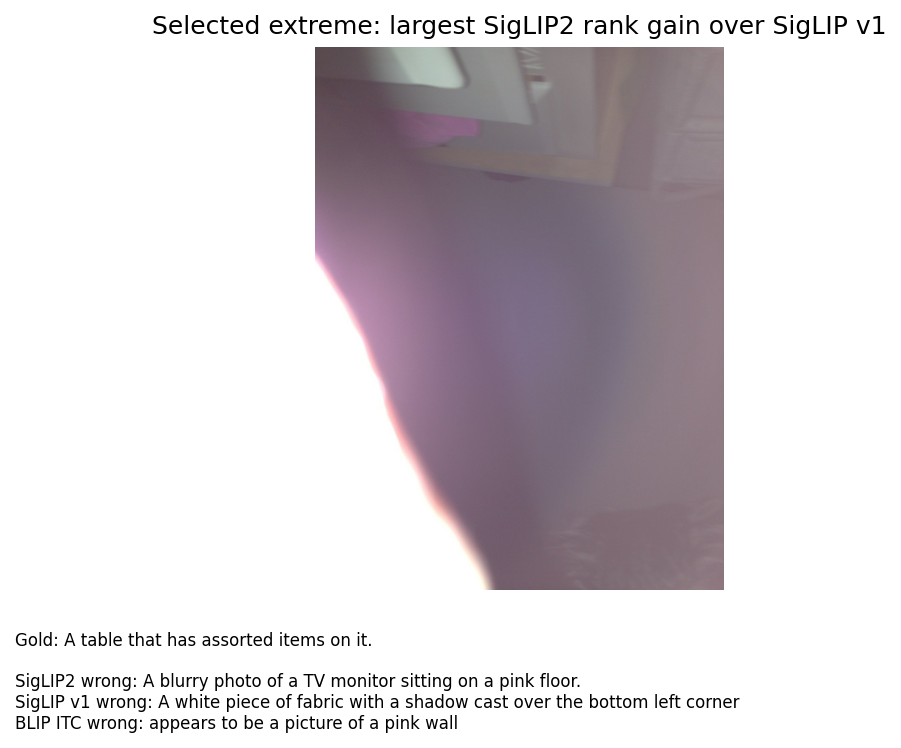

Selected extreme: largest SigLIP v1 rank gain over SigLIP2


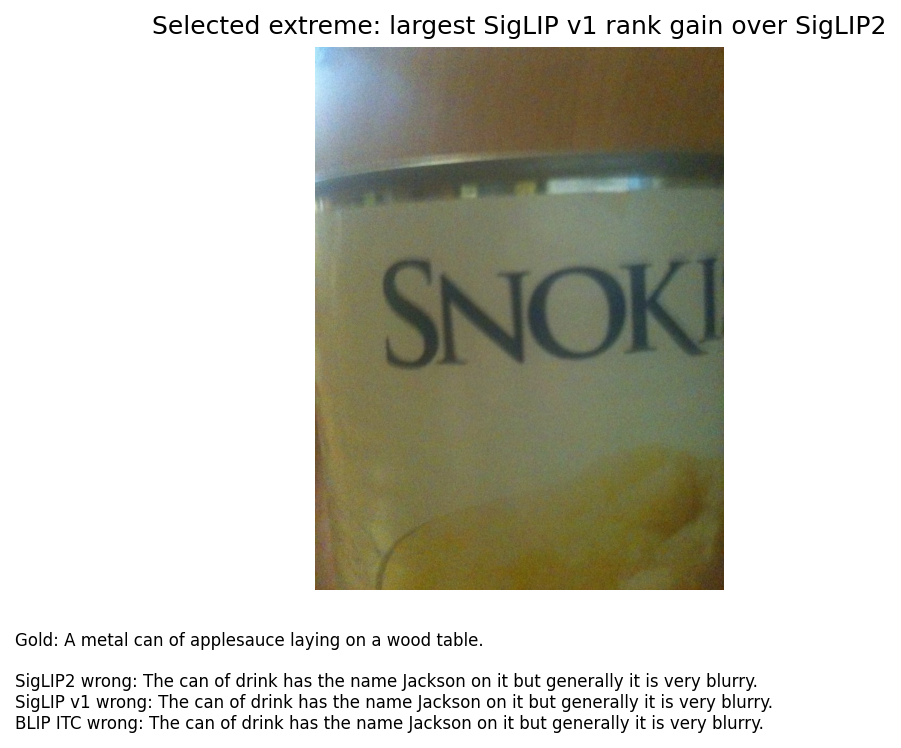

Selected extreme: largest SigLIP2 rank gain over BLIP ITC


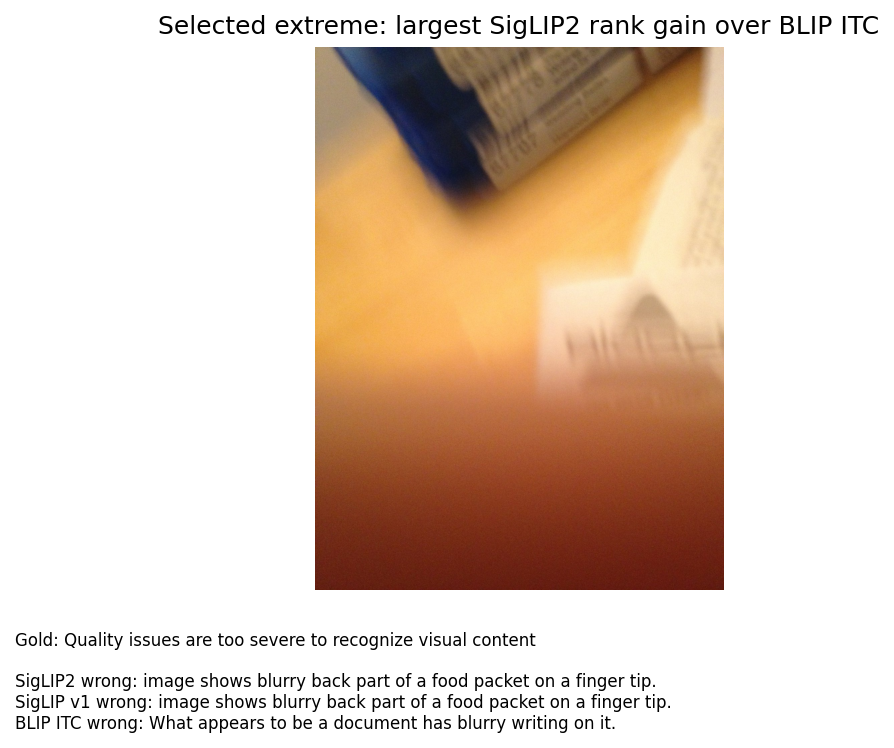

In [ ]:
# @title Show deterministic retrieval disagreement examples
run_stage("disagreement-figures")
for figure in state("disagreement_figures.json"):
    print(figure["title"])
    display(ShowImage(filename=figure["path"]))

# 23. Index storage and computation

Raw float32 vector storage:

- SigLIP: `768 × 4 = 3,072 bytes/item`
- BLIP ITC: `256 × 4 = 1,024 bytes/item`

Illustrative one-million-image raw-vector footprint:

- SigLIP ≈ **3.07 GB**
- BLIP ITC ≈ **1.02 GB**

These exclude ANN/vector-database index overhead.

In [ ]:
# @title Runtime and storage table
# Embedding times are the stage's own model passes on this runtime; matrix search is one query x 389 vectors.
run_stage("runtime-storage")
display(pd.read_csv(OUTPUT_ROOT / "test" / "runtime_storage.csv"))

table: 3 rows x 6 columns


siglip_v1 median matrix-search ms/query 0.033823499961727066


siglip2 median matrix-search ms/query 0.04954200016982213


blip_itc median matrix-search ms/query 0.013630000012199162


,model,dim,bytes_per_float32_vector,one_million_vectors_GB,image_embedding_seconds,text_embedding_seconds
0,siglip_v1,768,3072,3.072,16.142371,5.242390
1,siglip2,768,3072,3.072,12.640205,5.027818
2,blip_itc,256,1024,1.024,15.284882,3.076060


# 24. Export and verify embedding indexes

In [ ]:
# @title Index manifest and reload ranking parity
show_source("verify_index_pair")
run_stage("index-manifest")

```python
def verify_index_pair(root,image_entry,text_entry,reference):
    for entry in (image_entry,text_entry):
        path=Path(root)/entry["path"]
        if path.stat().st_size!=entry["bytes"] or sha256_file(path)!=entry["sha256"]:
            raise ValueError("Index digest/size mismatch")
    img=np.load(Path(root)/image_entry["path"],allow_pickle=False)
    txt=np.load(Path(root)/text_entry["path"],allow_pickle=False)
    if img.ndim!=2 or txt.ndim!=2 or img.shape[1]!=txt.shape[1] or not np.isfinite(img).all() or not np.isfinite(txt).all():
        raise ValueError("Index shape or finite-value mismatch")
    replay=img@txt.T
    if replay.shape!=reference.shape or not np.allclose(replay,reference,atol=1e-6,rtol=1e-6):
        raise RuntimeError("Index reload score parity failed")
    for axis in (0,1):
        if not np.array_equal(np.argsort(-replay,axis=axis,kind="stable"),np.argsort(-reference,axis=axis,kind="stable")):
            raise RuntimeError("Index reload ranking parity failed")
    return img,txt
```

Full index digest/shape/reload ranking parity: PASS


True

# 25. Caption perturbation and no-match behavior

These are **validation/interpretation experiments**, not test tuning.

### Caption perturbation (validation gallery only)

The 179 validation captions are scored by SigLIP 2 in three forms:

- `original` — the human caption;
- `lowercase` — the same caption in lowercase;
- `first_five_words` — only its first five words.

> **Before you run it:** predict which change matters. Note that the SigLIP wrapper in section 8 already lowercases every caption, so `lowercase` should produce exactly the same scores as `original`; any change there would indicate a bug. `changed_captions` counts how many captions each variant actually altered.

Only the validation gallery is used, and nothing here changes the frozen test protocol. The result shows that retrieval depends on how the query is phrased.

### No-match behavior

Retrievers always produce a nearest candidate—even for a query that has no correct photograph in the gallery.

That behavior must not be confused with abstention.

In [ ]:
# @title Caption perturbation (validation) and no-match nearest neighbours
run_stage("perturbation")
display(pd.read_csv(OUTPUT_ROOT / "validation" / "caption_perturbation.csv").round(4))

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Query: a satellite orbiting mars


Evaluation status: no ground-truth match — nearest-neighbor behavior only


0.07880676537752151 Black image with a brown object in the lower right hand corner.


0.07569533586502075 Some sort of fossilized item that is framed.


...

0.052676714956760406 A road with brown rocks on it has some white snow on it.


0.04978126287460327 Black image with a brown object in the lower right hand corner.


0.04779845476150513 I see the color olive green with yellow shadings blurring into olive on the right side.


table: 3 rows x 8 columns


,split,model,variant,changed_captions,t2i_recall_at_1,t2i_recall_at_5,i2t_recall_at_1,rsum
0,validation,siglip2,original,0,0.9609,1.0000,1.0,5.9609
1,validation,siglip2,lowercase,149,0.9609,1.0000,1.0,5.9609
2,validation,siglip2,first_five_words,179,0.6648,0.8827,0.9,5.3916


# 26. BYOD contract

Preferred archive:

```text
dataset.zip
├── records.jsonl
└── images/
```

Each JSONL row:

```json
{
  "id": "img001",
  "file": "images/img001.jpg",
  "captions": [
    "a red cup on a table",
    "a cup beside a plate"
  ],
  "split": "test",
  "category": "optional"
}
```

`STANDARD` can run with only an evaluation/test gallery.

`FULL` requires explicit:

- train
- validation
- test

roles if BLIP adaptation is requested.

### How to supply your archive

1. Build `dataset.zip` with the layout above (every image listed once in `records.jsonl`).
2. In Colab, open the **Files** pane (folder icon on the left) and upload `dataset.zip`, or mount Google Drive and copy the file there.
3. Right-click the file, choose **Copy path**, and paste it into `BYOD_ZIP_PATH` in the controls cell (section 1). Tick `USE_BYOD`.
4. Re-run the controls cell, then the BYOD cell below. You do not need to repeat the canonical run.

The cell checks every row before any model loads. A rejected archive stops the cell; the stage log printed above the error names the `records.jsonl` line, the id and the field to fix. On success it shows the retrieval and reranking tables for **your** gallery and the directory holding its CSV/JSON, index and (in `FULL`) adapter files.

This notebook is an **in-memory retrieval reference**, not a production vector database.
The complete optional branch now executes all three frozen retrieval indexes and BLIP reranking, verifies index digests and full ranking parity, and writes separate JSON/CSV evidence. FULL additionally adapts on train, selects only on validation, freezes before test, and verifies the live adapted validation embeddings against a fresh adapter reload. Supply 2–128 images total, 1–5 distinct string captions/image (at most 256 characters), 16–4096px sides and at most 100 million decoded pixels. FULL needs at least 2 images per role. All archive images must be declared; duplicate decoded pixels are rejected even within a role. Each run has a unique output directory.

In [ ]:
# Optional BYOD: same retrieval, reranking, index and FULL adaptation contracts, in the isolated environment.
byod_run_dir = None
if USE_BYOD:
    if not BYOD_ZIP_PATH:
        print('BYOD archive refused: USE_BYOD is True but BYOD_ZIP_PATH is empty. Upload dataset.zip (Files pane '
              'or Drive), paste its path into BYOD_ZIP_PATH in the controls cell, re-run that cell, then this one.')
    elif not Path(BYOD_ZIP_PATH).is_file():
        print(f'BYOD archive refused: BYOD_ZIP_PATH {BYOD_ZIP_PATH!r} is not a file in this runtime. Check the path '
              'with the Files pane, re-run the controls cell, then this one.')
    # The archive is validated (load_byod) before any model loads. A refusal names the line, id and field,
    # is printed once by the stage, and leaves no BYOD result in this run.
    elif run_stage("byod", allow_refusal=True):
        byod_run_dir = Path(state("byod_run.json")["run_dir"])
        byod_results = read_json(byod_run_dir / "results.json")
        print('Retrieval on your test gallery (same metrics as section 17):')
        display(pd.DataFrame(byod_results['retrieval']).round(4))
        print('BLIP ITM reranking (coarse and reranked R@1 on the same queries, as in section 18):')
        display(pd.DataFrame(byod_results['reranking']).round(4))
        if byod_results['adapter_parity']:
            print('Adapter fresh-reload parity:', byod_results['adapter_parity'])
        print('BYOD files (CSV/JSON, index, adapter):', byod_run_dir)
else:
    print('BYOD disabled; canonical VizWiz workflow completed.')

BYOD disabled; canonical VizWiz workflow completed.


## BYOD privacy

User-supplied photographs and captions are processed inside the selected notebook runtime and are not submitted to DIMER workers or APIs.

A hosted notebook remains an external compute environment. Do not upload confidential, personal, restricted, security-sensitive, or proprietary image/text data unless authorized.

VizWiz itself contains photographs of everyday surroundings taken by blind users and can include personal spaces, belongings, labels, documents, and people. The sample corpus should therefore be treated as real-world user-generated imagery, not anonymous synthetic data.

# 27. Interpretation boundaries

### Retrieval is gallery-relative

The same model can score much higher over 70 candidates than over 389.

A Recall@1 number without gallery size is incomplete.

### Nearest neighbor is not truth

A dual encoder always has a nearest vector.

A reranker also assigns every examined pair a score.

Neither provides an inherent “none of these” decision.

### Scores are not interchangeable

- SigLIP retrieval: cosine similarity in its 768-d space.
- BLIP ITC: cosine similarity in its 256-d space.
- BLIP ITM: uncalibrated pairwise classifier output.

`0.7` in one is not probabilistically equivalent to `0.7` in another.

### Rerankers cannot recover omitted candidates

If the correct item is absent from the top-K shortlist, BLIP ITM cannot make it rank first.

Always read candidate oracle@K beside reranked R@1.

### The model comparison is whole-checkpoint

SigLIP 2 (224×224 px) and SigLIP v1 (256×256 px) are web-pretrained checkpoints used zero-shot; BLIP ITC is fine-tuned for image–text retrieval on COCO at 384×384 px. Their text towers and sizes differ too. A gap between them cannot be attributed to any single factor, and the Flickr30k sensitivity row shows how far a different retrieval fine-tune of the same BLIP architecture moves its numbers.

### Embedding size is an engineering dimension

A larger representation can improve retrieval but increases:

- storage;
- memory bandwidth;
- ANN index footprint.

In this notebook the 768-d and 256-d retrievers also differ in training, resolution and text tower, so their accuracy gap is not evidence about embedding size.

### VizWiz is one distribution

Results reflect one pinned sample of photographs and crowd-written captions, not all image search tasks.

### Pretraining overlap cannot be ruled out

VizWiz-Captions is public. Some photographs or captions may have been seen during SigLIP, SigLIP 2 or BLIP pretraining, which would inflate frozen scores. Treat the numbers as tutorial evidence on this sample, not as a measure of generalisation to unseen data.

### Search bias

Vision-language embeddings inherit semantic associations from large web corpora. Search involving people, occupations, demographic attributes, cultures, or sensitive concepts needs separate fairness and application-specific review.

# 28. Try it yourself

Answer each question from your own run first, then open the sample answer.

### Exercise A — gallery size

In the fixed-query table of section 20, why can a frozen model's R@1 not rise as the gallery grows, and why is that not guaranteed in the nested table?

<details>
<summary><b>Sample answer</b></summary>

With the queries held fixed, every added photograph or caption is another candidate that can outrank the annotated one, and none can help, so R@1 stays the same or falls. Chance R@1 is `1/gallery_images`, so it falls too (`chance_t2i_r1`). The embeddings did not change; only the competition did. In the nested table each prefix also adds new queries, which may be easier or harder than the first 70, so its R@1 can move either way. Either way, an R@1 value is incomplete without its gallery size.

</details>

### Exercise B — first-stage oracle

If SigLIP 2 candidate oracle@5 is 0.94, what is the highest possible reranked R@1 at K=5?

<details>
<summary><b>Sample answer</b></summary>

0.94, in the same direction as the oracle. The reranker only reorders the five candidates it receives; for the 6 % of queries whose correct item is not among them, nothing it does can produce a correct top-1. Compare your run's `itm_*_recall_at_1` with `*_candidate_oracle` in section 18.

</details>

### Exercise C — cross encoder

Why not run BLIP ITM against every image-caption pair in a million-image corpus?

<details>
<summary><b>Sample answer</b></summary>

ITM needs one fused forward pass per (image, caption) pair, so one query would cost a million passes. A dual encoder embeds the corpus once; each query is then one text encoding plus a matrix product (section 23 times it in milliseconds). Reranking only the top-K keeps the fused cost at K passes per query (`pair_evaluations` in section 18).

</details>

### Exercise D — dimensions

Would you always choose a 768-dimensional index over a 256-dimensional one if R@1 is slightly higher?

<details>
<summary><b>Sample answer</b></summary>

No. Separate the two things the question mixes. **Cost** belongs to the dimension: a 768-d float32 index needs three times the storage and memory bandwidth of a 256-d one (section 23). **Accuracy** here does not: the 768-d SigLIP models are zero-shot web-pretrained checkpoints at 224/256 px, while the 256-d BLIP ITC is fine-tuned for retrieval on COCO at 384 px, with a different text tower, so their R@1 gap is a whole-checkpoint difference, not an effect of embedding size (the Flickr30k row shows how far a different retrieval fine-tune of the same BLIP architecture moves it). Before acting on a gap, read its size in percentage points, its photograph-bootstrap interval and its fixed/broken counts (after section 18) as exploratory evidence about this gallery, not as a selection rule; check whether it survives other gallery sizes (section 20) and whether reranking narrows it. To learn what dimension alone buys, compare one model at several embedding sizes.

</details>

### Exercise E — no match

What should an application do with a nearest neighbor returned for `a satellite orbiting mars` when no such image exists?

<details>
<summary><b>Sample answer</b></summary>

Not present it as an answer. A retriever always returns a nearest item, and these similarity scores are uncalibrated. An application needs an explicit "no confident match" policy, for example a threshold chosen on labelled no-match and match queries from its own domain, or a calibrated verifier, before it can abstain.

</details>

### Exercise F — adaptation

If adapted BLIP improves VizWiz rsum but makes another image population worse, did the adaptation succeed?

That is a deployment-domain and regression-policy question, not a single-metric question.

<details>
<summary><b>Sample answer</b></summary>

Only for the population it will serve, and only if a non-regression rule agreed in advance is met. The VizWiz gain is evidence on one sample; a release decision also needs results on the other populations the system must handle and a stated tolerance for regressions there.

</details>

# 29. Export provenance and report bundle

> **Infrastructure.** This section supports reproducibility and execution. Run the associated setup code as written; understanding its implementation is not a learning objective for this notebook.

In [ ]:
# @title Final provenance export
run_stage("report")

{'bundle': '/content/outputs_DIMER_Vision_Language_Retrieval_Report.zip', 'files': 31, 'sha256': '73dc30c42ab31a5c8e59bd6e1f85fa0b3f24af1a991fe1c32db47c88a910b2d7'}


True

# 30. Troubleshooting

| Symptom | Likely cause | Corrective action |
|---|---|---|
| `This notebook builds a Linux x86_64 environment` | Windows/macOS or ARM kernel | use Google Colab, Kaggle or a Linux x86_64 Jupyter server |
| uv wheel, carried file or lock hash mismatch | corrupted download or edited carrier | re-run the runtime cells; never bypass hash checking |
| `<stage> failed with exit N` | the stage's own error, printed above (log in `work/logs/`) | fix the named cause and re-run that cell; earlier stages need not be repeated |
| model digest mismatch | incomplete/drifted Hub file | delete cache and retry; never bypass verification |
| VizWiz shard digest mismatch | incomplete/drifted dataset file | remove cached shard and retry |
| test gallery count not 389 / captions not 1,729 | schema/sample drift | refuse; do not silently change gallery |
| SigLIP OOM | image/text batch too large for runtime | use canonical T4 and reduce only embedding batch size, not gallery |
| BLIP reranking slow | pairwise fused passes | lower K only through a new validation/freeze experiment |
| strong metrics on 70 but weaker on 389 | expected gallery-size effect | report both; do not compare unlike galleries |
| ITM worsens a correct coarse top-1 | reranker error | preserve the observed regression; do not tune on test |
| correct item outside top-K | candidate-generator miss | reranker cannot recover it; read oracle@K |
| adapter digest mismatch | corrupt/foreign adapter | refuse to load |
| BYOD image appears in two roles | leakage | fix split ownership before running |

Explicit failure is preferable to changing gallery membership or metric definitions after seeing results.

## Try it yourself — one controlled change

Predict whether expanding the candidate pool from 5 to 10 can reduce candidate-oracle recall. In a scratch cell run `run_stage("candidate-oracle", "--k", "10")`: it prints `candidate_oracle` on the saved SigLIP 2 validation scores at K=5 and K=10. Observe the two recall values and explain why a larger candidate set can improve the reranker ceiling but does not prove the ITM reranker will choose the right item. Only candidate-pool size changes; the saved validation scores, images and captions remain fixed. This loads no models and writes no exports. Keep `RERANK_TOP_K`, frozen settings and test results unchanged.

## Self-paced checkpoint

Before opening the sample interpretation, answer:

1. What did the model/system receive as input, and what did it produce?
2. Which baseline/reference tells you whether the learned model added value?
3. What failure mode or tradeoff matters most here?
4. What additional evidence would you want before transferring the result to a new domain?

<details>
<summary><b>Show a sample interpretation</b></summary>

Retrieval is gallery-relative: the system chooses among available candidates rather than deciding an image is universally correct. A reranker can reorder candidates but cannot recover an image omitted by the first-stage retriever. Similarity and ITM scores should not be read as interchangeable calibrated probabilities.

Use the outputs from **your run** when writing your final answer; small numeric differences across supported runtimes are possible.

</details>


## Write an evidence-based conclusion

1. **State the question** tested by this notebook.
2. **Report the primary result** against the relevant baseline/reference.
3. **Add supporting evidence** from a secondary metric, error pattern, disagreement, or qualitative diagnostic.
4. **Account for cost/complexity** when it materially affects the comparison.
5. **State the limits** of the data, split, model revision, and configuration.

Compare the principal held-out retrieval result with the analytical/non-neural references, report at least one Recall@K or rank-based measure, describe what reranking changed, and note the gallery-size, category, or hard-negative behavior that most affects interpretation. When you compare two models, report the difference in percentage points, its photograph-bootstrap interval and the discordant counts, call the comparison exploratory, and say that it is between whole checkpoints on this gallery (for example: "checkpoint A achieved higher annotated-owner R@1 than checkpoint B on this pinned VizWiz gallery"). An interval that includes 0 is not evidence that the two perform alike.


# Glossary

| Term | Meaning |
|---|---|
| **Dual encoder** | Independently encodes image and text into a shared vector space |
| **Cross encoder / fused matcher** | Scores an image-text pair jointly with cross-modal interaction |
| **ITC** | Image-text contrastive representation/objective |
| **ITM** | Image-text matching pairwise classifier |
| **I2T** | Image-to-text retrieval |
| **T2I** | Text-to-image retrieval |
| **Recall@K** | Fraction of queries with at least one annotated positive in the first K results |
| **Median rank** | Median position of the first correct result |
| **rsum** | Sum of I2T/T2I R@1, R@5 and R@10 as fractions (0–6 here; 0–600 when written in percent) |
| **Candidate oracle@K** | Fraction of queries whose correct item exists somewhere in the top-K shortlist |
| **ITM pair accuracy** | Fraction of photographs for which BLIP ITM scores the first caption above the coarse retriever's highest-scoring wrong caption; chance is 0.5 |
| **Pair evaluations** | Number of fused BLIP ITM forward passes a reranking step needed; the cost that grows with K |
| **Same-query delta** | Reranked R@1 minus coarse R@1 measured on the same queries; isolates the reranker's effect |
| **Hard negative** | High-scoring incorrect candidate |
| **Embedding index** | Stored vectors and their item-order/provenance mapping |
| **Reranker** | More expensive model that reorders a small candidate shortlist |
| **Sample-sanity evidence** | Bounded notebook evidence, not a benchmark/deployment guarantee |

In [ ]:
# @title Run-all completion summary
summary = state("completion_summary.json")
display(pd.Series(summary, name="value").to_frame())
print(
    "Vision-language retrieval workshop complete. "
    "Interpret results as one-gallery sample-sanity evidence, not a universal model ranking."
)

,value
notebook_spec,2.5
profile,MULTI-CAPABILITY
mode,WORKSHOP
tier,STANDARD
models,"[SigLIP v1, SigLIP 2, BLIP ITC/ITM]"
comparison_scope,"whole checkpoints (training regime, input reso..."
test_gallery_images,389
test_gallery_captions,1729
rerank_top_k,5
test_r1_i2t / t2i (all captions),"{'chance': '0.003 / 0.003', 'colour_keyword': ..."


Vision-language retrieval workshop complete. Interpret results as one-gallery sample-sanity evidence, not a universal model ranking.


# Troubleshooting

| What you see | Likely cause | What to do |
|---|---|---|
| Accelerator unavailable or execution is unexpectedly slow | The runtime does not match the documented resource envelope | Select the documented accelerator/runtime, start a fresh session, and run top-to-bottom. |
| Package/version error from the `environment` stage | The isolated environment differs from the hash lock | Delete `work/env` and re-run the runtime cell. The notebook kernel's own packages are never changed, so no restart is needed. Do not bypass version or hash checks. |
| Model/sample digest or byte-size check fails | Download is incomplete or upstream bytes differ from the pinned artifact | Remove the affected runtime cache/download and rerun. Do not disable the integrity check. |
| Out-of-memory or runtime restart | Too many large models/intermediates are resident | Use the default tier, follow explicit unload/release steps, and avoid combining optional heavy branches. |
| BYOD validation fails | Input does not satisfy the documented schema, shape, labels, or limits | Follow the validation message, correct the indicated field/format, then rerun the BYOD branch. |
| Your numbers differ slightly | Supported hardware/library execution can introduce small numerical variation | Verify the split, model revision, metric definition, and qualitative pattern before treating the difference as substantive. |